# Saúde Mental Relacionada ao Trabalho — SINAN / NR-1

## Análise epidemiológica e modelagem preditiva de desfechos ocupacionais

**Autora:** Kymie Saito  
**Base de dados:** Sistema de Informação de Agravos de Notificação (SINAN)  
**Período de análise:** 2014–2026  
**Domínio:** Saúde do Trabalhador | Ciência de Dados | Machine Learning

---

### Objetivo

Este notebook implementa uma abordagem reprodutível para preparação, exploração e modelagem dos dados de **Transtornos Mentais Relacionados ao Trabalho** registrados no SINAN.

O fluxo analítico contempla:

1. configuração e validação do ambiente computacional;
2. carregamento e auditoria da base de dados;
3. avaliação da qualidade e completude das variáveis;
4. tratamento e padronização dos dados;
5. caracterização epidemiológica dos registros;
6. construção e validação do desfecho de interesse;
7. seleção de variáveis preditoras;
8. preparação da matriz analítica;
9. treinamento de modelos de Machine Learning;
10. avaliação comparativa de desempenho e interpretação dos resultados.

### Princípios analíticos

A construção da base de modelagem será realizada de forma separada da base epidemiológica, com atenção especial à **temporalidade das variáveis**, **dados ausentes**, **desbalanceamento de classes**, **vazamento de informação (data leakage)** e **reprodutibilidade**.

As transformações realizadas ao longo do notebook serão documentadas explicitamente, preservando a rastreabilidade entre os dados originais e a base analítica final.

In [59]:
# ============================================================
# INSTALAÇÃO DO PLOTLY
# ============================================================

%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [60]:
import plotly.express as px
import plotly.graph_objects as go

print("Plotly instalado com sucesso!")

Plotly instalado com sucesso!


In [61]:
# ============================================================
# BLOCO 1 — BIBLIOTECAS E CONFIGURAÇÃO DO AMBIENTE
# Projeto: SINAN / NR-1 — 2014–2026
# ============================================================

import sys
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from scipy.stats import chi2_contingency

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

print("=" * 70)
print("AMBIENTE DE EXECUÇÃO")
print("=" * 70)

print("Python      :", sys.version.split()[0])
print("Executável  :", sys.executable)
print("Pandas      :", pd.__version__)
print("NumPy       :", np.__version__)
print("PyArrow     :", pa.__version__)
print("Pasta atual :", Path.cwd())

print("\n✅ Bibliotecas importadas com sucesso.")

AMBIENTE DE EXECUÇÃO
Python      : 3.13.15
Executável  : c:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito\.venv\Scripts\python.exe
Pandas      : 3.0.5
NumPy       : 2.5.2
PyArrow     : 25.0.1
Pasta atual : c:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito

✅ Bibliotecas importadas com sucesso.


# 2. Carregamento da base de dados

Nesta etapa é realizada a leitura da base de **Transtornos Mentais Relacionados ao Trabalho (SINAN)** armazenada em formato Parquet.

Inicialmente, será preservada a estrutura original da base, sem aplicação de filtros ou transformações. Essa estratégia permite manter uma referência dos dados de entrada e garante maior rastreabilidade durante as etapas posteriores de tratamento e construção da base analítica.

In [62]:
# ============================================================
# BLOCO 2 — CARREGAMENTO DA BASE SINAN
# ============================================================

ARQUIVO_DADOS = Path("sinan_transtornos_mentais_2017_2026.parquet")

# Verifica se o arquivo existe
if not ARQUIVO_DADOS.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_DADOS.resolve()}"
    )

# Carregamento da base
df = pd.read_parquet(ARQUIVO_DADOS)

print("=" * 70)
print("BASE SINAN CARREGADA COM SUCESSO")
print("=" * 70)

print(f"\nArquivo : {ARQUIVO_DADOS.name}")
print(f"Caminho : {ARQUIVO_DADOS.resolve()}")
print(f"Linhas  : {df.shape[0]:,}")
print(f"Colunas : {df.shape[1]:,}")

print("\nPrimeiros registros:")
display(df.head())

BASE SINAN CARREGADA COM SUCESSO

Arquivo : sinan_transtornos_mentais_2017_2026.parquet
Caminho : C:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito\sinan_transtornos_mentais_2017_2026.parquet
Linhas  : 24,356
Colunas : 65

Primeiros registros:


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,SEM_DIAG,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,ID_OCUPA_N,SIT_TRAB,NUTEMPO,TPTEMPO,CNAE,UF_EMP,MUN_EMP,TERCEIRIZA,NUTEMPORIS,TPTEMPORIS,REGIME,DIAG_ESP,ALCOOL,PSICO_FARM,DROGAS,FUMA,TEMPO_FUMA,TP_TEMP_FU,AFAST_DESG,INDIVIDUAL,MUDA_TRAB,NENHUM,COLETIVA,AFAST_TRAB,CONDUTA,TRAB_DOE,CAPES,DT_OBITO,CAT,EVOLUCAO,CONDUT_DES,DT_DIGITA,agravo_codigo,agravo_nome,ano_base,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,,4046,F,5,1,08,25,2507507,1377,1,211215,01,6,4,,25,2503209,2,6,4,,F430,2,2,2,2,0,,1,2,2,,2,1,,1,2,,1,3,,20140107,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,,4070,F,5,4,00,17,1705557,,1,999993,06,0,,,,,,0,,,,2,1,2,2,0,,1,2,2,2,2,2,2,2,2,,3,4,,20140106,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,,4046,F,5,9,09,41,4113700,1371,1,261140,01,21,4,,41,4113700,2,21,4,2,F320,9,9,9,9,0,,2,2,2,2,2,2,1,9,1,,2,3,ENC CAPS E RELAT INSS,20140103,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,,4033,M,6,9,09,29,2910800,1381,1,253215,01,0,,,29,2910800,9,0,,2,F321,9,9,9,9,0,,1,1,2,2,2,1,2,9,1,,1,3,,20140411,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,,4031,M,6,1,05,35,3550308,1331,1,766220,01,0,,,35,3550308,2,0,,2,F431,,,,,0,,,,,,,1,,9,9,,1,3,,20141014,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 3. Auditoria inicial da base

Antes das etapas de limpeza, transformação e modelagem, realiza-se uma inspeção estrutural da base original.

Esta etapa tem como objetivo verificar as dimensões do conjunto de dados, identificar as variáveis disponíveis, examinar seus tipos e observar uma amostra dos registros. A auditoria inicial permite documentar o estado dos dados antes de qualquer transformação.

In [63]:
# ============================================================
# BLOCO 3 — AUDITORIA INICIAL DA BASE
# ============================================================

print("=" * 70)
print("AUDITORIA INICIAL DA BASE SINAN")
print("=" * 70)

# Dimensões
print(f"\nNúmero de registros : {df.shape[0]:,}")
print(f"Número de variáveis : {df.shape[1]:,}")

# Tipos das variáveis
print("\n" + "=" * 70)
print("TIPOS DAS VARIÁVEIS")
print("=" * 70)

display(
    pd.DataFrame({
        "variavel": df.columns,
        "tipo": df.dtypes.astype(str).values
    })
)

# Amostra da base
print("\n" + "=" * 70)
print("PRIMEIROS REGISTROS")
print("=" * 70)

display(df.head())

AUDITORIA INICIAL DA BASE SINAN

Número de registros : 24,356
Número de variáveis : 65

TIPOS DAS VARIÁVEIS


,variavel,tipo
0,TP_NOT,str
1,ID_AGRAVO,str
2,DT_NOTIFIC,str
3,SEM_NOT,str
4,NU_ANO,str
5,SG_UF_NOT,str
6,ID_MUNICIP,str
7,ID_REGIONA,str
8,ID_UNIDADE,str
9,DT_DIAG,str



PRIMEIROS REGISTROS


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,SEM_DIAG,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,ID_OCUPA_N,SIT_TRAB,NUTEMPO,TPTEMPO,CNAE,UF_EMP,MUN_EMP,TERCEIRIZA,NUTEMPORIS,TPTEMPORIS,REGIME,DIAG_ESP,ALCOOL,PSICO_FARM,DROGAS,FUMA,TEMPO_FUMA,TP_TEMP_FU,AFAST_DESG,INDIVIDUAL,MUDA_TRAB,NENHUM,COLETIVA,AFAST_TRAB,CONDUTA,TRAB_DOE,CAPES,DT_OBITO,CAT,EVOLUCAO,CONDUT_DES,DT_DIGITA,agravo_codigo,agravo_nome,ano_base,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,,4046,F,5,1,08,25,2507507,1377,1,211215,01,6,4,,25,2503209,2,6,4,,F430,2,2,2,2,0,,1,2,2,,2,1,,1,2,,1,3,,20140107,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,,4070,F,5,4,00,17,1705557,,1,999993,06,0,,,,,,0,,,,2,1,2,2,0,,1,2,2,2,2,2,2,2,2,,3,4,,20140106,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,,4046,F,5,9,09,41,4113700,1371,1,261140,01,21,4,,41,4113700,2,21,4,2,F320,9,9,9,9,0,,2,2,2,2,2,2,1,9,1,,2,3,ENC CAPS E RELAT INSS,20140103,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,,4033,M,6,9,09,29,2910800,1381,1,253215,01,0,,,29,2910800,9,0,,2,F321,9,9,9,9,0,,1,1,2,2,2,1,2,9,1,,1,3,,20140411,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,,4031,M,6,1,05,35,3550308,1331,1,766220,01,0,,,35,3550308,2,0,,2,F431,,,,,0,,,,,,,1,,9,9,,1,3,,20141014,MENT,Transtorno Mental Relacionado ao Trabalho,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3.1 Inventário e completude das variáveis

Após a inspeção estrutural, avalia-se individualmente cada variável quanto ao tipo de dado, número de observações preenchidas, valores ausentes e cardinalidade.

Essa etapa permite identificar problemas de completude, variáveis com baixa informação disponível e características que exigirão tratamento específico antes das análises epidemiológicas e da modelagem.

In [64]:
# ============================================================
# BLOCO 3.1 — INVENTÁRIO DAS VARIÁVEIS
# ============================================================

inventario = pd.DataFrame({
    "VARIAVEL": df.columns,
    "TIPO": df.dtypes.astype(str).values,
    "PREENCHIDOS": df.notna().sum().values,
    "AUSENTES": df.isna().sum().values,
    "PERC_AUSENTES": (df.isna().mean().values * 100),
    "VALORES_UNICOS": df.nunique(dropna=True).values
})

inventario["PERC_AUSENTES"] = (
    inventario["PERC_AUSENTES"]
    .round(2)
)

print("=" * 70)
print("INVENTÁRIO DAS VARIÁVEIS")
print("=" * 70)

print(f"\nTotal de variáveis analisadas: {len(inventario)}")

display(inventario)

INVENTÁRIO DAS VARIÁVEIS

Total de variáveis analisadas: 65


,VARIAVEL,TIPO,PREENCHIDOS,AUSENTES,PERC_AUSENTES,VALORES_UNICOS
0,TP_NOT,str,24356,0,0.00,1
1,ID_AGRAVO,str,24356,0,0.00,1
2,DT_NOTIFIC,str,24356,0,0.00,2673
3,SEM_NOT,str,24356,0,0.00,531
4,NU_ANO,str,24356,0,0.00,10
5,SG_UF_NOT,str,24356,0,0.00,27
6,ID_MUNICIP,str,24356,0,0.00,1041
7,ID_REGIONA,str,24356,0,0.00,246
8,ID_UNIDADE,str,24356,0,0.00,2662
9,DT_DIAG,str,24356,0,0.00,3987


In [65]:
# ============================================================
# BLOCO 3.2 — INSPEÇÃO DOS CÓDIGOS DAS VARIÁVEIS
# ============================================================

variaveis_inspecao = [
    "CS_SEXO",
    "CS_GESTANT",
    "CS_RACA",
    "CS_ESCOL_N",
    "SIT_TRAB",
    "TERCEIRIZA",
    "REGIME",
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA",
    "AFAST_DESG",
    "INDIVIDUAL",
    "MUDA_TRAB",
    "NENHUM",
    "COLETIVA",
    "AFAST_TRAB",
    "CONDUTA",
    "TRAB_DOE",
    "CAPES",
    "CAT",
    "EVOLUCAO"
]

print("=" * 70)
print("INSPEÇÃO DOS CÓDIGOS DAS VARIÁVEIS CATEGÓRICAS")
print("=" * 70)

for coluna in variaveis_inspecao:

    if coluna not in df.columns:
        print(f"\n⚠️ {coluna}: não encontrada")
        continue

    print("\n" + "=" * 70)
    print(f"VARIÁVEL: {coluna}")
    print("=" * 70)

    contagem = (
        df[coluna]
        .value_counts(dropna=False)
        .rename_axis("VALOR")
        .reset_index(name="N")
    )

    contagem["PERCENTUAL"] = (
        contagem["N"] / len(df) * 100
    ).round(2)

    display(contagem)

INSPEÇÃO DOS CÓDIGOS DAS VARIÁVEIS CATEGÓRICAS

VARIÁVEL: CS_SEXO


,VALOR,N,PERCENTUAL
0,F,16518,67.82
1,M,7835,32.17
2,I,3,0.01



VARIÁVEL: CS_GESTANT


,VALOR,N,PERCENTUAL
0,5,11488,47.17
1,6,9599,39.41
2,9,2703,11.10
3,2,264,1.08
4,1,125,0.51
5,3,122,0.50
6,4,55,0.23



VARIÁVEL: CS_RACA


...

,VALOR,N,PERCENTUAL
0,1,12617,51.80
1,2,6355,26.09
2,9,2711,11.13
3,,2673,10.97



VARIÁVEL: CAT


,VALOR,N,PERCENTUAL
0,2,10257,42.11
1,1,7599,31.20
2,9,4142,17.01
3,3,1747,7.17
4,,611,2.51



VARIÁVEL: EVOLUCAO


,VALOR,N,PERCENTUAL
0,3,13698,56.24
1,9,2668,10.95
2,2,2595,10.65
3,8,2348,9.64
4,,1529,6.28
5,1,881,3.62
6,4,501,2.06
7,5,114,0.47
8,6,17,0.07
9,7,5,0.02


# 4. Padronização inicial dos dados

Antes da avaliação da qualidade dos dados, são padronizados os tipos das principais variáveis categóricas e numéricas.

Representações textuais de ausência são convertidas para valores nulos reconhecidos pelo `pandas`, permitindo que as etapas subsequentes de avaliação de completude reflitam adequadamente a qualidade da informação disponível.

As transformações realizadas nesta etapa são restritas à padronização estrutural, sem recodificação das categorias originais.

In [66]:
# ============================================================
# BLOCO 4 — PADRONIZAÇÃO MÍNIMA DOS TIPOS
# ============================================================

colunas_categoricas = [
    'SG_UF_NOT',
    'SG_UF',
    'UF_EMP',

    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'CS_GESTANT',

    'ID_OCUPA_N',
    'SIT_TRAB',
    'REGIME',
    'TERCEIRIZA',

    'TPTEMPO',
    'TPTEMPORIS',

    'ID_AGRAVO',
    'DIAG_ESP',

    'ALCOOL',
    'PSICO_FARM',
    'DROGAS',
    'FUMA',

    'TRAB_DOE',
    'AFAST_TRAB',
    'MUDA_TRAB',
    'CAT',

    'CAPES',
    'CONDUTA',

    'INDIVIDUAL',
    'COLETIVA',
    'NENHUM',

    'EVOLUCAO'
]

for col in colunas_categoricas:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype('string')
            .str.strip()
            .replace({
                'nan': pd.NA,
                'None': pd.NA,
                '': pd.NA
            })
        )

colunas_numericas = [
    'NU_ANO',
    'ano_base',
    'NU_IDADE_N',
    'NUTEMPO',
    'NUTEMPORIS',
    'TEMPO_FUMA'
]

for col in colunas_numericas:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors='coerce'
        )

print("=" * 70)
print("PADRONIZAÇÃO MÍNIMA DOS TIPOS")
print("=" * 70)

print("\n✅ Padronização concluída.")
print(f"Dimensão da base: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

PADRONIZAÇÃO MÍNIMA DOS TIPOS

✅ Padronização concluída.
Dimensão da base: 24,356 linhas × 65 colunas


# 5. Verificação de registros duplicados

Nesta etapa são investigados registros duplicados na base após a padronização estrutural inicial.

A identificação de duplicatas permite avaliar a existência de observações integralmente repetidas e evita a superestimação de frequências nas análises descritivas e nos modelos subsequentes. Nenhum registro é removido automaticamente sem inspeção prévia.

In [67]:
# ============================================================
# BLOCO 5 — VERIFICAÇÃO DE REGISTROS DUPLICADOS
# ============================================================

print("=" * 70)
print("VERIFICAÇÃO DE DUPLICATAS")
print("=" * 70)

duplicados = df.duplicated()

n_duplicados = duplicados.sum()
perc_duplicados = (n_duplicados / len(df)) * 100

print(f"\nTotal de registros      : {len(df):,}")
print(f"Registros duplicados    : {n_duplicados:,}")
print(f"Percentual de duplicados: {perc_duplicados:.2f}%")

if n_duplicados > 0:
    print("\nExemplos de registros duplicados:")
    display(df.loc[duplicados].head(10))
else:
    print("\n✅ Não foram encontrados registros integralmente duplicados.")

VERIFICAÇÃO DE DUPLICATAS

Total de registros      : 24,356
Registros duplicados    : 5
Percentual de duplicados: 0.02%

Exemplos de registros duplicados:


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,SEM_DIAG,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,ID_OCUPA_N,SIT_TRAB,NUTEMPO,TPTEMPO,CNAE,UF_EMP,MUN_EMP,TERCEIRIZA,NUTEMPORIS,TPTEMPORIS,REGIME,DIAG_ESP,ALCOOL,PSICO_FARM,DROGAS,FUMA,TEMPO_FUMA,TP_TEMP_FU,AFAST_DESG,INDIVIDUAL,MUDA_TRAB,NENHUM,COLETIVA,AFAST_TRAB,CONDUTA,TRAB_DOE,CAPES,DT_OBITO,CAT,EVOLUCAO,CONDUT_DES,DT_DIGITA,agravo_codigo,agravo_nome,ano_base,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
2992,2,F99,20160811,201632,2016,24,2408102,1416,3617327,20160302,,4033,F,5,4,06,24,2412005,1416,1,421125,01,3,4,,24,2408102,2,3,4,2,F438,2,1,1,2,0,,2,2,2,<NA>,2,1,<NA>,1,1,,2,3,,20160811,MENT,Transtorno Mental Relacionado ao Trabalho,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16826,2,F99,20240304,202410,2024,35,3534104,1344,3057747,20240304,,4025,F,5,1,08,35,3534104,1344,1,239410,01,1,4,,35,3529005,2,6,3,2,<NA>,<NA>,<NA>,<NA>,<NA>,0,,,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,,2,<NA>,,20240305,MENT,Transtorno Mental Relacionado ao Trabalho,2024,1998,,,,,,,,,
21776,2,F99,20250303,202510,2025,43,4304606,1592,3508528,20230725,,4031,F,5,1,09,43,4304606,1592,1,515210,01,2,4,,43,4304606,2,2,4,2,F41,2,2,2,2,0,,1,1,<NA>,<NA>,<NA>,<NA>,<NA>,1,1,,2,2,,20250311,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1991,,,,,,,,,
21828,2,F99,20250307,202510,2025,43,4314407,1593,2254131,20200519,,4040,F,5,1,06,43,4314407,1593,1,515105,05,13,4,87301,43,4314407,2,13,4,2,F41,2,2,2,2,0,,2,1,2,2,2,2,2,2,1,,2,1,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1979,,,,,,,,,
23320,2,F99,20250606,202523,2025,35,3550308,1331,2086794,20250529,,4052,F,9,1,08,35,3550308,1331,1,223565,01,12,4,86305,35,3550308,2,12,4,2,Z730,2,1,2,2,0,,2,2,2,1,2,2,2,2,1,,1,8,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1973,,,,,,,,,


## 5.1 Avaliação dos registros duplicados

Foram identificados 5 registros integralmente duplicados, correspondentes a aproximadamente 0,02% da base.

Antes de qualquer exclusão, os registros são examinados em conjunto com suas respectivas ocorrências originais. Essa verificação permite documentar a duplicidade e evita a remoção automática de observações sem avaliação prévia.

In [68]:
# ============================================================
# BLOCO 5.1 — INSPEÇÃO DAS DUPLICATAS
# ============================================================

# Mantém tanto a primeira ocorrência quanto suas repetições
df_duplicatas = df.loc[
    df.duplicated(keep=False)
].copy()

print("=" * 70)
print("REGISTROS ENVOLVIDOS EM DUPLICATAS")
print("=" * 70)

print(f"\nRegistros exibidos: {len(df_duplicatas):,}")
print(f"Duplicatas adicionais identificadas: {df.duplicated().sum():,}")

display(
    df_duplicatas.sort_values(
        ["DT_NOTIFIC", "ID_MUNICIP"],
        na_position="last"
    )
)

REGISTROS ENVOLVIDOS EM DUPLICATAS

Registros exibidos: 10
Duplicatas adicionais identificadas: 5


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,SEM_DIAG,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,ID_OCUPA_N,SIT_TRAB,NUTEMPO,TPTEMPO,CNAE,UF_EMP,MUN_EMP,TERCEIRIZA,NUTEMPORIS,TPTEMPORIS,REGIME,DIAG_ESP,ALCOOL,PSICO_FARM,DROGAS,FUMA,TEMPO_FUMA,TP_TEMP_FU,AFAST_DESG,INDIVIDUAL,MUDA_TRAB,NENHUM,COLETIVA,AFAST_TRAB,CONDUTA,TRAB_DOE,CAPES,DT_OBITO,CAT,EVOLUCAO,CONDUT_DES,DT_DIGITA,agravo_codigo,agravo_nome,ano_base,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
2991,2,F99,20160811,201632,2016,24,2408102,1416,3617327,20160302,,4033,F,5,4,06,24,2412005,1416,1,421125,01,3,4,,24,2408102,2,3,4,2,F438,2,1,1,2,0,,2,2,2,<NA>,2,1,<NA>,1,1,,2,3,,20160811,MENT,Transtorno Mental Relacionado ao Trabalho,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2992,2,F99,20160811,201632,2016,24,2408102,1416,3617327,20160302,,4033,F,5,4,06,24,2412005,1416,1,421125,01,3,4,,24,2408102,2,3,4,2,F438,2,1,1,2,0,,2,2,2,<NA>,2,1,<NA>,1,1,,2,3,,20160811,MENT,Transtorno Mental Relacionado ao Trabalho,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16825,2,F99,20240304,202410,2024,35,3534104,1344,3057747,20240304,,4025,F,5,1,08,35,3534104,1344,1,239410,01,1,4,,35,3529005,2,6,3,2,<NA>,<NA>,<NA>,<NA>,<NA>,0,,,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,,2,<NA>,,20240305,MENT,Transtorno Mental Relacionado ao Trabalho,2024,1998,,,,,,,,,
16826,2,F99,20240304,202410,2024,35,3534104,1344,3057747,20240304,,4025,F,5,1,08,35,3534104,1344,1,239410,01,1,4,,35,3529005,2,6,3,2,<NA>,<NA>,<NA>,<NA>,<NA>,0,,,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,,2,<NA>,,20240305,MENT,Transtorno Mental Relacionado ao Trabalho,2024,1998,,,,,,,,,
21775,2,F99,20250303,202510,2025,43,4304606,1592,3508528,20230725,,4031,F,5,1,09,43,4304606,1592,1,515210,01,2,4,,43,4304606,2,2,4,2,F41,2,2,2,2,0,,1,1,<NA>,<NA>,<NA>,<NA>,<NA>,1,1,,2,2,,20250311,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1991,,,,,,,,,
21776,2,F99,20250303,202510,2025,43,4304606,1592,3508528,20230725,,4031,F,5,1,09,43,4304606,1592,1,515210,01,2,4,,43,4304606,2,2,4,2,F41,2,2,2,2,0,,1,1,<NA>,<NA>,<NA>,<NA>,<NA>,1,1,,2,2,,20250311,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1991,,,,,,,,,
21827,2,F99,20250307,202510,2025,43,4314407,1593,2254131,20200519,,4040,F,5,1,06,43,4314407,1593,1,515105,05,13,4,87301,43,4314407,2,13,4,2,F41,2,2,2,2,0,,2,1,2,2,2,2,2,2,1,,2,1,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1979,,,,,,,,,
21828,2,F99,20250307,202510,2025,43,4314407,1593,2254131,20200519,,4040,F,5,1,06,43,4314407,1593,1,515105,05,13,4,87301,43,4314407,2,13,4,2,F41,2,2,2,2,0,,2,1,2,2,2,2,2,2,1,,2,1,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1979,,,,,,,,,
23318,2,F99,20250606,202523,2025,35,3550308,1331,2086794,20250529,,4052,F,9,1,08,35,3550308,1331,1,223565,01,12,4,86305,35,3550308,2,12,4,2,Z730,2,1,2,2,0,,2,2,2,1,2,2,2,2,1,,1,8,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1973,,,,,,,,,
23320,2,F99,20250606,202523,2025,35,3550308,1331,2086794,20250529,,4052,F,9,1,08,35,3550308,1331,1,223565,01,12,4,86305,35,3550308,2,12,4,2,Z730,2,1,2,2,0,,2,2,2,1,2,2,2,2,1,,1,8,,20250606,MENT,Transtorno Mental Relacionado ao Trabalho,2025,1973,,,,,,,,,


In [69]:
# ============================================================
# BLOCO 5.2 — REMOÇÃO DAS DUPLICATAS INTEGRAIS
# ============================================================

n_antes = len(df)

df = (
    df
    .drop_duplicates(keep="first")
    .reset_index(drop=True)
)

n_depois = len(df)
n_removidos = n_antes - n_depois

print("=" * 70)
print("REMOÇÃO DE DUPLICATAS")
print("=" * 70)

print(f"\nRegistros antes    : {n_antes:,}")
print(f"Duplicatas removidas: {n_removidos:,}")
print(f"Registros após     : {n_depois:,}")

print(f"\nDuplicatas restantes: {df.duplicated().sum():,}")

if df.duplicated().sum() == 0:
    print("\n✅ Não restam duplicatas integrais na base.")

REMOÇÃO DE DUPLICATAS

Registros antes    : 24,356
Duplicatas removidas: 5
Registros após     : 24,351

Duplicatas restantes: 0

✅ Não restam duplicatas integrais na base.


In [70]:
# ============================================================
# BLOCO 6 — ANÁLISE DE VALORES AUSENTES
# ============================================================

print("=" * 70)
print("ANÁLISE DE VALORES AUSENTES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Cálculo da ausência
# ------------------------------------------------------------

missing = pd.DataFrame({
    "VARIAVEL": df.columns,
    "N_AUSENTES": df.isna().sum().values,
    "PERC_AUSENTES": (df.isna().mean().values * 100)
})

missing["PERC_AUSENTES"] = missing["PERC_AUSENTES"].round(2)

# Ordenação da maior para a menor ausência
missing = (
    missing
    .sort_values(
        "PERC_AUSENTES",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Resumo
# ------------------------------------------------------------

n_com_missing = (missing["N_AUSENTES"] > 0).sum()
n_sem_missing = (missing["N_AUSENTES"] == 0).sum()

print(f"\nTotal de registros            : {len(df):,}")
print(f"Total de variáveis            : {df.shape[1]}")
print(f"Variáveis com algum ausente   : {n_com_missing}")
print(f"Variáveis sem ausentes        : {n_sem_missing}")

# ------------------------------------------------------------
# 3. Tabela
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPLETUDE POR VARIÁVEL")
print("=" * 70)

display(missing)

ANÁLISE DE VALORES AUSENTES

Total de registros            : 24,351
Total de variáveis            : 65
Variáveis com algum ausente   : 34
Variáveis sem ausentes        : 31

COMPLETUDE POR VARIÁVEL


,VARIAVEL,N_AUSENTES,PERC_AUSENTES
0,CONDUTA,10970,45.05
1,NENHUM,10265,42.15
2,TPTEMPORIS,7340,30.14
3,COLETIVA,7221,29.65
4,INDIVIDUAL,6933,28.47
5,MUDA_TRAB,6847,28.12
6,TPTEMPO,5701,23.41
7,NU_LOTE_I,5456,22.41
8,ANO_NASC,5456,22.41
9,NU_LOTE_V,5456,22.41


In [71]:
# ============================================================
# BLOCO 6.1 — QUALIDADE EPIDEMIOLÓGICA
# TABELA CONSOLIDADA
# ============================================================

variaveis_epi = [
    # Sociodemográficas
    "CS_SEXO",
    "CS_RACA",
    "CS_ESCOL_N",
    "CS_GESTANT",

    # Ocupacionais
    "SIT_TRAB",
    "REGIME",
    "TERCEIRIZA",

    # Hábitos / condições
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA",

    # Relação com o trabalho
    "TRAB_DOE",
    "AFAST_TRAB",
    "MUDA_TRAB",

    # Condutas
    "INDIVIDUAL",
    "COLETIVA",
    "NENHUM",
    "CONDUTA",

    # Comunicação / evolução
    "CAT",
    "EVOLUCAO"
]

tabelas = []

for col in variaveis_epi:

    if col not in df.columns:
        continue

    temp = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("CODIGO")
        .reset_index(name="N")
    )

    temp.insert(0, "VARIAVEL", col)

    temp["PERCENTUAL"] = (
        temp["N"] / len(df) * 100
    ).round(2)

    tabelas.append(temp)

# Junta tudo em uma única tabela
qualidade_epi = pd.concat(
    tabelas,
    ignore_index=True
)

print("=" * 70)
print("QUALIDADE EPIDEMIOLÓGICA — TABELA CONSOLIDADA")
print("=" * 70)

print(f"\nRegistros da base: {len(df):,}")
print(f"Variáveis avaliadas: {qualidade_epi['VARIAVEL'].nunique()}")
print(f"Linhas da tabela: {len(qualidade_epi):,}")

display(qualidade_epi)

QUALIDADE EPIDEMIOLÓGICA — TABELA CONSOLIDADA

Registros da base: 24,351
Variáveis avaliadas: 20
Linhas da tabela: 105


,VARIAVEL,CODIGO,N,PERCENTUAL
0,CS_SEXO,F,16513,67.81
1,CS_SEXO,M,7835,32.18
2,CS_SEXO,I,3,0.01
3,CS_RACA,1,10742,44.11
4,CS_RACA,4,7678,31.53
...,...,...,...,...
100,EVOLUCAO,1,880,3.61
101,EVOLUCAO,4,501,2.06
102,EVOLUCAO,5,114,0.47
103,EVOLUCAO,6,17,0.07


In [72]:
# ============================================================
# BLOCO 6.2 — DISTRIBUIÇÃO COMPLETA DOS CÓDIGOS
# ============================================================

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(qualidade_epi)

,VARIAVEL,CODIGO,N,PERCENTUAL
0,CS_SEXO,F,16513,67.81
1,CS_SEXO,M,7835,32.18
2,CS_SEXO,I,3,0.01
3,CS_RACA,1,10742,44.11
4,CS_RACA,4,7678,31.53
5,CS_RACA,9,3031,12.45
6,CS_RACA,2,1872,7.69
7,CS_RACA,<NA>,668,2.74
8,CS_RACA,3,287,1.18
9,CS_RACA,5,73,0.3


# 7. Construção da corte epidemiológica por diagnóstico

Nesta etapa é construída a variável `CID_CHAVE` a partir do diagnóstico específico registrado em `DIAG_ESP`.

Os códigos são padronizados pela remoção de espaços e pontos, conversão para letras maiúsculas e identificação de representações inválidas ou ausentes.

Para a definição inicial da coorte epidemiológica, são mantidos os registros cujo diagnóstico pertence ao **Capítulo V da CID-10 (F00–F99)**, correspondente aos transtornos mentais e comportamentais.

Essa definição constitui o núcleo da análise de adoecimento mental relacionado ao trabalho. Códigos do capítulo Z, como Z56 e Z73, poderão ser avaliados posteriormente em análise complementar por representarem condições relacionadas ao emprego, desemprego, dificuldades de adaptação e esgotamento.

In [73]:
# ============================================================
# BLOCO 7 — AUDITORIA DOS DIAGNÓSTICOS (CID-10)
# ============================================================

print("=" * 70)
print("AUDITORIA DOS DIAGNÓSTICOS — CID-10")
print("=" * 70)

# Criação do CID padronizado
df["CID_CHAVE"] = (
    df["DIAG_ESP"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(".", "", regex=False)
    .str.replace(" ", "", regex=False)
)

# Valores inválidos
df["CID_CHAVE"] = df["CID_CHAVE"].replace({
    "": pd.NA,
    "NAN": pd.NA,
    "NONE": pd.NA,
    "<NA>": pd.NA
})

# Quantidade com diagnóstico
n_cid = df["CID_CHAVE"].notna().sum()

print(f"\nRegistros totais       : {len(df):,}")
print(f"Com diagnóstico        : {n_cid:,}")
print(f"Sem diagnóstico        : {df['CID_CHAVE'].isna().sum():,}")

# Frequência dos diagnósticos
tabela_cid = (
    df["CID_CHAVE"]
    .value_counts()
    .rename_axis("CID")
    .reset_index(name="N")
)

tabela_cid["PERCENTUAL"] = (
    tabela_cid["N"] / n_cid * 100
).round(2)

print("\n" + "=" * 70)
print("CIDs ENCONTRADOS NA BASE")
print("=" * 70)

with pd.option_context("display.max_rows", None):
    display(tabela_cid)

AUDITORIA DOS DIAGNÓSTICOS — CID-10

Registros totais       : 24,351
Com diagnóstico        : 21,941
Sem diagnóstico        : 2,410

CIDs ENCONTRADOS NA BASE


,CID,N,PERCENTUAL
0,F431,2079,9.48
1,F41,1878,8.56
2,F411,1772,8.08
3,F412,1613,7.35
4,Z730,1586,7.23
5,F32,1117,5.09
6,F432,1115,5.08
7,F43,1047,4.77
8,F430,1003,4.57
9,F322,903,4.12


## 7.1 Classificação preliminar dos diagnósticos

Após a padronização dos códigos da CID-10, os diagnósticos são agrupados em grandes famílias de interesse para a análise da saúde mental relacionada ao trabalho.

A classificação tem caráter exploratório e antecede a definição da coorte epidemiológica. Neste momento, nenhum registro é excluído.

São distinguidos os transtornos mentais e comportamentais (capítulo F), condições relacionadas ao emprego e desemprego (Z56), condições relacionadas ao modo de vida e esgotamento (Z73), sintomas relativos ao estado emocional (R45) e os demais diagnósticos observados na base.

In [74]:
# ============================================================
# BLOCO 7.1 — CLASSIFICAÇÃO PRELIMINAR DOS DIAGNÓSTICOS
# ============================================================

print("=" * 70)
print("CLASSIFICAÇÃO PRELIMINAR DOS DIAGNÓSTICOS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Trabalhar somente com registros com CID informado
# ------------------------------------------------------------

df_diag = df.loc[
    df["CID_CHAVE"].notna()
].copy()

# ------------------------------------------------------------
# 2. Classificação em grandes grupos
# ------------------------------------------------------------

def classificar_cid(cid):

    if pd.isna(cid):
        return "Sem diagnóstico"

    cid = str(cid)

    if cid.startswith("F"):
        return "F — Transtornos mentais e comportamentais"

    elif cid.startswith("Z56"):
        return "Z56 — Problemas relacionados ao emprego"

    elif cid.startswith("Z73"):
        return "Z73 — Condições relacionadas ao modo de vida/esgotamento"

    elif cid.startswith("R45"):
        return "R45 — Sintomas relativos ao estado emocional"

    else:
        return "Outros códigos"


df_diag["GRUPO_CID_PRELIMINAR"] = (
    df_diag["CID_CHAVE"].apply(classificar_cid)
)

# ------------------------------------------------------------
# 3. Distribuição
# ------------------------------------------------------------

resumo_grupos = (
    df_diag["GRUPO_CID_PRELIMINAR"]
    .value_counts()
    .rename_axis("GRUPO")
    .reset_index(name="N")
)

resumo_grupos["PERCENTUAL"] = (
    resumo_grupos["N"] / len(df_diag) * 100
).round(2)

print(f"\nRegistros com diagnóstico: {len(df_diag):,}")

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO POR GRANDES GRUPOS")
print("=" * 70)

display(resumo_grupos)

# ------------------------------------------------------------
# 4. Quantidade de códigos distintos em cada grupo
# ------------------------------------------------------------

codigos_distintos = (
    df_diag
    .groupby("GRUPO_CID_PRELIMINAR")["CID_CHAVE"]
    .nunique()
    .sort_values(ascending=False)
    .rename("N_CIDS_DISTINTOS")
    .reset_index()
)

print("\n" + "=" * 70)
print("NÚMERO DE CIDs DISTINTOS POR GRUPO")
print("=" * 70)

display(codigos_distintos)

print("\n✅ Nenhum registro foi excluído.")

CLASSIFICAÇÃO PRELIMINAR DOS DIAGNÓSTICOS

Registros com diagnóstico: 21,941

DISTRIBUIÇÃO POR GRANDES GRUPOS


,GRUPO,N,PERCENTUAL
0,F — Transtornos mentais e comportamentais,18292,83.37
1,Z73 — Condições relacionadas ao modo de vida/e...,2052,9.35
2,Z56 — Problemas relacionados ao emprego,623,2.84
3,Outros códigos,621,2.83
4,R45 — Sintomas relativos ao estado emocional,353,1.61



NÚMERO DE CIDs DISTINTOS POR GRUPO


,GRUPO_CID_PRELIMINAR,N_CIDS_DISTINTOS
0,Outros códigos,260
1,F — Transtornos mentais e comportamentais,197
2,R45 — Sintomas relativos ao estado emocional,10
3,Z56 — Problemas relacionados ao emprego,8
4,Z73 — Condições relacionadas ao modo de vida/e...,7



✅ Nenhum registro foi excluído.


## 7.2 Auditoria dos diagnósticos não classificados

Os diagnósticos não pertencentes inicialmente aos grupos F, Z56, Z73 e R45 são examinados antes da definição da corte epidemiológica.

Essa etapa permite identificar condições potencialmente relacionadas à saúde mental e ao contexto ocupacional, bem como códigos clínicos de outras naturezas ou possíveis inconsistências de preenchimento.

Nenhum diagnóstico é excluído nesta etapa.

In [75]:
# ============================================================
# BLOCO 7.2 — AUDITORIA DOS OUTROS CÓDIGOS
# ============================================================

print("=" * 70)
print("AUDITORIA DOS DIAGNÓSTICOS NÃO CLASSIFICADOS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Seleção dos códigos classificados como "Outros"
# ------------------------------------------------------------

df_outros = df_diag.loc[
    df_diag["GRUPO_CID_PRELIMINAR"] == "Outros códigos"
].copy()

print(f"\nRegistros classificados como outros : {len(df_outros):,}")
print(
    f"CIDs distintos                     : "
    f"{df_outros['CID_CHAVE'].nunique():,}"
)

# ------------------------------------------------------------
# 2. Distribuição pelo primeiro caractere
# ------------------------------------------------------------

df_outros["CAPITULO_INICIAL"] = (
    df_outros["CID_CHAVE"].str[0]
)

resumo_outros_capitulo = (
    df_outros["CAPITULO_INICIAL"]
    .value_counts()
    .rename_axis("INICIAL_CID")
    .reset_index(name="N")
)

resumo_outros_capitulo["PERCENTUAL"] = (
    resumo_outros_capitulo["N"]
    / len(df_outros)
    * 100
).round(2)

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DOS OUTROS CÓDIGOS POR INICIAL")
print("=" * 70)

display(resumo_outros_capitulo)

# ------------------------------------------------------------
# 3. CIDs mais frequentes entre os "Outros"
# ------------------------------------------------------------

top_outros = (
    df_outros["CID_CHAVE"]
    .value_counts()
    .rename_axis("CID")
    .reset_index(name="N")
)

top_outros["PERCENTUAL"] = (
    top_outros["N"]
    / len(df_outros)
    * 100
).round(2)

print("\n" + "=" * 70)
print("30 CIDs MAIS FREQUENTES ENTRE OS OUTROS")
print("=" * 70)

display(top_outros.head(30))

print("\n✅ Nenhum registro foi excluído.")

AUDITORIA DOS DIAGNÓSTICOS NÃO CLASSIFICADOS

Registros classificados como outros : 621
CIDs distintos                     : 260

DISTRIBUIÇÃO DOS OUTROS CÓDIGOS POR INICIAL


,INICIAL_CID,N,PERCENTUAL
0,Y,196,31.56
1,Z,104,16.75
2,T,59,9.5
3,X,56,9.02
4,R,41,6.6
5,M,37,5.96
6,S,31,4.99
7,G,27,4.35
8,I,11,1.77
9,P,8,1.29



30 CIDs MAIS FREQUENTES ENTRE OS OUTROS


,CID,N,PERCENTUAL
0,Y96,144,23.19
1,T743,25,4.03
2,Z60,20,3.22
3,Z605,12,1.93
4,X64,10,1.61
5,R53,8,1.29
6,R466,6,0.97
7,Y09,6,0.97
8,R51,6,0.97
9,Y078,6,0.97



✅ Nenhum registro foi excluído.


## 7.3 Definição operacional das coortes diagnósticas

A partir da auditoria dos diagnósticos, foram estabelecidas definições operacionais distintas para preservar a especificidade epidemiológica da análise.

A coorte principal compreende registros classificados no Capítulo V da CID-10 (códigos F), correspondente aos transtornos mentais e comportamentais.

Adicionalmente, são identificados registros pertencentes aos grupos Z56, Z73 e R45 como marcadores complementares de interesse psicossocial. Esses códigos não são considerados equivalentes a transtornos mentais, sendo preservados separadamente para análises complementares e de sensibilidade.

Os demais diagnósticos permanecem na base original, mas não integram automaticamente a coorte principal.

In [76]:
# ============================================================
# BLOCO 7.3 — DEFINIÇÃO OPERACIONAL DAS COORTES
# ============================================================

print("=" * 70)
print("DEFINIÇÃO OPERACIONAL DAS COORTES DIAGNÓSTICAS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Indicadores na base original
# ------------------------------------------------------------

df["COORTE_MENTAL"] = (
    df["CID_CHAVE"]
    .str.startswith("F", na=False)
)

df["MARCADOR_PSICOSSOCIAL"] = (
    df["CID_CHAVE"]
    .str.startswith(("Z56", "Z73", "R45"), na=False)
)

# ------------------------------------------------------------
# 2. Classificação diagnóstica
# ------------------------------------------------------------

def classificar_coorte(cid):

    if pd.isna(cid):
        return "Sem diagnóstico informado"

    if cid.startswith("F"):
        return "Transtorno mental — F"

    if cid.startswith("Z56"):
        return "Marcador psicossocial — Z56"

    if cid.startswith("Z73"):
        return "Marcador psicossocial — Z73"

    if cid.startswith("R45"):
        return "Marcador psicossocial — R45"

    return "Outro diagnóstico"


df["CLASSIFICACAO_DIAGNOSTICA"] = (
    df["CID_CHAVE"].apply(classificar_coorte)
)

# ------------------------------------------------------------
# 3. Coorte principal
# ------------------------------------------------------------

df_epi = (
    df.loc[df["COORTE_MENTAL"]]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Base ampliada para análises complementares
# ------------------------------------------------------------

df_psico_ampliada = (
    df.loc[
        df["COORTE_MENTAL"] |
        df["MARCADOR_PSICOSSOCIAL"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Resumo
# ------------------------------------------------------------

resumo_coortes = (
    df["CLASSIFICACAO_DIAGNOSTICA"]
    .value_counts()
    .rename_axis("CLASSIFICACAO")
    .reset_index(name="N")
)

resumo_coortes["PERCENTUAL_BASE"] = (
    resumo_coortes["N"] / len(df) * 100
).round(2)

print(f"\nBase completa                 : {len(df):,}")
print(f"Coorte principal (F)          : {len(df_epi):,}")
print(f"Base psicossocial ampliada    : {len(df_psico_ampliada):,}")

print("\n" + "=" * 70)
print("CLASSIFICAÇÃO DOS REGISTROS")
print("=" * 70)

display(resumo_coortes)

print("\n✅ A base original foi preservada.")
print("✅ df_epi = coorte principal de transtornos mentais.")
print("✅ df_psico_ampliada = análise complementar.")

DEFINIÇÃO OPERACIONAL DAS COORTES DIAGNÓSTICAS

Base completa                 : 24,351
Coorte principal (F)          : 18,292
Base psicossocial ampliada    : 21,320

CLASSIFICAÇÃO DOS REGISTROS


,CLASSIFICACAO,N,PERCENTUAL_BASE
0,Transtorno mental — F,18292,75.12
1,Sem diagnóstico informado,2410,9.90
2,Marcador psicossocial — Z73,2052,8.43
3,Marcador psicossocial — Z56,623,2.56
4,Outro diagnóstico,621,2.55
5,Marcador psicossocial — R45,353,1.45



✅ A base original foi preservada.
✅ df_epi = coorte principal de transtornos mentais.
✅ df_psico_ampliada = análise complementar.


# 8. Perfil diagnóstico dos transtornos mentais relacionados ao trabalho

Definida a coorte principal, esta etapa caracteriza a distribuição dos diagnósticos de transtornos mentais e comportamentais registrados na base.

Os códigos da CID-10 são inicialmente agrupados segundo grandes famílias diagnósticas (F0–F9) e, posteriormente, segundo categorias de três caracteres. Essa abordagem permite identificar os principais grupos de transtornos mentais observados entre os casos notificados relacionados ao trabalho.

As frequências apresentadas descrevem o perfil dos casos registrados no SINAN e não devem ser interpretadas diretamente como medidas de risco ou prevalência na população trabalhadora.

In [77]:
# ============================================================
# BLOCO 8 — PERFIL DIAGNÓSTICO DA COORTE PRINCIPAL
# ============================================================

print("=" * 70)
print("PERFIL DIAGNÓSTICO — TRANSTORNOS MENTAIS")
print("=" * 70)

print(f"\nRegistros da coorte principal: {len(df_epi):,}")

# ------------------------------------------------------------
# 1. Grandes grupos F0–F9
# ------------------------------------------------------------

df_epi["GRUPO_CID"] = (
    df_epi["CID_CHAVE"]
    .str[:2]
)

mapa_grupos_f = {
    "F0": "F0 — Transtornos mentais orgânicos",
    "F1": "F1 — Uso de substâncias psicoativas",
    "F2": "F2 — Esquizofrenia e transtornos psicóticos",
    "F3": "F3 — Transtornos do humor (afetivos)",
    "F4": "F4 — Transtornos neuróticos, estresse e somatoformes",
    "F5": "F5 — Síndromes comportamentais associadas a fatores físicos",
    "F6": "F6 — Transtornos da personalidade e comportamento",
    "F7": "F7 — Retardo mental / deficiência intelectual",
    "F8": "F8 — Transtornos do desenvolvimento psicológico",
    "F9": "F9 — Transtornos comportamentais e emocionais"
}

df_epi["GRUPO_CID_DESCRICAO"] = (
    df_epi["GRUPO_CID"]
    .map(mapa_grupos_f)
)

resumo_grupos_f = (
    df_epi["GRUPO_CID_DESCRICAO"]
    .value_counts(dropna=False)
    .rename_axis("GRUPO")
    .reset_index(name="N")
)

resumo_grupos_f["PERCENTUAL"] = (
    resumo_grupos_f["N"] / len(df_epi) * 100
).round(2)

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO POR GRANDES GRUPOS CID-10")
print("=" * 70)

display(resumo_grupos_f)

# ------------------------------------------------------------
# 2. Categorias de três caracteres
# ------------------------------------------------------------

df_epi["CATEGORIA_CID"] = (
    df_epi["CID_CHAVE"]
    .str[:3]
)

resumo_categorias = (
    df_epi["CATEGORIA_CID"]
    .value_counts()
    .rename_axis("CID_3")
    .reset_index(name="N")
)

resumo_categorias["PERCENTUAL"] = (
    resumo_categorias["N"] / len(df_epi) * 100
).round(2)

print("\n" + "=" * 70)
print("20 CATEGORIAS DIAGNÓSTICAS MAIS FREQUENTES")
print("=" * 70)

display(resumo_categorias.head(20))

# ------------------------------------------------------------
# 3. Diagnósticos específicos
# ------------------------------------------------------------

resumo_cid_especifico = (
    df_epi["CID_CHAVE"]
    .value_counts()
    .rename_axis("CID")
    .reset_index(name="N")
)

resumo_cid_especifico["PERCENTUAL"] = (
    resumo_cid_especifico["N"] / len(df_epi) * 100
).round(2)

print("\n" + "=" * 70)
print("20 CIDs ESPECÍFICOS MAIS FREQUENTES")
print("=" * 70)

display(resumo_cid_especifico.head(20))

PERFIL DIAGNÓSTICO — TRANSTORNOS MENTAIS

Registros da coorte principal: 18,292

DISTRIBUIÇÃO POR GRANDES GRUPOS CID-10


,GRUPO,N,PERCENTUAL
0,"F4 — Transtornos neuróticos, estresse e somato...",12265,67.05
1,F3 — Transtornos do humor (afetivos),4723,25.82
2,F9 — Transtornos comportamentais e emocionais,764,4.18
3,F2 — Esquizofrenia e transtornos psicóticos,179,0.98
4,F1 — Uso de substâncias psicoativas,111,0.61
5,F0 — Transtornos mentais orgânicos,108,0.59
6,F6 — Transtornos da personalidade e comportamento,65,0.36
7,F5 — Síndromes comportamentais associadas a fa...,61,0.33
8,F8 — Transtornos do desenvolvimento psicológico,9,0.05
9,F7 — Retardo mental / deficiência intelectual,7,0.04



20 CATEGORIAS DIAGNÓSTICAS MAIS FREQUENTES


,CID_3,N,PERCENTUAL
0,F41,6351,34.72
1,F43,5574,30.47
2,F32,3225,17.63
3,F33,1167,6.38
4,F99,743,4.06
5,F31,271,1.48
6,F40,129,0.71
7,F48,82,0.45
8,F06,76,0.42
9,F42,72,0.39



20 CIDs ESPECÍFICOS MAIS FREQUENTES


,CID,N,PERCENTUAL
0,F431,2079,11.37
1,F41,1878,10.27
2,F411,1772,9.69
3,F412,1613,8.82
4,F32,1117,6.11
5,F432,1115,6.1
6,F43,1047,5.72
7,F430,1003,5.48
8,F322,903,4.94
9,F410,782,4.28


# 9. Perfil sociodemográfico da coorte principal

Após a caracterização diagnóstica, analisa-se o perfil sociodemográfico dos casos de transtornos mentais relacionados ao trabalho.

Inicialmente são avaliadas as distribuições por sexo e idade. Os resultados representam a composição dos casos notificados no SINAN e não correspondem, isoladamente, a estimativas de risco ou prevalência na população trabalhadora.

In [78]:
# ============================================================
# BLOCO 9 — CONSTRUÇÃO DA BASE ANALÍTICA
# ============================================================

print("=" * 70)
print("CONSTRUÇÃO DA BASE ANALÍTICA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Variáveis que queremos preservar
# ------------------------------------------------------------

colunas_analiticas = [

    # -------------------------
    # Temporal
    # -------------------------
    "NU_ANO",
    "ano_base",
    "DT_NOTIFIC",

    # -------------------------
    # Sociodemográficas
    # -------------------------
    "CS_SEXO",
    "NU_IDADE_N",
    "CS_RACA",
    "CS_ESCOL_N",
    "CS_GESTANT",

    # -------------------------
    # Localização
    # -------------------------
    "SG_UF",
    "ID_MN_RESI",

    # -------------------------
    # Trabalho / ocupação
    # -------------------------
    "ID_OCUPA_N",
    "SIT_TRAB",
    "CNAE",
    "UF_EMP",
    "MUN_EMP",
    "TERCEIRIZA",
    "REGIME",

    # -------------------------
    # Tempo relacionado ao trabalho
    # -------------------------
    "NUTEMPO",
    "TPTEMPO",
    "NUTEMPORIS",
    "TPTEMPORIS",

    # -------------------------
    # Diagnóstico
    # -------------------------
    "DIAG_ESP",
    "CID_CHAVE",
    "GRUPO_CID",
    "CATEGORIA_CID",

    # -------------------------
    # Hábitos / condições
    # -------------------------
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA",
    "TEMPO_FUMA",

    # -------------------------
    # Relação com o trabalho
    # -------------------------
    "TRAB_DOE",
    "AFAST_TRAB",
    "AFAST_DESG",
    "MUDA_TRAB",

    # -------------------------
    # Condutas
    # -------------------------
    "INDIVIDUAL",
    "COLETIVA",
    "NENHUM",
    "CONDUTA",
    "CONDUT_DES",

    # -------------------------
    # Comunicação / registro
    # -------------------------
    "CAT",
    "CAPES",

    # -------------------------
    # Desfecho
    # -------------------------
    "EVOLUCAO",
    "DT_OBITO"
]

# ------------------------------------------------------------
# 2. Mantém somente colunas existentes
# ------------------------------------------------------------

colunas_presentes = [
    col for col in colunas_analiticas
    if col in df_epi.columns
]

colunas_nao_encontradas = [
    col for col in colunas_analiticas
    if col not in df_epi.columns
]

# ------------------------------------------------------------
# 3. Criação da base analítica
# ------------------------------------------------------------

df_modelo = (
    df_epi[colunas_presentes]
    .copy()
)

# ------------------------------------------------------------
# 4. Resultado
# ------------------------------------------------------------

print(f"\nBase epidemiológica (df_epi)")
print(f"Registros : {df_epi.shape[0]:,}")
print(f"Variáveis : {df_epi.shape[1]}")

print(f"\nBase analítica (df_modelo)")
print(f"Registros : {df_modelo.shape[0]:,}")
print(f"Variáveis : {df_modelo.shape[1]}")

print("\nVariáveis preservadas:")
for col in df_modelo.columns:
    print(f"  ✓ {col}")

if colunas_nao_encontradas:
    print("\nVariáveis previstas mas não encontradas:")
    for col in colunas_nao_encontradas:
        print(f"  ⚠ {col}")

print("\n✅ df_epi foi preservado.")
print("✅ df_modelo foi criada para as próximas etapas analíticas.")

CONSTRUÇÃO DA BASE ANALÍTICA

Base epidemiológica (df_epi)
Registros : 18,292
Variáveis : 72

Base analítica (df_modelo)
Registros : 18,292
Variáveis : 43

Variáveis preservadas:
  ✓ NU_ANO
  ✓ ano_base
  ✓ DT_NOTIFIC
  ✓ CS_SEXO
  ✓ NU_IDADE_N
  ✓ CS_RACA
  ✓ CS_ESCOL_N
  ✓ CS_GESTANT
  ✓ SG_UF
  ✓ ID_MN_RESI
  ✓ ID_OCUPA_N
  ✓ SIT_TRAB
  ✓ CNAE
  ✓ UF_EMP
  ✓ MUN_EMP
  ✓ TERCEIRIZA
  ✓ REGIME
  ✓ NUTEMPO
  ✓ TPTEMPO
  ✓ NUTEMPORIS
  ✓ TPTEMPORIS
  ✓ DIAG_ESP
  ✓ CID_CHAVE
  ✓ GRUPO_CID
  ✓ CATEGORIA_CID
  ✓ ALCOOL
  ✓ PSICO_FARM
  ✓ DROGAS
  ✓ FUMA
  ✓ TEMPO_FUMA
  ✓ TRAB_DOE
  ✓ AFAST_TRAB
  ✓ AFAST_DESG
  ✓ MUDA_TRAB
  ✓ INDIVIDUAL
  ✓ COLETIVA
  ✓ NENHUM
  ✓ CONDUTA
  ✓ CONDUT_DES
  ✓ CAT
  ✓ CAPES
  ✓ EVOLUCAO
  ✓ DT_OBITO

✅ df_epi foi preservado.
✅ df_modelo foi criada para as próximas etapas analíticas.


In [79]:
# ============================================================
# BLOCO 10 — AUDITORIA DOS POTENCIAIS DESFECHOS
# ============================================================

print("=" * 70)
print("AUDITORIA DOS POTENCIAIS DESFECHOS")
print("=" * 70)

variaveis_desfecho = [
    "EVOLUCAO",
    "AFAST_TRAB",
    "TRAB_DOE",
    "CAT",
    "DT_OBITO"
]

tabelas_desfecho = []

for col in variaveis_desfecho:

    if col not in df_modelo.columns:
        continue

    temp = (
        df_modelo[col]
        .value_counts(dropna=False)
        .rename_axis("CODIGO")
        .reset_index(name="N")
    )

    temp.insert(0, "VARIAVEL", col)

    temp["PERCENTUAL"] = (
        temp["N"] / len(df_modelo) * 100
    ).round(2)

    tabelas_desfecho.append(temp)

resumo_desfechos = pd.concat(
    tabelas_desfecho,
    ignore_index=True
)

print(f"\nRegistros analisados: {len(df_modelo):,}")

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DOS POTENCIAIS DESFECHOS")
print("=" * 70)

with pd.option_context("display.max_rows", None):
    display(resumo_desfechos)

AUDITORIA DOS POTENCIAIS DESFECHOS

Registros analisados: 18,292

DISTRIBUIÇÃO DOS POTENCIAIS DESFECHOS


,VARIAVEL,CODIGO,N,PERCENTUAL
0,EVOLUCAO,3,10553,57.69
1,EVOLUCAO,2,1995,10.91
2,EVOLUCAO,9,1969,10.76
3,EVOLUCAO,8,1710,9.35
4,EVOLUCAO,<NA>,1011,5.53
5,EVOLUCAO,1,576,3.15
6,EVOLUCAO,4,394,2.15
7,EVOLUCAO,5,73,0.4
8,EVOLUCAO,6,7,0.04
9,EVOLUCAO,7,4,0.02


In [80]:
# ============================================================
# BLOCO 10.1 — DECODIFICAÇÃO DA EVOLUÇÃO DO CASO
# ============================================================

print("=" * 70)
print("EVOLUÇÃO DOS CASOS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Dicionário da variável EVOLUCAO
# ------------------------------------------------------------

mapa_evolucao = {
    "1": "Cura",
    "2": "Cura não confirmada",
    "3": "Incapacidade temporária",
    "4": "Incapacidade permanente parcial",
    "5": "Incapacidade permanente total",
    "6": "Óbito por doença relacionada ao trabalho",
    "7": "Óbito por outras causas",
    "8": "Outro",
    "9": "Ignorado"
}

# ------------------------------------------------------------
# 2. Criar variável descritiva
# ------------------------------------------------------------

df_modelo["EVOLUCAO_DESC"] = (
    df_modelo["EVOLUCAO"]
    .astype("string")
    .map(mapa_evolucao)
    .fillna("Não informado")
)

# ------------------------------------------------------------
# 3. Tabela de frequência
# ------------------------------------------------------------

resumo_evolucao = (
    df_modelo["EVOLUCAO_DESC"]
    .value_counts(dropna=False)
    .rename_axis("EVOLUCAO")
    .reset_index(name="N")
)

resumo_evolucao["PERCENTUAL"] = (
    resumo_evolucao["N"] / len(df_modelo) * 100
).round(2)

# ------------------------------------------------------------
# 4. Exibir resultado
# ------------------------------------------------------------

display(resumo_evolucao)

print("\nTotal de registros:", f"{len(df_modelo):,}")


EVOLUÇÃO DOS CASOS


,EVOLUCAO,N,PERCENTUAL
0,Incapacidade temporária,10553,57.69
1,Cura não confirmada,1995,10.91
2,Ignorado,1969,10.76
3,Outro,1710,9.35
4,Não informado,1011,5.53
5,Cura,576,3.15
6,Incapacidade permanente parcial,394,2.15
7,Incapacidade permanente total,73,0.40
8,Óbito por doença relacionada ao trabalho,7,0.04
9,Óbito por outras causas,4,0.02



Total de registros: 18,292


# 11. Dicionários oficiais e auditoria dos códigos do SINAN

Nesta etapa são centralizados os dicionários utilizados para interpretação das
variáveis categóricas do SINAN e realizada uma auditoria dos códigos observados
na base analítica.

As codificações foram conferidas com o Dicionário de Dados do SINAN NET,
versão 5.0, revisado em novembro de 2018.

Os valores originais da base são preservados. Os dicionários são utilizados
como referência para interpretação epidemiológica, verificação de consistência
e preparação posterior das variáveis analíticas.

A variável `NU_IDADE_N` é tratada separadamente, pois apresenta uma codificação
composta: o primeiro dígito representa a unidade da idade
(1 = hora, 2 = dia, 3 = mês e 4 = ano), enquanto os três dígitos seguintes
representam a quantidade correspondente.

Nesta etapa não são realizadas exclusões de registros, criação da variável-alvo
ou seleção definitiva das variáveis preditoras.

In [81]:
# ============================================================
# BLOCO 11 — DICIONÁRIOS E AUDITORIA DOS CÓDIGOS SINAN
# ============================================================

print("=" * 70)
print("DICIONÁRIOS E AUDITORIA DOS CÓDIGOS — SINAN")
print("=" * 70)


# ============================================================
# 1. DICIONÁRIOS DE REFERÊNCIA
# ============================================================

# ------------------------------------------------------------
# SEXO — CS_SEXO
# ------------------------------------------------------------

mapa_sexo = {
    "M": "Masculino",
    "F": "Feminino",
    "I": "Ignorado"
}


# ------------------------------------------------------------
# GESTANTE — CS_GESTANT
# ------------------------------------------------------------

mapa_gestante = {
    "1": "1º trimestre",
    "2": "2º trimestre",
    "3": "3º trimestre",
    "4": "Idade gestacional ignorada",
    "5": "Não",
    "6": "Não se aplica",
    "9": "Ignorado"
}


# ------------------------------------------------------------
# RAÇA / COR — CS_RACA
# ------------------------------------------------------------

mapa_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
    "9": "Ignorado"
}


# ------------------------------------------------------------
# ESCOLARIDADE — CS_ESCOL_N
# A base armazena os códigos com dois caracteres.
# ------------------------------------------------------------

mapa_escolaridade = {
    "00": "Analfabeto",
    "01": "1ª a 4ª série incompleta do Ensino Fundamental",
    "02": "4ª série completa do Ensino Fundamental",
    "03": "5ª a 8ª série incompleta do Ensino Fundamental",
    "04": "Ensino Fundamental completo",
    "05": "Ensino Médio incompleto",
    "06": "Ensino Médio completo",
    "07": "Educação Superior incompleta",
    "08": "Educação Superior completa",
    "09": "Ignorado",
    "10": "Não se aplica"
}


# ------------------------------------------------------------
# DOENÇA RELACIONADA AO TRABALHO — TRAB_DOE
# ------------------------------------------------------------

mapa_doenca_trabalho = {
    "1": "Sim",
    "2": "Não",
    "9": "Ignorado"
}


# ------------------------------------------------------------
# EVOLUÇÃO DO CASO — EVOLUCAO
# Transtornos Mentais Relacionados ao Trabalho
# ------------------------------------------------------------

mapa_evolucao = {
    "1": "Cura",
    "2": "Cura não confirmada",
    "3": "Incapacidade temporária",
    "4": "Incapacidade permanente parcial",
    "5": "Incapacidade permanente total",
    "6": "Óbito por doença relacionada ao trabalho",
    "7": "Óbito por outras causas",
    "8": "Outro",
    "9": "Ignorado"
}


# ------------------------------------------------------------
# UNIDADE DA IDADE — NU_IDADE_N
# ------------------------------------------------------------

mapa_unidade_idade = {
    "1": "Hora",
    "2": "Dia",
    "3": "Mês",
    "4": "Ano"
}


# ============================================================
# 2. ORGANIZAÇÃO DOS DICIONÁRIOS
# ============================================================

dicionarios_sinan = {
    "CS_SEXO": mapa_sexo,
    "CS_GESTANT": mapa_gestante,
    "CS_RACA": mapa_raca,
    "CS_ESCOL_N": mapa_escolaridade,
    "TRAB_DOE": mapa_doenca_trabalho,
    "EVOLUCAO": mapa_evolucao
}


print("\nDicionários carregados:")

for variavel, mapa in dicionarios_sinan.items():
    print(
        f"  ✓ {variavel:<12} "
        f"({len(mapa)} códigos documentados)"
    )

print(
    "  ✓ NU_IDADE_N    "
    "(estrutura codificada separadamente)"
)


# ============================================================
# 3. AUDITORIA — CÓDIGOS OBSERVADOS x DICIONÁRIO
# ============================================================

print("\n" + "=" * 70)
print("AUDITORIA — CÓDIGOS OBSERVADOS x DICIONÁRIO")
print("=" * 70)

resultados_auditoria = []

for variavel, mapa in dicionarios_sinan.items():

    if variavel not in df_modelo.columns:

        resultados_auditoria.append({
            "VARIAVEL": variavel,
            "N_CODIGOS_OBSERVADOS": 0,
            "N_CODIGOS_DOCUMENTADOS": len(mapa),
            "CODIGOS_INESPERADOS": "Variável ausente"
        })

        continue

    # Padronização temporária somente para auditoria.
    # A coluna original não é modificada.
    serie = (
        df_modelo[variavel]
        .astype("string")
        .str.strip()
    )

    codigos_observados = set(
        serie.dropna().unique()
    )

    codigos_documentados = set(
        mapa.keys()
    )

    codigos_inesperados = (
        codigos_observados
        - codigos_documentados
    )

    resultados_auditoria.append({
        "VARIAVEL": variavel,
        "N_CODIGOS_OBSERVADOS": len(codigos_observados),
        "N_CODIGOS_DOCUMENTADOS": len(codigos_documentados),
        "CODIGOS_INESPERADOS": (
            ", ".join(sorted(codigos_inesperados))
            if codigos_inesperados
            else "Nenhum"
        )
    })


auditoria_codigos = pd.DataFrame(
    resultados_auditoria
)

display(auditoria_codigos)


# ============================================================
# 4. DISTRIBUIÇÃO DOS CÓDIGOS OBSERVADOS
# ============================================================

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DOS CÓDIGOS OBSERVADOS")
print("=" * 70)

tabelas_distribuicao = []

for variavel, mapa in dicionarios_sinan.items():

    if variavel not in df_modelo.columns:
        continue

    serie = (
        df_modelo[variavel]
        .astype("string")
        .str.strip()
    )

    temp = (
        serie
        .value_counts(dropna=False)
        .rename_axis("CODIGO")
        .reset_index(name="N")
    )

    temp.insert(
        0,
        "VARIAVEL",
        variavel
    )

    temp["PERCENTUAL"] = (
        temp["N"]
        / len(df_modelo)
        * 100
    ).round(2)

    temp["DESCRICAO"] = temp["CODIGO"].apply(
        lambda x:
        "Não informado"
        if pd.isna(x)
        else mapa.get(
            str(x),
            "Código não documentado"
        )
    )

    tabelas_distribuicao.append(temp)


distribuicao_codigos = pd.concat(
    tabelas_distribuicao,
    ignore_index=True
)

with pd.option_context(
    "display.max_rows",
    None
):
    display(distribuicao_codigos)


# ============================================================
# 5. AUDITORIA ESPECIAL — NU_IDADE_N
# ============================================================

print("\n" + "=" * 70)
print("AUDITORIA DA CODIFICAÇÃO DA IDADE — NU_IDADE_N")
print("=" * 70)

if "NU_IDADE_N" in df_modelo.columns:

    # --------------------------------------------------------
    # 5.1 Representação do código em quatro posições
    # --------------------------------------------------------

    idade_numerica = pd.to_numeric(
        df_modelo["NU_IDADE_N"],
        errors="coerce"
    )

    idade_codigo = (
        idade_numerica
        .astype("Int64")
        .astype("string")
        .str.zfill(4)
    )


    # --------------------------------------------------------
    # 5.2 Separação da unidade e do valor
    # --------------------------------------------------------

    # Primeiro dígito = unidade temporal
    unidade_codigo = idade_codigo.str[0]

    # Três últimos dígitos = quantidade
    idade_valor = pd.to_numeric(
        idade_codigo.str[1:],
        errors="coerce"
    )


    # --------------------------------------------------------
    # 5.3 DataFrame temporário de auditoria
    # --------------------------------------------------------

    auditoria_idade = pd.DataFrame({
        "NU_IDADE_N": df_modelo["NU_IDADE_N"],
        "CODIGO_FORMATADO": idade_codigo,
        "UNIDADE_CODIGO": unidade_codigo,
        "VALOR": idade_valor
    })

    auditoria_idade["UNIDADE"] = (
        auditoria_idade["UNIDADE_CODIGO"]
        .map(mapa_unidade_idade)
        .fillna(
            "Não informado / código não documentado"
        )
    )


    # --------------------------------------------------------
    # 5.4 Distribuição das unidades de idade
    # --------------------------------------------------------

    resumo_unidade_idade = (
        auditoria_idade["UNIDADE"]
        .value_counts(dropna=False)
        .rename_axis("UNIDADE")
        .reset_index(name="N")
    )

    resumo_unidade_idade["PERCENTUAL"] = (
        resumo_unidade_idade["N"]
        / len(df_modelo)
        * 100
    ).round(2)

    print("\nUnidades de idade encontradas:")

    display(resumo_unidade_idade)


    # --------------------------------------------------------
    # 5.5 Estatísticas por unidade
    # --------------------------------------------------------

    resumo_valores_idade = (
        auditoria_idade
        .groupby(
            "UNIDADE",
            dropna=False
        )["VALOR"]
        .agg(
            N="count",
            MIN="min",
            MEDIANA="median",
            MAX="max"
        )
        .reset_index()
    )

    print("\nResumo dos valores por unidade:")

    display(resumo_valores_idade)


    # --------------------------------------------------------
    # 5.6 Exemplos para conferência
    # --------------------------------------------------------

    print(
        "\nExemplos de interpretação de NU_IDADE_N:"
    )

    display(
        auditoria_idade.head(15)
    )


    # --------------------------------------------------------
    # 5.7 Verificação das unidades
    # --------------------------------------------------------

    unidades_validas = set(
        mapa_unidade_idade.keys()
    )

    unidades_observadas = set(
        unidade_codigo
        .dropna()
        .unique()
    )

    unidades_inesperadas = (
        unidades_observadas
        - unidades_validas
    )

    if unidades_inesperadas:

        print(
            "\n⚠ Unidades de idade não documentadas:",
            sorted(unidades_inesperadas)
        )

    else:

        print(
            "\n✓ Todas as unidades observadas são "
            "compatíveis com a estrutura documentada."
        )


    # --------------------------------------------------------
    # 5.8 Quantificação das idades que não estão em anos
    # --------------------------------------------------------

    n_anos = (
        unidade_codigo.eq("4")
        .sum()
    )

    n_nao_anos = (
        unidade_codigo
        .isin(["1", "2", "3"])
        .sum()
    )

    print(
        f"\nRegistros codificados em anos: "
        f"{n_anos:,}"
    )

    print(
        f"Registros codificados em hora/dia/mês: "
        f"{n_nao_anos:,}"
    )

    print(
        "\nObservação: os registros em hora, dia ou mês "
        "não são classificados automaticamente como outliers "
        "e não serão convertidos para zero. "
        "Eles serão avaliados antes da construção de IDADE_ANOS."
    )

else:

    print(
        "NU_IDADE_N não encontrada em df_modelo."
    )


# ============================================================
# 6. VERIFICAÇÃO ESPECÍFICA — TRAB_DOE
# ============================================================

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DE TRAB_DOE")
print("=" * 70)

if "TRAB_DOE" in df_modelo.columns:

    trab_doe_codigo = (
        df_modelo["TRAB_DOE"]
        .astype("string")
        .str.strip()
    )

    trab_doe_desc = (
        trab_doe_codigo
        .map(mapa_doenca_trabalho)
        .fillna(
            "Não informado / código não documentado"
        )
    )

    resumo_trab_doe = (
        trab_doe_desc
        .value_counts(dropna=False)
        .rename_axis("TRAB_DOE")
        .reset_index(name="N")
    )

    resumo_trab_doe["PERCENTUAL"] = (
        resumo_trab_doe["N"]
        / len(df_modelo)
        * 100
    ).round(2)

    display(resumo_trab_doe)


    # --------------------------------------------------------
    # 6.1 Variabilidade entre códigos válidos
    # --------------------------------------------------------

    trab_doe_validos = (
        trab_doe_codigo[
            trab_doe_codigo.isin(
                mapa_doenca_trabalho.keys()
            )
        ]
        .value_counts(
            normalize=True
        )
    )

    if len(trab_doe_validos) > 0:

        maior_proporcao = (
            trab_doe_validos.max()
            * 100
        )

        codigo_dominante = (
            trab_doe_validos.idxmax()
        )

        descricao_dominante = (
            mapa_doenca_trabalho.get(
                codigo_dominante,
                codigo_dominante
            )
        )

        print(
            f"\nCategoria válida mais frequente: "
            f"{descricao_dominante} "
            f"({maior_proporcao:.2f}% "
            f"dos códigos válidos)."
        )


    print(
        "\nObservação: TRAB_DOE não será removida "
        "automaticamente. Sua permanência como variável "
        "preditora será avaliada posteriormente considerando "
        "variabilidade, momento de registro e possível "
        "risco de data leakage."
    )

else:

    print(
        "TRAB_DOE não encontrada em df_modelo."
    )


# ============================================================
# 7. CONCLUSÃO DA AUDITORIA
# ============================================================

print("\n" + "=" * 70)
print("AUDITORIA CONCLUÍDA COM SUCESSO")
print("=" * 70)

print(
    f"Registros avaliados: "
    f"{len(df_modelo):,}"
)

print(
    "\n✓ Dicionários de referência centralizados."
    "\n✓ Escolaridade compatibilizada com o formato da base."
    "\n✓ Códigos observados comparados com os códigos esperados."
    "\n✓ Distribuições categóricas auditadas."
    "\n✓ Estrutura de NU_IDADE_N examinada."
    "\n✓ Registros de idade em diferentes unidades identificados."
    "\n✓ Distribuição e variabilidade de TRAB_DOE avaliadas."
    "\n✓ Nenhum registro foi removido."
    "\n✓ Nenhuma variável-alvo foi criada."
    "\n✓ Nenhuma coluna original de df_modelo foi sobrescrita."
)

print(
    "\nPróxima etapa: construção das variáveis analíticas "
    "e definição do desfecho para modelagem."
)

DICIONÁRIOS E AUDITORIA DOS CÓDIGOS — SINAN

Dicionários carregados:
  ✓ CS_SEXO      (3 códigos documentados)
  ✓ CS_GESTANT   (7 códigos documentados)
  ✓ CS_RACA      (6 códigos documentados)
  ✓ CS_ESCOL_N   (11 códigos documentados)
  ✓ TRAB_DOE     (3 códigos documentados)
  ✓ EVOLUCAO     (9 códigos documentados)
  ✓ NU_IDADE_N    (estrutura codificada separadamente)

AUDITORIA — CÓDIGOS OBSERVADOS x DICIONÁRIO


,VARIAVEL,N_CODIGOS_OBSERVADOS,N_CODIGOS_DOCUMENTADOS,CODIGOS_INESPERADOS
0,CS_SEXO,3,3,Nenhum
1,CS_GESTANT,7,7,Nenhum
2,CS_RACA,6,6,Nenhum
3,CS_ESCOL_N,11,11,Nenhum
4,TRAB_DOE,3,3,Nenhum
5,EVOLUCAO,9,9,Nenhum



DISTRIBUIÇÃO DOS CÓDIGOS OBSERVADOS


,VARIAVEL,CODIGO,N,PERCENTUAL,DESCRICAO
0,CS_SEXO,F,12234,66.88,Feminino
1,CS_SEXO,M,6056,33.11,Masculino
2,CS_SEXO,I,2,0.01,Ignorado
3,CS_GESTANT,5,8513,46.54,Não
4,CS_GESTANT,6,7341,40.13,Não se aplica
5,CS_GESTANT,9,2034,11.12,Ignorado
6,CS_GESTANT,2,185,1.01,2º trimestre
7,CS_GESTANT,3,91,0.5,3º trimestre
8,CS_GESTANT,1,85,0.46,1º trimestre
9,CS_GESTANT,4,43,0.24,Idade gestacional ignorada



AUDITORIA DA CODIFICAÇÃO DA IDADE — NU_IDADE_N

Unidades de idade encontradas:


...


Exemplos de interpretação de NU_IDADE_N:


,NU_IDADE_N,CODIGO_FORMATADO,UNIDADE_CODIGO,VALOR,UNIDADE
0,4046,4046,4,46,Ano
1,4046,4046,4,46,Ano
2,4033,4033,4,33,Ano
3,4031,4031,4,31,Ano
4,4044,4044,4,44,Ano
5,4045,4045,4,45,Ano
6,4032,4032,4,32,Ano
7,4049,4049,4,49,Ano
8,4028,4028,4,28,Ano
9,4045,4045,4,45,Ano



✓ Todas as unidades observadas são compatíveis com a estrutura documentada.

Registros codificados em anos: 18,210
Registros codificados em hora/dia/mês: 82

Observação: os registros em hora, dia ou mês não são classificados automaticamente como outliers e não serão convertidos para zero. Eles serão avaliados antes da construção de IDADE_ANOS.

DISTRIBUIÇÃO DE TRAB_DOE


,TRAB_DOE,N,PERCENTUAL
0,Sim,6817,37.27
1,Ignorado,6705,36.66
2,Não,3694,20.19
3,Não informado / código não documentado,1076,5.88



Categoria válida mais frequente: Sim (39.60% dos códigos válidos).

Observação: TRAB_DOE não será removida automaticamente. Sua permanência como variável preditora será avaliada posteriormente considerando variabilidade, momento de registro e possível risco de data leakage.

AUDITORIA CONCLUÍDA COM SUCESSO
Registros avaliados: 18,292

✓ Dicionários de referência centralizados.
✓ Escolaridade compatibilizada com o formato da base.
✓ Códigos observados comparados com os códigos esperados.
✓ Distribuições categóricas auditadas.
✓ Estrutura de NU_IDADE_N examinada.
✓ Registros de idade em diferentes unidades identificados.
✓ Distribuição e variabilidade de TRAB_DOE avaliadas.
✓ Nenhum registro foi removido.
✓ Nenhuma variável-alvo foi criada.
✓ Nenhuma coluna original de df_modelo foi sobrescrita.

Próxima etapa: construção das variáveis analíticas e definição do desfecho para modelagem.


# 12. Construção das variáveis analíticas e definição do desfecho

Nesta etapa são construídas variáveis derivadas necessárias à análise e definida
a variável-alvo utilizada posteriormente nos modelos preditivos.

A idade é derivada de `NU_IDADE_N` respeitando a estrutura de codificação do
SINAN. Os registros codificados diretamente em anos são convertidos para
`IDADE_ANOS`. Registros expressos em horas, dias ou meses são preservados e
identificados separadamente, não sendo convertidos artificialmente para zero.

O desfecho principal é construído a partir da variável `EVOLUCAO`.

Para a análise principal, são considerados:

- códigos 3, 4 e 5: presença de incapacidade;
- códigos 1 e 2: ausência de incapacidade registrada;
- códigos 6, 7, 8, 9 e valores ausentes: não classificados no target principal.

Também é criado um desfecho de sensibilidade mais restritivo, no qual apenas
casos classificados como `Cura` (código 1) são utilizados como grupo de
referência.

Nenhum modelo é treinado nesta etapa e o conjunto original `df_modelo`
permanece preservado.

In [82]:
# ============================================================
# BLOCO 12 — CONSTRUÇÃO DAS VARIÁVEIS ANALÍTICAS
# E DEFINIÇÃO DO DESFECHO
# ============================================================

print("=" * 70)
print("CONSTRUÇÃO DAS VARIÁVEIS ANALÍTICAS E DO DESFECHO")
print("=" * 70)


# ============================================================
# 1. PRESERVAÇÃO DA BASE ANALÍTICA ORIGINAL
# ============================================================

df_analitico = df_modelo.copy()

print(
    f"\nBase analítica inicial: "
    f"{len(df_analitico):,} registros × "
    f"{df_analitico.shape[1]} variáveis"
)


# ============================================================
# 2. CONSTRUÇÃO DA IDADE
# ============================================================

print("\n" + "=" * 70)
print("CONSTRUÇÃO DA VARIÁVEL IDADE")
print("=" * 70)


# ------------------------------------------------------------
# 2.1 Recuperação da estrutura de NU_IDADE_N
# ------------------------------------------------------------

idade_numerica = pd.to_numeric(
    df_analitico["NU_IDADE_N"],
    errors="coerce"
)

idade_codigo = (
    idade_numerica
    .astype("Int64")
    .astype("string")
    .str.zfill(4)
)


# ------------------------------------------------------------
# 2.2 Separação da unidade e do valor
# ------------------------------------------------------------

df_analitico["IDADE_UNIDADE_COD"] = (
    idade_codigo.str[0]
)

df_analitico["IDADE_VALOR"] = pd.to_numeric(
    idade_codigo.str[1:],
    errors="coerce"
)


# ------------------------------------------------------------
# 2.3 Descrição da unidade
# ------------------------------------------------------------

df_analitico["IDADE_UNIDADE"] = (
    df_analitico["IDADE_UNIDADE_COD"]
    .map(mapa_unidade_idade)
)


# ------------------------------------------------------------
# 2.4 Criação de IDADE_ANOS
# ------------------------------------------------------------
# Somente registros codificados originalmente em anos
# serão utilizados diretamente em IDADE_ANOS.
#
# Hora, dia e mês permanecem como ausentes em IDADE_ANOS.
# ------------------------------------------------------------

df_analitico["IDADE_ANOS"] = pd.Series(
    pd.NA,
    index=df_analitico.index,
    dtype="Float64"
)

mascara_anos = (
    df_analitico["IDADE_UNIDADE_COD"] == "4"
)

df_analitico.loc[
    mascara_anos,
    "IDADE_ANOS"
] = (
    df_analitico.loc[
        mascara_anos,
        "IDADE_VALOR"
    ]
    .astype("Float64")
)


# ------------------------------------------------------------
# 2.5 Flag para registros cuja idade não está em anos
# ------------------------------------------------------------

df_analitico["IDADE_NAO_ANOS"] = (
    df_analitico["IDADE_UNIDADE_COD"]
    .isin(["1", "2", "3"])
    .astype("boolean")
)


# ============================================================
# 3. AUDITORIA DA IDADE DERIVADA
# ============================================================

n_idade_anos = (
    df_analitico["IDADE_ANOS"]
    .notna()
    .sum()
)

n_idade_nao_anos = (
    df_analitico["IDADE_NAO_ANOS"]
    .fillna(False)
    .sum()
)

print(
    f"\nIdades diretamente disponíveis em anos: "
    f"{n_idade_anos:,}"
)

print(
    f"Registros originalmente expressos em hora/dia/mês: "
    f"{n_idade_nao_anos:,}"
)

print("\nResumo de IDADE_ANOS:")

display(
    df_analitico["IDADE_ANOS"]
    .describe()
    .to_frame("IDADE_ANOS")
)


# ============================================================
# 4. VERIFICAÇÃO DE PLAUSIBILIDADE DA IDADE
# ============================================================
# Nesta etapa apenas identificamos valores potencialmente
# incompatíveis com uma população trabalhadora.
# Nenhum registro é removido automaticamente.
# ============================================================

df_analitico["IDADE_PLAUSIVEL_TRABALHO"] = (
    df_analitico["IDADE_ANOS"]
    .between(
        14,
        100,
        inclusive="both"
    )
    .astype("boolean")
)

# Registros sem idade em anos permanecem como ausentes
df_analitico.loc[
    df_analitico["IDADE_ANOS"].isna(),
    "IDADE_PLAUSIVEL_TRABALHO"
] = pd.NA


resumo_plausibilidade = (
    df_analitico["IDADE_PLAUSIVEL_TRABALHO"]
    .value_counts(dropna=False)
    .rename_axis("IDADE_PLAUSIVEL")
    .reset_index(name="N")
)

resumo_plausibilidade["PERCENTUAL"] = (
    resumo_plausibilidade["N"]
    / len(df_analitico)
    * 100
).round(2)

print(
    "\nPlausibilidade da idade para população trabalhadora:"
)

display(
    resumo_plausibilidade
)


# ============================================================
# 5. INSPEÇÃO DAS IDADES NÃO PLAUSÍVEIS
# ============================================================

idades_nao_plausiveis = df_analitico.loc[
    df_analitico["IDADE_PLAUSIVEL_TRABALHO"] == False,
    [
        "NU_IDADE_N",
        "IDADE_UNIDADE_COD",
        "IDADE_UNIDADE",
        "IDADE_VALOR",
        "IDADE_ANOS"
    ]
].copy()

print(
    f"\nRegistros com idade em anos fora da faixa 14–100: "
    f"{len(idades_nao_plausiveis):,}"
)

if len(idades_nao_plausiveis) > 0:

    print(
        "\nDistribuição das idades fora da faixa:"
    )

    display(
        idades_nao_plausiveis[
            "IDADE_ANOS"
        ]
        .value_counts()
        .sort_index()
        .rename_axis("IDADE_ANOS")
        .reset_index(name="N")
    )


# ============================================================
# 6. INSPEÇÃO DOS REGISTROS EM HORA / DIA / MÊS
# ============================================================

idades_nao_anos = df_analitico.loc[
    df_analitico["IDADE_NAO_ANOS"] == True,
    [
        "NU_IDADE_N",
        "IDADE_UNIDADE_COD",
        "IDADE_UNIDADE",
        "IDADE_VALOR",
        "IDADE_ANOS"
    ]
].copy()

print(
    f"\nRegistros codificados em hora/dia/mês: "
    f"{len(idades_nao_anos):,}"
)

if len(idades_nao_anos) > 0:

    resumo_idades_nao_anos = (
        idades_nao_anos
        .groupby(
            ["IDADE_UNIDADE", "IDADE_VALOR"],
            dropna=False
        )
        .size()
        .reset_index(name="N")
        .sort_values(
            ["IDADE_UNIDADE", "IDADE_VALOR"]
        )
    )

    display(
        resumo_idades_nao_anos
    )


# ============================================================
# 7. PADRONIZAÇÃO TEMPORÁRIA DE EVOLUCAO
# ============================================================

evolucao_codigo = (
    df_analitico["EVOLUCAO"]
    .astype("string")
    .str.strip()
)


# ============================================================
# 8. TARGET PRINCIPAL — INCAPACIDADE
# ============================================================
#
# 0 = Sem incapacidade registrada
#     1 = Cura
#     2 = Cura não confirmada
#
# 1 = Incapacidade
#     3 = Incapacidade temporária
#     4 = Incapacidade permanente parcial
#     5 = Incapacidade permanente total
#
# Não classificados:
#     6 = Óbito por doença relacionada ao trabalho
#     7 = Óbito por outras causas
#     8 = Outro
#     9 = Ignorado
#     valores ausentes
#
# ============================================================

mapa_target_principal = {
    "1": 0,
    "2": 0,
    "3": 1,
    "4": 1,
    "5": 1
}

df_analitico["TARGET_INCAPACIDADE"] = (
    evolucao_codigo
    .map(mapa_target_principal)
    .astype("Int64")
)


# ============================================================
# 9. TARGET DE SENSIBILIDADE — DEFINIÇÃO RESTRITIVA
# ============================================================
#
# 0 = Cura confirmada
#     código 1
#
# 1 = Incapacidade
#     códigos 3, 4 e 5
#
# Cura não confirmada é excluída deste cenário.
# ============================================================

mapa_target_estrito = {
    "1": 0,
    "3": 1,
    "4": 1,
    "5": 1
}

df_analitico[
    "TARGET_INCAPACIDADE_ESTRITO"
] = (
    evolucao_codigo
    .map(mapa_target_estrito)
    .astype("Int64")
)


# ============================================================
# 10. AUDITORIA DO TARGET PRINCIPAL
# ============================================================

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DO TARGET PRINCIPAL")
print("=" * 70)

resumo_target = (
    df_analitico[
        "TARGET_INCAPACIDADE"
    ]
    .value_counts(dropna=False)
    .rename_axis("TARGET")
    .reset_index(name="N")
)

def descrever_target_principal(valor):

    if pd.isna(valor):
        return "Não classificado"

    if int(valor) == 0:
        return "Sem incapacidade registrada"

    if int(valor) == 1:
        return "Incapacidade"

    return "Não classificado"


resumo_target["DESCRICAO"] = (
    resumo_target["TARGET"]
    .apply(descrever_target_principal)
)

resumo_target["PERCENTUAL_BASE_TOTAL"] = (
    resumo_target["N"]
    / len(df_analitico)
    * 100
).round(2)

display(
    resumo_target
)


# ============================================================
# 11. BASE ELEGÍVEL PARA O TARGET PRINCIPAL
# ============================================================

df_target_principal = (
    df_analitico.loc[
        df_analitico[
            "TARGET_INCAPACIDADE"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"\nRegistros elegíveis para o target principal: "
    f"{len(df_target_principal):,}"
)


distribuicao_target_principal = (
    df_target_principal[
        "TARGET_INCAPACIDADE"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("TARGET")
    .reset_index(name="N")
)

distribuicao_target_principal[
    "DESCRICAO"
] = (
    distribuicao_target_principal[
        "TARGET"
    ]
    .map({
        0: "Sem incapacidade registrada",
        1: "Incapacidade"
    })
)

distribuicao_target_principal[
    "PERCENTUAL"
] = (
    distribuicao_target_principal["N"]
    / len(df_target_principal)
    * 100
).round(2)

print(
    "\nDistribuição entre os registros elegíveis:"
)

display(
    distribuicao_target_principal
)


# ============================================================
# 12. BASE DO TARGET DE SENSIBILIDADE
# ============================================================

df_target_estrito = (
    df_analitico.loc[
        df_analitico[
            "TARGET_INCAPACIDADE_ESTRITO"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


distribuicao_target_estrito = (
    df_target_estrito[
        "TARGET_INCAPACIDADE_ESTRITO"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("TARGET")
    .reset_index(name="N")
)

distribuicao_target_estrito[
    "DESCRICAO"
] = (
    distribuicao_target_estrito[
        "TARGET"
    ]
    .map({
        0: "Cura confirmada",
        1: "Incapacidade"
    })
)

distribuicao_target_estrito[
    "PERCENTUAL"
] = (
    distribuicao_target_estrito["N"]
    / len(df_target_estrito)
    * 100
).round(2)


print("\n" + "=" * 70)
print("TARGET DE SENSIBILIDADE")
print("=" * 70)

print(
    f"\nRegistros elegíveis: "
    f"{len(df_target_estrito):,}"
)

display(
    distribuicao_target_estrito
)


# ============================================================
# 13. COMPARAÇÃO ENTRE AS DUAS DEFINIÇÕES
# ============================================================

comparacao_targets = pd.DataFrame({
    "DEFINICAO": [
        "Principal",
        "Sensibilidade"
    ],

    "GRUPO_ZERO": [
        "Cura + cura não confirmada",
        "Somente cura confirmada"
    ],

    "GRUPO_UM": [
        "Incapacidade temporária/permanente",
        "Incapacidade temporária/permanente"
    ],

    "N_ELEGIVEL": [
        len(df_target_principal),
        len(df_target_estrito)
    ]
})

comparacao_targets[
    "PERCENTUAL_DA_COORTE"
] = (
    comparacao_targets[
        "N_ELEGIVEL"
    ]
    / len(df_analitico)
    * 100
).round(2)

print("\n" + "=" * 70)
print("COMPARAÇÃO DAS DEFINIÇÕES DO DESFECHO")
print("=" * 70)

display(
    comparacao_targets
)


# ============================================================
# 14. RESUMO FINAL
# ============================================================

print("\n" + "=" * 70)
print("BLOCO 12 CONCLUÍDO")
print("=" * 70)

print(
    "✓ df_modelo foi preservado."
)

print(
    "✓ df_analitico foi criado como cópia de trabalho."
)

print(
    "✓ IDADE_ANOS foi construída sem alterar NU_IDADE_N."
)

print(
    "✓ Registros em hora/dia/mês foram identificados "
    "e preservados."
)

print(
    "✓ Nenhuma idade foi convertida artificialmente para zero."
)

print(
    "✓ Plausibilidade da idade foi auditada."
)

print(
    "✓ Target principal de incapacidade foi criado."
)

print(
    "✓ Target alternativo de sensibilidade foi criado."
)

print(
    "✓ Óbitos, 'Outro', 'Ignorado' e ausentes "
    "não foram forçados em nenhuma classe."
)

print(
    "\nNenhum modelo foi treinado nesta etapa."
)

CONSTRUÇÃO DAS VARIÁVEIS ANALÍTICAS E DO DESFECHO

Base analítica inicial: 18,292 registros × 44 variáveis

CONSTRUÇÃO DA VARIÁVEL IDADE

Idades diretamente disponíveis em anos: 18,210
Registros originalmente expressos em hora/dia/mês: 82

Resumo de IDADE_ANOS:


,IDADE_ANOS
count,18210.0
mean,39.161944
std,10.164308
min,1.0
25%,32.0
50%,39.0
75%,46.0
max,95.0



Plausibilidade da idade para população trabalhadora:


,IDADE_PLAUSIVEL,N,PERCENTUAL
0,True,18201,99.5
1,<NA>,82,0.45
2,False,9,0.05



Registros com idade em anos fora da faixa 14–100: 9

Distribuição das idades fora da faixa:


...


TARGET DE SENSIBILIDADE

Registros elegíveis: 11,596


,TARGET,N,DESCRICAO,PERCENTUAL
0,0,576,Cura confirmada,4.97
1,1,11020,Incapacidade,95.03



COMPARAÇÃO DAS DEFINIÇÕES DO DESFECHO


,DEFINICAO,GRUPO_ZERO,GRUPO_UM,N_ELEGIVEL,PERCENTUAL_DA_COORTE
0,Principal,Cura + cura não confirmada,Incapacidade temporária/permanente,13591,74.30
1,Sensibilidade,Somente cura confirmada,Incapacidade temporária/permanente,11596,63.39



BLOCO 12 CONCLUÍDO
✓ df_modelo foi preservado.
✓ df_analitico foi criado como cópia de trabalho.
✓ IDADE_ANOS foi construída sem alterar NU_IDADE_N.
✓ Registros em hora/dia/mês foram identificados e preservados.
✓ Nenhuma idade foi convertida artificialmente para zero.
✓ Plausibilidade da idade foi auditada.
✓ Target principal de incapacidade foi criado.
✓ Target alternativo de sensibilidade foi criado.
✓ Óbitos, 'Outro', 'Ignorado' e ausentes não foram forçados em nenhuma classe.

Nenhum modelo foi treinado nesta etapa.


In [83]:
# ============================================================
# 12. DASHBOARD EXPLORATÓRIO VISUAL
# ============================================================

print("\n" + "=" * 70)
print("DASHBOARD EXPLORATÓRIO")
print("=" * 70)

import plotly.express as px
import plotly.graph_objects as go


# ============================================================
# FIGURA 1 — DISTRIBUIÇÃO DO DESFECHO
# ============================================================

fig_target = px.bar(
    eda_target,
    x="DESCRICAO",
    y="PERCENTUAL",
    text="PERCENTUAL",
    title="Distribuição do desfecho principal"
)

fig_target.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig_target.update_layout(
    xaxis_title="Desfecho",
    yaxis_title="Percentual (%)",
    showlegend=False
)

fig_target.show()


# ============================================================
# FIGURA 2 — DISTRIBUIÇÃO DA IDADE
# ============================================================

fig_idade = px.histogram(
    df_eda,
    x="IDADE_ANOS",
    nbins=35,
    title="Distribuição da idade na coorte analítica"
)

fig_idade.update_layout(
    xaxis_title="Idade (anos)",
    yaxis_title="Número de registros"
)

fig_idade.show()


# ============================================================
# FIGURA 3 — BOXPLOT DA IDADE
# ============================================================

fig_box_idade = px.box(
    df_eda,
    y="IDADE_ANOS",
    points="outliers",
    title="Distribuição da idade e valores extremos"
)

fig_box_idade.update_layout(
    yaxis_title="Idade (anos)"
)

fig_box_idade.show()


# ============================================================
# FIGURA 4 — INCAPACIDADE POR FAIXA ETÁRIA
# ============================================================

idade_target = (
    df_eda
    .dropna(
        subset=[
            "FAIXA_ETARIA",
            "TARGET_INCAPACIDADE"
        ]
    )
    .groupby(
        "FAIXA_ETARIA",
        observed=True
    )["TARGET_INCAPACIDADE"]
    .agg(
        TOTAL="count",
        INCAPACIDADE="sum"
    )
    .reset_index()
)

idade_target["PERCENTUAL_INCAPACIDADE"] = (
    idade_target["INCAPACIDADE"]
    / idade_target["TOTAL"]
    * 100
).round(2)

fig_idade_target = px.bar(
    idade_target,
    x="FAIXA_ETARIA",
    y="PERCENTUAL_INCAPACIDADE",
    text="PERCENTUAL_INCAPACIDADE",
    title="Percentual de incapacidade por faixa etária"
)

fig_idade_target.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig_idade_target.update_layout(
    xaxis_title="Faixa etária",
    yaxis_title="Incapacidade (%)"
)

fig_idade_target.show()


# ============================================================
# FIGURA 5 — PRINCIPAIS GRUPOS CID
# ============================================================

if "GRUPO_CID" in df_eda.columns:

    cid_plot = (
        df_eda["GRUPO_CID"]
        .value_counts()
        .head(10)
        .rename_axis("GRUPO_CID")
        .reset_index(name="N")
    )

    cid_plot["PERCENTUAL"] = (
        cid_plot["N"]
        / len(df_eda)
        * 100
    ).round(2)

    fig_cid = px.bar(
        cid_plot,
        x="GRUPO_CID",
        y="PERCENTUAL",
        text="PERCENTUAL",
        title="Principais grupos CID na coorte"
    )

    fig_cid.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside"
    )

    fig_cid.update_layout(
        xaxis_title="Grupo CID",
        yaxis_title="Percentual (%)"
    )

    fig_cid.show()


# ============================================================
# FIGURA 6 — AUSÊNCIA DE DADOS
# ============================================================

missing_plot = (
    eda_missing
    .loc[
        eda_missing[
            "PERCENTUAL_AUSENTE"
        ] > 0
    ]
    .head(15)
    .sort_values(
        "PERCENTUAL_AUSENTE",
        ascending=True
    )
)

fig_missing = px.bar(
    missing_plot,
    x="PERCENTUAL_AUSENTE",
    y="VARIAVEL",
    orientation="h",
    text="PERCENTUAL_AUSENTE",
    title="Variáveis com maior percentual de dados ausentes"
)

fig_missing.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig_missing.update_layout(
    xaxis_title="Percentual ausente (%)",
    yaxis_title="Variável"
)

fig_missing.show()


# ============================================================
# FIGURA 7 — INCAPACIDADE POR SEXO
# ============================================================

sexo_target = (
    df_eda
    .dropna(
        subset=[
            "CS_SEXO",
            "TARGET_INCAPACIDADE"
        ]
    )
    .groupby(
        "CS_SEXO"
    )["TARGET_INCAPACIDADE"]
    .agg(
        TOTAL="count",
        INCAPACIDADE="sum"
    )
    .reset_index()
)

sexo_target["SEXO_DESC"] = (
    sexo_target["CS_SEXO"]
    .map(mapa_sexo)
)

sexo_target["PERCENTUAL_INCAPACIDADE"] = (
    sexo_target["INCAPACIDADE"]
    / sexo_target["TOTAL"]
    * 100
).round(2)

fig_sexo = px.bar(
    sexo_target,
    x="SEXO_DESC",
    y="PERCENTUAL_INCAPACIDADE",
    text="PERCENTUAL_INCAPACIDADE",
    title="Percentual de incapacidade segundo sexo"
)

fig_sexo.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig_sexo.update_layout(
    xaxis_title="Sexo",
    yaxis_title="Incapacidade (%)"
)

fig_sexo.show()


# ============================================================
# 13. RESUMO VISUAL
# ============================================================

print("\n" + "=" * 70)
print("DASHBOARD EXPLORATÓRIO CONCLUÍDO")
print("=" * 70)

print(
    "✓ Distribuição do desfecho visualizada."
)

print(
    "✓ Distribuição e valores extremos da idade visualizados."
)

print(
    "✓ Incapacidade por faixa etária apresentada."
)

print(
    "✓ Perfil diagnóstico apresentado."
)

print(
    "✓ Ausência de dados visualizada."
)

print(
    "✓ Incapacidade segundo sexo apresentada."
)


DASHBOARD EXPLORATÓRIO


NameError: name 'df_eda' is not defined

# 13. Seleção das variáveis preditoras e controle de vazamento de informação

Após a definição do desfecho, as variáveis disponíveis são classificadas de
acordo com sua função analítica e sua relação temporal com o resultado.

O objetivo principal é predizer a ocorrência de incapacidade utilizando
características que possam ser consideradas anteriores ou independentes da
evolução final do caso.

Variáveis que representam diretamente a evolução, consequências do adoecimento,
condutas adotadas após a identificação do caso ou informações potencialmente
posteriores ao desfecho não são utilizadas como preditoras no modelo principal,
reduzindo o risco de vazamento de informação (*data leakage*).

Também são evitadas representações redundantes da mesma informação. Por exemplo,
a idade codificada (`NU_IDADE_N`) é substituída por `IDADE_ANOS_MODELAGEM`, e
múltiplas representações do CID não são utilizadas simultaneamente.

Nesta etapa é construída a lista preliminar de variáveis candidatas ao modelo.
A criação definitiva das matrizes `X` e `y` será realizada na etapa seguinte.

In [ ]:
# ============================================================
# BLOCO 12 — CONSTRUÇÃO DAS VARIÁVEIS ANALÍTICAS
# E DEFINIÇÃO DOS DESFECHOS
# ============================================================

print("=" * 70)
print("BLOCO 12 — VARIÁVEIS ANALÍTICAS E DESFECHOS")
print("=" * 70)

import pandas as pd
import numpy as np


# ============================================================
# 1. CRIAÇÃO DA BASE ANALÍTICA
# ============================================================

df_analitico = df_modelo.copy()

print(
    f"\nBase original para análise: "
    f"{df_analitico.shape[0]:,} registros × "
    f"{df_analitico.shape[1]} variáveis"
)


# ============================================================
# 2. DECODIFICAÇÃO DA IDADE DO SINAN
# ============================================================

# NU_IDADE_N é codificada no SINAN.
#
# Primeiro dígito:
# 1 = hora
# 2 = dia
# 3 = mês
# 4 = ano
#
# Os três últimos dígitos representam o valor da idade.

mapa_unidade_idade = {
    "1": "Hora",
    "2": "Dia",
    "3": "Mês",
    "4": "Ano"
}


idade_numerica = pd.to_numeric(
    df_analitico["NU_IDADE_N"],
    errors="coerce"
)

idade_codigo = (
    idade_numerica
    .astype("Int64")
    .astype("string")
    .str.zfill(4)
)


df_analitico["IDADE_UNIDADE_COD"] = (
    idade_codigo.str[0]
)

df_analitico["IDADE_VALOR"] = (
    pd.to_numeric(
        idade_codigo.str[1:],
        errors="coerce"
    )
)

df_analitico["IDADE_UNIDADE"] = (
    df_analitico["IDADE_UNIDADE_COD"]
    .map(mapa_unidade_idade)
)


# ============================================================
# 3. CONSTRUÇÃO DA IDADE EM ANOS
# ============================================================

# Apenas registros cuja unidade original é "Ano"
# serão convertidos diretamente para IDADE_ANOS.
#
# Registros em horas, dias ou meses são preservados,
# mas não transformados artificialmente em idade anual.

df_analitico["IDADE_ANOS"] = pd.Series(
    pd.NA,
    index=df_analitico.index,
    dtype="Float64"
)

mascara_anos = (
    df_analitico["IDADE_UNIDADE_COD"] == "4"
)

df_analitico.loc[
    mascara_anos,
    "IDADE_ANOS"
] = (
    df_analitico.loc[
        mascara_anos,
        "IDADE_VALOR"
    ]
    .astype("Float64")
)


df_analitico["IDADE_NAO_ANOS"] = (
    df_analitico["IDADE_UNIDADE_COD"]
    .isin(["1", "2", "3"])
    .astype("boolean")
)


# ============================================================
# 4. AUDITORIA DA IDADE
# ============================================================

print("\n" + "=" * 70)
print("AUDITORIA DA IDADE")
print("=" * 70)

print("\nDistribuição da unidade original:")

print(
    df_analitico["IDADE_UNIDADE"]
    .value_counts(
        dropna=False
    )
)


print("\nResumo da idade em anos:")

print(
    df_analitico["IDADE_ANOS"]
    .describe()
)


# ============================================================
# 5. PLAUSIBILIDADE DA IDADE PARA ANÁLISE DO TRABALHO
# ============================================================

# Aqui NÃO removemos registros.
#
# Apenas criamos um indicador de plausibilidade
# para análises ocupacionais posteriores.

df_analitico["IDADE_PLAUSIVEL_TRABALHO"] = (
    df_analitico["IDADE_ANOS"]
    .between(
        14,
        100,
        inclusive="both"
    )
    .astype("boolean")
)

df_analitico.loc[
    df_analitico["IDADE_ANOS"].isna(),
    "IDADE_PLAUSIVEL_TRABALHO"
] = pd.NA


print("\nPlausibilidade da idade para contexto laboral:")

print(
    df_analitico[
        "IDADE_PLAUSIVEL_TRABALHO"
    ]
    .value_counts(
        dropna=False
    )
)


# ============================================================
# 6. PADRONIZAÇÃO DA VARIÁVEL EVOLUCAO
# ============================================================

evolucao_codigo = (
    df_analitico["EVOLUCAO"]
    .astype("string")
    .str.strip()
)


# ============================================================
# 7. TARGET PRINCIPAL — DESFECHO ADVERSO
# ============================================================

# Definição operacional:
#
# 0 = evolução favorável / não adversa registrada
#     1 = Cura
#     2 = Cura não confirmada
#
# 1 = desfecho adverso
#     3 = Incapacidade temporária
#     4 = Incapacidade permanente parcial
#     5 = Incapacidade permanente total
#     6 = Óbito por doença relacionada ao trabalho
#
# Excluídos:
#     7 = Óbito por outra causa
#     8 = Outro
#     9 = Ignorado
#     valores ausentes

mapa_target_adverso = {
    "1": 0,
    "2": 0,
    "3": 1,
    "4": 1,
    "5": 1,
    "6": 1
}

df_analitico[
    "TARGET_DESFECHO_ADVERSO"
] = (
    evolucao_codigo
    .map(mapa_target_adverso)
    .astype("Int64")
)


# ============================================================
# 8. DESCRIÇÃO DO TARGET PRINCIPAL
# ============================================================

mapa_desc_target_adverso = {
    0: "Sem desfecho adverso registrado",
    1: "Desfecho adverso"
}

df_analitico[
    "TARGET_DESFECHO_ADVERSO_DESC"
] = (
    df_analitico[
        "TARGET_DESFECHO_ADVERSO"
    ]
    .map(mapa_desc_target_adverso)
    .astype("string")
)


# ============================================================
# 9. BASE ELEGÍVEL PARA O TARGET PRINCIPAL
# ============================================================

df_target_adverso = (
    df_analitico.loc[
        df_analitico[
            "TARGET_DESFECHO_ADVERSO"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# 10. DISTRIBUIÇÃO DO TARGET PRINCIPAL
# ============================================================

print("\n" + "=" * 70)
print("TARGET PRINCIPAL — DESFECHO ADVERSO")
print("=" * 70)

tabela_target_adverso = (
    df_target_adverso[
        "TARGET_DESFECHO_ADVERSO_DESC"
    ]
    .value_counts()
    .rename_axis("CLASSE")
    .reset_index(name="N")
)

tabela_target_adverso[
    "PERCENTUAL"
] = (
    tabela_target_adverso["N"]
    / len(df_target_adverso)
    * 100
).round(2)

print(
    tabela_target_adverso
    .to_string(index=False)
)

print(
    f"\nN elegível para target principal: "
    f"{len(df_target_adverso):,}"
)

print(
    f"Percentual da coorte epidemiológica: "
    f"{len(df_target_adverso) / len(df_analitico) * 100:.2f}%"
)


# ============================================================
# 11. TARGET DE SENSIBILIDADE — INCAPACIDADE LABORAL
# ============================================================

# Neste target o óbito NÃO é classificado como incapacidade.
#
# 0:
#     1 = Cura
#     2 = Cura não confirmada
#
# 1:
#     3 = Incapacidade temporária
#     4 = Incapacidade permanente parcial
#     5 = Incapacidade permanente total
#
# Excluídos:
#     6 = Óbito por doença relacionada ao trabalho
#     7 = Óbito por outra causa
#     8 = Outro
#     9 = Ignorado
#     ausentes

mapa_target_incapacidade = {
    "1": 0,
    "2": 0,
    "3": 1,
    "4": 1,
    "5": 1
}

df_analitico[
    "TARGET_INCAPACIDADE"
] = (
    evolucao_codigo
    .map(mapa_target_incapacidade)
    .astype("Int64")
)


mapa_desc_target_incapacidade = {
    0: "Sem incapacidade registrada",
    1: "Incapacidade"
}

df_analitico[
    "TARGET_INCAPACIDADE_DESC"
] = (
    df_analitico[
        "TARGET_INCAPACIDADE"
    ]
    .map(mapa_desc_target_incapacidade)
    .astype("string")
)


# ============================================================
# 12. BASE PARA ANÁLISE DE SENSIBILIDADE
# ============================================================

df_target_incapacidade = (
    df_analitico.loc[
        df_analitico[
            "TARGET_INCAPACIDADE"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("TARGET DE SENSIBILIDADE — INCAPACIDADE")
print("=" * 70)

tabela_target_incapacidade = (
    df_target_incapacidade[
        "TARGET_INCAPACIDADE_DESC"
    ]
    .value_counts()
    .rename_axis("CLASSE")
    .reset_index(name="N")
)

tabela_target_incapacidade[
    "PERCENTUAL"
] = (
    tabela_target_incapacidade["N"]
    / len(df_target_incapacidade)
    * 100
).round(2)

print(
    tabela_target_incapacidade
    .to_string(index=False)
)

print(
    f"\nN elegível para target de incapacidade: "
    f"{len(df_target_incapacidade):,}"
)

print(
    f"Percentual da coorte epidemiológica: "
    f"{len(df_target_incapacidade) / len(df_analitico) * 100:.2f}%"
)


# ============================================================
# 13. TARGET ESTRITO — ANÁLISE ADICIONAL DE SENSIBILIDADE
# ============================================================

# Comparação mais conservadora:
#
# 0 = somente Cura confirmada
#
# 1 = incapacidade temporária/permanente
#
# Cura não confirmada é excluída.
# Óbitos também são excluídos.

mapa_target_estrito = {
    "1": 0,
    "3": 1,
    "4": 1,
    "5": 1
}

df_analitico[
    "TARGET_INCAPACIDADE_ESTRITO"
] = (
    evolucao_codigo
    .map(mapa_target_estrito)
    .astype("Int64")
)


df_target_estrito = (
    df_analitico.loc[
        df_analitico[
            "TARGET_INCAPACIDADE_ESTRITO"
        ].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("TARGET ESTRITO — CURA CONFIRMADA vs INCAPACIDADE")
print("=" * 70)

tabela_target_estrito = (
    df_target_estrito[
        "TARGET_INCAPACIDADE_ESTRITO"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("TARGET")
    .reset_index(name="N")
)

tabela_target_estrito[
    "DESCRICAO"
] = (
    tabela_target_estrito["TARGET"]
    .map({
        0: "Cura confirmada",
        1: "Incapacidade"
    })
)

tabela_target_estrito[
    "PERCENTUAL"
] = (
    tabela_target_estrito["N"]
    / len(df_target_estrito)
    * 100
).round(2)

print(
    tabela_target_estrito[
        [
            "TARGET",
            "DESCRICAO",
            "N",
            "PERCENTUAL"
        ]
    ]
    .to_string(index=False)
)


# ============================================================
# 14. COMPARAÇÃO DOS TRÊS DESENHOS
# ============================================================

comparacao_targets = pd.DataFrame({
    "DESENHO": [
        "Principal — Desfecho adverso",
        "Sensibilidade — Incapacidade",
        "Estrito — Cura confirmada vs incapacidade"
    ],
    "N": [
        len(df_target_adverso),
        len(df_target_incapacidade),
        len(df_target_estrito)
    ]
})

comparacao_targets[
    "PERCENTUAL_DA_COORTE"
] = (
    comparacao_targets["N"]
    / len(df_analitico)
    * 100
).round(2)


print("\n" + "=" * 70)
print("COMPARAÇÃO DOS DESENHOS DE DESFECHO")
print("=" * 70)

print(
    comparacao_targets
    .to_string(index=False)
)


# ============================================================
# 15. AUDITORIA DOS CÓDIGOS DE EVOLUÇÃO
# ============================================================

auditoria_evolucao = (
    evolucao_codigo
    .value_counts(
        dropna=False
    )
    .rename_axis("EVOLUCAO")
    .reset_index(name="N")
)

auditoria_evolucao[
    "PERCENTUAL"
] = (
    auditoria_evolucao["N"]
    / len(df_analitico)
    * 100
).round(2)

print("\n" + "=" * 70)
print("AUDITORIA FINAL DE EVOLUCAO")
print("=" * 70)

print(
    auditoria_evolucao
    .to_string(index=False)
)


# ============================================================
# 16. RESUMO DO BLOCO
# ============================================================

print("\n" + "=" * 70)
print("BLOCO 12 CONCLUÍDO")
print("=" * 70)

print(
    f"✓ Coorte epidemiológica preservada: "
    f"{len(df_analitico):,} registros."
)

print(
    "✓ Idade do SINAN decodificada sem alterar "
    "NU_IDADE_N."
)

print(
    "✓ Registros em horas, dias e meses foram "
    "preservados."
)

print(
    "✓ TARGET_DESFECHO_ADVERSO criado como "
    "desfecho principal."
)

print(
    "✓ Código 6 — óbito por doença relacionada "
    "ao trabalho — incluído apenas no target adverso."
)

print(
    "✓ TARGET_INCAPACIDADE mantido para análise "
    "de sensibilidade."
)

print(
    "✓ TARGET_INCAPACIDADE_ESTRITO mantido como "
    "segunda análise de sensibilidade."
)

print(
    "✓ Códigos 7, 8, 9 e valores ausentes não foram "
    "forçados artificialmente para nenhuma classe."
)

print(
    "✓ Nenhum modelo foi treinado neste bloco."
)

print(
    "✓ df_modelo permanece preservado."
)

BLOCO 12 — VARIÁVEIS ANALÍTICAS E DESFECHOS

Base original para análise: 18,292 registros × 44 variáveis

AUDITORIA DA IDADE

Distribuição da unidade original:
IDADE_UNIDADE
Ano     18210
Dia        56
Mês        25
Hora        1
Name: count, dtype: int64

Resumo da idade em anos:
count      18210.0
mean     39.161944
std      10.164308
min            1.0
25%           32.0
50%           39.0
75%           46.0
max           95.0
Name: IDADE_ANOS, dtype: Float64

Plausibilidade da idade para contexto laboral:
IDADE_PLAUSIVEL_TRABALHO
True     18201
<NA>        82
False        9
Name: count, dtype: Int64

TARGET PRINCIPAL — DESFECHO ADVERSO
                         CLASSE     N  PERCENTUAL
               Desfecho adverso 11027       81.09
Sem desfecho adverso registrado  2571       18.91

N elegível para target principal: 13,598
Percentual da coorte epidemiológica: 74.34%

TARGET DE SENSIBILIDADE — INCAPACIDADE
                     CLASSE     N  PERCENTUAL
               Incapacidade 11

# 13.X. Análise temporal dos registros

A evolução temporal dos registros de transtornos mentais relacionados ao trabalho
foi examinada utilizando a coorte epidemiológica principal, composta pelos registros
com diagnóstico pertencente ao capítulo F da CID-10.

A série apresenta descontinuidade nos anos de 2020 e 2021. A ausência de registros
nesses anos é tratada como lacuna de observação e não como ocorrência igual a zero.
Consequentemente, esses anos são mantidos no eixo temporal para explicitar a
descontinuidade da série, mas não são utilizados como valores nulos na estimação
das tendências.

Foram examinadas separadamente as tendências anterior e posterior à lacuna,
evitando que a ausência de registros em 2020–2021 introduza uma queda artificial
na trajetória temporal.

As análises apresentadas são descritivas e se referem ao número de registros
disponíveis na base, não devendo ser interpretadas como estimativas de incidência
populacional.### Tratamento da cobertura temporal incompleta em 2025

A auditoria das datas de notificação mostrou que os registros de 2025 estão
disponíveis somente até 25 de agosto. Dessa forma, o total observado em 2025
não é diretamente comparável aos totais anuais dos anos completos.

Para evitar viés na estimação da tendência temporal, 2025 foi mantido na
descrição da série, porém classificado como ano parcial e excluído do ajuste
da tendência anual pós-lacuna. A tendência pós-lacuna foi estimada utilizando
apenas os anos completos de 2022 a 2024.

Adicionalmente, foi realizada uma comparação descritiva entre 2024 e 2025
utilizando a mesma janela temporal, de 1º de janeiro a 25 de agosto.

In [ ]:
# ============================================================
# BLOCO 13.X — TRATAMENTO DO ANO PARCIAL DE 2025
# ============================================================

import pandas as pd
import numpy as np

print("=" * 78)
print("AUDITORIA DO ANO PARCIAL DE 2025")
print("=" * 78)

# ------------------------------------------------------------
# 1. Data limite observada em 2025
# ------------------------------------------------------------

dados_2025 = df_temporal.loc[
    df_temporal["DT_NOTIFIC_DATA"].dt.year == 2025
].copy()

data_final_2025 = dados_2025["DT_NOTIFIC_DATA"].max()

print(f"\nÚltima data disponível em 2025: {data_final_2025:%d/%m/%Y}")

# ------------------------------------------------------------
# 2. Número de registros por mês em 2025
# ------------------------------------------------------------

registros_mensais_2025 = (
    dados_2025["DT_NOTIFIC_DATA"]
    .dt.month
    .value_counts()
    .sort_index()
)

print("\nRegistros mensais de 2025:")
print(registros_mensais_2025)

print(f"\nTotal observado em 2025: {len(dados_2025):,}")

# ------------------------------------------------------------
# 3. Comparação equivalente entre 2024 e 2025
#    Janela: 01/jan a 25/ago
# ------------------------------------------------------------

inicio_2024 = pd.Timestamp("2024-01-01")
fim_2024 = pd.Timestamp("2024-08-25")

inicio_2025 = pd.Timestamp("2025-01-01")
fim_2025 = pd.Timestamp("2025-08-25")

n_2024_equivalente = df_temporal[
    df_temporal["DT_NOTIFIC_DATA"].between(
        inicio_2024,
        fim_2024
    )
].shape[0]

n_2025_equivalente = df_temporal[
    df_temporal["DT_NOTIFIC_DATA"].between(
        inicio_2025,
        fim_2025
    )
].shape[0]

variacao_equivalente = (
    (n_2025_equivalente - n_2024_equivalente)
    / n_2024_equivalente
    * 100
)

diferenca_absoluta = (
    n_2025_equivalente - n_2024_equivalente
)

print("\n" + "=" * 78)
print("COMPARAÇÃO EM JANELA TEMPORAL EQUIVALENTE")
print("Período: 01/jan a 25/ago")
print("=" * 78)

print(f"2024: {n_2024_equivalente:,} registros")
print(f"2025: {n_2025_equivalente:,} registros")
print(f"Diferença absoluta: {diferenca_absoluta:+,}")
print(f"Variação: {variacao_equivalente:+.2f}%")

# ------------------------------------------------------------
# 4. Definição dos anos adequados para tendência
# ------------------------------------------------------------

anos_pre_completos = [
    ano for ano in range(2014, 2020)
    if ano in df_temporal["NU_ANO"].dropna().unique()
]

anos_pos_completos = [
    ano for ano in range(2022, 2025)
    if ano in df_temporal["NU_ANO"].dropna().unique()
]

print("\n" + "=" * 78)
print("ANOS UTILIZADOS NA ANÁLISE DE TENDÊNCIA")
print("=" * 78)

print("Pré-lacuna :", anos_pre_completos)
print("Lacuna     : 2020–2021")
print("Pós-lacuna:", anos_pos_completos)
print("2025       : ano parcial — excluído da tendência anual")

# ------------------------------------------------------------
# 5. Classificação explícita da cobertura
# ------------------------------------------------------------

def classificar_cobertura(ano):
    if pd.isna(ano):
        return pd.NA
    elif ano in [2020, 2021]:
        return "Sem registros disponíveis"
    elif ano == 2025:
        return "Ano parcial até 25/08"
    else:
        return "Ano completo"

df_temporal["COBERTURA_TEMPORAL"] = (
    df_temporal["NU_ANO"]
    .apply(classificar_cobertura)
    .astype("string")
)

print("\nClassificação temporal concluída.")

AUDITORIA DO ANO PARCIAL DE 2025

Última data disponível em 2025: 25/08/2025

Registros mensais de 2025:
DT_NOTIFIC_DATA
1    230
2    300
3    299
4    354
5    361
6    319
7    322
8    144
Name: count, dtype: int64

Total observado em 2025: 2,329

COMPARAÇÃO EM JANELA TEMPORAL EQUIVALENTE
Período: 01/jan a 25/ago
2024: 2,093 registros
2025: 2,329 registros
Diferença absoluta: +236
Variação: +11.28%

ANOS UTILIZADOS NA ANÁLISE DE TENDÊNCIA
Pré-lacuna : [2014, 2015, 2016, 2017, 2018, 2019]
Lacuna     : 2020–2021
Pós-lacuna: [2022, 2023, 2024]
2025       : ano parcial — excluído da tendência anual

Classificação temporal concluída.


In [ ]:
# ============================================================
# FIGURA — EVOLUÇÃO TEMPORAL CORRIGIDA
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go

# ------------------------------------------------------------
# 1. Contagem anual observada
# ------------------------------------------------------------

casos_ano = (
    df_temporal
    .dropna(subset=["NU_ANO"])
    .groupby("NU_ANO")
    .size()
    .reset_index(name="N_REGISTROS")
)

casos_ano["NU_ANO"] = casos_ano["NU_ANO"].astype(int)

# ------------------------------------------------------------
# 2. Série completa para representação
#    2020 e 2021 permanecem NaN, e não zero
# ------------------------------------------------------------

anos_eixo = pd.DataFrame({
    "NU_ANO": range(
        casos_ano["NU_ANO"].min(),
        casos_ano["NU_ANO"].max() + 1
    )
})

serie_anual = anos_eixo.merge(
    casos_ano,
    on="NU_ANO",
    how="left"
)

# ------------------------------------------------------------
# 3. Períodos utilizados nas tendências
# ------------------------------------------------------------

pre = serie_anual[
    serie_anual["NU_ANO"].between(2014, 2019)
].dropna(subset=["N_REGISTROS"]).copy()

pos = serie_anual[
    serie_anual["NU_ANO"].between(2022, 2024)
].dropna(subset=["N_REGISTROS"]).copy()

ano_2025 = serie_anual[
    serie_anual["NU_ANO"] == 2025
].copy()

# ------------------------------------------------------------
# 4. Tendências lineares DESCRITIVAS
# ------------------------------------------------------------

coef_pre = np.polyfit(
    pre["NU_ANO"],
    pre["N_REGISTROS"],
    1
)

pre["TENDENCIA"] = np.polyval(
    coef_pre,
    pre["NU_ANO"]
)

coef_pos = np.polyfit(
    pos["NU_ANO"],
    pos["N_REGISTROS"],
    1
)

pos["TENDENCIA"] = np.polyval(
    coef_pos,
    pos["NU_ANO"]
)

# ------------------------------------------------------------
# 5. Construção da figura
# ------------------------------------------------------------

fig = go.Figure()

# Série observada pré-lacuna
fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["N_REGISTROS"],
        mode="lines+markers",
        name="Registros observados — 2014–2019",
        line=dict(width=3),
        marker=dict(size=8)
    )
)

# Série observada pós-lacuna — somente anos completos
fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["N_REGISTROS"],
        mode="lines+markers",
        name="Registros observados — 2022–2024",
        line=dict(width=3),
        marker=dict(size=8)
    )
)

# ------------------------------------------------------------
# 6. 2025 separado — ano parcial
# ------------------------------------------------------------

if not ano_2025.empty:

    valor_2025 = ano_2025["N_REGISTROS"].iloc[0]

    fig.add_trace(
        go.Scatter(
            x=[2025],
            y=[valor_2025],
            mode="markers+text",
            name="2025 — parcial",
            marker=dict(
                size=13,
                symbol="diamond"
            ),
            text=["2025*"],
            textposition="top center",
            hovertemplate=(
                "<b>2025*</b><br>"
                "Registros: %{y:,}<br>"
                "Dados até 25/08/2025"
                "<extra></extra>"
            )
        )
    )

# ------------------------------------------------------------
# 7. Retas de tendência
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["TENDENCIA"],
        mode="lines",
        name="Tendência descritiva — 2014–2019",
        line=dict(
            dash="dash",
            width=2
        )
    )
)

fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["TENDENCIA"],
        mode="lines",
        name="Tendência descritiva — 2022–2024",
        line=dict(
            dash="dash",
            width=2
        )
    )
)

# ------------------------------------------------------------
# 8. Lacuna 2020–2021
# ------------------------------------------------------------

fig.add_vrect(
    x0=2019.5,
    x1=2021.5,
    opacity=0.12,
    line_width=0,
    annotation_text="Sem registros<br>disponíveis",
    annotation_position="top"
)

# ------------------------------------------------------------
# 9. Anotação de 2025
# ------------------------------------------------------------

if not ano_2025.empty:

    fig.add_annotation(
        x=2025,
        y=valor_2025,
        text="Dados até 25/08",
        showarrow=True,
        arrowhead=2,
        ax=-60,
        ay=-55
    )

# ------------------------------------------------------------
# 10. Layout
# ------------------------------------------------------------

fig.update_layout(
    title={
        "text": (
            "<b>Evolução temporal das notificações de "
            "transtornos mentais relacionados ao trabalho</b>"
            "<br>"
            "<sup>2020–2021: sem registros disponíveis | "
            "2025: dados parciais até 25/08</sup>"
        ),
        "x": 0.5,
        "xanchor": "center"
    },

    xaxis_title="Ano",
    yaxis_title="Número de registros",

    template="plotly_white",

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.30,
        xanchor="center",
        x=0.5
    ),

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=130
    ),

    height=600
)

fig.update_xaxes(
    tickmode="linear",
    dtick=1
)

fig.update_yaxes(
    rangemode="tozero"
)

fig.show()

In [102]:
# ============================================================
# BLOCO 13.X — ANÁLISE TEMPORAL SEGMENTADA
# TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO
# ============================================================

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

print("\n" + "=" * 78)
print("BLOCO 13.X — ANÁLISE TEMPORAL SEGMENTADA")
print("=" * 78)


# ============================================================
# 1. BASE DA ANÁLISE
# ============================================================

# Utilizamos a coorte epidemiológica completa CID F.
# NÃO utilizamos somente os registros elegíveis para o target.

df_temporal = df_analitico.copy()

print(f"\nRegistros da coorte epidemiológica: {len(df_temporal):,}")


# ============================================================
# 2. ANO DE NOTIFICAÇÃO
# ============================================================

df_temporal["ANO_NOTIFICACAO"] = pd.to_numeric(
    df_temporal["NU_ANO"],
    errors="coerce"
).astype("Int64")

print("\nDistribuição de registros por NU_ANO:")

print(
    df_temporal["ANO_NOTIFICACAO"]
    .value_counts(dropna=False)
    .sort_index()
)


# ============================================================
# 3. AUDITORIA DA DATA DE NOTIFICAÇÃO
# ============================================================

if "DT_NOTIFIC" in df_temporal.columns:

    df_temporal["DT_NOTIFIC_ORIGINAL"] = (
        df_temporal["DT_NOTIFIC"]
        .astype("string")
        .str.strip()
    )

    # Primeira tentativa: formato YYYYMMDD
    df_temporal["DT_NOTIFIC_DATA"] = pd.to_datetime(
        df_temporal["DT_NOTIFIC_ORIGINAL"],
        format="%Y%m%d",
        errors="coerce"
    )

    # Segunda tentativa somente para valores não convertidos
    mascara_na = df_temporal["DT_NOTIFIC_DATA"].isna()

    if mascara_na.any():

        datas_alternativas = pd.to_datetime(
            df_temporal.loc[
                mascara_na,
                "DT_NOTIFIC_ORIGINAL"
            ],
            errors="coerce",
            dayfirst=True
        )

        df_temporal.loc[
            mascara_na,
            "DT_NOTIFIC_DATA"
        ] = datas_alternativas

    df_temporal["ANO_DATA_NOTIFIC"] = (
        df_temporal["DT_NOTIFIC_DATA"]
        .dt.year
        .astype("Int64")
    )

    print("\nAno obtido diretamente de DT_NOTIFIC:")

    print(
        df_temporal["ANO_DATA_NOTIFIC"]
        .value_counts(dropna=False)
        .sort_index()
    )

    # --------------------------------------------------------
    # Consistência entre as duas informações temporais
    # --------------------------------------------------------

    comparacao_ano = df_temporal.loc[
        df_temporal["ANO_NOTIFICACAO"].notna()
        &
        df_temporal["ANO_DATA_NOTIFIC"].notna()
    ].copy()

    comparacao_ano["ANO_CONSISTENTE"] = (
        comparacao_ano["ANO_NOTIFICACAO"]
        ==
        comparacao_ano["ANO_DATA_NOTIFIC"]
    )

    print("\nConsistência NU_ANO × DT_NOTIFIC:")

    print(
        comparacao_ano["ANO_CONSISTENTE"]
        .value_counts(dropna=False)
    )

    print("\nIntervalo das datas de notificação:")

    print(
        "Data mínima:",
        df_temporal["DT_NOTIFIC_DATA"].min()
    )

    print(
        "Data máxima:",
        df_temporal["DT_NOTIFIC_DATA"].max()
    )


# ============================================================
# 4. CONTAGEM ANUAL OBSERVADA
# ============================================================

df_temporal_valido = df_temporal.loc[
    df_temporal["ANO_NOTIFICACAO"].notna()
].copy()

df_temporal_valido["ANO_NOTIFICACAO"] = (
    df_temporal_valido["ANO_NOTIFICACAO"]
    .astype(int)
)

casos_observados = (
    df_temporal_valido
    .groupby("ANO_NOTIFICACAO")
    .size()
    .reset_index(name="N_REGISTROS")
)

print("\nRegistros efetivamente observados:")

print(
    casos_observados.to_string(index=False)
)


# ============================================================
# 5. CONSTRUÇÃO DO EIXO TEMPORAL COMPLETO
# ============================================================

ano_min = int(
    casos_observados["ANO_NOTIFICACAO"].min()
)

ano_max = int(
    casos_observados["ANO_NOTIFICACAO"].max()
)

todos_anos = pd.DataFrame({
    "ANO_NOTIFICACAO": range(
        ano_min,
        ano_max + 1
    )
})

casos_ano = todos_anos.merge(
    casos_observados,
    on="ANO_NOTIFICACAO",
    how="left"
)


# IMPORTANTE:
# ausência de registro permanece NaN.
# NÃO transformamos em zero.

casos_ano["STATUS_ANO"] = np.where(
    casos_ano["N_REGISTROS"].isna(),
    "Sem registros disponíveis",
    "Com registros"
)

anos_sem_registro = (
    casos_ano.loc[
        casos_ano["N_REGISTROS"].isna(),
        "ANO_NOTIFICACAO"
    ]
    .tolist()
)

print("\nSérie temporal completa:")

print(
    casos_ano.to_string(index=False)
)

print("\nAnos sem registros disponíveis:")

if anos_sem_registro:
    print(anos_sem_registro)
else:
    print("Nenhum.")


# ============================================================
# 6. DEFINIÇÃO DOS SEGMENTOS TEMPORAIS
# ============================================================

def classificar_periodo(ano):

    if ano <= 2019:
        return "Pré-pandemia"

    elif ano in [2020, 2021]:
        return "Lacuna 2020–2021"

    else:
        return "Pós-pandemia"


casos_ano["PERIODO"] = (
    casos_ano["ANO_NOTIFICACAO"]
    .apply(classificar_periodo)
)


# ============================================================
# 7. FIGURA 1 — SÉRIE TEMPORAL OBSERVADA
# ============================================================

fig_temporal = go.Figure()

# ------------------------------------------------------------
# Pré-pandemia
# ------------------------------------------------------------

dados_pre = casos_ano.loc[
    casos_ano["ANO_NOTIFICACAO"] <= 2019
].copy()

fig_temporal.add_trace(
    go.Scatter(
        x=dados_pre["ANO_NOTIFICACAO"],
        y=dados_pre["N_REGISTROS"],
        mode="lines+markers",
        name="Pré-pandemia",
        line=dict(width=3),
        marker=dict(size=9),
        hovertemplate=(
            "<b>Ano:</b> %{x}<br>"
            "<b>Registros:</b> %{y:,.0f}"
            "<extra></extra>"
        )
    )
)


# ------------------------------------------------------------
# Pós-pandemia
# ------------------------------------------------------------

dados_pos = casos_ano.loc[
    casos_ano["ANO_NOTIFICACAO"] >= 2022
].copy()

fig_temporal.add_trace(
    go.Scatter(
        x=dados_pos["ANO_NOTIFICACAO"],
        y=dados_pos["N_REGISTROS"],
        mode="lines+markers",
        name="Pós-pandemia",
        line=dict(width=3),
        marker=dict(size=9),
        hovertemplate=(
            "<b>Ano:</b> %{x}<br>"
            "<b>Registros:</b> %{y:,.0f}"
            "<extra></extra>"
        )
    )
)


# ------------------------------------------------------------
# Faixa correspondente à lacuna
# ------------------------------------------------------------

fig_temporal.add_vrect(
    x0=2019.5,
    x1=2021.5,
    opacity=0.12,
    line_width=0,
    annotation_text="2020–2021<br>sem registros",
    annotation_position="top left"
)


fig_temporal.update_layout(
    title={
        "text": (
            "Evolução temporal dos registros de transtornos mentais "
            "relacionados ao trabalho"
        ),
        "x": 0.5,
        "xanchor": "center"
    },
    template="simple_white",
    xaxis_title="Ano de notificação",
    yaxis_title="Número de registros",
    legend_title="Segmento temporal",
    hovermode="x unified",
    height=540,
    margin=dict(
        l=80,
        r=40,
        t=100,
        b=70
    ),
    font=dict(size=13)
)

fig_temporal.update_xaxes(
    tickmode="linear",
    dtick=1,
    showgrid=False
)

fig_temporal.update_yaxes(
    rangemode="tozero"
)

fig_temporal.show()


# ============================================================
# 8. TENDÊNCIAS LINEARES PRÉ E PÓS-PANDEMIA
# ============================================================

def calcular_tendencia(dados, nome_periodo):

    dados = dados.dropna(
        subset=[
            "ANO_NOTIFICACAO",
            "N_REGISTROS"
        ]
    ).copy()

    if len(dados) < 2:
        return None

    x = dados["ANO_NOTIFICACAO"].to_numpy(dtype=float)
    y = dados["N_REGISTROS"].to_numpy(dtype=float)

    coeficientes = np.polyfit(
        x,
        y,
        deg=1
    )

    inclinacao = coeficientes[0]
    intercepto = coeficientes[1]

    y_estimado = (
        inclinacao * x
        + intercepto
    )

    ss_res = np.sum(
        (y - y_estimado) ** 2
    )

    ss_tot = np.sum(
        (y - np.mean(y)) ** 2
    )

    if ss_tot > 0:
        r2 = 1 - (ss_res / ss_tot)
    else:
        r2 = np.nan

    resultado = {
        "PERIODO": nome_periodo,
        "N_ANOS": len(dados),
        "INCLINACAO_REGISTROS_ANO": inclinacao,
        "R2_DESCRITIVO": r2
    }

    return resultado


resultado_pre = calcular_tendencia(
    dados_pre,
    "Pré-pandemia"
)

resultado_pos = calcular_tendencia(
    dados_pos,
    "Pós-pandemia"
)

resultados_tendencia = pd.DataFrame(
    [
        r
        for r in [
            resultado_pre,
            resultado_pos
        ]
        if r is not None
    ]
)

print("\nTendências lineares descritivas:")

print(
    resultados_tendencia
    .round(3)
    .to_string(index=False)
)


# ============================================================
# 9. FIGURA 2 — SÉRIE + TENDÊNCIAS SEGMENTADAS
# ============================================================

fig_tendencia = go.Figure()


def adicionar_segmento_tendencia(
    fig,
    dados,
    nome
):

    dados_validos = dados.dropna(
        subset=["N_REGISTROS"]
    ).copy()

    if dados_validos.empty:
        return

    # Série observada
    fig.add_trace(
        go.Scatter(
            x=dados_validos["ANO_NOTIFICACAO"],
            y=dados_validos["N_REGISTROS"],
            mode="markers",
            name=f"{nome} — observado",
            marker=dict(size=9)
        )
    )

    if len(dados_validos) >= 2:

        x = (
            dados_validos["ANO_NOTIFICACAO"]
            .to_numpy(dtype=float)
        )

        y = (
            dados_validos["N_REGISTROS"]
            .to_numpy(dtype=float)
        )

        coef = np.polyfit(
            x,
            y,
            deg=1
        )

        y_tendencia = (
            coef[0] * x
            + coef[1]
        )

        fig.add_trace(
            go.Scatter(
                x=x,
                y=y_tendencia,
                mode="lines",
                name=f"{nome} — tendência",
                line=dict(
                    width=3,
                    dash="dash"
                )
            )
        )


adicionar_segmento_tendencia(
    fig_tendencia,
    dados_pre,
    "Pré-pandemia"
)

adicionar_segmento_tendencia(
    fig_tendencia,
    dados_pos,
    "Pós-pandemia"
)


fig_tendencia.add_vrect(
    x0=2019.5,
    x1=2021.5,
    opacity=0.12,
    line_width=0,
    annotation_text="Lacuna 2020–2021",
    annotation_position="top left"
)


fig_tendencia.update_layout(
    title={
        "text": (
            "Tendências temporais segmentadas dos registros"
        ),
        "x": 0.5
    },
    template="simple_white",
    xaxis_title="Ano de notificação",
    yaxis_title="Número de registros",
    legend_title="Série",
    height=540,
    hovermode="x unified"
)

fig_tendencia.update_xaxes(
    tickmode="linear",
    dtick=1
)

fig_tendencia.update_yaxes(
    rangemode="tozero"
)

fig_tendencia.show()


# ============================================================
# 10. VARIAÇÃO ANUAL
# ============================================================

# A variação é calculada SOMENTE entre anos consecutivos
# que possuam registros observados.
#
# Portanto, NÃO calculamos:
# 2019 -> 2022
#
# como se fossem anos consecutivos.

casos_ano["VARIACAO_PERCENTUAL"] = np.nan


for i in range(1, len(casos_ano)):

    ano_atual = casos_ano.loc[
        i,
        "ANO_NOTIFICACAO"
    ]

    ano_anterior = casos_ano.loc[
        i - 1,
        "ANO_NOTIFICACAO"
    ]

    valor_atual = casos_ano.loc[
        i,
        "N_REGISTROS"
    ]

    valor_anterior = casos_ano.loc[
        i - 1,
        "N_REGISTROS"
    ]

    anos_consecutivos = (
        ano_atual - ano_anterior == 1
    )

    valores_validos = (
        pd.notna(valor_atual)
        and
        pd.notna(valor_anterior)
    )

    if (
        anos_consecutivos
        and
        valores_validos
        and
        valor_anterior != 0
    ):

        casos_ano.loc[
            i,
            "VARIACAO_PERCENTUAL"
        ] = (
            (
                valor_atual
                - valor_anterior
            )
            / valor_anterior
            * 100
        )


casos_ano["VARIACAO_PERCENTUAL"] = (
    casos_ano["VARIACAO_PERCENTUAL"]
    .round(1)
)


dados_variacao = casos_ano.dropna(
    subset=["VARIACAO_PERCENTUAL"]
).copy()


fig_variacao = px.bar(
    dados_variacao,
    x="ANO_NOTIFICACAO",
    y="VARIACAO_PERCENTUAL",
    text="VARIACAO_PERCENTUAL",
    title=(
        "Variação anual dos registros "
        "entre anos consecutivos observados"
    )
)

fig_variacao.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside",
    hovertemplate=(
        "<b>Ano:</b> %{x}<br>"
        "<b>Variação:</b> %{y:.1f}%"
        "<extra></extra>"
    )
)

fig_variacao.add_hline(
    y=0,
    line_width=1
)

fig_variacao.add_vrect(
    x0=2019.5,
    x1=2021.5,
    opacity=0.12,
    line_width=0
)

fig_variacao.update_layout(
    template="simple_white",
    title_x=0.5,
    xaxis_title="Ano de notificação",
    yaxis_title="Variação em relação ao ano anterior (%)",
    height=500,
    showlegend=False
)

fig_variacao.update_xaxes(
    tickmode="linear",
    dtick=1
)

fig_variacao.show()


# ============================================================
# 11. PRINCIPAIS GRUPOS CID AO LONGO DO TEMPO
# ============================================================

if "GRUPO_CID" in df_temporal_valido.columns:

    principais_grupos = (
        df_temporal_valido["GRUPO_CID"]
        .value_counts()
        .head(4)
        .index
        .tolist()
    )

    casos_cid_ano = (
        df_temporal_valido.loc[
            df_temporal_valido["GRUPO_CID"]
            .isin(principais_grupos)
        ]
        .groupby(
            [
                "ANO_NOTIFICACAO",
                "GRUPO_CID"
            ]
        )
        .size()
        .reset_index(
            name="N_REGISTROS"
        )
    )

    # Não criamos zeros para anos ausentes.

    fig_cid = px.line(
        casos_cid_ano,
        x="ANO_NOTIFICACAO",
        y="N_REGISTROS",
        color="GRUPO_CID",
        markers=True,
        title=(
            "Evolução temporal dos principais "
            "grupos de transtornos mentais"
        )
    )

    fig_cid.add_vrect(
        x0=2019.5,
        x1=2021.5,
        opacity=0.10,
        line_width=0,
        annotation_text="Lacuna 2020–2021",
        annotation_position="top left"
    )

    fig_cid.update_layout(
        template="simple_white",
        title_x=0.5,
        xaxis_title="Ano de notificação",
        yaxis_title="Número de registros",
        legend_title="Grupo CID",
        hovermode="x unified",
        height=540
    )

    fig_cid.update_xaxes(
        tickmode="linear",
        dtick=1
    )

    fig_cid.show()


# ============================================================
# 12. DESFECHO ADVERSO AO LONGO DO TEMPO
# ============================================================

if "TARGET_DESFECHO_ADVERSO" in df_temporal_valido.columns:

    df_temporal_target = (
        df_temporal_valido.loc[
            df_temporal_valido[
                "TARGET_DESFECHO_ADVERSO"
            ].notna()
        ]
        .copy()
    )

    desfecho_ano = (
        df_temporal_target
        .groupby("ANO_NOTIFICACAO")[
            "TARGET_DESFECHO_ADVERSO"
        ]
        .agg(
            TOTAL_ELEGIVEL="count",
            N_ADVERSOS="sum"
        )
        .reset_index()
    )

    desfecho_ano[
        "PERCENTUAL_ADVERSO"
    ] = (
        desfecho_ano["N_ADVERSOS"]
        /
        desfecho_ano["TOTAL_ELEGIVEL"]
        * 100
    ).round(2)


    fig_desfecho = px.line(
        desfecho_ano,
        x="ANO_NOTIFICACAO",
        y="PERCENTUAL_ADVERSO",
        markers=True,
        title=(
            "Proporção anual de desfechos adversos "
            "entre os registros elegíveis"
        )
    )

    fig_desfecho.add_vrect(
        x0=2019.5,
        x1=2021.5,
        opacity=0.10,
        line_width=0,
        annotation_text="Lacuna 2020–2021",
        annotation_position="top left"
    )

    fig_desfecho.update_traces(
        line=dict(width=3),
        marker=dict(size=8),
        hovertemplate=(
            "<b>Ano:</b> %{x}<br>"
            "<b>Desfechos adversos:</b> %{y:.2f}%"
            "<extra></extra>"
        )
    )

    fig_desfecho.update_layout(
        template="simple_white",
        title_x=0.5,
        xaxis_title="Ano de notificação",
        yaxis_title="Desfechos adversos (%)",
        height=500,
        showlegend=False
    )

    fig_desfecho.update_xaxes(
        tickmode="linear",
        dtick=1
    )

    fig_desfecho.show()


# ============================================================
# 13. RESUMO DOS SEGMENTOS OBSERVADOS
# ============================================================

resumo_periodos = (
    casos_ano.loc[
        casos_ano["N_REGISTROS"].notna()
    ]
    .groupby("PERIODO")
    .agg(
        N_ANOS_OBSERVADOS=(
            "ANO_NOTIFICACAO",
            "count"
        ),
        TOTAL_REGISTROS=(
            "N_REGISTROS",
            "sum"
        ),
        MEDIA_ANUAL=(
            "N_REGISTROS",
            "mean"
        ),
        MEDIANA_ANUAL=(
            "N_REGISTROS",
            "median"
        ),
        MINIMO_ANUAL=(
            "N_REGISTROS",
            "min"
        ),
        MAXIMO_ANUAL=(
            "N_REGISTROS",
            "max"
        )
    )
    .reset_index()
)

print("\nResumo dos segmentos temporais observados:")

print(
    resumo_periodos
    .round(2)
    .to_string(index=False)
)


# ============================================================
# 14. COBERTURA DO ÚLTIMO ANO
# ============================================================

# Importante para verificar se o último ano disponível
# contém 12 meses ou se representa ano parcial.

if "DT_NOTIFIC_DATA" in df_temporal.columns:

    ano_final = (
        df_temporal["DT_NOTIFIC_DATA"]
        .dt.year
        .max()
    )

    if pd.notna(ano_final):

        dados_ultimo_ano = df_temporal.loc[
            df_temporal["DT_NOTIFIC_DATA"]
            .dt.year
            ==
            ano_final
        ].copy()

        meses_ultimo_ano = (
            dados_ultimo_ano[
                "DT_NOTIFIC_DATA"
            ]
            .dt.month
            .value_counts()
            .sort_index()
        )

        print(
            f"\nCobertura mensal do último ano ({int(ano_final)}):"
        )

        print(meses_ultimo_ano)

        print(
            "\nÚltima data registrada:",
            dados_ultimo_ano[
                "DT_NOTIFIC_DATA"
            ].max()
        )


# ============================================================
# 15. CONCLUSÃO AUTOMÁTICA DA AUDITORIA
# ============================================================

print("\n" + "=" * 78)
print("CONCLUSÃO DA ANÁLISE TEMPORAL")
print("=" * 78)

print(
    f"""
Coorte epidemiológica analisada:
{len(df_temporal):,} registros.

Anos sem registros disponíveis:
{anos_sem_registro}

Esses anos foram preservados como lacunas da série temporal
e NÃO foram convertidos em zero para estimação das tendências.

As tendências pré e pós-lacuna foram calculadas separadamente.

Os resultados representam registros/notificações disponíveis
na base analisada e não estimativas de incidência populacional.
"""
)


BLOCO 13.X — ANÁLISE TEMPORAL SEGMENTADA

Registros da coorte epidemiológica: 18,292

Distribuição de registros por NU_ANO:
ANO_NOTIFICACAO
2014     798
2015    1063
2016    1290
2017    1640
2018    1310
2019    1660
2022    1938
2023    2788
2024    3476
2025    2329
Name: count, dtype: Int64

Ano obtido diretamente de DT_NOTIFIC:
ANO_DATA_NOTIFIC
2014     798
2015    1063
2016    1290
2017    1640
2018    1310
2019    1660
2022    1938
2023    2788
2024    3476
2025    2329
Name: count, dtype: Int64

Consistência NU_ANO × DT_NOTIFIC:
ANO_CONSISTENTE
True    18292
Name: count, dtype: Int64

Intervalo das datas de notificação:
Data mínima: 2014-01-02 00:00:00
Data máxima: 2025-08-25 00:00:00

Registros efetivamente observados:
 ANO_NOTIFICACAO  N_REGISTROS
            2014          798
            2015         1063
            2016         1290
            2017         1640
            2018         1310
            2019         1660
            2022         1938
            2023     


Tendências lineares descritivas:
     PERIODO  N_ANOS  INCLINACAO_REGISTROS_ANO  R2_DESCRITIVO
Pré-pandemia       6                   154.314          0.753
Pós-pandemia       4                   186.100          0.132



Resumo dos segmentos temporais observados:
     PERIODO  N_ANOS_OBSERVADOS  TOTAL_REGISTROS  MEDIA_ANUAL  MEDIANA_ANUAL  MINIMO_ANUAL  MAXIMO_ANUAL
Pré-pandemia                  6           7761.0      1293.50         1300.0         798.0        1660.0
Pós-pandemia                  4          10531.0      2632.75         2558.5        1938.0        3476.0

Cobertura mensal do último ano (2025):
DT_NOTIFIC_DATA
1    230
2    300
3    299
4    354
5    361
6    319
7    322
8    144
Name: count, dtype: int64

Última data registrada: 2025-08-25 00:00:00

CONCLUSÃO DA ANÁLISE TEMPORAL

Coorte epidemiológica analisada:
18,292 registros.

Anos sem registros disponíveis:
[2020, 2021]

Esses anos foram preservados como lacunas da série temporal
e NÃO foram convertidos em zero para estimação das tendências.

As tendências pré e pós-lacuna foram calculadas separadamente.

Os resultados representam registros/notificações disponíveis
na base analisada e não estimativas de incidência populacional.

## Nota metodológica — Cobertura temporal incompleta em 2025

Durante a análise exploratória da série temporal, foi identificado que o ano de **2025 apresenta cobertura parcial**, com registros disponíveis somente até **25 de agosto de 2025**. Portanto, o total observado nesse ano não representa um período anual completo e não deve ser comparado diretamente aos totais de anos com doze meses de observação.

Essa característica é diferente da situação observada em **2020 e 2021**, anos para os quais não há registros disponíveis na série analisada. Assim, foram considerados dois tipos distintos de descontinuidade temporal:

- **2020–2021:** ausência de observações disponíveis na série, tratada como **lacuna temporal**, e não como zero notificações;
- **2025:** presença de observações até 25/08/2025, caracterizando um **ano parcialmente observado**.

Para evitar distorções na análise, foram adotadas estratégias específicas de acordo com a pergunta analítica.

### Tendência temporal anual

A estimação das tendências anuais utiliza somente anos com cobertura completa. Dessa forma, as tendências são descritas separadamente para os períodos **2014–2019** e **2022–2024**.

O ano de **2025 é mantido nos gráficos para preservar a informação disponível**, porém é explicitamente identificado como parcial e não participa do ajuste da tendência anual.

### Comparação entre 2024 e 2025

Para avaliar o comportamento recente das notificações sem introduzir viés decorrente da cobertura incompleta de 2025, foi utilizada uma janela temporal equivalente:

**01/01/2024 a 25/08/2024** versus **01/01/2025 a 25/08/2025**.

Nessa comparação foram observados:

- **2024:** 2.093 notificações;
- **2025:** 2.329 notificações;
- **Diferença absoluta:** +236 notificações;
- **Variação relativa:** +11,28%.

Portanto, a aparente redução de 2025 quando se observam apenas os totais anuais decorre da **cobertura temporal incompleta do ano**. Na comparação entre períodos equivalentes, observa-se aumento de 11,28% no número de notificações registradas em 2025 em relação ao mesmo período de 2024.

Esse resultado deve ser interpretado como uma **variação descritiva no número de notificações registradas**, e não diretamente como aumento da ocorrência ou incidência de transtornos mentais relacionados ao trabalho.

### Implicações para a modelagem preditiva

A cobertura parcial de 2025 não implica, por si só, a exclusão dos registros individuais desse ano das análises de Machine Learning. Entretanto, registros mais recentes podem apresentar menor tempo disponível para consolidação de determinadas informações de acompanhamento, especialmente o campo de evolução do caso (`EVOLUCAO`).

Por esse motivo, antes da definição final da amostra destinada à modelagem preditiva, será realizada uma **auditoria temporal da completude e da distribuição do desfecho por ano**, verificando se os registros mais recentes apresentam proporção diferenciada de valores ausentes, ignorados ou ainda não consolidados.

Assim, a abordagem adotada preserva as informações disponíveis, evitando simultaneamente tratar períodos incompletos como anos completos ou interpretar ausência de registros como ausência de ocorrência.

=============================================================

## Separação temporal da base analítica

Após a auditoria da cobertura temporal, verificou-se que o ano de 2025 apresenta
dados disponíveis somente até 25 de agosto. Para evitar a comparação de um ano
parcial com anos completos, a análise epidemiológica principal foi delimitada
até **31 de dezembro de 2024**.

Os registros de 2025 não foram descartados definitivamente. Eles foram
preservados em uma base independente para posterior avaliação como possível
**conjunto de teste temporal (holdout)** do modelo preditivo.

Dessa forma, são mantidas duas bases:

- **Base histórica (até 2024):** utilizada na análise exploratória,
  caracterização epidemiológica, análise temporal e desenvolvimento do modelo;
- **Base temporal de 2025:** preservada separadamente e não utilizada nesta
  etapa de desenvolvimento.

A utilização de 2025 como conjunto de teste será definida posteriormente,
após a avaliação da disponibilidade e da completude do desfecho nesse período.

In [99]:
inicio_2024 = pd.Timestamp("2024-01-01")
fim_2024 = pd.Timestamp("2024-08-25")

inicio_2025 = pd.Timestamp("2025-01-01")
fim_2025 = pd.Timestamp("2025-08-25")

n_2024 = df_temporal[
    df_temporal["DT_NOTIFIC_DATA"].between(inicio_2024, fim_2024)
].shape[0]

n_2025 = df_temporal[
    df_temporal["DT_NOTIFIC_DATA"].between(inicio_2025, fim_2025)
].shape[0]

variacao = ((n_2025 - n_2024) / n_2024) * 100

print(f"2024 (01/jan a 25/ago): {n_2024}")
print(f"2025 (01/jan a 25/ago): {n_2025}")
print(f"Variação: {variacao:.2f}%")

2024 (01/jan a 25/ago): 2093
2025 (01/jan a 25/ago): 2329
Variação: 11.28%


## 13.Z. Auditoria temporal do desfecho principal

### Objetivo da análise

Antes da seleção definitiva das variáveis preditoras e do treinamento dos
modelos de Machine Learning, é necessário avaliar o comportamento temporal da
variável resposta.

O desfecho principal deste estudo é representado pela variável
`TARGET_DESFECHO_ADVERSO`, construída a partir da variável original
`EVOLUCAO` do SINAN.

A variável foi definida de forma binária:

- **TARGET = 0 — ausência de desfecho adverso:** registros classificados como
  cura ou cura não confirmada;
- **TARGET = 1 — presença de desfecho adverso:** registros classificados como
  incapacidade temporária, incapacidade permanente parcial, incapacidade
  permanente total ou óbito relacionado ao trabalho.

Os registros cuja evolução foi classificada como óbito por outra causa,
"outro", ignorado ou sem informação não foram forçados artificialmente para
nenhuma das duas classes. Esses registros permanecem com o target ausente e,
consequentemente, não participam do treinamento supervisionado.

Essa decisão evita transformar ausência ou incerteza de informação em um
desfecho clínico que não está documentado na base.

---

### Por que avaliar o desfecho ao longo do tempo?

A estratégia proposta para a modelagem possui uma estrutura temporal.

Os registros de **2014 a 2024** constituem a base histórica destinada ao
desenvolvimento do modelo, enquanto os registros de **2025** foram separados
previamente e permanecem reservados como uma possível coorte temporal para
avaliação posterior.

Essa estratégia é metodologicamente mais rigorosa do que uma divisão
exclusivamente aleatória de toda a base, pois procura reproduzir uma situação
mais próxima da aplicação real de um modelo preditivo:

> desenvolver o modelo utilizando informações do passado e avaliar sua
> capacidade de generalização em registros posteriores.

Entretanto, antes de utilizar 2025 como conjunto final de teste, é necessário
verificar se a distribuição do desfecho nesse período apresenta características
compatíveis com os anos anteriores.

Uma diferença entre 2025 e o período histórico pode representar uma mudança
real na composição dos registros, mas também pode estar associada a fatores
como:

1. incompletude temporal da base de 2025;
2. diferenças no preenchimento da variável `EVOLUCAO`;
3. maior proporção de registros ainda sem evolução definida;
4. alterações no perfil das notificações ao longo dos anos;
5. mudanças na proporção entre as classes do desfecho.

Por esse motivo, 2025 não será utilizado para selecionar variáveis, ajustar
hiperparâmetros ou escolher o melhor algoritmo. Nesta etapa, sua inspeção tem
caráter exclusivamente metodológico e descritivo, com o objetivo de avaliar a
adequação da estratégia de validação temporal.

---

### Desbalanceamento das classes

Na base histórica de 2014 a 2024 foram identificados **15.963 registros**.

Destes:

- **11.840 registros (74,17%)** apresentam desfecho elegível para a modelagem;
- **4.123 registros (25,83%)** não possuem classificação elegível para o target.

Entre os 11.840 registros históricos com target definido:

- **9.736 (82,23%)** pertencem à classe 1 — desfecho adverso;
- **2.104 (17,77%)** pertencem à classe 0 — ausência de desfecho adverso.

Portanto, existe um desbalanceamento importante entre as classes.

Esse resultado deverá ser considerado posteriormente na escolha das métricas
de avaliação. A acurácia isoladamente não será suficiente para avaliar o
desempenho dos modelos, pois um classificador favorecendo a classe majoritária
poderia apresentar uma acurácia aparentemente elevada sem discriminar
adequadamente os registros da classe minoritária.

Por esse motivo, a avaliação futura deverá considerar métricas como
sensibilidade (recall), especificidade, precisão, F1-score, ROC-AUC,
PR-AUC e matriz de confusão.

Nenhuma técnica de balanceamento será aplicada nesta etapa. Eventuais
estratégias como ponderação das classes ou reamostragem deverão ser avaliadas
posteriormente e exclusivamente dentro dos dados de treinamento, evitando
vazamento de informação para os conjuntos de validação e teste.

---

### Situação inicial de 2025

A base reservada de 2025 contém **2.329 registros**.

Destes:

- 1.758 apresentam target definido;
- 571 apresentam target não definido.

Entre os registros de 2025 com target elegível:

- **1.291 (73,44%)** apresentam desfecho adverso;
- **467 (26,56%)** apresentam ausência de desfecho adverso.

A proporção de desfechos adversos observada inicialmente em 2025 é, portanto,
inferior àquela encontrada no conjunto histórico de 2014–2024.

Essa diferença, entretanto, não deve ser interpretada imediatamente como uma
mudança epidemiológica. A base de 2025 é temporalmente incompleta e diferenças
na composição, registro ou consolidação dos desfechos podem influenciar essa
distribuição.

Por isso, a próxima análise examina a variável resposta **ano a ano**.

---

### Estratégia da auditoria temporal

Para cada ano disponível serão calculados:

- número total de registros;
- número de registros com target definido;
- número de registros sem target definido;
- percentual de registros com target definido;
- percentual de registros sem target definido;
- número de registros pertencentes à classe 0;
- número de registros pertencentes à classe 1;
- proporção de cada classe entre os registros elegíveis.

A comparação será particularmente importante para os anos mais recentes
(2022, 2023, 2024 e 2025), pois permitirá verificar se a distribuição encontrada
em 2025 representa uma ruptura abrupta ou a continuidade de uma tendência já
presente nos anos anteriores.

Os anos de **2020 e 2021**, que não possuem registros disponíveis na série
analisada, não serão interpretados como anos com zero notificações. Eles
representam uma lacuna de observações na base.

---

### Decisão metodológica esperada

Esta auditoria antecede a construção definitiva da matriz de preditores `X`.

Se 2025 apresentar padrão de completude e distribuição do desfecho
razoavelmente compatível com os anos recentes, poderá ser mantido como conjunto
temporal independente para a avaliação final do modelo.

Caso seja identificada uma alteração muito acentuada na completude ou na
estrutura do desfecho em 2025, será necessário investigar sua origem antes de
utilizá-lo como holdout final.

Assim, a sequência metodológica adotada é:

**definição do desfecho → auditoria temporal do desfecho → seleção final das
variáveis preditoras → preparação de X e y → validação temporal interna →
treinamento dos modelos → avaliação final em 2025.**

Essa sequência procura reduzir riscos de vazamento de informação, escolhas
orientadas pelo conjunto de teste e conclusões decorrentes de diferenças de
preenchimento ou cobertura temporal da base.

In [100]:
# ============================================================
# COMPARAÇÃO JUSTA — 2024 × 2025
# MESMA JANELA: 01/JAN A 25/AGO
# ============================================================

inicio_2024 = pd.Timestamp("2024-01-01")
fim_2024    = pd.Timestamp("2024-08-25")

inicio_2025 = pd.Timestamp("2025-01-01")
fim_2025    = pd.Timestamp("2025-08-25")

n_2024 = df_temporal["DT_NOTIFIC_DATA"].between(
    inicio_2024, fim_2024
).sum()

n_2025 = df_temporal["DT_NOTIFIC_DATA"].between(
    inicio_2025, fim_2025
).sum()

variacao = ((n_2025 - n_2024) / n_2024) * 100

print("=" * 60)
print("COMPARAÇÃO 01/JAN–25/AGO")
print("=" * 60)

print(f"2024: {n_2024:,} registros")
print(f"2025: {n_2025:,} registros")
print(f"Variação 2024 → 2025: {variacao:+.2f}%")

COMPARAÇÃO 01/JAN–25/AGO
2024: 2,093 registros
2025: 2,329 registros
Variação 2024 → 2025: +11.28%


In [101]:
dados_2025 = df_temporal.loc[
    df_temporal["DT_NOTIFIC_DATA"].dt.year == 2024
].copy()

print("Registros por mês em 2025:")
print(
    dados_2025["DT_NOTIFIC_DATA"]
    .dt.month
    .value_counts()
    .sort_index()
)

print("\nÚltima data de 2025:")
print(dados_2025["DT_NOTIFIC_DATA"].max())

Registros por mês em 2025:
DT_NOTIFIC_DATA
1     314
2     224
3     239
4     265
5     256
6     259
7     294
8     319
9     332
10    355
11    335
12    284
Name: count, dtype: int64

Última data de 2025:
2024-12-31 00:00:00


## Separação temporal da base analítica

Após a auditoria da cobertura temporal, verificou-se que o ano de 2025 apresenta
dados disponíveis somente até 25 de agosto. Para evitar a comparação de um ano
parcial com anos completos, a análise epidemiológica principal foi delimitada
até **31 de dezembro de 2024**.

Os registros de 2025 não foram descartados definitivamente. Eles foram
preservados em uma base independente para posterior avaliação como possível
**conjunto de teste temporal (holdout)** do modelo preditivo.

Dessa forma, são mantidas duas bases:

- **Base histórica (até 2024):** utilizada na análise exploratória,
  caracterização epidemiológica, análise temporal e desenvolvimento do modelo;
- **Base temporal de 2025:** preservada separadamente e não utilizada nesta
  etapa de desenvolvimento.

A utilização de 2025 como conjunto de teste será definida posteriormente,
após a avaliação da disponibilidade e da completude do desfecho nesse período.

In [103]:
# ============================================================
# BLOCO 13.X — SEPARAÇÃO TEMPORAL DA BASE
# BASE HISTÓRICA: ATÉ 2024
# RESERVA TEMPORAL: 2025
# ============================================================

import pandas as pd

print("=" * 78)
print("SEPARAÇÃO TEMPORAL DA BASE ANALÍTICA")
print("=" * 78)

# ------------------------------------------------------------
# 1. Preservação da base completa
# ------------------------------------------------------------

df_analitico_completo = df_analitico.copy()

# ------------------------------------------------------------
# 2. Garantia de que NU_ANO é numérico
# ------------------------------------------------------------

df_analitico_completo["NU_ANO"] = pd.to_numeric(
    df_analitico_completo["NU_ANO"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. Base histórica
#    Utilizada na EDA e desenvolvimento do modelo
# ------------------------------------------------------------

df_historico = df_analitico_completo.loc[
    df_analitico_completo["NU_ANO"] <= 2024
].copy()

# ------------------------------------------------------------
# 4. Reserva temporal de 2025
# ------------------------------------------------------------

df_holdout_2025 = df_analitico_completo.loc[
    df_analitico_completo["NU_ANO"] == 2025
].copy()

# ------------------------------------------------------------
# 5. Auditoria
# ------------------------------------------------------------

print("\nBase analítica completa:")
print(f"Registros: {len(df_analitico_completo):,}")

print("\nBase histórica — até 2024:")
print(f"Registros: {len(df_historico):,}")

print("\nReserva temporal — 2025:")
print(f"Registros: {len(df_holdout_2025):,}")

print("\nVerificação:")
print(
    "Histórico + 2025:",
    f"{len(df_historico) + len(df_holdout_2025):,}"
)

# ------------------------------------------------------------
# 6. Intervalos temporais
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("COBERTURA")
print("-" * 78)

print(
    "Base histórica:",
    int(df_historico["NU_ANO"].min()),
    "a",
    int(df_historico["NU_ANO"].max())
)

print(
    "Reserva temporal:",
    int(df_holdout_2025["NU_ANO"].min()),
    "a",
    int(df_holdout_2025["NU_ANO"].max())
)

# ------------------------------------------------------------
# 7. Proteção contra inclusão acidental de 2025
# ------------------------------------------------------------

assert not (df_historico["NU_ANO"] == 2025).any(), (
    "ERRO: existem registros de 2025 na base histórica."
)

assert (df_holdout_2025["NU_ANO"] == 2025).all(), (
    "ERRO: a reserva temporal contém anos diferentes de 2025."
)

print("\n✓ 2025 não está presente na base histórica.")
print("✓ Os registros de 2025 foram preservados separadamente.")

SEPARAÇÃO TEMPORAL DA BASE ANALÍTICA

Base analítica completa:
Registros: 18,292

Base histórica — até 2024:
Registros: 15,963

Reserva temporal — 2025:
Registros: 2,329

Verificação:
Histórico + 2025: 18,292

------------------------------------------------------------------------------
COBERTURA
------------------------------------------------------------------------------
Base histórica: 2014 a 2024
Reserva temporal: 2025 a 2025

✓ 2025 não está presente na base histórica.
✓ Os registros de 2025 foram preservados separadamente.


## Análise temporal das notificações — 2014 a 2024

A análise epidemiológica temporal principal foi realizada utilizando a base
histórica delimitada até 2024 (`df_historico`), composta por 15.963 registros.

Os registros de 2025 foram preservados separadamente e não participam desta
análise, pois correspondem a um período parcialmente observado. Esses registros
serão posteriormente avaliados quanto à sua adequação como conjunto de teste
temporal independente do modelo preditivo.

Os anos de 2020 e 2021 permanecem representados como uma lacuna na série,
uma vez que não há registros disponíveis para esses anos na fonte analisada.
Essa ausência não é interpretada como ocorrência de zero notificações.

Para fins descritivos, as tendências temporais são avaliadas separadamente
nos períodos com dados anuais completos disponíveis:

- período pré-lacuna: 2014–2019;
- período pós-lacuna: 2022–2024.

As linhas de tendência apresentadas possuem finalidade descritiva e não devem
ser interpretadas como estimativas causais ou como evidência de efeito da
pandemia.

In [104]:
# ============================================================
# FIGURA 1 — EVOLUÇÃO TEMPORAL DAS NOTIFICAÇÕES
# BASE HISTÓRICA: 2014–2024
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go

# ------------------------------------------------------------
# 1. Base temporal histórica
# ------------------------------------------------------------

df_temporal_hist = df_historico.copy()

df_temporal_hist["NU_ANO"] = pd.to_numeric(
    df_temporal_hist["NU_ANO"],
    errors="coerce"
)

# ------------------------------------------------------------
# 2. Contagem anual observada
# ------------------------------------------------------------

casos_ano_hist = (
    df_temporal_hist
    .dropna(subset=["NU_ANO"])
    .groupby("NU_ANO")
    .size()
    .reset_index(name="N_NOTIFICACOES")
)

casos_ano_hist["NU_ANO"] = (
    casos_ano_hist["NU_ANO"].astype(int)
)

# ------------------------------------------------------------
# 3. Eixo temporal completo
#
# IMPORTANTE:
# 2020 e 2021 entram no eixo, mas permanecem NaN.
# Não serão convertidos em zero.
# ------------------------------------------------------------

eixo_anos = pd.DataFrame({
    "NU_ANO": range(2014, 2025)
})

serie_hist = eixo_anos.merge(
    casos_ano_hist,
    on="NU_ANO",
    how="left"
)

print("=" * 70)
print("SÉRIE ANUAL — BASE HISTÓRICA")
print("=" * 70)

print(serie_hist.to_string(index=False))

# ------------------------------------------------------------
# 4. Separação dos períodos observados
# ------------------------------------------------------------

pre = serie_hist.loc[
    serie_hist["NU_ANO"].between(2014, 2019)
].dropna(subset=["N_NOTIFICACOES"]).copy()

pos = serie_hist.loc[
    serie_hist["NU_ANO"].between(2022, 2024)
].dropna(subset=["N_NOTIFICACOES"]).copy()

# ------------------------------------------------------------
# 5. Tendências lineares descritivas
# ------------------------------------------------------------

coef_pre = np.polyfit(
    pre["NU_ANO"],
    pre["N_NOTIFICACOES"],
    1
)

pre["TENDENCIA"] = np.polyval(
    coef_pre,
    pre["NU_ANO"]
)

coef_pos = np.polyfit(
    pos["NU_ANO"],
    pos["N_NOTIFICACOES"],
    1
)

pos["TENDENCIA"] = np.polyval(
    coef_pos,
    pos["NU_ANO"]
)

print("\n" + "=" * 70)
print("TENDÊNCIAS LINEARES DESCRITIVAS")
print("=" * 70)

print(
    f"2014–2019: "
    f"{coef_pre[0]:+.2f} notificações/ano"
)

print(
    f"2022–2024: "
    f"{coef_pos[0]:+.2f} notificações/ano"
)

# ------------------------------------------------------------
# 6. Figura
# ------------------------------------------------------------

fig = go.Figure()

# ----- Dados observados: 2014–2019

fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["N_NOTIFICACOES"],
        mode="lines+markers",
        name="Notificações — 2014–2019",
        line=dict(width=3),
        marker=dict(size=9),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Notificações: %{y:,}"
            "<extra></extra>"
        )
    )
)

# ----- Dados observados: 2022–2024

fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["N_NOTIFICACOES"],
        mode="lines+markers",
        name="Notificações — 2022–2024",
        line=dict(width=3),
        marker=dict(size=9),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Notificações: %{y:,}"
            "<extra></extra>"
        )
    )
)

# ------------------------------------------------------------
# 7. Tendência pré-lacuna
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["TENDENCIA"],
        mode="lines",
        name="Tendência descritiva — 2014–2019",
        line=dict(
            dash="dash",
            width=2
        ),
        hoverinfo="skip"
    )
)

# ------------------------------------------------------------
# 8. Tendência pós-lacuna
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["TENDENCIA"],
        mode="lines",
        name="Tendência descritiva — 2022–2024",
        line=dict(
            dash="dash",
            width=2
        ),
        hoverinfo="skip"
    )
)

# ------------------------------------------------------------
# 9. Representação explícita da lacuna
# ------------------------------------------------------------

fig.add_vrect(
    x0=2019.5,
    x1=2021.5,
    opacity=0.12,
    line_width=0
)

fig.add_annotation(
    x=2020.5,
    y=1.03,
    xref="x",
    yref="paper",
    text="Sem registros disponíveis",
    showarrow=False,
    font=dict(size=12)
)

# ------------------------------------------------------------
# 10. Layout
# ------------------------------------------------------------

fig.update_layout(

    title={
        "text": (
            "<b>Evolução temporal das notificações de "
            "transtornos mentais relacionados ao trabalho</b>"
            "<br>"
            "<sup>Base histórica: 2014–2024 | "
            "2020–2021: sem registros disponíveis</sup>"
        ),
        "x": 0.5,
        "xanchor": "center"
    },

    xaxis_title="Ano",

    yaxis_title="Número de notificações",

    template="plotly_white",

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.18,
        xanchor="center",
        x=0.5
    ),

    margin=dict(
        l=75,
        r=40,
        t=120,
        b=130
    ),

    height=600
)

fig.update_xaxes(
    tickmode="linear",
    tick0=2014,
    dtick=1,
    range=[2013.7, 2024.3]
)

fig.update_yaxes(
    rangemode="tozero"
)

fig.show()

SÉRIE ANUAL — BASE HISTÓRICA
 NU_ANO  N_NOTIFICACOES
   2014           798.0
   2015          1063.0
   2016          1290.0
   2017          1640.0
   2018          1310.0
   2019          1660.0
   2020             NaN
   2021             NaN
   2022          1938.0
   2023          2788.0
   2024          3476.0

TENDÊNCIAS LINEARES DESCRITIVAS
2014–2019: +154.31 notificações/ano
2022–2024: +769.00 notificações/ano


In [107]:
# ============================================================
# FIGURA 1 — EVOLUÇÃO TEMPORAL DAS NOTIFICAÇÕES
# VERSÃO PARA ARTIGO CIENTÍFICO
# BASE HISTÓRICA: 2014–2024
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go


# ------------------------------------------------------------
# 1. BASE HISTÓRICA
# ------------------------------------------------------------

df_temporal_hist = df_historico.copy()

df_temporal_hist["NU_ANO"] = pd.to_numeric(
    df_temporal_hist["NU_ANO"],
    errors="coerce"
)


# ------------------------------------------------------------
# 2. CONTAGEM ANUAL
# ------------------------------------------------------------

casos_ano_hist = (
    df_temporal_hist
    .dropna(subset=["NU_ANO"])
    .groupby("NU_ANO")
    .size()
    .reset_index(name="N_NOTIFICACOES")
)

casos_ano_hist["NU_ANO"] = (
    casos_ano_hist["NU_ANO"].astype(int)
)


# ------------------------------------------------------------
# 3. EIXO TEMPORAL COMPLETO
# 2020–2021 permanecem NaN
# ------------------------------------------------------------

eixo_anos = pd.DataFrame({
    "NU_ANO": range(2014, 2025)
})

serie_hist = eixo_anos.merge(
    casos_ano_hist,
    on="NU_ANO",
    how="left"
)


# ------------------------------------------------------------
# 4. PERÍODOS COM DADOS DISPONÍVEIS
# ------------------------------------------------------------

pre = (
    serie_hist.loc[
        serie_hist["NU_ANO"].between(2014, 2019)
    ]
    .dropna(subset=["N_NOTIFICACOES"])
    .copy()
)

pos = (
    serie_hist.loc[
        serie_hist["NU_ANO"].between(2022, 2024)
    ]
    .dropna(subset=["N_NOTIFICACOES"])
    .copy()
)


# ------------------------------------------------------------
# 5. TENDÊNCIAS LINEARES DESCRITIVAS
# ------------------------------------------------------------

coef_pre = np.polyfit(
    pre["NU_ANO"],
    pre["N_NOTIFICACOES"],
    1
)

pre["TENDENCIA"] = np.polyval(
    coef_pre,
    pre["NU_ANO"]
)


coef_pos = np.polyfit(
    pos["NU_ANO"],
    pos["N_NOTIFICACOES"],
    1
)

pos["TENDENCIA"] = np.polyval(
    coef_pos,
    pos["NU_ANO"]
)


# ------------------------------------------------------------
# 6. FIGURA
# ------------------------------------------------------------

fig = go.Figure()


# ------------------------------------------------------------
# SÉRIE OBSERVADA — 2014–2019
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["N_NOTIFICACOES"],
        mode="lines+markers",
        name="Notificações observadas",
        line=dict(
            color="black",
            width=2.2
        ),
        marker=dict(
            color="black",
            size=7,
            symbol="circle"
        ),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "%{y:,.0f} notificações"
            "<extra></extra>"
        )
    )
)


# ------------------------------------------------------------
# SÉRIE OBSERVADA — 2022–2024
# Mantemos mesma estética para representar a mesma variável
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["N_NOTIFICACOES"],
        mode="lines+markers",
        name="Notificações observadas",
        showlegend=False,
        line=dict(
            color="black",
            width=2.2
        ),
        marker=dict(
            color="black",
            size=7,
            symbol="circle"
        ),
        hovertemplate=(
            "<b>%{x}</b><br>"
            "%{y:,.0f} notificações"
            "<extra></extra>"
        )
    )
)


# ------------------------------------------------------------
# TENDÊNCIA — 2014–2019
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pre["NU_ANO"],
        y=pre["TENDENCIA"],
        mode="lines",
        name="Tendência linear",
        line=dict(
            color="gray",
            width=1.8,
            dash="dash"
        ),
        hoverinfo="skip"
    )
)


# ------------------------------------------------------------
# TENDÊNCIA — 2022–2024
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter(
        x=pos["NU_ANO"],
        y=pos["TENDENCIA"],
        mode="lines",
        name="Tendência linear",
        showlegend=False,
        line=dict(
            color="gray",
            width=1.8,
            dash="dash"
        ),
        hoverinfo="skip"
    )
)


# ------------------------------------------------------------
# 7. LACUNA 2020–2021
# ------------------------------------------------------------

# ============================================================
# REGIÃO DA LACUNA — 2020–2021
# Compatível com dashboard contendo indicadores
# ============================================================

fig.add_shape(
    type="rect",

    # intervalo temporal sem registros
    x0=2019.5,
    x1=2021.5,

    # ocupa toda a altura do painel temporal
    y0=0,
    y1=1,

    # primeiro eixo cartesiano da figura
    xref="x",
    yref="y domain",

    fillcolor="lightgray",
    opacity=0.30,

    line=dict(width=0),

    layer="below"
)


# Texto explicativo da lacuna
fig.add_annotation(
    x=2020.5,
    y=0.88,

    xref="x",
    yref="y domain",

    text="Sem registros<br>disponíveis",

    showarrow=False,

    font=dict(
        family="Times New Roman",
        size=10,
        color="dimgray"
    ),

    align="center"
)


# ------------------------------------------------------------
# 8. LAYOUT — ESTILO ARTIGO
# ------------------------------------------------------------

fig.update_layout(

    # Título curto e objetivo
    title=dict(
        text=(
            "Notificações anuais de transtornos mentais "
            "relacionados ao trabalho, 2014–2024"
        ),
        x=0.5,
        xanchor="center",
        y=0.97,
        font=dict(
            family="Times New Roman",
            size=18,
            color="black"
        )
    ),

    # Fundo
    plot_bgcolor="white",
    paper_bgcolor="white",

    # Dimensão adequada para artigo
    width=900,
    height=520,

    # Tipografia geral
    font=dict(
        family="Times New Roman",
        size=13,
        color="black"
    ),

    # Legenda
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.01,
        xanchor="left",
        x=0,
        font=dict(
            family="Times New Roman",
            size=12
        ),
        bgcolor="rgba(255,255,255,0)"
    ),

    # Margens
    margin=dict(
        l=80,
        r=35,
        t=100,
        b=75
    ),

    hovermode="x"
)


# ------------------------------------------------------------
# 9. EIXO X
# ------------------------------------------------------------

fig.update_xaxes(
    title=dict(
        text="Ano",
        font=dict(
            family="Times New Roman",
            size=14
        )
    ),

    tickmode="linear",
    tick0=2014,
    dtick=1,

    range=[2013.7, 2024.3],

    showline=True,
    linewidth=1,
    linecolor="black",

    ticks="outside",
    tickwidth=1,
    tickcolor="black",
    ticklen=5,

    showgrid=False,

    zeroline=False,

    tickfont=dict(
        family="Times New Roman",
        size=12,
        color="black"
    )
)


# ------------------------------------------------------------
# 10. EIXO Y
# ------------------------------------------------------------

fig.update_yaxes(
    title=dict(
        text="Número de notificações",
        font=dict(
            family="Times New Roman",
            size=14
        )
    ),

    rangemode="tozero",

    showline=True,
    linewidth=1,
    linecolor="black",

    ticks="outside",
    tickwidth=1,
    tickcolor="black",
    ticklen=5,

    # Grade horizontal discreta
    showgrid=True,
    gridcolor="rgba(0,0,0,0.10)",
    gridwidth=0.6,

    zeroline=False,

    tickformat=",",

    tickfont=dict(
        family="Times New Roman",
        size=12,
        color="black"
    )
)


# ------------------------------------------------------------
# 11. EXIBIÇÃO
# ------------------------------------------------------------

fig.show()


# ------------------------------------------------------------
# 12. RESULTADOS NUMÉRICOS
# ------------------------------------------------------------

print("=" * 70)
print("TENDÊNCIAS LINEARES DESCRITIVAS")
print("=" * 70)

print(
    f"2014–2019: "
    f"{coef_pre[0]:+.2f} notificações/ano"
)

print(
    f"2022–2024: "
    f"{coef_pos[0]:+.2f} notificações/ano"
)

TENDÊNCIAS LINEARES DESCRITIVAS
2014–2019: +154.31 notificações/ano
2022–2024: +769.00 notificações/ano


In [108]:
# ============================================================
# BLOCO 13.X — PAINEL EPIDEMIOLÓGICO DESCRITIVO
# ESTILO DE ARTIGO CIENTÍFICO
# BASE HISTÓRICA: 2014–2024
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ============================================================
# 1. BASE HISTÓRICA
# ============================================================

dash = df_historico.copy()

dash["NU_ANO"] = pd.to_numeric(
    dash["NU_ANO"],
    errors="coerce"
)

N = len(dash)

print("=" * 78)
print("PAINEL EPIDEMIOLÓGICO — 2014–2024")
print("=" * 78)
print(f"Registros históricos: {N:,}")

assert not (dash["NU_ANO"] == 2025).any(), (
    "ERRO: existem registros de 2025 no dashboard."
)

print("✓ 2025 não participa do painel.")


# ============================================================
# 2. FUNÇÃO AUXILIAR PARA VARIÁVEIS CATEGÓRICAS
# ============================================================

def tabela_categoria(serie, mapa=None):

    s = serie.astype("string").copy()

    if mapa is not None:
        s = s.map(mapa).fillna(s)

    s = s.fillna("Não informado")

    tab = (
        s.value_counts(dropna=False)
        .rename_axis("CATEGORIA")
        .reset_index(name="N")
    )

    tab["PERCENTUAL"] = (
        tab["N"] / tab["N"].sum() * 100
    )

    return tab


# ============================================================
# 3. DICIONÁRIOS JÁ VALIDADOS
# ============================================================

mapa_sexo = {
    "F": "Feminino",
    "M": "Masculino",
    "I": "Ignorado"
}

mapa_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
    "9": "Ignorado"
}

mapa_evolucao = {
    "1": "Cura",
    "2": "Cura não confirmada",
    "3": "Incapacidade temporária",
    "4": "Incapacidade permanente parcial",
    "5": "Incapacidade permanente total",
    "6": "Óbito relacionado ao trabalho",
    "7": "Óbito por outra causa",
    "8": "Outro",
    "9": "Ignorado"
}


# ============================================================
# 4. IDADE
# ============================================================

# Se IDADE_ANOS já tiver sido construída anteriormente,
# utilizamos a variável existente.
if "IDADE_ANOS" in dash.columns:

    dash["IDADE_DASH"] = pd.to_numeric(
        dash["IDADE_ANOS"],
        errors="coerce"
    )

else:

    # Decodificação de NU_IDADE_N
    idade_raw = pd.to_numeric(
        dash["NU_IDADE_N"],
        errors="coerce"
    )

    codigo_idade = (
        idade_raw
        .astype("Int64")
        .astype("string")
        .str.zfill(4)
    )

    unidade_idade = codigo_idade.str[0]

    valor_idade = pd.to_numeric(
        codigo_idade.str[-3:],
        errors="coerce"
    )

    # Unidade 4 = anos
    dash["IDADE_DASH"] = valor_idade.where(
        unidade_idade == "4"
    )


# Para a descrição da população trabalhadora,
# mantemos idades entre 14 e 100 anos.
dash["IDADE_DASH"] = dash["IDADE_DASH"].where(
    dash["IDADE_DASH"].between(14, 100)
)


# ------------------------------------------------------------
# Faixas etárias
# ------------------------------------------------------------

bins_idade = [
    14,
    20,
    30,
    40,
    50,
    60,
    70,
    101
]

labels_idade = [
    "14–19",
    "20–29",
    "30–39",
    "40–49",
    "50–59",
    "60–69",
    "70+"
]

dash["FAIXA_ETARIA"] = pd.cut(
    dash["IDADE_DASH"],
    bins=bins_idade,
    labels=labels_idade,
    right=False
)


# ============================================================
# 5. INDICADORES RESUMO
# ============================================================

idade_mediana = dash["IDADE_DASH"].median()

sexo_valido = dash["CS_SEXO"].astype("string")

n_feminino = sexo_valido.eq("F").sum()

n_sexo_informado = sexo_valido.isin(
    ["F", "M"]
).sum()

pct_feminino = (
    n_feminino / n_sexo_informado * 100
    if n_sexo_informado > 0
    else np.nan
)


# ============================================================
# 6. SÉRIE TEMPORAL
# ============================================================

serie_observada = (
    dash
    .dropna(subset=["NU_ANO"])
    .groupby("NU_ANO")
    .size()
    .reset_index(name="N")
)

serie_observada["NU_ANO"] = (
    serie_observada["NU_ANO"]
    .astype(int)
)


# Eixo completo para deixar 2020–2021 explícitos
eixo_anos = pd.DataFrame({
    "NU_ANO": range(2014, 2025)
})

serie_ano = eixo_anos.merge(
    serie_observada,
    on="NU_ANO",
    how="left"
)


# Períodos separados para NÃO conectar 2019 a 2022
serie_pre = (
    serie_ano.loc[
        serie_ano["NU_ANO"].between(2014, 2019)
    ]
    .dropna(subset=["N"])
    .copy()
)

serie_pos = (
    serie_ano.loc[
        serie_ano["NU_ANO"].between(2022, 2024)
    ]
    .dropna(subset=["N"])
    .copy()
)


# ============================================================
# 7. SEXO
# ============================================================

tab_sexo = tabela_categoria(
    dash["CS_SEXO"],
    mapa_sexo
)

ordem_sexo = {
    "Feminino": 1,
    "Masculino": 2,
    "Ignorado": 3,
    "Não informado": 4
}

tab_sexo["ORDEM"] = (
    tab_sexo["CATEGORIA"]
    .map(ordem_sexo)
    .fillna(99)
)

tab_sexo = (
    tab_sexo
    .sort_values("ORDEM")
    .reset_index(drop=True)
)


# ============================================================
# 8. FAIXA ETÁRIA
# ============================================================

tab_idade = (
    dash["FAIXA_ETARIA"]
    .value_counts(sort=False)
    .rename_axis("CATEGORIA")
    .reset_index(name="N")
)

tab_idade["PERCENTUAL"] = (
    tab_idade["N"]
    / tab_idade["N"].sum()
    * 100
)


# ============================================================
# 9. RAÇA/COR
# ============================================================

tab_raca = tabela_categoria(
    dash["CS_RACA"],
    mapa_raca
)

# Frequência crescente para barra horizontal
tab_raca = (
    tab_raca
    .sort_values("N", ascending=True)
    .reset_index(drop=True)
)


# ============================================================
# 10. GRUPOS CID
# ============================================================

tab_grupo_cid = (
    dash["GRUPO_CID"]
    .astype("string")
    .fillna("Não informado")
    .value_counts(dropna=False)
    .rename_axis("CATEGORIA")
    .reset_index(name="N")
)

tab_grupo_cid["PERCENTUAL"] = (
    tab_grupo_cid["N"]
    / tab_grupo_cid["N"].sum()
    * 100
)

tab_grupo_cid = (
    tab_grupo_cid
    .sort_values("N", ascending=True)
    .reset_index(drop=True)
)


# ============================================================
# 11. TOP 10 CIDs
# ============================================================

cid_valido = (
    dash["CID_CHAVE"]
    .astype("string")
    .dropna()
)

top_cids = (
    cid_valido
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
    .rename_axis("CID")
    .reset_index(name="N")
)

top_cids["PERCENTUAL"] = (
    top_cids["N"]
    / len(dash)
    * 100
)


# ============================================================
# 12. EVOLUÇÃO DOS CASOS
# ============================================================

tab_evolucao = tabela_categoria(
    dash["EVOLUCAO"],
    mapa_evolucao
)

tab_evolucao = (
    tab_evolucao
    .sort_values("N", ascending=True)
    .reset_index(drop=True)
)


# ============================================================
# 13. AUDITORIA DAS TABELAS
# ============================================================

print("\n" + "=" * 78)
print("RESUMO DO PAINEL")
print("=" * 78)

print(f"Idade mediana: {idade_mediana:.0f} anos")
print(f"Sexo feminino entre F/M: {pct_feminino:.1f}%")

print("\nNotificações por ano:")
print(serie_ano.to_string(index=False))

print("\nTop 10 CIDs:")
print(top_cids.to_string(index=False))


# ============================================================
# 14. CRIAÇÃO DA PRANCHA
# ============================================================

fig = make_subplots(

    rows=5,
    cols=2,

    specs=[
        [
            {"type": "indicator"},
            {"type": "indicator"}
        ],
        [
            {"type": "xy", "colspan": 2},
            None
        ],
        [
            {"type": "xy"},
            {"type": "xy"}
        ],
        [
            {"type": "xy"},
            {"type": "xy"}
        ],
        [
            {"type": "xy"},
            {"type": "xy"}
        ]
    ],

    subplot_titles=(
        "",
        "",
        "<b>A</b>  Evolução anual das notificações",
        "<b>B</b>  Sexo",
        "<b>C</b>  Faixa etária",
        "<b>D</b>  Raça/cor",
        "<b>E</b>  Grupos diagnósticos",
        "<b>F</b>  Principais diagnósticos CID",
        "<b>G</b>  Evolução dos casos"
    ),

    vertical_spacing=0.075,
    horizontal_spacing=0.17,

    row_heights=[
        0.09,
        0.22,
        0.18,
        0.22,
        0.29
    ]
)


# ============================================================
# 15. INDICADOR — N
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=N,

        number=dict(
            valueformat=",",
            font=dict(
                family="Times New Roman",
                size=32,
                color="black"
            )
        ),

        title=dict(
            text=(
                "Registros históricos"
                "<br>"
                "<span style='font-size:12px'>"
                "2014–2024"
                "</span>"
            ),
            font=dict(
                family="Times New Roman",
                size=15,
                color="black"
            )
        )
    ),

    row=1,
    col=1
)


# ============================================================
# 16. INDICADOR — IDADE MEDIANA
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=idade_mediana,

        number=dict(
            valueformat=".0f",
            suffix=" anos",
            font=dict(
                family="Times New Roman",
                size=32,
                color="black"
            )
        ),

        title=dict(
            text="Idade mediana",
            font=dict(
                family="Times New Roman",
                size=15,
                color="black"
            )
        )
    ),

    row=1,
    col=2
)


# ============================================================
# 17. PAINEL A — SÉRIE TEMPORAL
# ============================================================

# 2014–2019
fig.add_trace(

    go.Scatter(

        x=serie_pre["NU_ANO"],
        y=serie_pre["N"],

        mode="lines+markers",

        line=dict(
            color="black",
            width=2.2
        ),

        marker=dict(
            color="black",
            size=7
        ),

        showlegend=False,

        hovertemplate=(
            "<b>%{x}</b><br>"
            "%{y:,.0f} notificações"
            "<extra></extra>"
        )
    ),

    row=2,
    col=1
)


# 2022–2024
fig.add_trace(

    go.Scatter(

        x=serie_pos["NU_ANO"],
        y=serie_pos["N"],

        mode="lines+markers",

        line=dict(
            color="black",
            width=2.2
        ),

        marker=dict(
            color="black",
            size=7
        ),

        showlegend=False,

        hovertemplate=(
            "<b>%{x}</b><br>"
            "%{y:,.0f} notificações"
            "<extra></extra>"
        )
    ),

    row=2,
    col=1
)


# ============================================================
# 18. LACUNA 2020–2021
#
# IMPORTANTE:
# usamos add_shape(), e NÃO add_vrect(), porque a figura
# contém subplots do tipo Indicator.
# ============================================================

fig.add_shape(

    type="rect",

    x0=2019.5,
    x1=2021.5,

    y0=0,
    y1=1,

    xref="x",
    yref="y domain",

    fillcolor="lightgray",

    opacity=0.30,

    line=dict(
        width=0
    ),

    layer="below"
)


fig.add_annotation(

    x=2020.5,
    y=0.88,

    xref="x",
    yref="y domain",

    text=(
        "Sem registros<br>"
        "disponíveis"
    ),

    showarrow=False,

    align="center",

    font=dict(
        family="Times New Roman",
        size=10,
        color="dimgray"
    )
)


# ============================================================
# 19. PAINEL B — SEXO
# ============================================================

fig.add_trace(

    go.Bar(

        x=tab_sexo["CATEGORIA"],
        y=tab_sexo["PERCENTUAL"],

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:.1f}%"
            for x in tab_sexo["PERCENTUAL"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "%{x}<br>"
            "%{y:.1f}%"
            "<extra></extra>"
        )
    ),

    row=3,
    col=1
)


# ============================================================
# 20. PAINEL C — FAIXA ETÁRIA
# ============================================================

fig.add_trace(

    go.Bar(

        x=tab_idade["CATEGORIA"].astype(str),
        y=tab_idade["PERCENTUAL"],

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:.1f}%"
            for x in tab_idade["PERCENTUAL"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "%{x} anos<br>"
            "%{y:.1f}%"
            "<extra></extra>"
        )
    ),

    row=3,
    col=2
)


# ============================================================
# 21. PAINEL D — RAÇA/COR
# ============================================================

fig.add_trace(

    go.Bar(

        x=tab_raca["PERCENTUAL"],
        y=tab_raca["CATEGORIA"],

        orientation="h",

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:.1f}%"
            for x in tab_raca["PERCENTUAL"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "%{y}<br>"
            "%{x:.1f}%"
            "<extra></extra>"
        )
    ),

    row=4,
    col=1
)


# ============================================================
# 22. PAINEL E — GRUPOS CID
# ============================================================

fig.add_trace(

    go.Bar(

        x=tab_grupo_cid["PERCENTUAL"],
        y=tab_grupo_cid["CATEGORIA"],

        orientation="h",

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:.1f}%"
            for x in tab_grupo_cid["PERCENTUAL"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "%{y}<br>"
            "%{x:.1f}%"
            "<extra></extra>"
        )
    ),

    row=4,
    col=2
)


# ============================================================
# 23. PAINEL F — TOP 10 CID
# ============================================================

fig.add_trace(

    go.Bar(

        x=top_cids["N"],
        y=top_cids["CID"],

        orientation="h",

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:,}"
            for x in top_cids["N"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "CID %{y}<br>"
            "%{x:,} notificações"
            "<extra></extra>"
        )
    ),

    row=5,
    col=1
)


# ============================================================
# 24. PAINEL G — EVOLUÇÃO DOS CASOS
# ============================================================

fig.add_trace(

    go.Bar(

        x=tab_evolucao["PERCENTUAL"],
        y=tab_evolucao["CATEGORIA"],

        orientation="h",

        marker=dict(
            color="dimgray",
            line=dict(
                color="black",
                width=0.4
            )
        ),

        text=[
            f"{x:.1f}%"
            for x in tab_evolucao["PERCENTUAL"]
        ],

        textposition="outside",

        cliponaxis=False,

        showlegend=False,

        hovertemplate=(
            "%{y}<br>"
            "%{x:.1f}%"
            "<extra></extra>"
        )
    ),

    row=5,
    col=2
)


# ============================================================
# 25. LAYOUT GERAL — ESTILO DE ARTIGO
# ============================================================

fig.update_layout(

    title=dict(

        text=(
            "<b>Perfil epidemiológico das notificações de "
            "transtornos mentais relacionados ao trabalho</b>"
            "<br>"
            f"<sup>Brasil, 2014–2024 | N = {N:,}</sup>"
        ),

        x=0.5,
        xanchor="center",

        y=0.985,

        font=dict(
            family="Times New Roman",
            size=21,
            color="black"
        )
    ),

    width=1150,
    height=1750,

    plot_bgcolor="white",
    paper_bgcolor="white",

    font=dict(
        family="Times New Roman",
        size=12,
        color="black"
    ),

    margin=dict(
        l=155,
        r=120,
        t=145,
        b=80
    ),

    bargap=0.28,

    showlegend=False
)


# ============================================================
# 26. PADRONIZAÇÃO GERAL DOS EIXOS
# ============================================================

fig.update_xaxes(

    showline=True,

    linewidth=1,

    linecolor="black",

    ticks="outside",

    tickwidth=1,

    ticklen=4,

    tickcolor="black",

    showgrid=False,

    zeroline=False,

    tickfont=dict(
        family="Times New Roman",
        size=11,
        color="black"
    )
)


fig.update_yaxes(

    showline=True,

    linewidth=1,

    linecolor="black",

    ticks="outside",

    tickwidth=1,

    ticklen=4,

    tickcolor="black",

    showgrid=False,

    zeroline=False,

    tickfont=dict(
        family="Times New Roman",
        size=11,
        color="black"
    )
)


# ============================================================
# 27. AJUSTES ESPECÍFICOS — PAINEL A
# ============================================================

fig.update_xaxes(

    title_text="Ano",

    tickmode="linear",

    tick0=2014,

    dtick=1,

    range=[2013.7, 2024.3],

    row=2,
    col=1
)


fig.update_yaxes(

    title_text="Número de notificações",

    rangemode="tozero",

    showgrid=True,

    gridcolor="rgba(0,0,0,0.08)",

    gridwidth=0.5,

    row=2,
    col=1
)


# ============================================================
# 28. AJUSTES — SEXO E IDADE
# ============================================================

fig.update_yaxes(
    title_text="Percentual (%)",
    rangemode="tozero",
    row=3,
    col=1
)

fig.update_yaxes(
    title_text="Percentual (%)",
    rangemode="tozero",
    row=3,
    col=2
)


# ============================================================
# 29. AJUSTES — RAÇA/COR
# ============================================================

fig.update_xaxes(
    title_text="Percentual (%)",
    rangemode="tozero",
    row=4,
    col=1
)


# ============================================================
# 30. AJUSTES — GRUPOS CID
# ============================================================

fig.update_xaxes(
    title_text="Percentual (%)",
    rangemode="tozero",
    row=4,
    col=2
)


# ============================================================
# 31. AJUSTES — TOP CID
# ============================================================

fig.update_xaxes(
    title_text="Número de notificações",
    rangemode="tozero",
    row=5,
    col=1
)


# ============================================================
# 32. AJUSTES — EVOLUÇÃO
# ============================================================

fig.update_xaxes(
    title_text="Percentual (%)",
    rangemode="tozero",
    row=5,
    col=2
)


# ============================================================
# 33. SUBTÍTULOS DOS PAINÉIS
# ============================================================

# Os títulos criados pelo make_subplots aparecem nas annotations.
# Alteramos apenas os títulos dos painéis; a annotation da lacuna
# permanece com seu próprio estilo.

for annotation in fig.layout.annotations:

    if annotation.text != "Sem registros<br>disponíveis":

        annotation.font = dict(
            family="Times New Roman",
            size=14,
            color="black"
        )


# ============================================================
# 34. EXIBIÇÃO
# ============================================================

fig.show()


# ============================================================
# 35. RESUMO FINAL
# ============================================================

print("\n" + "=" * 78)
print("PAINEL CONCLUÍDO")
print("=" * 78)

print(f"Base utilizada : 2014–2024")
print(f"N              : {N:,}")
print(f"Idade mediana  : {idade_mediana:.0f} anos")
print(f"Feminino (F/M) : {pct_feminino:.1f}%")

print("\n2020–2021:")
print("→ mantidos como lacuna temporal")
print("→ não tratados como zero notificações")

print("\n2025:")
print("→ excluído deste painel")
print("→ preservado em df_holdout_2025")

PAINEL EPIDEMIOLÓGICO — 2014–2024
Registros históricos: 15,963
✓ 2025 não participa do painel.

RESUMO DO PAINEL
Idade mediana: 39 anos
Sexo feminino entre F/M: 66.2%

Notificações por ano:
 NU_ANO      N
   2014  798.0
   2015 1063.0
   2016 1290.0
   2017 1640.0
   2018 1310.0
   2019 1660.0
   2020    NaN
   2021    NaN
   2022 1938.0
   2023 2788.0
   2024 3476.0

Top 10 CIDs:
 CID    N  PERCENTUAL
F410  661    4.140826
F322  832    5.212053
F430  906    5.675625
 F43  937    5.869824
 F32  977    6.120403
F432  996    6.239429
F412 1410    8.832926
 F41 1416    8.870513
F411 1443    9.039654
F431 1954   12.240807



PAINEL CONCLUÍDO
Base utilizada : 2014–2024
N              : 15,963
Idade mediana  : 39 anos
Feminino (F/M) : 66.2%

2020–2021:
→ mantidos como lacuna temporal
→ não tratados como zero notificações

2025:
→ excluído deste painel
→ preservado em df_holdout_2025


## 13.Y. Construção do desfecho para modelagem

Para a modelagem preditiva, foi definido como desfecho principal a ocorrência
de evolução adversa entre os registros com evolução conhecida e elegível.

A variável foi derivada de `EVOLUCAO`, considerando:

- **0 — sem desfecho adverso:** cura ou cura não confirmada;
- **1 — desfecho adverso:** incapacidade temporária, incapacidade permanente
  parcial, incapacidade permanente total ou óbito relacionado ao trabalho.

Registros classificados como óbito por outra causa, outro, ignorado ou sem
informação de evolução não foram atribuídos a nenhuma das classes e permanecem
como ausentes no desfecho.

O target é construído separadamente nas bases histórica (2014–2024) e de
avaliação temporal (2025), sem utilizar os registros de 2025 no desenvolvimento
do modelo.

In [110]:
# ============================================================
# BLOCO 13.Y — CONSTRUÇÃO DO DESFECHO PARA MODELAGEM
# ============================================================

import pandas as pd
import numpy as np


print("=" * 78)
print("CONSTRUÇÃO DO DESFECHO PRINCIPAL")
print("=" * 78)


# ------------------------------------------------------------
# 1. Verificação das bases
# ------------------------------------------------------------

if "EVOLUCAO" not in df_historico.columns:
    raise KeyError(
        "A coluna EVOLUCAO não foi encontrada em df_historico."
    )

if "EVOLUCAO" not in df_holdout_2025.columns:
    raise KeyError(
        "A coluna EVOLUCAO não foi encontrada em df_holdout_2025."
    )


# ------------------------------------------------------------
# 2. Função para construir o target
# ------------------------------------------------------------

def construir_target_desfecho(df):

    df = df.copy()

    evolucao = (
        df["EVOLUCAO"]
        .astype("string")
        .str.strip()
    )

    # Inicialmente todos ficam como ausentes
    df["TARGET_DESFECHO_ADVERSO"] = pd.Series(
        pd.NA,
        index=df.index,
        dtype="Int64"
    )

    # --------------------------------------------------------
    # TARGET = 0
    # 1 = Cura
    # 2 = Cura não confirmada
    # --------------------------------------------------------

    df.loc[
        evolucao.isin(["1", "2"]),
        "TARGET_DESFECHO_ADVERSO"
    ] = 0


    # --------------------------------------------------------
    # TARGET = 1
    # 3 = Incapacidade temporária
    # 4 = Incapacidade permanente parcial
    # 5 = Incapacidade permanente total
    # 6 = Óbito relacionado ao trabalho
    # --------------------------------------------------------

    df.loc[
        evolucao.isin(["3", "4", "5", "6"]),
        "TARGET_DESFECHO_ADVERSO"
    ] = 1


    return df


# ------------------------------------------------------------
# 3. Construção SEPARADA nas duas bases
# ------------------------------------------------------------

df_historico = construir_target_desfecho(
    df_historico
)

df_holdout_2025 = construir_target_desfecho(
    df_holdout_2025
)


# ------------------------------------------------------------
# 4. Auditoria da base histórica
# ------------------------------------------------------------

tab_target_hist = (
    df_historico["TARGET_DESFECHO_ADVERSO"]
    .value_counts(dropna=False)
    .rename_axis("TARGET")
    .reset_index(name="N")
)

tab_target_hist["PERCENTUAL"] = (
    tab_target_hist["N"]
    / len(df_historico)
    * 100
)


print("\nBASE HISTÓRICA — 2014–2024")
print("-" * 78)

print(
    tab_target_hist.to_string(
        index=False,
        formatters={
            "PERCENTUAL": lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 5. Auditoria do holdout 2025
# APENAS descritiva — NÃO usar para escolher o modelo
# ------------------------------------------------------------

tab_target_2025 = (
    df_holdout_2025["TARGET_DESFECHO_ADVERSO"]
    .value_counts(dropna=False)
    .rename_axis("TARGET")
    .reset_index(name="N")
)

tab_target_2025["PERCENTUAL"] = (
    tab_target_2025["N"]
    / len(df_holdout_2025)
    * 100
)


print("\nBASE TEMPORAL RESERVADA — 2025")
print("-" * 78)

print(
    tab_target_2025.to_string(
        index=False,
        formatters={
            "PERCENTUAL": lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 6. Verificações de segurança
# ------------------------------------------------------------

assert "TARGET_DESFECHO_ADVERSO" in df_historico.columns

assert "TARGET_DESFECHO_ADVERSO" in df_holdout_2025.columns

assert not (
    pd.to_numeric(
        df_historico["NU_ANO"],
        errors="coerce"
    ) == 2025
).any()


print("\n" + "=" * 78)
print("VERIFICAÇÕES")
print("=" * 78)

print("✓ TARGET_DESFECHO_ADVERSO criado em df_historico.")
print("✓ TARGET_DESFECHO_ADVERSO criado em df_holdout_2025.")
print("✓ 2025 continua separado da base histórica.")


# ------------------------------------------------------------
# 7. Número de registros elegíveis para modelagem
# ------------------------------------------------------------

n_hist_total = len(df_historico)

n_hist_elegivel = (
    df_historico["TARGET_DESFECHO_ADVERSO"]
    .notna()
    .sum()
)

n_hist_excluido = n_hist_total - n_hist_elegivel


print("\n" + "=" * 78)
print("ELEGIBILIDADE PARA MODELAGEM — 2014–2024")
print("=" * 78)

print(f"Registros históricos totais : {n_hist_total:,}")
print(f"Target definido             : {n_hist_elegivel:,}")
print(f"Target não definido         : {n_hist_excluido:,}")

print(
    f"Percentual elegível         : "
    f"{n_hist_elegivel / n_hist_total * 100:.2f}%"
)

CONSTRUÇÃO DO DESFECHO PRINCIPAL

BASE HISTÓRICA — 2014–2024
------------------------------------------------------------------------------
 TARGET    N PERCENTUAL
      1 9736  60.991042
   <NA> 4123  25.828478
      0 2104   13.18048

BASE TEMPORAL RESERVADA — 2025
------------------------------------------------------------------------------
 TARGET    N PERCENTUAL
      1 1291  55.431516
   <NA>  571   24.51696
      0  467  20.051524

VERIFICAÇÕES
✓ TARGET_DESFECHO_ADVERSO criado em df_historico.
✓ TARGET_DESFECHO_ADVERSO criado em df_holdout_2025.
✓ 2025 continua separado da base histórica.

ELEGIBILIDADE PARA MODELAGEM — 2014–2024
Registros históricos totais : 15,963
Target definido             : 11,840
Target não definido         : 4,123
Percentual elegível         : 74.17%


In [111]:
# ============================================================
# BLOCO 13.Z — AUDITORIA TEMPORAL DO DESFECHO
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Reunir histórico + 2025 SOMENTE para auditoria descritiva
# ------------------------------------------------------------

df_auditoria_target = pd.concat(
    [
        df_historico,
        df_holdout_2025
    ],
    ignore_index=True
).copy()


df_auditoria_target["NU_ANO"] = pd.to_numeric(
    df_auditoria_target["NU_ANO"],
    errors="coerce"
)


# ------------------------------------------------------------
# 2. Auditoria ano a ano
# ------------------------------------------------------------

resultados = []

for ano, grupo in df_auditoria_target.groupby("NU_ANO"):

    if pd.isna(ano):
        continue

    n_total = len(grupo)

    target = grupo["TARGET_DESFECHO_ADVERSO"]

    n_definido = target.notna().sum()
    n_ausente = target.isna().sum()

    n_0 = (target == 0).sum()
    n_1 = (target == 1).sum()

    pct_definido = (
        n_definido / n_total * 100
        if n_total > 0
        else np.nan
    )

    pct_ausente = (
        n_ausente / n_total * 100
        if n_total > 0
        else np.nan
    )

    pct_0_elegiveis = (
        n_0 / n_definido * 100
        if n_definido > 0
        else np.nan
    )

    pct_1_elegiveis = (
        n_1 / n_definido * 100
        if n_definido > 0
        else np.nan
    )

    resultados.append({
        "ANO": int(ano),
        "N_TOTAL": n_total,
        "N_TARGET_DEFINIDO": n_definido,
        "N_TARGET_AUSENTE": n_ausente,
        "PCT_TARGET_DEFINIDO": pct_definido,
        "PCT_TARGET_AUSENTE": pct_ausente,
        "N_TARGET_0": n_0,
        "PCT_TARGET_0_ELEGIVEIS": pct_0_elegiveis,
        "N_TARGET_1": n_1,
        "PCT_TARGET_1_ELEGIVEIS": pct_1_elegiveis
    })


auditoria_target_ano = pd.DataFrame(
    resultados
).sort_values("ANO")


# ------------------------------------------------------------
# 3. Exibir tabela completa
# ------------------------------------------------------------

print("=" * 110)
print("AUDITORIA TEMPORAL DO DESFECHO")
print("=" * 110)

print(
    auditoria_target_ano.to_string(
        index=False,
        formatters={

            "PCT_TARGET_DEFINIDO":
                lambda x: f"{x:.2f}%",

            "PCT_TARGET_AUSENTE":
                lambda x: f"{x:.2f}%",

            "PCT_TARGET_0_ELEGIVEIS":
                lambda x: f"{x:.2f}%",

            "PCT_TARGET_1_ELEGIVEIS":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 4. Comparação direta histórico x 2025
# ------------------------------------------------------------

hist = df_historico[
    df_historico["TARGET_DESFECHO_ADVERSO"].notna()
]

hold = df_holdout_2025[
    df_holdout_2025["TARGET_DESFECHO_ADVERSO"].notna()
]


pct_hist_1 = (
    hist["TARGET_DESFECHO_ADVERSO"]
    .eq(1)
    .mean()
    * 100
)

pct_2025_1 = (
    hold["TARGET_DESFECHO_ADVERSO"]
    .eq(1)
    .mean()
    * 100
)


print("\n" + "=" * 78)
print("COMPARAÇÃO ENTRE DESENVOLVIMENTO E HOLDOUT")
print("=" * 78)

print(
    f"2014–2024 — Target 1 entre elegíveis: "
    f"{pct_hist_1:.2f}%"
)

print(
    f"2025      — Target 1 entre elegíveis: "
    f"{pct_2025_1:.2f}%"
)

print(
    f"Diferença: "
    f"{pct_2025_1 - pct_hist_1:+.2f} pontos percentuais"
)


# ------------------------------------------------------------
# 5. Missingness do target
# ------------------------------------------------------------

pct_missing_hist = (
    df_historico["TARGET_DESFECHO_ADVERSO"]
    .isna()
    .mean()
    * 100
)

pct_missing_2025 = (
    df_holdout_2025["TARGET_DESFECHO_ADVERSO"]
    .isna()
    .mean()
    * 100
)


print("\n" + "=" * 78)
print("TARGET NÃO DEFINIDO")
print("=" * 78)

print(
    f"2014–2024: {pct_missing_hist:.2f}%"
)

print(
    f"2025     : {pct_missing_2025:.2f}%"
)

AUDITORIA TEMPORAL DO DESFECHO
 ANO  N_TOTAL  N_TARGET_DEFINIDO  N_TARGET_AUSENTE PCT_TARGET_DEFINIDO PCT_TARGET_AUSENTE  N_TARGET_0 PCT_TARGET_0_ELEGIVEIS  N_TARGET_1 PCT_TARGET_1_ELEGIVEIS
2014      798                640               158              80.20%             19.80%          79                 12.34%         561                 87.66%
2015     1063                838               225              78.83%             21.17%          72                  8.59%         766                 91.41%
2016     1290                861               429              66.74%             33.26%          63                  7.32%         798                 92.68%
2017     1640               1273               367              77.62%             22.38%         125                  9.82%        1148                 90.18%
2018     1310                998               312              76.18%             23.82%         108                 10.82%         890                 89.18%
2019     

## 14. Seleção das variáveis candidatas para modelagem

Após a análise exploratória, foi realizada uma seleção conceitual das variáveis
candidatas à modelagem preditiva.

A seleção considerou a disponibilidade temporal da informação, sua relevância
sociodemográfica, ocupacional e clínica, além do risco de redundância e
vazamento de informação (*data leakage*).

O desfecho principal foi definido como `TARGET_DESFECHO_ADVERSO`, construído a
partir da variável `EVOLUCAO`. Foram classificados como desfechos adversos a
incapacidade temporária, a incapacidade permanente parcial, a incapacidade
permanente total e o óbito relacionado ao trabalho.

A variável original `EVOLUCAO` e outras informações potencialmente posteriores
ou diretamente relacionadas ao desfecho não foram utilizadas como preditores.

A etapa de desenvolvimento do modelo utiliza exclusivamente os registros
históricos de 2014 a 2024. Os registros de 2025 permanecem reservados para
posterior avaliação temporal independente do modelo.

Nesta etapa, as variáveis são apenas selecionadas. Procedimentos de imputação,
codificação, transformação, seleção estatística e treinamento serão realizados
posteriormente e somente a partir da base de desenvolvimento.

In [112]:
# ============================================================
# BLOCO 14 — SELEÇÃO CONCEITUAL DAS VARIÁVEIS PARA MODELAGEM
# DESENVOLVIMENTO: 2014–2024
# HOLDOUT TEMPORAL: 2025
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Base de desenvolvimento
# ------------------------------------------------------------

df_selecao = df_historico.copy()

print("=" * 78)
print("BLOCO 14 — SELEÇÃO DAS VARIÁVEIS PARA MODELAGEM")
print("=" * 78)

print(f"\nBase histórica inicial: {len(df_selecao):,} registros")


# ------------------------------------------------------------
# 2. Garantir que 2025 não entrou no desenvolvimento
# ------------------------------------------------------------

df_selecao["NU_ANO"] = pd.to_numeric(
    df_selecao["NU_ANO"],
    errors="coerce"
)

assert not (df_selecao["NU_ANO"] == 2025).any(), (
    "ERRO: registros de 2025 foram encontrados na base de desenvolvimento."
)

print("✓ Base de desenvolvimento restrita a 2014–2024.")
print("✓ 2025 permanece fora desta etapa.")


# ------------------------------------------------------------
# 3. Construção da idade para modelagem
# ------------------------------------------------------------

# Se IDADE_ANOS já foi criada no bloco anterior, utilizamos essa coluna.
if "IDADE_ANOS" in df_selecao.columns:

    idade_modelo = pd.to_numeric(
        df_selecao["IDADE_ANOS"],
        errors="coerce"
    )

else:

    # Decodificação da variável original NU_IDADE_N
    idade_raw = pd.to_numeric(
        df_selecao["NU_IDADE_N"],
        errors="coerce"
    )

    idade_codigo = (
        idade_raw
        .astype("Int64")
        .astype("string")
        .str.zfill(4)
    )

    unidade_idade = idade_codigo.str[0]

    valor_idade = pd.to_numeric(
        idade_codigo.str[-3:],
        errors="coerce"
    )

    # Unidade 4 = idade informada em anos
    idade_modelo = valor_idade.where(
        unidade_idade == "4"
    )


# Idades fora da faixa plausível para população trabalhadora
# são convertidas em ausentes para modelagem.
df_selecao["IDADE_ANOS_MODELAGEM"] = (
    idade_modelo
    .where(idade_modelo.between(14, 100))
    .astype("Float64")
)


# ------------------------------------------------------------
# 4. Desfecho principal
# ------------------------------------------------------------

target_principal = "TARGET_DESFECHO_ADVERSO"

if target_principal not in df_selecao.columns:
    raise KeyError(
        f"A variável {target_principal} não foi encontrada. "
        "Execute primeiro o bloco de construção do desfecho."
    )


# ------------------------------------------------------------
# 5. Preditores candidatos
# ------------------------------------------------------------

preditores_candidatos = [

    # Temporal
    "NU_ANO",

    # Sociodemográficas
    "CS_SEXO",
    "IDADE_ANOS_MODELAGEM",
    "CS_RACA",
    "CS_ESCOL_N",

    # Geográfica
    "SG_UF",

    # Ocupacionais
    "ID_OCUPA_N",
    "SIT_TRAB",
    "CNAE",
    "TERCEIRIZA",
    "REGIME",

    # Diagnóstico
    "CATEGORIA_CID",

    # Hábitos / antecedentes
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA"
]


# ------------------------------------------------------------
# 6. Variáveis explicitamente excluídas
# ------------------------------------------------------------

variaveis_excluidas = {

    # -------------------------
    # Desfecho / leakage direto
    # -------------------------
    "EVOLUCAO":
        "Origina o target principal.",

    "DT_OBITO":
        "Informação diretamente relacionada ao desfecho.",

    "TARGET_DESFECHO_ADVERSO":
        "É a variável resposta.",

    "TARGET_INCAPACIDADE":
        "Target alternativo para análise de sensibilidade.",

    "TARGET_INCAPACIDADE_ESTRITO":
        "Target alternativo para análise de sensibilidade.",


    # -------------------------
    # Possível informação
    # posterior ao evento
    # -------------------------
    "AFAST_TRAB":
        "Potencial consequência do quadro/desfecho.",

    "AFAST_DESG":
        "Potencial informação posterior ao quadro.",

    "MUDA_TRAB":
        "Potencial consequência do adoecimento.",

    "INDIVIDUAL":
        "Informação relacionada à condução do caso.",

    "COLETIVA":
        "Informação relacionada à condução do caso.",

    "NENHUM":
        "Informação relacionada à condução do caso.",

    "CONDUTA":
        "Conduta posterior à avaliação do caso.",

    "CONDUT_DES":
        "Descrição da conduta.",

    "CAT":
        "Mantida fora do modelo principal por cautela temporal.",

    "CAPES":
        "Mantida fora do modelo principal por cautela temporal.",


    # -------------------------
    # Redundância / granularidade
    # -------------------------
    "DT_NOTIFIC":
        "NU_ANO representa a dimensão temporal no modelo.",

    "ano_base":
        "Redundante com NU_ANO.",

    "NU_IDADE_N":
        "Substituída por IDADE_ANOS_MODELAGEM.",

    "DIAG_ESP":
        "Substituída por categoria diagnóstica.",

    "CID_CHAVE":
        "Muito granular; utilizada para construir categorias diagnósticas.",

    "GRUPO_CID":
        "Redundante com a representação diagnóstica selecionada.",

    "UF_EMP":
        "Geografia empresarial retirada do modelo inicial.",

    "MUN_EMP":
        "Alta granularidade geográfica.",

    "TEMPO_FUMA":
        "Variável específica e dependente da condição de tabagismo.",


    # -------------------------
    # Reservada
    # -------------------------
    "TRAB_DOE":
        "Reservada para análise de sensibilidade devido à temporalidade."
}


# ------------------------------------------------------------
# 7. Verificar quais candidatas existem realmente
# ------------------------------------------------------------

preditores_presentes = [
    coluna
    for coluna in preditores_candidatos
    if coluna in df_selecao.columns
]

preditores_ausentes = [
    coluna
    for coluna in preditores_candidatos
    if coluna not in df_selecao.columns
]


print("\n" + "=" * 78)
print("PREDITORES CANDIDATOS")
print("=" * 78)

print(f"\nPlanejados : {len(preditores_candidatos)}")
print(f"Presentes  : {len(preditores_presentes)}")
print(f"Ausentes   : {len(preditores_ausentes)}")


if preditores_ausentes:

    print("\nAtenção — colunas candidatas não encontradas:")

    for coluna in preditores_ausentes:
        print(f"  - {coluna}")

else:
    print("\n✓ Todas as variáveis candidatas estão disponíveis.")


# ------------------------------------------------------------
# 8. Selecionar apenas registros com target definido
# ------------------------------------------------------------

df_modelagem_hist = (
    df_selecao.loc[
        df_selecao[target_principal].notna(),
        preditores_presentes + [target_principal]
    ]
    .copy()
)


# Garantir target inteiro
df_modelagem_hist[target_principal] = (
    pd.to_numeric(
        df_modelagem_hist[target_principal],
        errors="coerce"
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 9. Auditoria básica das variáveis selecionadas
# ------------------------------------------------------------

auditoria_modelo = []

for coluna in preditores_presentes:

    serie = df_modelagem_hist[coluna]

    n = len(serie)

    n_ausentes = serie.isna().sum()

    pct_ausentes = (
        n_ausentes / n * 100
        if n > 0
        else np.nan
    )

    n_unicos = serie.nunique(dropna=True)

    auditoria_modelo.append({
        "VARIAVEL": coluna,
        "N": n,
        "N_AUSENTES": n_ausentes,
        "PCT_AUSENTES": pct_ausentes,
        "N_VALORES_UNICOS": n_unicos
    })


auditoria_modelo = pd.DataFrame(
    auditoria_modelo
)


# ------------------------------------------------------------
# 10. Distribuição do desfecho
# ------------------------------------------------------------

distribuicao_target = (
    df_modelagem_hist[target_principal]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("TARGET")
    .reset_index(name="N")
)

distribuicao_target["PERCENTUAL"] = (
    distribuicao_target["N"]
    / distribuicao_target["N"].sum()
    * 100
)


# ------------------------------------------------------------
# 11. Resultados
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("BASE CANDIDATA À MODELAGEM")
print("=" * 78)

print(
    f"\nRegistros históricos antes do filtro do target: "
    f"{len(df_selecao):,}"
)

print(
    f"Registros com desfecho elegível: "
    f"{len(df_modelagem_hist):,}"
)

print(
    f"Número de preditores candidatos: "
    f"{len(preditores_presentes)}"
)


print("\nPreditores selecionados:")

for i, coluna in enumerate(
    preditores_presentes,
    start=1
):
    print(f"{i:02d}. {coluna}")


print("\n" + "=" * 78)
print("DISTRIBUIÇÃO DO DESFECHO PRINCIPAL")
print("=" * 78)

print(
    distribuicao_target.to_string(
        index=False,
        formatters={
            "PERCENTUAL": lambda x: f"{x:.2f}%"
        }
    )
)


print("\n" + "=" * 78)
print("AUDITORIA DOS PREDITORES")
print("=" * 78)

print(
    auditoria_modelo.to_string(
        index=False,
        formatters={
            "PCT_AUSENTES": lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 12. Proteção contra leakage direto
# ------------------------------------------------------------

proibidas_no_X = {
    "EVOLUCAO",
    "DT_OBITO",
    "TARGET_DESFECHO_ADVERSO",
    "TARGET_INCAPACIDADE",
    "TARGET_INCAPACIDADE_ESTRITO",
    "AFAST_TRAB",
    "AFAST_DESG",
    "MUDA_TRAB",
    "CONDUTA",
    "CONDUT_DES"
}

leakage_encontrado = (
    set(preditores_presentes)
    & proibidas_no_X
)

assert len(leakage_encontrado) == 0, (
    "ERRO — possível leakage encontrado: "
    f"{sorted(leakage_encontrado)}"
)

print("\n" + "=" * 78)
print("VERIFICAÇÃO DE LEAKAGE")
print("=" * 78)

print("✓ Nenhuma variável explicitamente proibida foi incluída no X.")


# ------------------------------------------------------------
# 13. NÃO criar X e y definitivos ainda
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("PRÓXIMA ETAPA")
print("=" * 78)

print(
    "As variáveis candidatas foram selecionadas, mas X e y "
    "definitivos ainda NÃO foram criados."
)

print(
    "A próxima etapa será avaliar missingness, cardinalidade, "
    "variabilidade e adequação de cada preditor."
)

BLOCO 14 — SELEÇÃO DAS VARIÁVEIS PARA MODELAGEM

Base histórica inicial: 15,963 registros
✓ Base de desenvolvimento restrita a 2014–2024.
✓ 2025 permanece fora desta etapa.

PREDITORES CANDIDATOS

Planejados : 16
Presentes  : 16
Ausentes   : 0

✓ Todas as variáveis candidatas estão disponíveis.

BASE CANDIDATA À MODELAGEM

Registros históricos antes do filtro do target: 15,963
Registros com desfecho elegível: 11,840
Número de preditores candidatos: 16

Preditores selecionados:
01. NU_ANO
02. CS_SEXO
03. IDADE_ANOS_MODELAGEM
04. CS_RACA
05. CS_ESCOL_N
06. SG_UF
07. ID_OCUPA_N
08. SIT_TRAB
09. CNAE
10. TERCEIRIZA
11. REGIME
12. CATEGORIA_CID
13. ALCOOL
14. PSICO_FARM
15. DROGAS
16. FUMA

DISTRIBUIÇÃO DO DESFECHO PRINCIPAL
 TARGET    N PERCENTUAL
      0 2104   17.77027
      1 9736   82.22973

AUDITORIA DOS PREDITORES
            VARIAVEL     N  N_AUSENTES PCT_AUSENTES  N_VALORES_UNICOS
              NU_ANO 11840           0        0.00%                 9
             CS_SEXO 11840      

## 14. Seleção conceitual e auditoria das variáveis candidatas à modelagem

### 14.1. Objetivo desta etapa

Após a definição e a auditoria temporal do desfecho principal, a etapa seguinte
consiste na seleção das variáveis candidatas à construção dos modelos de
Machine Learning.

Essa seleção não deve ser realizada exclusivamente por critérios estatísticos
ou pela capacidade de uma variável aumentar o desempenho preditivo. Em estudos
com dados epidemiológicos observacionais, uma variável pode apresentar forte
associação com o desfecho e, ainda assim, ser inadequada como preditora caso
represente uma consequência do próprio desfecho, uma informação registrada
posteriormente ou uma medida muito próxima da variável resposta.

Por esse motivo, a seleção realizada neste estudo considera simultaneamente:

1. relevância epidemiológica e ocupacional;
2. disponibilidade da informação no momento em que a previsão seria realizada;
3. percentual de valores ausentes;
4. cardinalidade das variáveis categóricas;
5. redundância entre variáveis;
6. granularidade excessiva;
7. estabilidade temporal;
8. possibilidade de vazamento de informação (*data leakage*);
9. interpretabilidade do modelo;
10. capacidade de generalização para registros temporalmente posteriores.

O objetivo, portanto, não é utilizar o maior número possível de variáveis, mas
construir um conjunto parcimonioso de preditores que seja epidemiologicamente
coerente, temporalmente defensável e adequado à aplicação preditiva proposta.

---

### 14.2. Definição do desfecho principal

O desfecho principal da modelagem é a variável binária
`TARGET_DESFECHO_ADVERSO`, derivada da variável original `EVOLUCAO`.

Foram definidos como:

- **TARGET = 0 — ausência de desfecho adverso:** cura ou cura não confirmada;
- **TARGET = 1 — desfecho adverso:** incapacidade temporária, incapacidade
  permanente parcial, incapacidade permanente total ou óbito relacionado ao
  trabalho.

Os registros classificados como óbito por outra causa, "outro", ignorado ou
sem informação de evolução não foram atribuídos artificialmente às classes 0
ou 1. Esses registros permanecem sem target definido e são excluídos da amostra
utilizada no aprendizado supervisionado.

Essa estratégia procura preservar a interpretação epidemiológica da variável
original e evitar que ausência ou incerteza de informação seja transformada
artificialmente em ausência de desfecho adverso.

A variável `EVOLUCAO` não poderá ser utilizada como preditora, pois o target é
construído diretamente a partir dela. Sua inclusão entre as variáveis
explicativas constituiria vazamento direto da variável resposta.

---

### 14.3. Estrutura temporal adotada para a modelagem

A modelagem foi estruturada de maneira temporal.

Os registros disponíveis entre **2014 e 2024** constituem a base histórica
destinada ao desenvolvimento do modelo. Os registros referentes a **2025**
foram previamente separados e permanecem reservados para posterior avaliação
temporal independente.

A base histórica contém:

- **15.963 registros no total**;
- **11.840 registros com target definido (74,17%)**;
- **4.123 registros sem target elegível (25,83%)**.

Entre os 11.840 registros históricos elegíveis para a modelagem:

- **9.736 (82,23%)** apresentam `TARGET = 1`;
- **2.104 (17,77%)** apresentam `TARGET = 0`.

Portanto, a amostra de desenvolvimento apresenta desbalanceamento relevante
entre as classes, com predominância dos desfechos adversos.

Esse resultado significa que a avaliação futura dos modelos não deverá ser
baseada exclusivamente em acurácia. Um classificador que favoreça a classe
majoritária poderia apresentar acurácia aparentemente elevada sem possuir boa
capacidade discriminativa.

Por esse motivo, a avaliação dos modelos deverá posteriormente considerar
métricas complementares, incluindo sensibilidade (*recall*), especificidade,
precisão, F1-score, ROC-AUC, PR-AUC e matriz de confusão.

Eventuais estratégias de tratamento do desbalanceamento, como ponderação de
classes ou técnicas de reamostragem, somente deverão ser aplicadas aos dados de
treinamento, após a separação dos conjuntos de desenvolvimento e validação,
evitando contaminação entre as amostras.

---

### 14.4. Auditoria temporal do desfecho

A comparação inicial entre toda a base histórica e 2025 mostrou:

- **2014–2024:** 82,23% de desfechos adversos entre os registros elegíveis;
- **2025:** 73,44% de desfechos adversos entre os registros elegíveis;
- **diferença:** -8,79 pontos percentuais.

Isoladamente, essa diferença poderia sugerir uma mudança importante entre a
base utilizada para desenvolvimento e a futura base de avaliação.

Entretanto, a análise ano a ano demonstrou que essa redução não ocorreu
abruptamente em 2025.

A proporção de `TARGET = 1` entre os registros elegíveis foi:

| Ano | Total de registros | Target definido | Target ausente | Target 0 entre elegíveis | Target 1 entre elegíveis |
|---:|---:|---:|---:|---:|---:|
| 2014 | 798 | 640 | 158 | 12,34% | 87,66% |
| 2015 | 1.063 | 838 | 225 | 8,59% | 91,41% |
| 2016 | 1.290 | 861 | 429 | 7,32% | 92,68% |
| 2017 | 1.640 | 1.273 | 367 | 9,82% | 90,18% |
| 2018 | 1.310 | 998 | 312 | 10,82% | 89,18% |
| 2019 | 1.660 | 1.097 | 563 | 15,41% | 84,59% |
| 2022 | 1.938 | 1.347 | 591 | 19,97% | 80,03% |
| 2023 | 2.788 | 2.076 | 712 | 23,89% | 76,11% |
| 2024 | 3.476 | 2.710 | 766 | 26,68% | 73,32% |
| **2025** | **2.329** | **1.758** | **571** | **26,56%** | **73,44%** |

Os anos de 2020 e 2021 não possuem registros disponíveis na série analisada e,
portanto, não são interpretados como anos com zero notificações. Eles
representam uma lacuna de observações na base.

A distribuição temporal evidencia redução progressiva da proporção de
desfechos classificados como adversos, especialmente nos anos mais recentes.

Em 2022, a proporção de `TARGET = 1` foi 80,03%; em 2023, 76,11%; em 2024,
73,32%; e, em 2025, 73,44%.

Consequentemente, a diferença observada entre 2014–2024 e 2025 é influenciada
pela maior proporção de desfechos adversos nos anos mais antigos. O resultado de
2025 não representa uma ruptura evidente em relação ao ano imediatamente
anterior.

Particularmente, **2024 e 2025 apresentam distribuições praticamente
equivalentes do desfecho**, com 73,32% e 73,44% de classe positiva,
respectivamente.

---

### 14.5. Completude do desfecho em 2025

Outro aspecto avaliado foi a proporção de registros sem target definido.

Na base histórica de 2014–2024, **25,83%** dos registros não apresentam
classificação elegível para o target.

Em 2025, essa proporção foi de **24,52%**.

Portanto, a proporção de target não definido em 2025 não é superior à observada
globalmente no período histórico.

Esse resultado reduz a hipótese inicial de que a diferença observada em 2025
fosse explicada simplesmente por uma deterioração acentuada do preenchimento da
variável `EVOLUCAO`.

Ainda assim, deve-se manter cautela porque a base de 2025 é temporalmente
incompleta, contendo registros disponíveis somente até **25 de agosto de
2025**. Dessa forma, o período não deve ser interpretado como um ano
epidemiológico completo.

A utilização de 2025 como conjunto temporal independente permanece
metodologicamente plausível, mas sua interpretação deverá considerar essa
limitação de cobertura temporal.

---

### 14.6. Justificativa para manutenção de 2025 como holdout temporal

Os resultados da auditoria permitem manter, neste estágio, os registros de 2025
como conjunto reservado para avaliação temporal independente.

Essa decisão é sustentada por três observações principais:

1. a proporção de desfechos adversos em 2025 é praticamente igual à observada
   em 2024;
2. a redução da proporção da classe positiva já vinha ocorrendo ao longo dos
   anos anteriores, não surgindo abruptamente em 2025;
3. a proporção de registros sem target definido em 2025 é semelhante à
   observada no período histórico.

A validação temporal é particularmente importante porque representa uma
situação mais próxima do uso real de um modelo preditivo: o algoritmo é
desenvolvido com registros anteriores e posteriormente aplicado a observações
que ainda não existiam durante seu desenvolvimento.

Além disso, uma mudança temporal na distribuição dos dados não torna
necessariamente o holdout inadequado. Pelo contrário, pode representar um teste
mais realista da capacidade de generalização do modelo.

Por essa razão, os registros de 2025 não serão utilizados para:

- escolher variáveis preditoras;
- definir transformações orientadas pelo desempenho;
- selecionar algoritmos;
- ajustar hiperparâmetros;
- escolher limiar de classificação;
- decidir estratégias de balanceamento;
- selecionar o "melhor" modelo.

Essas decisões deverão ser realizadas exclusivamente utilizando a base
histórica destinada ao desenvolvimento.

O desempenho em 2025 deverá ser examinado somente após a definição do pipeline
e do modelo final, evitando que o conjunto reservado seja utilizado
indiretamente durante o desenvolvimento.

---

### 14.7. Primeira seleção conceitual dos preditores

Após a exclusão das variáveis diretamente relacionadas ao desfecho e das
variáveis consideradas inicialmente inadequadas para a predição, foram
selecionadas **16 variáveis candidatas**:

| Dimensão | Variável | Papel inicial |
|---|---|---|
| Temporal | `NU_ANO` | Ano da notificação |
| Sociodemográfica | `CS_SEXO` | Sexo |
| Sociodemográfica | `IDADE_ANOS_MODELAGEM` | Idade decodificada em anos |
| Sociodemográfica | `CS_RACA` | Raça/cor |
| Sociodemográfica | `CS_ESCOL_N` | Escolaridade |
| Geográfica | `SG_UF` | Unidade da Federação |
| Ocupacional | `ID_OCUPA_N` | Ocupação |
| Ocupacional | `SIT_TRAB` | Situação de trabalho |
| Ocupacional | `CNAE` | Atividade econômica |
| Ocupacional | `TERCEIRIZA` | Informação sobre terceirização |
| Ocupacional | `REGIME` | Regime de trabalho |
| Diagnóstica | `CATEGORIA_CID` | Categoria diagnóstica |
| Hábitos/antecedentes | `ALCOOL` | Informação sobre álcool |
| Hábitos/antecedentes | `PSICO_FARM` | Informação sobre psicofármacos |
| Hábitos/antecedentes | `DROGAS` | Informação sobre drogas |
| Hábitos/antecedentes | `FUMA` | Informação sobre tabagismo |

Todas as 16 variáveis candidatas foram encontradas na base histórica.

Neste estágio, entretanto, o termo **"candidata" não significa que a variável
será necessariamente incluída no modelo final**.

A próxima seleção deverá avaliar individualmente sua qualidade, significado,
cardinalidade, disponibilidade temporal e risco de vazamento de informação.

---

### 14.8. Completude e cardinalidade das variáveis candidatas

A auditoria realizada nos 11.840 registros históricos elegíveis para a
modelagem produziu os seguintes resultados:

| Variável | Valores ausentes | % ausente | Valores únicos |
|---|---:|---:|---:|
| `NU_ANO` | 0 | 0,00% | 9 |
| `CS_SEXO` | 0 | 0,00% | 3 |
| `IDADE_ANOS_MODELAGEM` | 51 | 0,43% | 62 |
| `CS_RACA` | 364 | 3,07% | 6 |
| `CS_ESCOL_N` | 502 | 4,24% | 11 |
| `SG_UF` | 0 | 0,00% | 26 |
| `ID_OCUPA_N` | 40 | 0,34% | **852** |
| `SIT_TRAB` | 129 | 1,09% | 13 |
| `CNAE` | 0 | 0,00% | **596** |
| `TERCEIRIZA` | 831 | 7,02% | 4 |
| `REGIME` | 607 | 5,13% | 2 |
| `CATEGORIA_CID` | 0 | 0,00% | **55** |
| `ALCOOL` | 1.087 | 9,18% | 3 |
| `PSICO_FARM` | 956 | 8,07% | 3 |
| `DROGAS` | 1.134 | 9,58% | 3 |
| `FUMA` | 850 | 7,18% | 4 |

A auditoria mostra que a ausência de informação, isoladamente, não representa o
principal problema para a maior parte das variáveis candidatas.

Nenhuma delas apresenta, nesta amostra, percentual de valores ausentes
suficientemente extremo para justificar exclusão automática apenas por
*missingness*.

O principal problema identificado passa a ser a combinação entre:

- cardinalidade;
- significado epidemiológico;
- granularidade;
- momento de disponibilidade da informação;
- interpretabilidade;
- potencial de vazamento;
- estabilidade temporal.

---

### 14.9. Variáveis sociodemográficas

#### `CS_SEXO`

A variável `CS_SEXO` apresenta completude elevada e apenas três categorias
observadas. Por sua baixa cardinalidade, interpretabilidade e relevância
epidemiológica, é candidata forte à permanência no modelo.

**Decisão preliminar: manter.**

#### `IDADE_ANOS_MODELAGEM`

A variável foi construída a partir da codificação original de idade do SINAN,
considerando apenas os registros cuja unidade representa anos e utilizando,
para a modelagem, uma faixa plausível para população trabalhadora.

Apenas 51 registros elegíveis (0,43%) apresentam idade ausente após esse
tratamento.

A idade possui interpretação direta e representa característica
sociodemográfica fundamental.

**Decisão preliminar: manter.**

#### `CS_RACA`

Apresenta 3,07% de valores ausentes e seis categorias observadas.

A variável pode contribuir para a caracterização de desigualdades
sociodemográficas e apresenta cardinalidade baixa.

Categorias correspondentes a informação ignorada deverão ser tratadas
explicitamente e não convertidas automaticamente em ausência de exposição.

**Decisão preliminar: manter.**

#### `CS_ESCOL_N`

A escolaridade apresenta 4,24% de valores ausentes e 11 categorias.

É uma variável potencialmente relevante para a caracterização socioeconômica e
ocupacional da população estudada.

Como possui ordenação conceitual, seu tratamento posterior deverá respeitar a
estrutura das categorias e distinguir valores ignorados ou não aplicáveis de
níveis educacionais efetivamente observados.

**Decisão preliminar: manter.**

---

### 14.10. Variável geográfica

#### `SG_UF`

A Unidade da Federação apresenta completude total na amostra analisada e 26
categorias observadas.

A variável pode capturar diferenças regionais relacionadas à estrutura
produtiva, perfil ocupacional, organização dos serviços, práticas de
notificação e outras características territoriais.

Entretanto, justamente por representar múltiplas dimensões simultaneamente,
seu efeito deve ser interpretado com cautela.

Uma eventual importância elevada de `SG_UF` no modelo não significará
necessariamente que a localização geográfica seja um mecanismo causal do
desfecho. A variável pode funcionar como marcador de diferenças regionais não
mensuradas.

Além disso, sua inclusão pode aumentar a dependência do modelo em relação aos
padrões territoriais presentes na base de treinamento.

**Decisão preliminar: avaliar antes da inclusão definitiva.**

---

### 14.11. Variáveis ocupacionais e o problema da alta cardinalidade

As informações ocupacionais são particularmente importantes para este estudo,
uma vez que o objeto de investigação envolve transtornos mentais relacionados
ao trabalho.

Entretanto, duas variáveis apresentam cardinalidade muito elevada:

- `ID_OCUPA_N`: **852 valores distintos**;
- `CNAE`: **596 valores distintos**.

A exclusão automática dessas variáveis apenas por apresentarem alta
cardinalidade não é desejável, pois ocupação e atividade econômica podem
carregar informações epidemiologicamente importantes.

Por outro lado, utilizar centenas de códigos diretamente pode produzir:

- grande expansão da dimensionalidade após codificação;
- categorias extremamente raras;
- estimativas instáveis;
- maior risco de sobreajuste;
- dificuldade de interpretação;
- pior generalização para categorias pouco representadas ou novas;
- dependência excessiva de códigos muito específicos.

Por esse motivo, a estratégia preferencial será investigar formas de
**agrupamento conceitualmente justificadas**, preservando a informação
ocupacional sem utilizar necessariamente os códigos em sua granularidade
original.

#### `ID_OCUPA_N`

A ocupação possui apenas 0,34% de valores ausentes, mas 852 categorias.

Sua alta completude torna a variável potencialmente valiosa, porém sua
granularidade impede que seja automaticamente aceita na forma original.

Deverá ser investigada a possibilidade de agregação em grupos ocupacionais
mais amplos, preferencialmente com base na estrutura da classificação
ocupacional correspondente.

**Decisão preliminar: transformar/agrupar antes de decidir.**

#### `CNAE`

A atividade econômica não apresenta valores ausentes na amostra elegível, mas
possui 596 valores distintos.

Assim como a ocupação, representa uma dimensão central da relação entre
trabalho e adoecimento, porém sua inclusão direta pode introduzir centenas de
categorias.

Deverá ser avaliada a construção de agrupamentos setoriais mais amplos,
mantendo significado econômico e ocupacional.

**Decisão preliminar: transformar/agrupar antes de decidir.**

#### `SIT_TRAB`

A situação de trabalho apresenta apenas 1,09% de valores ausentes e 13
categorias.

Sua cardinalidade é administrável e a variável possui interpretação
ocupacional direta.

As frequências de cada categoria deverão ser examinadas antes da codificação,
especialmente para identificar categorias raras ou códigos de ignorado.

**Decisão preliminar: manter, condicionada à auditoria das categorias.**

#### `TERCEIRIZA`

A variável apresenta quatro categorias observadas e 7,02% de valores ausentes.

Possui interesse conceitual por representar característica da organização do
trabalho.

Antes de utilizá-la, entretanto, os códigos precisam ser confirmados e
categorias de ignorado ou não aplicável devem permanecer explicitamente
diferenciadas de respostas negativas.

**Decisão preliminar: manter, após validação dos códigos.**

#### `REGIME`

A variável possui apenas duas categorias observadas e 5,13% de valores
ausentes.

A baixa cardinalidade favorece sua utilização e a informação pode representar
diferenças relevantes nas relações de trabalho.

**Decisão preliminar: manter, após confirmação do significado das categorias.**

---

### 14.12. Categoria diagnóstica e momento da previsão

#### `CATEGORIA_CID`

A variável `CATEGORIA_CID` não apresenta valores ausentes entre os registros
elegíveis e possui 55 categorias distintas.

Diferentemente das variáveis sociodemográficas, sua inclusão depende
diretamente da definição do **momento da previsão**.

Se o objetivo for estimar o risco de desfecho adverso **após o diagnóstico ter
sido estabelecido e registrado**, a categoria CID constitui informação
potencialmente disponível e sua inclusão pode ser metodologicamente defensável.

Entretanto, se o objetivo for construir um modelo destinado a prever o
desfecho antes do estabelecimento do diagnóstico, a utilização do CID não seria
compatível com esse cenário.

Portanto, a pergunta científica precisa especificar claramente o instante em
que o modelo seria aplicado.

Uma formulação possível para o modelo principal é:

> **Entre trabalhadores com transtorno mental relacionado ao trabalho já
> notificado e com diagnóstico registrado, quais características disponíveis
> no momento da notificação/avaliação estão associadas à probabilidade de
> evolução para um desfecho adverso?**

Nesse cenário, a categoria diagnóstica poderia ser considerada como preditora,
desde que se confirme que ela está disponível no momento definido para a
predição.

A inclusão do CID não deve ser justificada simplesmente porque melhora as
métricas do modelo.

**Decisão preliminar: avaliar segundo o momento da previsão.**

---

### 14.13. Hábitos e antecedentes

#### `ALCOOL`

A variável apresenta três categorias e 9,18% de valores ausentes.

Sua cardinalidade é baixa e pode representar característica individual
relevante para o perfil dos registros.

Entretanto, os códigos precisam ser interpretados corretamente, mantendo
eventuais respostas ignoradas separadas da categoria negativa.

**Decisão preliminar: manter.**

#### `DROGAS`

Apresenta três categorias, com 9,58% de valores ausentes.

A mesma cautela utilizada para álcool deverá ser aplicada: informação ignorada
não deverá ser recodificada automaticamente como ausência de uso.

**Decisão preliminar: manter.**

#### `FUMA`

Apresenta quatro categorias e 7,18% de valores ausentes.

Sua cardinalidade é pequena e a variável pode ser mantida inicialmente como
candidata, condicionada à interpretação correta dos códigos.

**Decisão preliminar: manter.**

#### `PSICO_FARM`

A utilização de psicofármacos apresenta três categorias e 8,07% de valores
ausentes.

Embora sua cardinalidade seja baixa, essa variável exige maior cautela
conceitual.

O uso de psicofármacos pode representar uma característica prévia do indivíduo,
mas também pode refletir tratamento decorrente do próprio transtorno já
estabelecido.

Consequentemente, sua validade como preditor depende de saber se a informação
representa exposição/condição anterior ou tratamento já relacionado ao quadro
que está sendo utilizado para definir o desfecho.

Uma variável pode apresentar forte capacidade preditiva justamente porque está
temporalmente próxima do resultado. Isso não significa necessariamente que seja
adequada para um modelo de prognóstico.

**Decisão preliminar: avaliar temporalidade antes da inclusão definitiva.**

---

### 14.14. O papel especial de `NU_ANO`

A variável `NU_ANO` não apresenta valores ausentes e possui nove valores
observados na base histórica devido à ausência de registros disponíveis para
2020 e 2021.

Sua inclusão merece análise específica.

A auditoria do desfecho mostrou forte mudança temporal na proporção da classe
positiva:

- 2014: 87,66%;
- 2015: 91,41%;
- 2016: 92,68%;
- 2017: 90,18%;
- 2018: 89,18%;
- 2019: 84,59%;
- 2022: 80,03%;
- 2023: 76,11%;
- 2024: 73,32%;
- 2025: 73,44%.

Portanto, `NU_ANO` provavelmente possui informação preditiva sobre o target.

Entretanto, essa capacidade preditiva precisa ser interpretada cuidadosamente.

Ao receber `NU_ANO`, o modelo pode aprender um padrão semelhante a:

> registros pertencentes aos anos mais recentes apresentam menor proporção
> observada de desfechos classificados como adversos.

Isso pode melhorar o desempenho preditivo, mas não necessariamente representa
um mecanismo epidemiológico ou ocupacional.

O ano pode estar capturando simultaneamente mudanças em:

- perfil das notificações;
- composição da população registrada;
- práticas de vigilância;
- preenchimento do SINAN;
- distribuição diagnóstica;
- estrutura ocupacional;
- critérios ou rotinas administrativas;
- outras mudanças temporais não diretamente mensuradas.

Assim, `NU_ANO` pode funcionar como marcador de **mudança temporal do processo
gerador dos dados**, e não necessariamente como fator explicativo do desfecho.

Sua inclusão também merece atenção diante do objetivo de generalização para
anos futuros.

Uma estratégia metodologicamente interessante será comparar posteriormente:

- um modelo incluindo a informação temporal;
- um modelo sem `NU_ANO`.

Essa análise de sensibilidade permitirá verificar quanto do desempenho depende
explicitamente da tendência temporal.

**Decisão preliminar: manter como candidata, mas avaliar em análise de
sensibilidade.**

---

### 14.15. Variáveis excluídas do modelo principal

Algumas variáveis disponíveis na base foram deliberadamente retiradas da lista
de preditores.

A exclusão não significa necessariamente que sejam variáveis de baixa
qualidade. Em vários casos, ocorre exatamente o contrário: algumas podem
apresentar associação muito forte com o target porque estão temporal ou
conceitualmente próximas do próprio desfecho.

Foram excluídas ou reservadas variáveis como:

- `EVOLUCAO`;
- `DT_OBITO`;
- `TARGET_DESFECHO_ADVERSO`;
- `TARGET_INCAPACIDADE`;
- `TARGET_INCAPACIDADE_ESTRITO`;
- `AFAST_TRAB`;
- `AFAST_DESG`;
- `MUDA_TRAB`;
- `INDIVIDUAL`;
- `COLETIVA`;
- `NENHUM`;
- `CONDUTA`;
- `CONDUT_DES`;
- `CAT`;
- `CAPES`;
- `DT_NOTIFIC`;
- `ano_base`;
- `NU_IDADE_N`;
- `DIAG_ESP`;
- `CID_CHAVE`;
- `GRUPO_CID`;
- `UF_EMP`;
- `MUN_EMP`;
- `TEMPO_FUMA`.

A variável `TRAB_DOE` também foi reservada para análise posterior, pois sua
posição temporal em relação ao processo de investigação e definição do caso
precisa ser estabelecida com segurança antes de sua utilização no modelo
principal.

---

### 14.16. Vazamento de informação (*data leakage*)

O vazamento de informação ocorre quando o modelo recebe, direta ou
indiretamente, dados que não estariam legitimamente disponíveis no momento em
que a previsão deveria ser realizada.

Esse problema pode produzir métricas artificialmente elevadas e criar a falsa
impressão de que o modelo possui grande capacidade de previsão.

Neste estudo, `EVOLUCAO` constitui o exemplo mais evidente de leakage direto,
pois `TARGET_DESFECHO_ADVERSO` foi derivado dessa própria variável.

Da mesma forma, `DT_OBITO` não pode ser utilizada para prever um desfecho que
inclui óbito relacionado ao trabalho.

Variáveis como afastamento, mudança de trabalho, conduta e outras informações
registradas durante ou após a evolução do caso também precisam ser tratadas com
cautela.

Uma variável altamente associada ao target não é automaticamente uma boa
variável preditora.

A pergunta correta é:

> **essa informação estaria realmente disponível no momento em que desejamos
> produzir a previsão?**

Essa será uma regra central para a definição do conjunto final de preditores.

---

### 14.17. Cardinalidade não será utilizada como critério isolado de exclusão

A auditoria identificou três variáveis categóricas de maior cardinalidade:

- `ID_OCUPA_N`: 852 categorias;
- `CNAE`: 596 categorias;
- `CATEGORIA_CID`: 55 categorias.

A decisão metodológica não será simplesmente excluir essas variáveis por
possuírem muitos valores.

Ocupação, atividade econômica e diagnóstico possuem significado substantivo
para o problema investigado.

Portanto, serão consideradas três possibilidades:

1. manutenção da variável original quando metodologicamente adequada;
2. agrupamento das categorias segundo classificações conceitualmente
   justificadas;
3. exclusão apenas quando a granularidade, raridade ou temporalidade tornar sua
   utilização inadequada.

Essa estratégia evita uma seleção puramente orientada pela conveniência
computacional.

---

### 14.18. Seleção preliminar após a primeira auditoria

A partir dos resultados obtidos até o momento, as 16 candidatas podem ser
organizadas preliminarmente em três grupos.

#### Candidatas fortes à permanência

- `CS_SEXO`;
- `IDADE_ANOS_MODELAGEM`;
- `CS_RACA`;
- `CS_ESCOL_N`;
- `SIT_TRAB`;
- `TERCEIRIZA`;
- `REGIME`;
- `ALCOOL`;
- `DROGAS`;
- `FUMA`.

Essas variáveis apresentam, em princípio, combinação favorável entre
interpretabilidade, cardinalidade e relevância para o problema.

#### Variáveis que exigem transformação ou avaliação adicional

- `NU_ANO` — possível marcador de mudança temporal;
- `SG_UF` — pode representar heterogeneidade regional e do processo de
  notificação;
- `ID_OCUPA_N` — 852 categorias, necessitando avaliação de agrupamento;
- `CNAE` — 596 categorias, necessitando avaliação de agrupamento;
- `CATEGORIA_CID` — 55 categorias e dependência do momento da previsão;
- `PSICO_FARM` — necessidade de esclarecer sua temporalidade em relação ao
  quadro e ao desfecho.

Portanto, ainda **não existe justificativa para construir o `X` definitivo**.

---

### 14.19. O modelo não deve ser construído com todas as colunas disponíveis

A presença de uma variável no banco de dados não constitui justificativa para
sua inclusão no modelo.

Um modelo epidemiológico preditivo com dezenas ou centenas de variáveis pode
apresentar excelente ajuste aparente e, ainda assim, possuir baixa
interpretabilidade, instabilidade e pouca capacidade de generalização.

A estratégia adotada neste trabalho privilegia **parcimônia**.

A intenção inicial é partir das 16 candidatas identificadas e, após a auditoria
de conteúdo e estrutura, chegar a um conjunto menor e metodologicamente
defensável, possivelmente em torno de **10 a 14 preditores**, sem estabelecer
esse número como regra rígida.

A decisão final deverá ser orientada pela informação contida nas variáveis e
pela pergunta científica, e não por um número arbitrário de colunas.

---

### 14.20. Definição do momento da previsão

Antes da construção definitiva da matriz `X`, é necessário estabelecer com
clareza qual é o momento em que o modelo pretende produzir sua previsão.

Essa decisão determina quais informações podem legitimamente ser consideradas
preditoras.

A formulação provisória do problema é:

> **Entre trabalhadores com transtorno mental relacionado ao trabalho
> notificado, quais características disponíveis no momento da
> notificação/avaliação estão associadas à probabilidade de evolução para
> incapacidade temporária, incapacidade permanente ou óbito relacionado ao
> trabalho?**

Essa formulação transforma o problema em uma análise de prognóstico do desfecho
entre registros elegíveis.

A partir dela, cada variável deverá ser submetida a uma pergunta temporal:

> **a informação representada por essa coluna já seria conhecida no momento em
> que o modelo deveria realizar a previsão?**

Se a resposta for não, a variável deverá ser excluída do modelo principal,
mesmo que apresente grande importância estatística.

---

### 14.21. Predição e interpretação não são sinônimos de causalidade

Os modelos desenvolvidos nesta análise terão finalidade preditiva e
exploratória.

A associação de uma variável com maior probabilidade de desfecho adverso não
deverá ser interpretada automaticamente como relação causal.

Por exemplo, uma eventual importância de:

- Unidade da Federação;
- ocupação;
- atividade econômica;
- categoria diagnóstica;
- uso de psicofármacos;

pode refletir múltiplos mecanismos observados e não observados.

Da mesma forma, medidas de importância de variáveis, coeficientes ou valores
SHAP deverão ser interpretados como contribuições para a predição do modelo,
e não como estimativas automáticas de efeito causal.

---

### 14.22. Próxima etapa

A auditoria realizada até este ponto permitiu estabelecer que:

1. o desfecho principal está definido;
2. os registros com target não elegível foram identificados;
3. existe desbalanceamento entre as classes;
4. 2025 permanece separado do desenvolvimento;
5. a distribuição de 2025 é semelhante à de 2024;
6. a ausência de target em 2025 não é substancialmente superior à histórica;
7. todas as 16 variáveis candidatas estão disponíveis;
8. o *missingness* isoladamente não exige exclusão imediata das candidatas;
9. `ID_OCUPA_N` e `CNAE` apresentam alta cardinalidade;
10. `CATEGORIA_CID`, `PSICO_FARM`, `NU_ANO` e `SG_UF` exigem decisões
    metodológicas adicionais;
11. variáveis potencialmente posteriores ao desfecho foram retiradas do
    conjunto inicial;
12. ainda não é apropriado construir `X` e `y` definitivos.

A próxima etapa consistirá, portanto, na **auditoria detalhada do conteúdo das
variáveis candidatas**.

Serão examinados:

- códigos e respectivas frequências;
- categorias dominantes;
- categorias raras;
- códigos de ignorado ou não informado;
- cardinalidade efetiva;
- possibilidade de agrupamento de ocupações;
- possibilidade de agrupamento das atividades econômicas;
- distribuição das categorias diagnósticas;
- relação de cada variável com o desfecho;
- disponibilidade temporal da informação;
- possíveis redundâncias;
- risco residual de *data leakage*.

Somente após essa auditoria será definido o conjunto final de preditores.

A sequência metodológica passa, portanto, a ser:

**definição do desfecho → auditoria temporal → seleção conceitual →
auditoria detalhada dos preditores → redução das variáveis → definição de
X e y → pré-processamento → validação temporal interna → treinamento →
comparação dos modelos → explicabilidade → análise de sensibilidade →
avaliação final no holdout temporal de 2025.**

Essa organização procura garantir que as decisões de modelagem sejam tomadas
antes da consulta ao desempenho final em 2025 e que o modelo resultante seja
não apenas preditivo, mas também metodologicamente interpretável e
reprodutível.

## 15. Auditoria detalhada das variáveis candidatas à modelagem

Após a seleção conceitual inicial dos preditores, foi realizada uma auditoria
detalhada das 16 variáveis candidatas antes da construção definitiva da matriz
de características (`X`).

Essa etapa é necessária porque medidas globais de completude e cardinalidade,
embora importantes, não são suficientes para determinar se uma variável deve
ser utilizada em um modelo preditivo.

Uma variável pode apresentar poucos valores ausentes e, ainda assim, possuir
problemas relevantes, como concentração excessiva em uma única categoria,
grande número de categorias raras, códigos de ignorado, granularidade excessiva
ou distribuição muito diferente entre os grupos do desfecho.

Da mesma forma, uma variável com maior cardinalidade não deve ser
automaticamente excluída quando possui significado epidemiológico ou
ocupacional relevante. Nesses casos, deve-se investigar a possibilidade de
agregação em categorias conceitualmente justificadas.

### Objetivos da auditoria

Para cada variável candidata serão examinados:

- número e percentual de valores ausentes;
- número de valores distintos;
- categoria ou valor mais frequente;
- frequência e percentual da categoria dominante;
- número de categorias raras;
- distribuição das principais categorias;
- distribuição segundo o desfecho principal;
- presença de códigos potencialmente correspondentes a ignorado ou não
  informado;
- necessidade de manutenção, transformação, agrupamento ou exclusão.

A análise será realizada exclusivamente na base histórica de desenvolvimento,
correspondente ao período de 2014 a 2024 e aos registros com
`TARGET_DESFECHO_ADVERSO` definido.

Os registros de 2025 permanecem reservados e não serão utilizados para tomar
decisões sobre seleção ou transformação de preditores.

### Atenção especial à cardinalidade

Três variáveis requerem atenção particular:

- `ID_OCUPA_N`, com 852 valores distintos;
- `CNAE`, com 596 valores distintos;
- `CATEGORIA_CID`, com 55 categorias.

Para `ID_OCUPA_N` e `CNAE`, a elevada cardinalidade pode resultar em centenas
de variáveis após uma eventual codificação categórica, além de produzir grupos
com pequeno número de observações.

Por outro lado, ocupação e atividade econômica são dimensões substantivamente
importantes em um estudo sobre transtornos mentais relacionados ao trabalho.

Por esse motivo, essas variáveis não serão excluídas automaticamente. A
distribuição de suas categorias será examinada para determinar se existe
necessidade de agrupamento em níveis mais amplos.

### Categorias raras

Nesta auditoria será utilizado inicialmente um critério descritivo de raridade
de menos de 1% dos registros elegíveis.

Esse limite não representa uma regra automática de exclusão. Ele será utilizado
apenas como instrumento para identificar variáveis cuja informação esteja
excessivamente fragmentada em categorias pouco representadas.

A decisão final deverá considerar conjuntamente frequência, significado
substantivo e possibilidade de agrupamento conceitualmente válido.

### Relação com o desfecho

Também será examinada a proporção de `TARGET_DESFECHO_ADVERSO = 1` dentro das
principais categorias de cada variável.

Essa análise possui finalidade exploratória e auxilia na identificação de
heterogeneidade entre os grupos.

Diferenças observadas nesta etapa não devem ser interpretadas como efeitos
causais nem utilizadas isoladamente para selecionar variáveis. Elas representam
associações descritivas observadas na base histórica.

### Princípio metodológico

Nenhuma variável será mantida simplesmente porque apresenta forte associação
com o target.

Antes da construção do modelo definitivo, cada preditor deverá satisfazer três
condições fundamentais:

1. possuir justificativa epidemiológica, sociodemográfica ou ocupacional;
2. apresentar estrutura de dados adequada ou passível de transformação
   metodologicamente justificável;
3. representar informação que possa estar disponível no momento definido para
   realização da previsão.

A auditoria desta seção fornecerá, portanto, a base empírica para a etapa
seguinte, na qual cada variável será classificada como:

**MANTER → TRANSFORMAR/AGRUPAR → AVALIAR → EXCLUIR.**

Somente após essa decisão será construída a matriz final de preditores.

In [117]:
# ============================================================
# BLOCO 15 — AUDITORIA DETALHADA DOS PREDITORES CANDIDATOS
# ============================================================

import pandas as pd
import numpy as np


print("=" * 90)
print("BLOCO 15 — AUDITORIA DETALHADA DOS PREDITORES")
print("=" * 90)


# ------------------------------------------------------------
# 1. Verificações de segurança
# ------------------------------------------------------------

target = "TARGET_DESFECHO_ADVERSO"

if "df_modelagem_hist" not in globals():
    raise NameError(
        "df_modelagem_hist não foi encontrada. "
        "Execute primeiro o Bloco 14."
    )

if target not in df_modelagem_hist.columns:
    raise KeyError(
        f"{target} não foi encontrado em df_modelagem_hist."
    )


# Garantir novamente que estamos trabalhando apenas com
# registros históricos e target definido.

df_audit = df_modelagem_hist.copy()

assert df_audit[target].notna().all(), (
    "Existem registros sem target definido em df_audit."
)

assert not (
    pd.to_numeric(df_audit["NU_ANO"], errors="coerce") == 2025
).any(), (
    "ERRO: 2025 apareceu na base utilizada para seleção de variáveis."
)


print(f"\nRegistros auditados: {len(df_audit):,}")
print(f"Preditores candidatos: {len(preditores_presentes)}")
print("✓ Apenas registros históricos com target definido.")
print("✓ 2025 permanece fora da seleção de variáveis.")


# ------------------------------------------------------------
# 2. Função auxiliar para tratar categorias
# SOMENTE PARA A AUDITORIA
# ------------------------------------------------------------

def preparar_categoria(serie):

    s = serie.astype("string").str.strip()

    # Valores efetivamente ausentes serão mostrados como
    # categoria explícita apenas na tabela descritiva.
    s = s.fillna("<AUSENTE>")

    return s


# ------------------------------------------------------------
# 3. Resumo estrutural
# ------------------------------------------------------------

resumo = []

limiar_rara = 0.01   # 1%


for coluna in preditores_presentes:

    serie_original = df_audit[coluna]

    n = len(serie_original)
    n_missing = serie_original.isna().sum()
    pct_missing = n_missing / n * 100

    serie = preparar_categoria(serie_original)

    contagem = serie.value_counts(dropna=False)

    n_categorias = serie_original.nunique(dropna=True)

    categoria_dominante = (
        contagem.index[0]
        if len(contagem) > 0
        else pd.NA
    )

    n_dominante = (
        contagem.iloc[0]
        if len(contagem) > 0
        else 0
    )

    pct_dominante = (
        n_dominante / n * 100
        if n > 0
        else np.nan
    )

    # Categoria rara = menos de 1% dos registros
    frequencias_relativas = contagem / n

    categorias_raras = frequencias_relativas[
        frequencias_relativas < limiar_rara
    ]

    n_categorias_raras = len(categorias_raras)

    pct_registros_em_raras = (
        contagem.loc[categorias_raras.index].sum()
        / n * 100
        if len(categorias_raras) > 0
        else 0
    )

    resumo.append({
        "VARIAVEL": coluna,
        "N": n,
        "N_AUSENTES": n_missing,
        "PCT_AUSENTES": pct_missing,
        "N_CATEGORIAS": n_categorias,
        "CATEGORIA_DOMINANTE": categoria_dominante,
        "N_DOMINANTE": n_dominante,
        "PCT_DOMINANTE": pct_dominante,
        "N_CATEGORIAS_RARAS_<1%": n_categorias_raras,
        "PCT_REGISTROS_EM_RARAS": pct_registros_em_raras
    })


resumo_preditores = pd.DataFrame(resumo)


# ------------------------------------------------------------
# 4. Classificação estrutural inicial
# ------------------------------------------------------------

def classificar_cardinalidade(n):

    if n <= 5:
        return "Baixa"

    elif n <= 20:
        return "Moderada"

    elif n <= 50:
        return "Alta"

    else:
        return "Muito alta"


resumo_preditores["CARDINALIDADE"] = (
    resumo_preditores["N_CATEGORIAS"]
    .apply(classificar_cardinalidade)
)


# ------------------------------------------------------------
# 5. Exibir resumo geral
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("RESUMO ESTRUTURAL DAS VARIÁVEIS")
print("=" * 90)

print(
    resumo_preditores.to_string(
        index=False,
        formatters={
            "PCT_AUSENTES":
                lambda x: f"{x:.2f}%",

            "PCT_DOMINANTE":
                lambda x: f"{x:.2f}%",

            "PCT_REGISTROS_EM_RARAS":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 6. Função para detalhar cada variável
# ------------------------------------------------------------

def auditar_variavel(
    df,
    coluna,
    target,
    top_n=15
):

    temp = df[[coluna, target]].copy()

    temp[coluna] = preparar_categoria(
        temp[coluna]
    )

    # ----------------------------------------------
    # Frequência geral
    # ----------------------------------------------

    freq = (
        temp[coluna]
        .value_counts(dropna=False)
        .rename_axis("CATEGORIA")
        .reset_index(name="N")
    )

    freq["PERCENTUAL"] = (
        freq["N"]
        / len(temp)
        * 100
    )


    # ----------------------------------------------
    # Relação descritiva com o target
    # ----------------------------------------------

    alvo = (
        temp
        .groupby(coluna, dropna=False)[target]
        .agg(
            N_TARGET="count",
            N_TARGET_1="sum",
            PCT_TARGET_1="mean"
        )
        .reset_index()
        .rename(columns={coluna: "CATEGORIA"})
    )

    alvo["PCT_TARGET_1"] = (
        alvo["PCT_TARGET_1"] * 100
    )


    # ----------------------------------------------
    # Juntar informações
    # ----------------------------------------------

    tabela = freq.merge(
        alvo,
        on="CATEGORIA",
        how="left"
    )

    tabela = tabela.sort_values(
        "N",
        ascending=False
    )


    return tabela.head(top_n)


# ------------------------------------------------------------
# 7. Variáveis de baixa/moderada cardinalidade
# ------------------------------------------------------------

variaveis_detalhadas = [
    "NU_ANO",
    "CS_SEXO",
    "CS_RACA",
    "CS_ESCOL_N",
    "SG_UF",
    "SIT_TRAB",
    "TERCEIRIZA",
    "REGIME",
    "CATEGORIA_CID",
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA"
]


for coluna in variaveis_detalhadas:

    if coluna not in df_audit.columns:
        continue

    print("\n\n" + "=" * 90)
    print(f"VARIÁVEL: {coluna}")
    print("=" * 90)

    tabela = auditar_variavel(
        df=df_audit,
        coluna=coluna,
        target=target,
        top_n=15
    )

    print(
        tabela.to_string(
            index=False,
            formatters={
                "PERCENTUAL":
                    lambda x: f"{x:.2f}%",

                "PCT_TARGET_1":
                    lambda x: f"{x:.2f}%"
            }
        )
    )


# ------------------------------------------------------------
# 8. IDADE — tratar como numérica
# ------------------------------------------------------------

print("\n\n" + "=" * 90)
print("VARIÁVEL NUMÉRICA: IDADE_ANOS_MODELAGEM")
print("=" * 90)

idade = pd.to_numeric(
    df_audit["IDADE_ANOS_MODELAGEM"],
    errors="coerce"
)

print(
    idade.describe(
        percentiles=[
            .01, .05, .10, .25,
            .50, .75, .90, .95, .99
        ]
    )
)


# ------------------------------------------------------------
# 9. IDADE segundo o desfecho
# ------------------------------------------------------------

idade_target = (
    df_audit
    .assign(
        IDADE_NUM=pd.to_numeric(
            df_audit["IDADE_ANOS_MODELAGEM"],
            errors="coerce"
        )
    )
    .groupby(target)["IDADE_NUM"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

print("\nIDADE SEGUNDO O DESFECHO")
print("-" * 90)

print(
    idade_target.round(2)
)


# ------------------------------------------------------------
# 10. Auditoria específica de ID_OCUPA_N
# ------------------------------------------------------------

print("\n\n" + "=" * 90)
print("ALTA CARDINALIDADE — ID_OCUPA_N")
print("=" * 90)

tab_ocupacao = auditar_variavel(
    df=df_audit,
    coluna="ID_OCUPA_N",
    target=target,
    top_n=30
)

print(
    tab_ocupacao.to_string(
        index=False,
        formatters={
            "PERCENTUAL":
                lambda x: f"{x:.2f}%",

            "PCT_TARGET_1":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 11. Auditoria específica de CNAE
# ------------------------------------------------------------

print("\n\n" + "=" * 90)
print("ALTA CARDINALIDADE — CNAE")
print("=" * 90)

tab_cnae = auditar_variavel(
    df=df_audit,
    coluna="CNAE",
    target=target,
    top_n=30
)

print(
    tab_cnae.to_string(
        index=False,
        formatters={
            "PERCENTUAL":
                lambda x: f"{x:.2f}%",

            "PCT_TARGET_1":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 12. Concentração de ocupação e CNAE
# ------------------------------------------------------------

def calcular_concentracao(
    df,
    coluna,
    cortes=(5, 10, 20, 50)
):

    s = preparar_categoria(
        df[coluna]
    )

    freq = s.value_counts()

    resultado = {
        "VARIAVEL": coluna,
        "N_CATEGORIAS": len(freq)
    }

    for k in cortes:

        n_top = freq.head(k).sum()

        resultado[f"TOP_{k}_PCT"] = (
            n_top / len(s) * 100
        )

    return resultado


concentracao = pd.DataFrame([
    calcular_concentracao(
        df_audit,
        "ID_OCUPA_N"
    ),

    calcular_concentracao(
        df_audit,
        "CNAE"
    )
])


print("\n\n" + "=" * 90)
print("CONCENTRAÇÃO — VARIÁVEIS DE ALTA CARDINALIDADE")
print("=" * 90)

print(
    concentracao.to_string(
        index=False,
        formatters={
            "TOP_5_PCT":
                lambda x: f"{x:.2f}%",

            "TOP_10_PCT":
                lambda x: f"{x:.2f}%",

            "TOP_20_PCT":
                lambda x: f"{x:.2f}%",

            "TOP_50_PCT":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 13. Verificação final
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("AUDITORIA CONCLUÍDA")
print("=" * 90)

print(
    "✓ Nenhuma variável foi removida automaticamente."
)

print(
    "✓ Nenhuma transformação foi aplicada à base original."
)

print(
    "✓ 2025 não foi utilizado para seleção de preditores."
)

print(
    "✓ ID_OCUPA_N e CNAE foram apenas diagnosticadas "
    "quanto à alta cardinalidade."
)

print(
    "\nPróximo passo: classificar cada variável como "
    "MANTER, TRANSFORMAR/AGRUPAR, AVALIAR ou EXCLUIR."
)

BLOCO 15 — AUDITORIA DETALHADA DOS PREDITORES

Registros auditados: 11,840
Preditores candidatos: 16
✓ Apenas registros históricos com target definido.
✓ 2025 permanece fora da seleção de variáveis.

RESUMO ESTRUTURAL DAS VARIÁVEIS
            VARIAVEL     N  N_AUSENTES PCT_AUSENTES  N_CATEGORIAS CATEGORIA_DOMINANTE  N_DOMINANTE PCT_DOMINANTE  N_CATEGORIAS_RARAS_<1% PCT_REGISTROS_EM_RARAS CARDINALIDADE
              NU_ANO 11840           0        0.00%             9                2024         2710        22.89%                       0                  0.00%      Moderada
             CS_SEXO 11840           0        0.00%             3                   F         7807        65.94%                       1                  0.01%         Baixa
IDADE_ANOS_MODELAGEM 11840          51        0.43%            62                36.0          450         3.80%                      27                  6.63%    Muito alta
             CS_RACA 11840         364        3.07%             6       

## 15.1. Auditoria de valores ausentes mascarados e códigos especiais

A auditoria estrutural dos preditores revelou uma inconsistência relevante na
variável `CNAE`.

Embora a função `isna()` tenha indicado ausência de valores nulos nessa
variável, a inspeção de frequências mostrou uma categoria visualmente vazia
contendo 5.155 registros, correspondente a aproximadamente 43,54% da amostra
histórica elegível.

Esse resultado indica que parte das informações ausentes pode estar
representada por strings vazias ou outras codificações textuais, e não por
valores `NaN` reconhecidos diretamente pelo Pandas.

Essa distinção possui consequência metodológica importante. A avaliação de
completude baseada exclusivamente em `isna()` pode subestimar a ausência real
de informação quando a base contém:

- strings vazias (`""`);
- campos compostos apenas por espaços;
- representações textuais de valores ausentes, como `"NA"`, `"NAN"`,
  `"NONE"` ou `"<NA>"`;
- códigos específicos utilizados pelo sistema para representar informação
  ignorada ou não informada.

### Ausência estrutural e códigos de ignorado

Nem todo código numérico aparentemente especial deve ser tratado como valor
ausente.

Em sistemas de informação em saúde, códigos como `9` podem representar
"Ignorado" em determinadas variáveis. Entretanto, essa interpretação não pode
ser generalizada automaticamente para todas as colunas.

O significado de códigos como `9`, `99`, `999` ou valores semelhantes depende
do dicionário de dados específico de cada variável.

Por esse motivo, nesta etapa:

1. strings vazias e representações textuais inequívocas de ausência serão
   identificadas separadamente;
2. valores `NaN` nativos serão contabilizados separadamente;
3. códigos especiais serão apenas descritos;
4. nenhum código numérico será convertido automaticamente em valor ausente;
5. nenhuma modificação será realizada na base utilizada para modelagem.

### Missingness potencialmente informativo

A auditoria anterior também mostrou que os registros sem informação em algumas
variáveis relacionadas a hábitos apresentam proporção elevada de desfecho
adverso.

Entre os registros ausentes, a proporção de `TARGET_DESFECHO_ADVERSO = 1`
foi aproximadamente:

- 93,65% para `ALCOOL`;
- 93,41% para `PSICO_FARM`;
- 93,12% para `DROGAS`;
- 93,06% para `FUMA`.

Esses resultados sugerem que a ausência de preenchimento pode conter
informação relacionada ao processo de registro e ao perfil dos casos.

Entretanto, essa associação não permite concluir, isoladamente, que o
mecanismo de ausência seja formalmente *Missing Not At Random* (MNAR), nem
permite identificar sua causa.

A ausência pode estar relacionada, por exemplo, ao período, ao serviço de
saúde, à Unidade da Federação, ao perfil do caso, às rotinas administrativas
ou a outros fatores não diretamente observados.

Por esse motivo, a ausência de informação não será automaticamente imputada
pela moda nem convertida em resposta negativa.

Para variáveis categóricas, será posteriormente considerada a possibilidade de
preservar a ausência como categoria explícita, desde que essa estratégia seja
compatível com o pipeline de modelagem e com a interpretação epidemiológica.

### Objetivo desta auditoria

O objetivo do presente bloco é identificar, para cada uma das 16 variáveis
candidatas:

- valores `NaN` reconhecidos pelo Pandas;
- strings efetivamente vazias;
- strings compostas apenas por espaços;
- representações textuais de ausência;
- frequência de códigos especiais potencialmente relevantes;
- taxa de ausência após considerar apenas formas inequívocas de missing.

O bloco possui finalidade exclusivamente diagnóstica.

Nenhuma transformação será aplicada aos dados nesta etapa.

Os resultados serão utilizados posteriormente para decidir, variável por
variável, entre:

**MANTER → TRANSFORMAR/AGRUPAR → PRESERVAR MISSING COMO CATEGORIA →
AVALIAR → EXCLUIR.**

In [115]:
# ============================================================
# BLOCO 15.1 — AUDITORIA DE NULOS MASCARADOS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 95)
print("BLOCO 15.1 — AUDITORIA DE VALORES AUSENTES MASCARADOS")
print("=" * 95)


# ------------------------------------------------------------
# 1. Base e variáveis
# ------------------------------------------------------------

df_audit_missing = df_modelagem_hist.copy()

variaveis_candidatas = [
    "NU_ANO",
    "CS_SEXO",
    "IDADE_ANOS_MODELAGEM",
    "CS_RACA",
    "CS_ESCOL_N",
    "SG_UF",
    "ID_OCUPA_N",
    "SIT_TRAB",
    "CNAE",
    "TERCEIRIZA",
    "REGIME",
    "CATEGORIA_CID",
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA"
]


# ------------------------------------------------------------
# 2. Verificações
# ------------------------------------------------------------

variaveis_presentes = [
    col for col in variaveis_candidatas
    if col in df_audit_missing.columns
]

variaveis_ausentes = [
    col for col in variaveis_candidatas
    if col not in df_audit_missing.columns
]

print(f"\nVariáveis planejadas : {len(variaveis_candidatas)}")
print(f"Variáveis presentes  : {len(variaveis_presentes)}")
print(f"Variáveis ausentes   : {len(variaveis_ausentes)}")

if variaveis_ausentes:
    print("\nAusentes:")
    for col in variaveis_ausentes:
        print(f"  - {col}")


# ------------------------------------------------------------
# 3. Representações textuais inequívocas de ausência
# ------------------------------------------------------------

tokens_ausencia = {
    "",
    "NA",
    "N/A",
    "NAN",
    "NONE",
    "NULL",
    "<NA>"
}


# ------------------------------------------------------------
# 4. Auditoria
# ------------------------------------------------------------

resultados = []

for col in variaveis_presentes:

    serie_original = df_audit_missing[col]

    total = len(serie_original)

    # NaN/NA reais
    mask_nan_real = serie_original.isna()

    # Representação textual padronizada
    # O fillna evita contar o mesmo registro duas vezes.
    serie_texto = (
        serie_original
        .astype("string")
        .fillna("__NA_REAL__")
        .str.strip()
        .str.upper()
    )

    # String vazia após strip
    mask_string_vazia = (
        (~mask_nan_real) &
        (serie_texto == "")
    )

    # Tokens textuais de ausência,
    # excluindo string vazia que já foi contabilizada.
    mask_token_ausencia = (
        (~mask_nan_real) &
        (~mask_string_vazia) &
        serie_texto.isin(
            tokens_ausencia - {""}
        )
    )

    # União sem dupla contagem
    mask_missing_inequivoco = (
        mask_nan_real |
        mask_string_vazia |
        mask_token_ausencia
    )

    # Códigos especiais:
    # apenas CONTAMOS.
    # NÃO os classificamos automaticamente como missing.
    codigos_especiais = [
        "9",
        "09",
        "99",
        "999",
        "9999",
        "99999",
        "999999"
    ]

    n_codigos_especiais = (
        serie_texto.isin(codigos_especiais)
        & (~mask_missing_inequivoco)
    ).sum()

    resultados.append({
        "VARIAVEL": col,

        "N_TOTAL": total,

        "N_NAN_REAL":
            int(mask_nan_real.sum()),

        "N_STRING_VAZIA":
            int(mask_string_vazia.sum()),

        "N_TOKEN_AUSENCIA":
            int(mask_token_ausencia.sum()),

        "N_MISSING_INEQUIVOCO":
            int(mask_missing_inequivoco.sum()),

        "PCT_MISSING_INEQUIVOCO":
            (
                mask_missing_inequivoco.sum()
                / total * 100
            ),

        "N_CODIGOS_ESPECIAIS_OBSERVADOS":
            int(n_codigos_especiais)
    })


df_auditoria_missing = pd.DataFrame(resultados)


# ------------------------------------------------------------
# 5. Exibição geral
# ------------------------------------------------------------

print("\n" + "=" * 95)
print("RESUMO — AUSÊNCIA REAL + NULOS MASCARADOS")
print("=" * 95)

df_auditoria_missing = (
    df_auditoria_missing
    .sort_values(
        "PCT_MISSING_INEQUIVOCO",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    df_auditoria_missing.to_string(
        index=False,
        formatters={
            "PCT_MISSING_INEQUIVOCO":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# 6. Diagnóstico específico do CNAE
# ------------------------------------------------------------

print("\n" + "=" * 95)
print("DIAGNÓSTICO ESPECÍFICO — CNAE")
print("=" * 95)

if "CNAE" in df_audit_missing.columns:

    cnae = df_audit_missing["CNAE"]

    print("\nTipo original:")
    print(cnae.dtype)

    print("\n10 valores brutos mais frequentes:")
    print(
        cnae
        .value_counts(
            dropna=False
        )
        .head(10)
    )

    # Representação com aspas para tornar strings vazias visíveis
    cnae_repr = cnae.map(
        lambda x:
            "<NA_REAL>"
            if pd.isna(x)
            else repr(x)
    )

    print("\n10 representações mais frequentes:")
    print(
        cnae_repr
        .value_counts(
            dropna=False
        )
        .head(10)
    )


# ------------------------------------------------------------
# 7. Inspeção de códigos especiais por variável
# ------------------------------------------------------------

print("\n" + "=" * 95)
print("CÓDIGOS ESPECIAIS — APENAS PARA INSPEÇÃO")
print("=" * 95)

codigos_para_inspecao = {
    "9", "09", "99", "999", "9999", "99999", "999999"
}

for col in variaveis_presentes:

    s = (
        df_audit_missing[col]
        .astype("string")
        .str.strip()
    )

    especiais = (
        s[
            s.isin(codigos_para_inspecao)
        ]
        .value_counts(dropna=False)
    )

    if len(especiais) > 0:

        print(f"\n{col}:")

        for codigo, n in especiais.items():
            print(
                f"  código {repr(codigo)}: "
                f"{n:,} registros"
            )


# ------------------------------------------------------------
# 8. Segurança metodológica
# ------------------------------------------------------------

print("\n" + "=" * 95)
print("VERIFICAÇÕES DE SEGURANÇA")
print("=" * 95)

print("✓ Nenhuma coluna foi alterada.")
print("✓ Nenhum código 9/99/etc. foi convertido em missing.")
print("✓ NaN reais não foram contados duas vezes.")
print("✓ Strings vazias foram auditadas separadamente.")
print("✓ 2025 continua fora da seleção de variáveis.")

print("\nPróximo passo:")
print(
    "Interpretar os códigos especiais com base no "
    "significado de cada variável antes de qualquer recodificação."
)

BLOCO 15.1 — AUDITORIA DE VALORES AUSENTES MASCARADOS

Variáveis planejadas : 16
Variáveis presentes  : 16
Variáveis ausentes   : 0

RESUMO — AUSÊNCIA REAL + NULOS MASCARADOS
            VARIAVEL  N_TOTAL  N_NAN_REAL  N_STRING_VAZIA  N_TOKEN_AUSENCIA  N_MISSING_INEQUIVOCO PCT_MISSING_INEQUIVOCO  N_CODIGOS_ESPECIAIS_OBSERVADOS
                CNAE    11840           0            5155                 0                  5155                 43.54%                               0
              DROGAS    11840        1134               0                 0                  1134                  9.58%                            2390
              ALCOOL    11840        1087               0                 0                  1087                  9.18%                            2293
          PSICO_FARM    11840         956               0                 0                   956                  8.07%                            1873
                FUMA    11840         850               0   

## 15.2. Dicionário analítico e interpretação dos códigos categóricos

Após a identificação de valores ausentes mascarados, tornou-se necessário
examinar individualmente os códigos utilizados nas variáveis categóricas
candidatas à modelagem.

Essa etapa antecede qualquer recodificação porque códigos numericamente
semelhantes podem possuir significados diferentes dependendo da variável.
Em sistemas de informação em saúde, por exemplo, o valor `9` é frequentemente
utilizado para representar informação ignorada, mas essa interpretação não
pode ser generalizada indiscriminadamente para todas as colunas.

A recodificação automática de valores como `9`, `99`, `999` ou equivalentes
poderia transformar categorias válidas em valores ausentes e introduzir erros
sistemáticos na análise.

### Objetivos desta etapa

O presente bloco tem quatro objetivos principais:

1. identificar todos os códigos efetivamente observados nas variáveis
   categóricas selecionadas;
2. confrontar esses códigos com os significados documentados no dicionário
   de dados;
3. distinguir respostas válidas, categorias de ignorado e ausência estrutural;
4. construir um dicionário analítico que será utilizado posteriormente no
   pré-processamento e na apresentação dos resultados.

### Distinção entre ausência e ignorado

Neste estudo serão inicialmente distinguidas três situações:

**Valor observado válido**

Corresponde a uma categoria efetivamente informada na ficha de notificação,
como sexo feminino ou masculino, determinada categoria de raça/cor ou uma
resposta afirmativa ou negativa em campos específicos.

**Ignorado**

Corresponde a uma resposta registrada no sistema indicando que a informação
não pôde ser determinada ou não foi informada segundo a codificação própria
da variável.

Essa situação não é necessariamente equivalente a um valor tecnicamente
ausente, pois o registro contém informação sobre o próprio processo de
preenchimento.

**Ausente**

Corresponde à inexistência de informação no campo, representada por `NaN`,
string vazia ou outra representação inequívoca de ausência.

A distinção entre `Ignorado` e `Ausente` será preservada sempre que os dados e
o dicionário permitirem.

Essa decisão é particularmente relevante porque a auditoria anterior mostrou
que a ausência de preenchimento em algumas variáveis apresenta distribuição
do desfecho diferente daquela observada entre os registros preenchidos.

Portanto, a ausência não será automaticamente substituída pela categoria mais
frequente nem interpretada como resposta negativa.

### Variáveis sociodemográficas

Para `CS_SEXO`, `CS_RACA` e `CS_ESCOL_N`, os códigos serão interpretados
segundo a documentação do SINAN.

A escolaridade merece atenção especial porque constitui uma variável
originalmente categórica ordinal. Embora os códigos representem diferentes
níveis de escolarização, eles não devem ser tratados simplesmente como números
contínuos, pois a distância entre categorias consecutivas não representa
necessariamente uma distância quantitativa uniforme.

### Variáveis ocupacionais

As variáveis `SIT_TRAB`, `TERCEIRIZA` e `REGIME` serão inicialmente mantidas
em sua codificação original durante a auditoria.

A variável `SIT_TRAB` apresenta múltiplas categorias e possui potencial
relevância para caracterizar a inserção do trabalhador no mercado de trabalho.

`TERCEIRIZA` e `REGIME`, por sua vez, apresentaram elevada concentração em uma
categoria dominante. Essa característica não determina sua exclusão
automática, mas será considerada posteriormente na avaliação de utilidade
preditiva e parcimônia.

### Ocupação

`ID_OCUPA_N` apresenta elevada cardinalidade, com centenas de códigos
ocupacionais distintos.

A elevada cardinalidade não será interpretada como motivo suficiente para
exclusão da variável, pois ocupação constitui dimensão substantivamente
relevante em estudos de saúde do trabalhador.

Entretanto, a utilização direta dos códigos individuais produziria uma
representação extremamente fragmentada.

Por esse motivo, será posteriormente investigado o agrupamento dos códigos
ocupacionais segundo níveis hierárquicos da classificação ocupacional,
preservando informação substantiva e reduzindo a dimensionalidade.

### Atividade econômica — CNAE

A auditoria de valores ausentes mascarados demonstrou que `CNAE` contém 5.155
strings vazias entre os 11.840 registros históricos elegíveis, correspondendo
a aproximadamente 43,54% da amostra.

Consequentemente, a variável não pode ser considerada completa apenas porque
`isna()` retorna ausência de valores nulos nativos.

A utilização de `CNAE` no modelo principal será decidida posteriormente.

Uma possibilidade metodológica será utilizá-la em análise de sensibilidade,
após agrupamento em níveis econômicos mais amplos e preservação explícita da
categoria de informação ausente.

### Diagnóstico

`CATEGORIA_CID` representa uma informação clínica derivada do diagnóstico
registrado.

Embora apresente 55 categorias na base histórica elegível, sua distribuição é
fortemente concentrada em poucos grupos, especialmente F41, F43, F32 e F33.

Sua eventual inclusão no modelo depende não apenas de cardinalidade, mas da
definição do momento da previsão.

Se o objetivo for prever o desfecho após o diagnóstico estar disponível,
a informação diagnóstica poderá ser considerada candidata.

Se a previsão for definida para um momento anterior ao estabelecimento do
diagnóstico, sua utilização poderá representar vazamento conceitual de
informação.

Por esse motivo, essa variável continuará classificada como candidata a
agrupamento e análise de sensibilidade até a definição final do estimando
preditivo.

### Hábitos e informações clínicas

As variáveis `ALCOOL`, `PSICO_FARM`, `DROGAS` e `FUMA` apresentam simultaneamente
respostas registradas, códigos especiais e valores ausentes.

A auditoria anterior mostrou que registros ausentes nessas variáveis possuem
elevada proporção de desfecho adverso.

Esse resultado sugere que o padrão de preenchimento pode conter informação
sobre o processo de registro.

Entretanto, essa associação não permite concluir que o mecanismo de ausência
seja formalmente Missing Not At Random (MNAR), nem permite estabelecer a causa
da ausência.

Por esse motivo, respostas válidas, códigos de ignorado e valores ausentes
serão mantidos conceitualmente separados.

### Papel deste bloco na modelagem

Este bloco ainda não constitui seleção automática de atributos.

Uma variável não será incluída simplesmente porque apresenta associação
estatística com o desfecho e não será excluída simplesmente porque apresenta
alta cardinalidade, concentração ou valores ausentes.

A decisão final considerará conjuntamente:

- plausibilidade epidemiológica;
- disponibilidade da informação no momento da previsão;
- qualidade e completude do campo;
- cardinalidade;
- possibilidade de agrupamento conceitualmente justificável;
- estabilidade temporal;
- risco de vazamento de informação;
- contribuição preditiva;
- interpretabilidade.

Após a consolidação do dicionário analítico, serão realizadas análises de
associação entre os preditores categóricos e o desfecho.

Para essas análises serão utilizados:

- teste do qui-quadrado de independência;
- V de Cramér como medida da magnitude da associação;
- Análise de Correspondência para identificação das categorias responsáveis
  pela estrutura da associação.

O teste do qui-quadrado responderá se existe evidência estatística de
associação.

O V de Cramér permitirá quantificar sua magnitude.

A Análise de Correspondência fornecerá uma representação geométrica dos perfis
das categorias.

Essas técnicas terão finalidade exploratória e descritiva e não serão
utilizadas isoladamente como mecanismo automático de seleção de variáveis.

Somente após essas etapas será construída a classificação definitiva dos
preditores em:

**MANTER → AGRUPAR/TRANSFORMAR → ANÁLISE DE SENSIBILIDADE → EXCLUIR.**

In [116]:
# ============================================================
# BLOCO 15.2 — DICIONÁRIO ANALÍTICO DOS CÓDIGOS CATEGÓRICOS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 100)
print("BLOCO 15.2 — DICIONÁRIO ANALÍTICO DOS CÓDIGOS CATEGÓRICOS")
print("=" * 100)


# ============================================================
# 1. BASE DE AUDITORIA
# ============================================================

df_dic = df_modelagem_hist.copy()

target = "TARGET_DESFECHO_ADVERSO"

if target not in df_dic.columns:
    raise KeyError(
        f"A variável {target} não foi encontrada."
    )

assert df_dic[target].notna().all(), (
    "Existem registros sem target definido."
)

assert not (
    pd.to_numeric(
        df_dic["NU_ANO"],
        errors="coerce"
    ) == 2025
).any(), (
    "ERRO: 2025 apareceu na base de auditoria."
)


print(f"\nRegistros analisados: {len(df_dic):,}")
print("✓ Target definido em todos os registros.")
print("✓ 2025 permanece reservado.")


# ============================================================
# 2. VARIÁVEIS CATEGÓRICAS DE INTERESSE
# ============================================================

variaveis_categoricas = [
    "CS_SEXO",
    "CS_RACA",
    "CS_ESCOL_N",
    "SG_UF",
    "SIT_TRAB",
    "TERCEIRIZA",
    "REGIME",
    "CATEGORIA_CID",
    "ALCOOL",
    "PSICO_FARM",
    "DROGAS",
    "FUMA"
]


# ============================================================
# 3. DICIONÁRIOS JÁ DOCUMENTADOS COM SEGURANÇA
# ============================================================

# ------------------------------------------------------------
# SEXO
# ------------------------------------------------------------

mapa_sexo = {
    "M": "Masculino",
    "F": "Feminino",
    "I": "Ignorado"
}


# ------------------------------------------------------------
# RAÇA/COR
# ------------------------------------------------------------

mapa_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
    "9": "Ignorado"
}


# ------------------------------------------------------------
# ESCOLARIDADE
# ------------------------------------------------------------

mapa_escolaridade = {
    "00": "Analfabeto",

    "01": (
        "1ª a 4ª série incompleta "
        "do Ensino Fundamental"
    ),

    "02": (
        "4ª série completa "
        "do Ensino Fundamental"
    ),

    "03": (
        "5ª a 8ª série incompleta "
        "do Ensino Fundamental"
    ),

    "04": "Ensino Fundamental completo",

    "05": "Ensino Médio incompleto",

    "06": "Ensino Médio completo",

    "07": "Educação Superior incompleta",

    "08": "Educação Superior completa",

    "09": "Ignorado",

    "10": "Não se aplica"
}


# ============================================================
# 4. DICIONÁRIO ANALÍTICO
# ============================================================
#
# IMPORTANTE:
#
# Para campos cuja interpretação específica ainda precisa
# ser consolidada/documentada, NÃO vamos inventar rótulos.
#
# O código será mantido como "A confirmar".
# ============================================================

dicionarios_confirmados = {
    "CS_SEXO": mapa_sexo,
    "CS_RACA": mapa_raca,
    "CS_ESCOL_N": mapa_escolaridade
}


# ============================================================
# 5. FUNÇÃO DE PADRONIZAÇÃO SOMENTE PARA LEITURA
# ============================================================

def codigo_para_auditoria(valor):

    if pd.isna(valor):
        return "<AUSENTE>"

    texto = str(valor).strip()

    if texto == "":
        return "<VAZIO>"

    return texto


# ============================================================
# 6. FUNÇÃO DE INTERPRETAÇÃO
# ============================================================

def interpretar_codigo(variavel, codigo):

    if codigo == "<AUSENTE>":
        return "Ausente"

    if codigo == "<VAZIO>":
        return "String vazia / ausência mascarada"

    mapa = dicionarios_confirmados.get(
        variavel,
        {}
    )

    if codigo in mapa:
        return mapa[codigo]

    return "A confirmar no dicionário específico"


# ============================================================
# 7. CONSTRUIR TABELA COMPLETA DE CÓDIGOS
# ============================================================

tabelas_codigos = []

for variavel in variaveis_categoricas:

    if variavel not in df_dic.columns:
        print(
            f"⚠ {variavel} não encontrada."
        )
        continue

    temp = df_dic[
        [variavel, target]
    ].copy()

    temp["CODIGO"] = (
        temp[variavel]
        .apply(codigo_para_auditoria)
    )

    # --------------------------------------------------------
    # Frequência
    # --------------------------------------------------------

    tabela = (
        temp
        .groupby(
            "CODIGO",
            dropna=False
        )
        .agg(
            N=("CODIGO", "size"),
            N_TARGET_1=(target, "sum"),
            PCT_TARGET_1=(target, "mean")
        )
        .reset_index()
    )

    tabela["PERCENTUAL"] = (
        tabela["N"]
        / len(temp)
        * 100
    )

    tabela["PCT_TARGET_1"] = (
        tabela["PCT_TARGET_1"]
        * 100
    )

    tabela["VARIAVEL"] = variavel

    tabela["DESCRICAO"] = (
        tabela["CODIGO"]
        .apply(
            lambda codigo:
                interpretar_codigo(
                    variavel,
                    codigo
                )
        )
    )

    tabela = tabela[
        [
            "VARIAVEL",
            "CODIGO",
            "DESCRICAO",
            "N",
            "PERCENTUAL",
            "N_TARGET_1",
            "PCT_TARGET_1"
        ]
    ]

    tabela = tabela.sort_values(
        "N",
        ascending=False
    )

    tabelas_codigos.append(tabela)


df_dicionario_analitico = pd.concat(
    tabelas_codigos,
    ignore_index=True
)


# ============================================================
# 8. MOSTRAR CADA VARIÁVEL
# ============================================================

for variavel in variaveis_categoricas:

    tabela = df_dicionario_analitico[
        df_dicionario_analitico[
            "VARIAVEL"
        ] == variavel
    ].copy()

    if tabela.empty:
        continue

    print("\n\n" + "=" * 100)
    print(f"VARIÁVEL: {variavel}")
    print("=" * 100)

    print(
        tabela.to_string(
            index=False,
            formatters={
                "PERCENTUAL":
                    lambda x: f"{x:.2f}%",

                "PCT_TARGET_1":
                    lambda x: f"{x:.2f}%"
            }
        )
    )


# ============================================================
# 9. IDENTIFICAR CÓDIGOS AINDA NÃO INTERPRETADOS
# ============================================================

nao_confirmados = (
    df_dicionario_analitico[
        df_dicionario_analitico[
            "DESCRICAO"
        ] == "A confirmar no dicionário específico"
    ]
    .copy()
)


print("\n\n" + "=" * 100)
print("CÓDIGOS AINDA NÃO INTERPRETADOS")
print("=" * 100)

if nao_confirmados.empty:

    print(
        "✓ Todos os códigos foram interpretados."
    )

else:

    resumo_nao_confirmados = (
        nao_confirmados
        .groupby("VARIAVEL")
        .agg(
            N_CODIGOS_A_CONFIRMAR=(
                "CODIGO",
                "nunique"
            ),

            N_REGISTROS_ENVOLVIDOS=(
                "N",
                "sum"
            )
        )
        .reset_index()
    )

    resumo_nao_confirmados[
        "PCT_BASE_ENVOLVIDA"
    ] = (
        resumo_nao_confirmados[
            "N_REGISTROS_ENVOLVIDOS"
        ]
        / len(df_dic)
        * 100
    )

    print(
        resumo_nao_confirmados.to_string(
            index=False,
            formatters={
                "PCT_BASE_ENVOLVIDA":
                    lambda x: f"{x:.2f}%"
            }
        )
    )


# ============================================================
# 10. AUDITORIA ESPECIAL DOS CÓDIGOS DE IGNORADO
# ============================================================

print("\n\n" + "=" * 100)
print("CATEGORIAS DOCUMENTADAS COMO IGNORADO")
print("=" * 100)

ignorados_confirmados = {
    "CS_SEXO": ["I"],
    "CS_RACA": ["9"],
    "CS_ESCOL_N": ["09"]
}

for variavel, codigos in ignorados_confirmados.items():

    if variavel not in df_dic.columns:
        continue

    s = (
        df_dic[variavel]
        .astype("string")
        .str.strip()
    )

    mask = s.isin(codigos)

    n = int(mask.sum())

    pct = (
        n / len(df_dic) * 100
    )

    print(
        f"{variavel:<15} "
        f"N = {n:>5,} | "
        f"{pct:>6.2f}%"
    )


# ============================================================
# 11. CNAE — CONFIRMAR O PROBLEMA SEM ALTERÁ-LO
# ============================================================

print("\n\n" + "=" * 100)
print("CNAE — AUSÊNCIA MASCARADA")
print("=" * 100)

if "CNAE" in df_dic.columns:

    cnae = df_dic["CNAE"]

    mask_nan = cnae.isna()

    mask_vazio = (
        cnae
        .astype("string")
        .fillna("__NA__")
        .str.strip()
        .eq("")
    )

    print(
        f"NaN nativo ........: "
        f"{mask_nan.sum():,}"
    )

    print(
        f"String vazia ......: "
        f"{mask_vazio.sum():,}"
    )

    print(
        f"% string vazia ....: "
        f"{mask_vazio.mean() * 100:.2f}%"
    )


# ============================================================
# 12. SEGURANÇA
# ============================================================

print("\n" + "=" * 100)
print("SEGURANÇA METODOLÓGICA")
print("=" * 100)

print(
    "✓ Nenhum código foi convertido para NaN."
)

print(
    "✓ Nenhuma categoria foi agrupada."
)

print(
    "✓ Nenhuma variável foi excluída."
)

print(
    "✓ Ignorado e ausente continuam conceitualmente separados."
)

print(
    "✓ 2025 permanece fora da seleção de atributos."
)

print(
    "\nPróximo passo: completar a interpretação dos campos "
    "específicos e então calcular associação e "
    "Análise de Correspondência."
)

BLOCO 15.2 — DICIONÁRIO ANALÍTICO DOS CÓDIGOS CATEGÓRICOS

Registros analisados: 11,840
✓ Target definido em todos os registros.
✓ 2025 permanece reservado.


VARIÁVEL: CS_SEXO
VARIAVEL CODIGO DESCRICAO    N PERCENTUAL  N_TARGET_1 PCT_TARGET_1
 CS_SEXO      F  Feminino 7807     65.94%        6272    80.338158
 CS_SEXO      M Masculino 4032     34.05%        3463    85.887897
 CS_SEXO      I  Ignorado    1      0.01%           1        100.0


VARIÁVEL: CS_RACA
VARIAVEL    CODIGO DESCRICAO    N PERCENTUAL  N_TARGET_1 PCT_TARGET_1
 CS_RACA         1    Branca 5088     42.97%        3993    78.478774
 CS_RACA         4     Parda 3839     32.42%        3162    82.365199
 CS_RACA         9  Ignorado 1539     13.00%        1376    89.408707
 CS_RACA         2     Preta  832      7.03%         706    84.855769
 CS_RACA <AUSENTE>   Ausente  364      3.07%         343    94.230769
 CS_RACA         3   Amarela  146      1.23%         132    90.410959
 CS_RACA         5  Indígena   32      0.27% 

A consolidação documental dos códigos específicos do SINAN-MENT permitiu confrontar as variáveis categóricas com seus respectivos significados no Dicionário de Dados do SINAN, estabelecendo uma etapa de validação semântica antes da recodificação e da modelagem. Esse procedimento possibilitou distinguir adequadamente categorias válidas, respostas classificadas como "Ignorado" e valores efetivamente ausentes, evitando que códigos especiais fossem tratados indiscriminadamente como dados faltantes.

Essa etapa também revelou uma correção conceitual importante para a seleção dos preditores: a variável `REGIME` corresponde ao **regime de tratamento**, e não ao regime ou vínculo de trabalho. Dessa forma, ela deve ser considerada uma variável de natureza clínica/assistencial. Como essa informação pode ser registrada após o diagnóstico ou já durante a condução do caso, sua eventual utilização como preditora exige avaliação do momento em que a informação se torna disponível em relação ao desfecho.

Essa distinção é particularmente relevante para a modelagem preditiva, pois variáveis registradas após o momento definido para a previsão podem introduzir **vazamento de informação (data leakage)** e produzir estimativas artificialmente otimistas de desempenho. Por esse motivo, `REGIME` não será incorporada automaticamente ao conjunto principal de preditores, permanecendo sob avaliação de temporalidade e elegibilidade conceitual.

A validação documental realizada nesta etapa fornece, portanto, a base necessária para as análises subsequentes de associação entre os preditores categóricos e o desfecho adverso. Nas próximas etapas serão empregados o teste do qui-quadrado, o V de Cramér e a Análise de Correspondência, mantendo a coorte de 2025 reservada para a avaliação temporal final do modelo.

## 15.3. Associação entre variáveis categóricas e desfecho: teste do qui-quadrado e V de Cramér

Após a validação documental dos códigos categóricos, esta etapa avalia a
associação bivariada entre as características dos registros e o desfecho
adverso definido para a modelagem.

O desfecho principal é representado por `TARGET_DESFECHO_ADVERSO`, em que:

- **0** representa cura ou cura não confirmada;
- **1** representa incapacidade temporária, incapacidade permanente parcial,
  incapacidade permanente total ou óbito relacionado ao trabalho.

A análise permanece restrita à coorte histórica elegível de 2014–2024.
Os registros de 2025 continuam completamente reservados para a avaliação
temporal final do modelo.

### Por que não utilizar apenas percentuais?

Nas etapas anteriores foram observadas diferenças importantes na proporção de
desfecho adverso entre categorias de determinadas variáveis.

Essas diferenças são epidemiologicamente informativas, mas a simples comparação
de percentuais não quantifica formalmente a associação entre duas variáveis
categóricas.

Por esse motivo, serão utilizadas duas medidas complementares:

1. **teste do qui-quadrado de independência**;
2. **V de Cramér**.

### Teste do qui-quadrado

O teste do qui-quadrado avalia a hipótese nula de independência entre duas
variáveis categóricas.

Neste estudo, para cada preditor categórico, a hipótese nula pode ser expressa
como:

> H0: a distribuição do desfecho adverso é independente das categorias da
> variável analisada.

A hipótese alternativa é:

> H1: existe associação entre a variável categórica e o desfecho adverso.

Valores pequenos de `p` fornecem evidência contra a hipótese de independência.

Entretanto, o valor de `p` não informa a magnitude da associação.

Essa distinção é particularmente importante nesta base porque o número de
registros elegíveis é elevado. Em amostras grandes, associações de pequena
magnitude podem produzir valores de `p` muito baixos.

Portanto, uma associação estatisticamente significativa não será
automaticamente considerada epidemiologicamente ou preditivamente importante.

### V de Cramér

Para quantificar a magnitude da associação será calculado o **V de Cramér**.

A estatística varia, em geral, entre 0 e 1:

- valores próximos de **0** indicam associação pequena;
- valores progressivamente maiores indicam associação mais pronunciada.

Neste notebook será apresentada também uma classificação operacional da
magnitude apenas para facilitar a leitura exploratória:

- `V < 0,10` → muito fraca;
- `0,10 ≤ V < 0,20` → fraca;
- `0,20 ≤ V < 0,30` → moderada;
- `V ≥ 0,30` → mais forte.

Esses limites serão utilizados exclusivamente como orientação descritiva e
não como critérios universais de significância substantiva ou seleção
automática de atributos.

O valor contínuo do V de Cramér permanecerá como resultado principal.

### Correção para viés

Será utilizada uma versão corrigida do V de Cramér para reduzir o viés que
pode ocorrer em tabelas com muitas categorias.

Essa precaução é especialmente relevante porque algumas variáveis apresentam
número relativamente elevado de níveis.

### Frequências esperadas

O teste do qui-quadrado pressupõe que as frequências esperadas da tabela de
contingência sejam suficientemente grandes.

Por esse motivo, para cada variável serão calculados:

- número de células da tabela;
- menor frequência esperada;
- percentual de células com frequência esperada inferior a 5.

Variáveis com grande quantidade de categorias raras podem violar ou fragilizar
essa aproximação.

Nesses casos, o resultado será sinalizado para interpretação cautelosa e poderá
motivar agrupamentos conceitualmente justificados antes da análise definitiva.

### Ausente e Ignorado

Nesta etapa, `Ausente` e `Ignorado` permanecerão como categorias distintas
quando essa distinção estiver documentada.

Isso permite avaliar se diferentes padrões de preenchimento apresentam
distribuições distintas do desfecho.

A eventual associação dessas categorias com o target não será interpretada
automaticamente como efeito epidemiológico.

Ela também pode refletir características do processo de preenchimento,
organização dos serviços, localidade ou período da notificação.

### Variáveis de alta cardinalidade

`ID_OCUPA_N` e `CNAE` não serão submetidas, neste momento, ao teste em sua
codificação bruta.

A ocupação possui centenas de códigos individuais e deverá ser previamente
agregada segundo uma hierarquia ocupacional apropriada.

O CNAE também requer tratamento específico, tanto pela elevada granularidade
quanto pela elevada proporção de strings vazias identificada anteriormente.

Essas variáveis serão avaliadas posteriormente após redução conceitualmente
justificada de cardinalidade.

### REGIME e PSICO_FARM

A presença de associação estatística não determina a elegibilidade de uma
variável como preditora.

Esse princípio é particularmente importante para `REGIME`, que foi identificado
como regime de tratamento, e para `PSICO_FARM`.

Mesmo que essas variáveis apresentem V de Cramér elevado, sua inclusão no
modelo dependerá da demonstração de que a informação estava disponível no
momento definido para a previsão.

Uma variável temporalmente posterior ao momento preditivo pode apresentar
forte associação com o desfecho e, simultaneamente, ser inadequada para o
modelo por risco de vazamento de informação.

### Ano e unidade federativa

`NU_ANO` e `SG_UF` também serão avaliados.

Entretanto, sua interpretação será diferenciada.

A associação com `NU_ANO` pode refletir mudanças temporais na composição dos
registros, nos padrões de notificação ou na distribuição do desfecho.

A associação com `SG_UF` pode refletir diferenças regionais, organização dos
serviços, práticas de preenchimento e outros fatores contextuais não
diretamente observados.

Portanto, essas variáveis serão posteriormente consideradas também em análises
de sensibilidade.

### Papel desta análise na seleção de atributos

O V de Cramér será utilizado como instrumento de diagnóstico, e não como
algoritmo automático de seleção de atributos.

Uma variável com associação marginal pequena pode fornecer informação útil
quando combinada com outros preditores.

Da mesma forma, uma variável com associação forte pode ser inadequada caso
represente informação posterior ao desfecho ou introduza vazamento.

A decisão final considerará conjuntamente:

- magnitude da associação;
- plausibilidade epidemiológica;
- qualidade do preenchimento;
- cardinalidade;
- temporalidade da informação;
- risco de leakage;
- estabilidade temporal;
- interpretabilidade;
- desempenho multivariado posterior.

### Próxima etapa

Após ordenar as variáveis segundo o V de Cramér, serão selecionadas as
associações mais informativas para a **Análise de Correspondência**.

Como o desfecho possui apenas duas categorias, cada tabela
`preditor × desfecho` possui no máximo **uma dimensão de correspondência**.

Por esse motivo, a próxima etapa utilizará representações unidimensionais
das posições das categorias em relação aos dois níveis do desfecho, evitando
a construção artificial de mapas bidimensionais sem uma segunda dimensão
matematicamente existente.

In [118]:
# ============================================================
# BLOCO 15.3
# QUI-QUADRADO + V DE CRAMÉR
# Associação das variáveis categóricas com o desfecho
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import chi2_contingency

print("=" * 110)
print("BLOCO 15.3 — QUI-QUADRADO + V DE CRAMÉR")
print("=" * 110)


# ============================================================
# 1. BASE
# ============================================================

df_assoc = df_modelagem_hist.copy()

TARGET = "TARGET_DESFECHO_ADVERSO"


if TARGET not in df_assoc.columns:
    raise KeyError(
        f"A variável {TARGET} não foi encontrada."
    )


if df_assoc[TARGET].isna().any():
    raise ValueError(
        "Existem registros sem target definido."
    )


if (
    pd.to_numeric(
        df_assoc["NU_ANO"],
        errors="coerce"
    ) == 2025
).any():

    raise ValueError(
        "ERRO: 2025 apareceu na base histórica."
    )


print(
    f"\nRegistros históricos elegíveis: "
    f"{len(df_assoc):,}"
)

print("✓ Target definido.")
print("✓ 2025 permanece reservado.")


# ============================================================
# 2. FUNÇÃO — V DE CRAMÉR CORRIGIDO
# ============================================================

def cramer_v_corrigido(tabela):

    """
    Calcula o V de Cramér com correção de viés.

    Retorna:
        V corrigido
        qui-quadrado
        p-valor
        graus de liberdade
        frequências esperadas
    """

    chi2, p, dof, expected = chi2_contingency(
        tabela
    )

    n = tabela.to_numpy().sum()

    r, k = tabela.shape

    if n <= 1:
        return np.nan, chi2, p, dof, expected

    phi2 = chi2 / n

    # Correção de viés
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = (
        r
        - ((r - 1) ** 2) / (n - 1)
    )

    k_corr = (
        k
        - ((k - 1) ** 2) / (n - 1)
    )

    denominador = min(
        k_corr - 1,
        r_corr - 1
    )

    if denominador <= 0:
        v = np.nan

    else:
        v = np.sqrt(
            phi2_corr / denominador
        )

    return (
        v,
        chi2,
        p,
        dof,
        expected
    )


# ============================================================
# 3. CLASSIFICAÇÃO EXPLORATÓRIA
# ============================================================

def classificar_cramer(v):

    if pd.isna(v):
        return "Não calculável"

    if v < 0.10:
        return "Muito fraca"

    elif v < 0.20:
        return "Fraca"

    elif v < 0.30:
        return "Moderada"

    else:
        return "Mais forte"


# ============================================================
# 4. PREPARAÇÃO SEGURA DAS CATEGORIAS
# ============================================================

def preparar_categoria(serie):

    """
    Preserva:
        - valores observados;
        - Ignorado;
        - Ausente.

    Não transforma códigos especiais automaticamente.
    """

    s = serie.astype("string")

    s = s.str.strip()

    # Strings realmente vazias
    s = s.mask(
        s.eq(""),
        "Ausente"
    )

    # NaN / pd.NA
    s = s.fillna(
        "Ausente"
    )

    return s


# ============================================================
# 5. VARIÁVEIS A SEREM ANALISADAS
# ============================================================
#
# ID_OCUPA_N e CNAE ficam fora por enquanto:
# precisam de agrupamento hierárquico antes.
#
# CATEGORIA_CID entra apenas como diagnóstico exploratório.
#
# REGIME entra para diagnóstico estatístico, mas NÃO significa
# que será elegível para o modelo.
# ============================================================

variaveis_associacao = [

    "NU_ANO",

    "CS_SEXO",

    "CS_RACA",

    "CS_ESCOL_N",

    "SG_UF",

    "SIT_TRAB",

    "TERCEIRIZA",

    "REGIME",

    "CATEGORIA_CID",

    "ALCOOL",

    "PSICO_FARM",

    "DROGAS",

    "FUMA"
]


variaveis_associacao = [
    v
    for v in variaveis_associacao
    if v in df_assoc.columns
]


print(
    "\nVariáveis analisadas:",
    len(variaveis_associacao)
)

for v in variaveis_associacao:
    print("  ✓", v)


# ============================================================
# 6. CÁLCULO DAS ASSOCIAÇÕES
# ============================================================

resultados = []


for variavel in variaveis_associacao:

    categoria = preparar_categoria(
        df_assoc[variavel]
    )

    temp = pd.DataFrame({

        "PREDITOR": categoria,

        "TARGET": (
            df_assoc[TARGET]
            .astype(int)
        )

    })


    # --------------------------------------------------------
    # Tabela de contingência
    # --------------------------------------------------------

    tabela = pd.crosstab(
        temp["PREDITOR"],
        temp["TARGET"]
    )


    # Precisamos das duas classes do target
    if tabela.shape[1] < 2:

        print(
            f"⚠ {variavel}: target sem duas classes."
        )

        continue


    # Precisamos de pelo menos duas categorias
    if tabela.shape[0] < 2:

        print(
            f"⚠ {variavel}: apenas uma categoria."
        )

        continue


    # --------------------------------------------------------
    # Estatísticas
    # --------------------------------------------------------

    try:

        (
            v_cramer,
            chi2,
            p,
            dof,
            expected

        ) = cramer_v_corrigido(
            tabela
        )


    except ValueError as erro:

        print(
            f"⚠ {variavel}: "
            f"não foi possível calcular — {erro}"
        )

        continue


    # --------------------------------------------------------
    # Diagnóstico das frequências esperadas
    # --------------------------------------------------------

    expected_array = np.asarray(
        expected
    )

    n_celulas = expected_array.size

    n_esperadas_menor_5 = (
        expected_array < 5
    ).sum()

    pct_esperadas_menor_5 = (
        n_esperadas_menor_5
        / n_celulas
        * 100
    )

    menor_esperada = (
        expected_array.min()
    )


    # --------------------------------------------------------
    # Número de categorias
    # --------------------------------------------------------

    n_categorias = (
        tabela.shape[0]
    )


    # --------------------------------------------------------
    # Categoria mais frequente
    # --------------------------------------------------------

    freq_categoria = (
        temp["PREDITOR"]
        .value_counts()
    )

    categoria_dominante = (
        freq_categoria.index[0]
    )

    pct_dominante = (
        freq_categoria.iloc[0]
        / len(temp)
        * 100
    )


    # --------------------------------------------------------
    # Resultado
    # --------------------------------------------------------

    resultados.append({

        "VARIAVEL":
            variavel,

        "N":
            len(temp),

        "N_CATEGORIAS":
            n_categorias,

        "CHI2":
            chi2,

        "GL":
            dof,

        "P_VALOR":
            p,

        "V_CRAMER":
            v_cramer,

        "MAGNITUDE":
            classificar_cramer(
                v_cramer
            ),

        "MENOR_FREQ_ESPERADA":
            menor_esperada,

        "PCT_CELULAS_ESPERADA_LT5":
            pct_esperadas_menor_5,

        "CATEGORIA_DOMINANTE":
            categoria_dominante,

        "PCT_CATEGORIA_DOMINANTE":
            pct_dominante

    })


# ============================================================
# 7. TABELA FINAL
# ============================================================

df_cramer = pd.DataFrame(
    resultados
)


df_cramer = (
    df_cramer
    .sort_values(
        "V_CRAMER",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


df_cramer.insert(
    0,
    "RANK",
    np.arange(
        1,
        len(df_cramer) + 1
    )
)


# ============================================================
# 8. SIGNIFICÂNCIA
# ============================================================

df_cramer[
    "SIGNIFICATIVO_005"
] = (
    df_cramer[
        "P_VALOR"
    ] < 0.05
)


# ============================================================
# 9. ALERTA SOBRE PRESSUPOSTOS
# ============================================================

df_cramer[
    "ALERTA_FREQ_ESPERADA"
] = np.where(

    df_cramer[
        "PCT_CELULAS_ESPERADA_LT5"
    ] > 20,

    "Revisar",

    "OK"
)


# ============================================================
# 10. EXIBIÇÃO PRINCIPAL
# ============================================================

print(
    "\n\n"
    + "=" * 110
)

print(
    "RANKING DE ASSOCIAÇÃO COM O DESFECHO"
)

print(
    "=" * 110
)


colunas_exibir = [

    "RANK",

    "VARIAVEL",

    "N_CATEGORIAS",

    "V_CRAMER",

    "MAGNITUDE",

    "CHI2",

    "GL",

    "P_VALOR",

    "PCT_CELULAS_ESPERADA_LT5",

    "ALERTA_FREQ_ESPERADA"
]


tabela_exibicao = (
    df_cramer[
        colunas_exibir
    ]
    .copy()
)


tabela_exibicao[
    "V_CRAMER"
] = (
    tabela_exibicao[
        "V_CRAMER"
    ]
    .round(4)
)


tabela_exibicao[
    "CHI2"
] = (
    tabela_exibicao[
        "CHI2"
    ]
    .round(2)
)


tabela_exibicao[
    "PCT_CELULAS_ESPERADA_LT5"
] = (
    tabela_exibicao[
        "PCT_CELULAS_ESPERADA_LT5"
    ]
    .round(2)
)


display(
    tabela_exibicao
)


# ============================================================
# 11. RESUMO TEXTUAL AUTOMÁTICO
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    "INTERPRETAÇÃO EXPLORATÓRIA"
)

print(
    "=" * 110
)


for _, linha in df_cramer.iterrows():

    variavel = (
        linha["VARIAVEL"]
    )

    v = (
        linha["V_CRAMER"]
    )

    magnitude = (
        linha["MAGNITUDE"]
    )

    p = (
        linha["P_VALOR"]
    )

    alerta = (
        linha[
            "ALERTA_FREQ_ESPERADA"
        ]
    )


    if p < 0.001:

        p_txt = "p < 0,001"

    else:

        p_txt = (
            f"p = {p:.4f}"
            .replace(".", ",")
        )


    print(
        f"{variavel:<20} | "
        f"V = {v:.4f} | "
        f"{magnitude:<12} | "
        f"{p_txt:<12} | "
        f"Esperadas: {alerta}"
    )


# ============================================================
# 12. VARIÁVEIS COM MAIOR ASSOCIAÇÃO
# ============================================================

top_associacoes = (
    df_cramer
    .head(5)
    [
        [
            "VARIAVEL",
            "V_CRAMER",
            "MAGNITUDE"
        ]
    ]
    .copy()
)


print(
    "\n"
    + "=" * 110
)

print(
    "TOP 5 — MAIOR V DE CRAMÉR"
)

print(
    "=" * 110
)


display(
    top_associacoes
)


# ============================================================
# 13. VARIÁVEIS COM PROBLEMAS NAS FREQUÊNCIAS ESPERADAS
# ============================================================

problemas_esperadas = (
    df_cramer[
        df_cramer[
            "ALERTA_FREQ_ESPERADA"
        ] == "Revisar"
    ]
    [
        [
            "VARIAVEL",
            "N_CATEGORIAS",
            "PCT_CELULAS_ESPERADA_LT5",
            "MENOR_FREQ_ESPERADA"
        ]
    ]
)


print(
    "\n"
    + "=" * 110
)

print(
    "DIAGNÓSTICO DOS PRESSUPOSTOS DO QUI-QUADRADO"
)

print(
    "=" * 110
)


if problemas_esperadas.empty:

    print(
        "✓ Nenhuma variável ultrapassou "
        "20% de células com frequência esperada < 5."
    )

else:

    display(
        problemas_esperadas
    )


# ============================================================
# 14. AVISOS CONCEITUAIS
# ============================================================

print(
    "\n"
    + "=" * 110
)

print(
    "AVISOS PARA A SELEÇÃO DE VARIÁVEIS"
)

print(
    "=" * 110
)


print(
    """
1. V de Cramér NÃO será usado sozinho para excluir preditores.

2. p < 0,05 NÃO significa associação forte.

3. Associação NÃO implica causalidade.

4. REGIME é regime de tratamento:
   mesmo que apresente associação elevada, continua sob
   avaliação por possível leakage.

5. PSICO_FARM também continua sob avaliação temporal.

6. NU_ANO pode capturar drift temporal e será posteriormente
   avaliado em análise de sensibilidade.

7. SG_UF pode capturar diferenças regionais e de processo
   de notificação, não necessariamente efeito epidemiológico.

8. ID_OCUPA_N e CNAE serão avaliados somente após
   agrupamento conceitualmente justificado.

9. 2025 NÃO participou desta análise.
"""
)


# ============================================================
# 15. SEGURANÇA
# ============================================================

print(
    "=" * 110
)

print(
    "✓ Nenhuma variável foi removida."
)

print(
    "✓ Nenhuma categoria foi agrupada."
)

print(
    "✓ Nenhum modelo foi treinado."
)

print(
    "✓ Nenhuma decisão automática de feature selection foi feita."
)

print(
    "✓ 2025 permanece reservado."
)

print(
    "\nPróximo bloco:"
)

print(
    "BLOCO 15.4 — ANÁLISE DE CORRESPONDÊNCIA."
)

BLOCO 15.3 — QUI-QUADRADO + V DE CRAMÉR

Registros históricos elegíveis: 11,840
✓ Target definido.
✓ 2025 permanece reservado.

Variáveis analisadas: 13
  ✓ NU_ANO
  ✓ CS_SEXO
  ✓ CS_RACA
  ✓ CS_ESCOL_N
  ✓ SG_UF
  ✓ SIT_TRAB
  ✓ TERCEIRIZA
  ✓ REGIME
  ✓ CATEGORIA_CID
  ✓ ALCOOL
  ✓ PSICO_FARM
  ✓ DROGAS
  ✓ FUMA


RANKING DE ASSOCIAÇÃO COM O DESFECHO


,RANK,VARIAVEL,N_CATEGORIAS,V_CRAMER,MAGNITUDE,CHI2,GL,P_VALOR,PCT_CELULAS_ESPERADA_LT5,ALERTA_FREQ_ESPERADA
0,1,SG_UF,26,0.3789,Mais forte,1724.74,25,0.000000e+00,7.69,OK
1,2,NU_ANO,9,0.1872,Fraca,422.74,8,2.554927e-86,0.00,OK
2,3,CATEGORIA_CID,55,0.1611,Fraca,361.35,54,4.719570e-47,65.45,Revisar
3,4,DROGAS,4,0.1543,Fraca,284.75,3,1.985408e-61,0.00,OK
4,5,SIT_TRAB,14,0.1475,Fraca,270.74,13,3.106582e-50,7.14,OK
5,6,CS_RACA,7,0.1107,Fraca,150.95,6,4.862263e-30,0.00,OK
6,7,CS_ESCOL_N,12,0.1084,Fraca,150.23,11,1.336627e-26,0.00,OK
7,8,ALCOOL,4,0.0999,Muito fraca,121.06,3,4.564408e-26,0.00,OK
8,9,PSICO_FARM,4,0.0903,Muito fraca,99.55,3,1.946309e-21,0.00,OK
9,10,FUMA,5,0.0888,Muito fraca,97.41,4,3.501029e-20,0.00,OK



INTERPRETAÇÃO EXPLORATÓRIA
SG_UF                | V = 0.3789 | Mais forte   | p < 0,001    | Esperadas: OK
NU_ANO               | V = 0.1872 | Fraca        | p < 0,001    | Esperadas: OK
CATEGORIA_CID        | V = 0.1611 | Fraca        | p < 0,001    | Esperadas: Revisar
DROGAS               | V = 0.1543 | Fraca        | p < 0,001    | Esperadas: OK
SIT_TRAB             | V = 0.1475 | Fraca        | p < 0,001    | Esperadas: OK
CS_RACA              | V = 0.1107 | Fraca        | p < 0,001    | Esperadas: OK
CS_ESCOL_N           | V = 0.1084 | Fraca        | p < 0,001    | Esperadas: OK
ALCOOL               | V = 0.0999 | Muito fraca  | p < 0,001    | Esperadas: OK
PSICO_FARM           | V = 0.0903 | Muito fraca  | p < 0,001    | Esperadas: OK
FUMA                 | V = 0.0888 | Muito fraca  | p < 0,001    | Esperadas: OK
CS_SEXO              | V = 0.0677 | Muito fraca  | p < 0,001    | Esperadas: Revisar
REGIME               | V = 0.0048 | Muito fraca  | p = 0,3210   | Esperadas: OK
TE

,VARIAVEL,V_CRAMER,MAGNITUDE
0,SG_UF,0.378908,Mais forte
1,NU_ANO,0.187166,Fraca
2,CATEGORIA_CID,0.161123,Fraca
3,DROGAS,0.154268,Fraca
4,SIT_TRAB,0.147547,Fraca



DIAGNÓSTICO DOS PRESSUPOSTOS DO QUI-QUADRADO


,VARIAVEL,N_CATEGORIAS,PCT_CELULAS_ESPERADA_LT5,MENOR_FREQ_ESPERADA
2,CATEGORIA_CID,55,65.454545,0.177703
10,CS_SEXO,3,33.333333,0.177703



AVISOS PARA A SELEÇÃO DE VARIÁVEIS

1. V de Cramér NÃO será usado sozinho para excluir preditores.

2. p < 0,05 NÃO significa associação forte.

3. Associação NÃO implica causalidade.

4. REGIME é regime de tratamento:
   mesmo que apresente associação elevada, continua sob
   avaliação por possível leakage.

5. PSICO_FARM também continua sob avaliação temporal.

6. NU_ANO pode capturar drift temporal e será posteriormente
   avaliado em análise de sensibilidade.

7. SG_UF pode capturar diferenças regionais e de processo
   de notificação, não necessariamente efeito epidemiológico.

8. ID_OCUPA_N e CNAE serão avaliados somente após
   agrupamento conceitualmente justificado.

9. 2025 NÃO participou desta análise.

✓ Nenhuma variável foi removida.
✓ Nenhuma categoria foi agrupada.
✓ Nenhum modelo foi treinado.
✓ Nenhuma decisão automática de feature selection foi feita.
✓ 2025 permanece reservado.

Próximo bloco:
BLOCO 15.4 — ANÁLISE DE CORRESPONDÊNCIA.


### 15.3.1. Interpretação dos resultados da associação bivariada

A análise bivariada revelou diferenças importantes na magnitude da associação
entre as características categóricas avaliadas e o desfecho adverso. Embora a
maior parte das variáveis tenha apresentado evidência estatística de associação,
os valores do V de Cramér demonstraram que a intensidade dessas relações foi,
em geral, pequena.

Esse resultado reforça a necessidade de distinguir **significância estatística**
de **magnitude de associação**. Em uma base com 11.840 registros elegíveis,
valores muito pequenos de `p` podem ocorrer mesmo quando a associação é de
pequena magnitude. Consequentemente, a seleção dos preditores não será baseada
apenas no teste do qui-quadrado.

#### Unidade Federativa (`SG_UF`)

A Unidade Federativa apresentou a maior magnitude de associação com o desfecho
entre todas as variáveis avaliadas:

- V de Cramér = **0,3789**;
- χ² = **1724,74**;
- 25 graus de liberdade;
- p < 0,001.

Segundo a classificação exploratória adotada neste estudo, essa foi a única
variável classificada na faixa de associação **mais forte**.

Esse resultado indica importante heterogeneidade na distribuição do desfecho
entre as Unidades Federativas. Entretanto, a associação não deve ser
interpretada diretamente como um efeito epidemiológico da localização
geográfica.

A variável `SG_UF` pode representar simultaneamente diferenças regionais na
população notificada, estrutura dos serviços de saúde, práticas de registro,
capacidade de vigilância, composição ocupacional e outros fatores contextuais
não diretamente representados na base.

Por essa razão, apesar de apresentar o maior V de Cramér, `SG_UF` não será
considerada automaticamente o "melhor preditor". Sua contribuição deverá ser
avaliada posteriormente em análise de sensibilidade e, principalmente, quanto
à estabilidade temporal do modelo.

#### Ano da notificação (`NU_ANO`)

O ano apresentou a segunda maior associação:

- V de Cramér = **0,1872**;
- χ² = **422,74**;
- 8 graus de liberdade;
- p < 0,001.

A magnitude foi classificada como **fraca**, apesar da elevada significância
estatística.

Esse resultado é coerente com a análise temporal realizada anteriormente, na
qual foi observada redução progressiva da proporção de desfechos adversos entre
os registros elegíveis ao longo da série histórica.

Portanto, `NU_ANO` contém informação preditiva sobre a distribuição do target,
mas essa informação pode representar **drift temporal**, alterações no processo
de notificação ou mudanças na composição da população registrada.

Esse achado reforça duas decisões metodológicas já adotadas: a utilização de
validação temporal e a manutenção dos registros de 2025 como coorte posterior
completamente reservada.

A inclusão de `NU_ANO` no modelo principal será posteriormente comparada com
um cenário sem essa variável, permitindo avaliar quanto do desempenho do modelo
depende da tendência temporal.

#### Categoria diagnóstica (`CATEGORIA_CID`)

A categoria CID apresentou:

- V de Cramér = **0,1611**;
- χ² = **361,35**;
- 54 graus de liberdade;
- p < 0,001.

A associação foi classificada como **fraca**.

Entretanto, esse resultado exige cautela adicional. A variável possui
**55 categorias**, e **65,45% das células da tabela de contingência apresentaram
frequência esperada inferior a 5**.

Esse percentual ultrapassa amplamente o limite operacional utilizado para
sinalizar fragilidade da aproximação assintótica do teste do qui-quadrado.

Portanto, embora exista evidência de heterogeneidade do desfecho entre
categorias diagnósticas, o resultado do teste global não deverá ser utilizado
isoladamente na forma atual.

Antes da utilização definitiva dessa variável, será necessário considerar uma
redução de cardinalidade epidemiologicamente justificável, preservando grupos
diagnósticos relevantes e evitando categorias excessivamente raras.

Além disso, a inclusão do diagnóstico como preditor dependerá da definição do
momento de previsão: `CATEGORIA_CID` somente será elegível se o diagnóstico já
estiver disponível no momento em que a previsão do desfecho for realizada.

#### Uso de drogas psicoativas (`DROGAS`)

Entre as características individuais relacionadas a hábitos e saúde, `DROGAS`
apresentou a maior associação:

- V de Cramér = **0,1543**;
- χ² = **284,75**;
- 3 graus de liberdade;
- p < 0,001.

A magnitude foi classificada como **fraca**.

Apesar de não representar uma associação de grande magnitude, esse resultado
indica heterogeneidade mensurável na distribuição do desfecho entre as
categorias de uso de drogas.

A análise descritiva anterior mostrou ainda diferenças entre as categorias
"Sim", "Não", "Ignorado" e "Ausente". Essas diferenças serão examinadas na
Análise de Correspondência para identificar quais categorias contribuem mais
para a estrutura da associação.

É importante, entretanto, não interpretar essa relação como evidência causal.
O resultado descreve uma associação entre características registradas na ficha
e o desfecho observado.

#### Situação no mercado de trabalho (`SIT_TRAB`)

A situação no mercado de trabalho apresentou:

- V de Cramér = **0,1475**;
- χ² = **270,74**;
- 13 graus de liberdade;
- p < 0,001.

A magnitude foi classificada como **fraca**.

Apesar disso, `SIT_TRAB` apresenta interesse epidemiológico particular porque
representa diretamente a inserção ocupacional do indivíduo e possui
interpretação documental definida.

A análise anterior também revelou diferenças relevantes nas proporções de
desfecho adverso entre determinadas categorias de situação laboral.

Por essa razão, `SIT_TRAB` permanece como candidata importante para a análise
multivariada, não apenas por sua associação estatística, mas também por sua
plausibilidade conceitual no contexto dos transtornos mentais relacionados ao
trabalho.

#### Raça/cor (`CS_RACA`)

Raça/cor apresentou:

- V de Cramér = **0,1107**;
- χ² = **150,95**;
- 6 graus de liberdade;
- p < 0,001.

A associação foi classificada como **fraca**.

O resultado indica diferenças na distribuição do desfecho entre as categorias,
mas não deve ser interpretado como efeito causal de raça/cor.

Essa variável pode refletir desigualdades sociais, ocupacionais, territoriais,
de acesso aos serviços e de registro, entre outros mecanismos que não estão
integralmente representados na base.

Além disso, as categorias `Ignorado` e `Ausente` serão preservadas de maneira
explícita para que o padrão de preenchimento não seja confundido com as
categorias raciais observadas.

#### Escolaridade (`CS_ESCOL_N`)

Escolaridade apresentou:

- V de Cramér = **0,1084**;
- χ² = **150,23**;
- 11 graus de liberdade;
- p < 0,001.

A magnitude também foi classificada como **fraca**.

Apesar da pequena magnitude, a variável possui relevância epidemiológica e
socioeconômica e permanece candidata ao conjunto de preditores.

Como a escolaridade apresenta ordenação conceitual entre seus níveis, sua
representação no modelo deverá preservar, sempre que possível, a estrutura
educacional das categorias, evitando agrupamentos puramente orientados pelo
desempenho preditivo.

#### Álcool (`ALCOOL`)

O consumo de álcool apresentou:

- V de Cramér = **0,0999**;
- χ² = **121,06**;
- 3 graus de liberdade;
- p < 0,001.

O valor encontra-se muito próximo do limite operacional entre associação
"muito fraca" e "fraca", sendo classificado neste estudo como **muito fraca**.

O resultado exemplifica claramente por que significância estatística não deve
ser confundida com magnitude: apesar do p-valor extremamente pequeno, o V de
Cramér permanece abaixo de 0,10.

A variável não será excluída apenas por esse resultado, pois sua relevância
final será avaliada conjuntamente com plausibilidade epidemiológica,
completude, estabilidade e contribuição multivariada.

#### Uso de psicofármacos (`PSICO_FARM`)

O uso de psicofármacos apresentou:

- V de Cramér = **0,0903**;
- χ² = **99,55**;
- 3 graus de liberdade;
- p < 0,001.

A magnitude foi classificada como **muito fraca**.

Além da pequena associação marginal, essa variável possui uma questão
metodológica adicional: sua posição temporal em relação ao diagnóstico e ao
desfecho.

O uso de psicofármacos pode representar uma característica clínica previamente
existente ou uma intervenção relacionada ao transtorno já identificado.

Consequentemente, `PSICO_FARM` continuará sob avaliação de temporalidade e
poderá ser examinada em análise de sensibilidade, em vez de ser incorporada
automaticamente ao modelo principal.

#### Tabagismo (`FUMA`)

O hábito de fumar apresentou:

- V de Cramér = **0,0888**;
- χ² = **97,41**;
- 4 graus de liberdade;
- p < 0,001.

A magnitude foi classificada como **muito fraca**.

Assim como álcool, o resultado não justifica exclusão automática. O baixo
efeito marginal não implica necessariamente ausência de informação preditiva
quando a variável é analisada conjuntamente com outros atributos.

#### Sexo (`CS_SEXO`)

Sexo apresentou:

- V de Cramér = **0,0677**;
- χ² = **56,26**;
- 2 graus de liberdade;
- p < 0,001.

A associação foi classificada como **muito fraca**.

O diagnóstico das frequências esperadas indicou que **33,33% das células**
apresentaram frequência esperada inferior a 5.

Esse resultado é explicado pela presença de uma categoria extremamente rara de
sexo ignorado (`I`), observada em apenas um registro da coorte elegível.

Portanto, o alerta não significa que toda a comparação entre sexo e desfecho
seja inadequada. Ele evidencia que a categoria rara precisa ser tratada com
cautela nas análises inferenciais e na posterior preparação para modelagem.

Sexo permanece epidemiologicamente relevante e não será excluído com base no
pequeno V de Cramér.

#### Regime de tratamento (`REGIME`)

O regime de tratamento apresentou:

- V de Cramér = **0,0048**;
- χ² = **2,27**;
- 2 graus de liberdade;
- p = **0,3210**.

Não foi encontrada evidência estatística de associação entre `REGIME` e o
desfecho na análise bivariada.

Além disso, a magnitude da associação foi praticamente nula.

Esse resultado acrescenta um segundo argumento contrário à inclusão dessa
variável no modelo principal.

O primeiro é conceitual: `REGIME` representa regime de tratamento e possui
potencial problema de temporalidade em relação ao momento preditivo.

O segundo é empírico: mesmo quando analisada sem considerar esse possível risco
de leakage, a variável apresentou associação praticamente inexistente com o
target.

Assim, `REGIME` passa a ser uma **forte candidata à exclusão do conjunto
principal de preditores**, decisão que ainda será formalizada na etapa final de
seleção conceitual.

#### Terceirização (`TERCEIRIZA`)

A variável `TERCEIRIZA` apresentou o menor resultado da análise:

- V de Cramér corrigido ≈ **0,0000**;
- χ² = **2,85**;
- 4 graus de liberdade;
- p = **0,5836**.

Não foi encontrada evidência estatística de associação bivariada com o
desfecho, e a magnitude estimada pelo V de Cramér corrigido foi essencialmente
nula.

Diferentemente de `REGIME`, entretanto, `TERCEIRIZA` possui pertinência
ocupacional direta. Por esse motivo, a ausência de associação marginal não será
utilizada isoladamente como justificativa para exclusão.

A variável poderá ainda ser considerada na etapa multivariada ou em análise de
sensibilidade, particularmente se houver justificativa teórica para possíveis
interações com situação laboral, ocupação ou atividade econômica.

### Síntese dos resultados

O ranking de magnitude das associações foi:

| Posição | Variável | V de Cramér | Interpretação |
|---:|---|---:|---|
| 1 | SG_UF | 0,3789 | Mais forte |
| 2 | NU_ANO | 0,1872 | Fraca |
| 3 | CATEGORIA_CID | 0,1611 | Fraca |
| 4 | DROGAS | 0,1543 | Fraca |
| 5 | SIT_TRAB | 0,1475 | Fraca |
| 6 | CS_RACA | 0,1107 | Fraca |
| 7 | CS_ESCOL_N | 0,1084 | Fraca |
| 8 | ALCOOL | 0,0999 | Muito fraca |
| 9 | PSICO_FARM | 0,0903 | Muito fraca |
| 10 | FUMA | 0,0888 | Muito fraca |
| 11 | CS_SEXO | 0,0677 | Muito fraca |
| 12 | REGIME | 0,0048 | Muito fraca / praticamente nula |
| 13 | TERCEIRIZA | 0,0000 | Praticamente nula |

Em conjunto, os resultados mostram que a maior parte das características
individuais e ocupacionais possui associação marginal pequena com o desfecho.
Isso não representa uma limitação inesperada do estudo: desfechos relacionados
à incapacidade laboral são fenômenos multifatoriais e dificilmente seriam
explicados por uma única característica isolada.

A associação particularmente elevada de `SG_UF`, acompanhada pela associação
temporal de `NU_ANO`, sugere que componentes territoriais e temporais da base
merecem atenção especial. Esses componentes podem representar tanto
heterogeneidade epidemiológica quanto diferenças relacionadas ao sistema de
vigilância e ao processo de geração dos dados.

A `CATEGORIA_CID` também apresentou associação, mas sua elevada cardinalidade e
a presença de grande quantidade de células com frequências esperadas pequenas
impedem uma interpretação inferencial simples na codificação atual.

Entre as variáveis com interpretação individual ou ocupacional mais direta,
`DROGAS`, `SIT_TRAB`, `CS_RACA` e `CS_ESCOL_N` apresentaram as maiores
magnitudes, embora ainda classificadas como associações fracas.

Em contraste, `REGIME` e `TERCEIRIZA` não apresentaram evidência de associação
bivariada estatisticamente significativa com o desfecho.

Esses resultados não serão utilizados como mecanismo automático de seleção de
atributos. A definição final dos preditores continuará considerando
simultaneamente plausibilidade epidemiológica, temporalidade, risco de
vazamento de informação, cardinalidade, completude, estabilidade temporal e,
posteriormente, contribuição multivariada.

A próxima etapa utilizará a **Análise de Correspondência** para investigar quais
categorias específicas são responsáveis pelas associações observadas,
priorizando variáveis cuja magnitude, qualidade estatística e relevância
conceitual justifiquem uma interpretação mais detalhada.

BLOCO 15.4 — VISUALIZAÇÃO DAS ASSOCIAÇÕES
              E ANÁLISE DE CORRESPONDÊNCIA

Registros utilizados: 11,840
✓ Target completamente definido.
✓ 2025 permanece reservado.


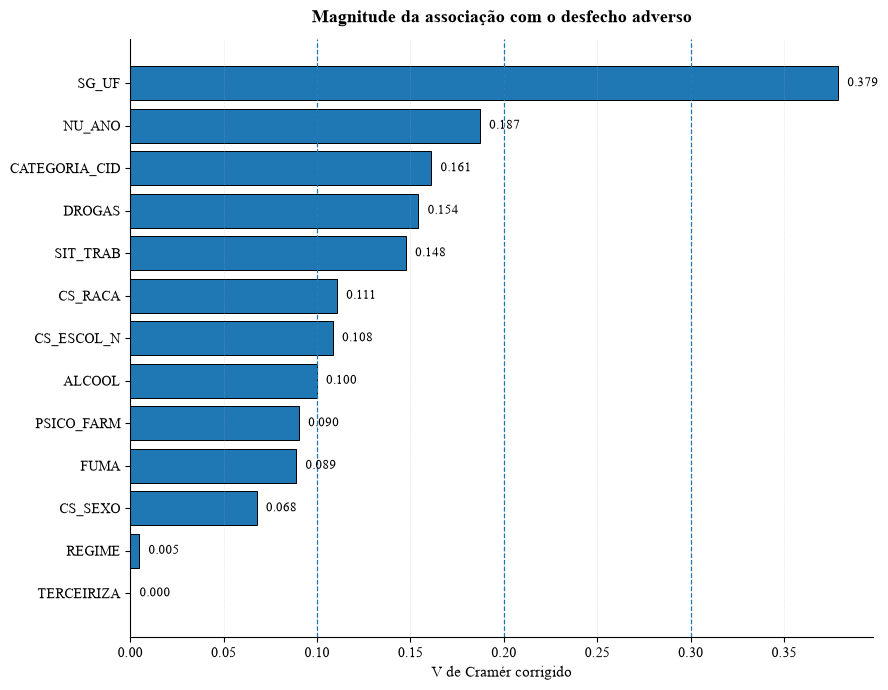


ANÁLISE DE CORRESPONDÊNCIA — SG_UF


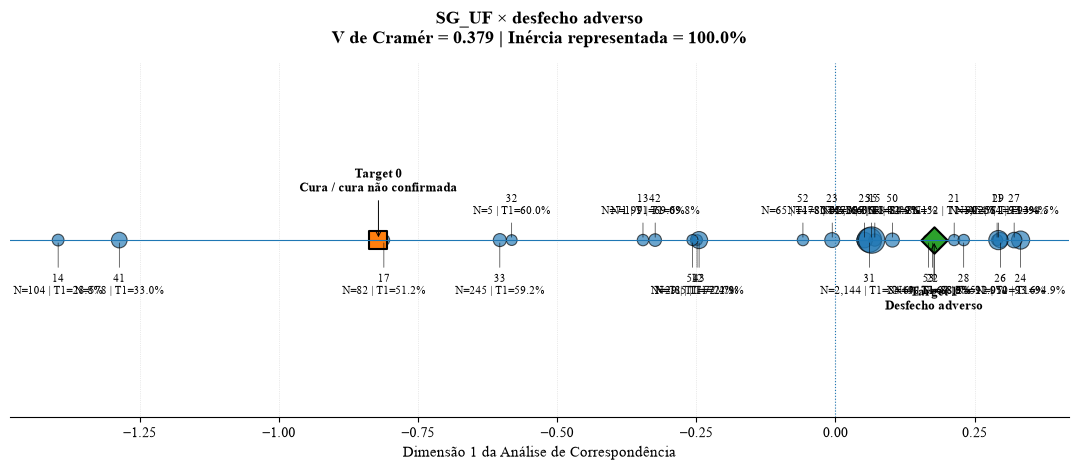

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
9,24,24,950,94.95,0.3327
12,27,27,564,94.50,0.3211
11,26,26,512,93.55,0.2963
14,29,29,1125,93.42,0.2928
0,11,11,45,93.33,0.2905
13,28,28,67,91.04,0.2306
6,21,21,52,90.38,0.2133
7,22,22,9,88.89,0.1742
25,53,53,44,88.64,0.1676
22,50,50,368,86.14,0.1023



ANÁLISE DE CORRESPONDÊNCIA — NU_ANO


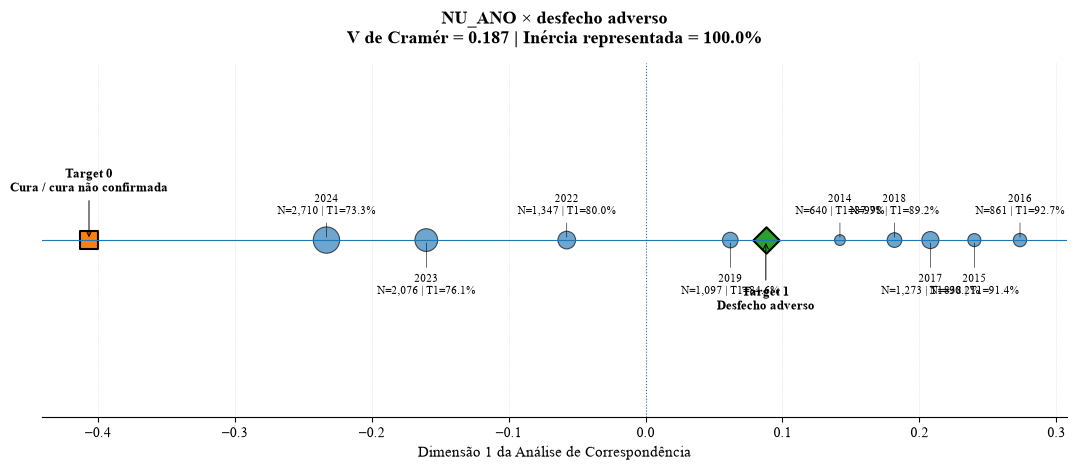

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
2,2016,2016,861,92.68,0.2735
1,2015,2015,838,91.41,0.2401
3,2017,2017,1273,90.18,0.2080
4,2018,2018,998,89.18,0.1818
0,2014,2014,640,87.66,0.1420
5,2019,2019,1097,84.59,0.0619
6,2022,2022,1347,80.03,-0.0576
7,2023,2023,2076,76.11,-0.1601
8,2024,2024,2710,73.32,-0.2331



ANÁLISE DE CORRESPONDÊNCIA — DROGAS


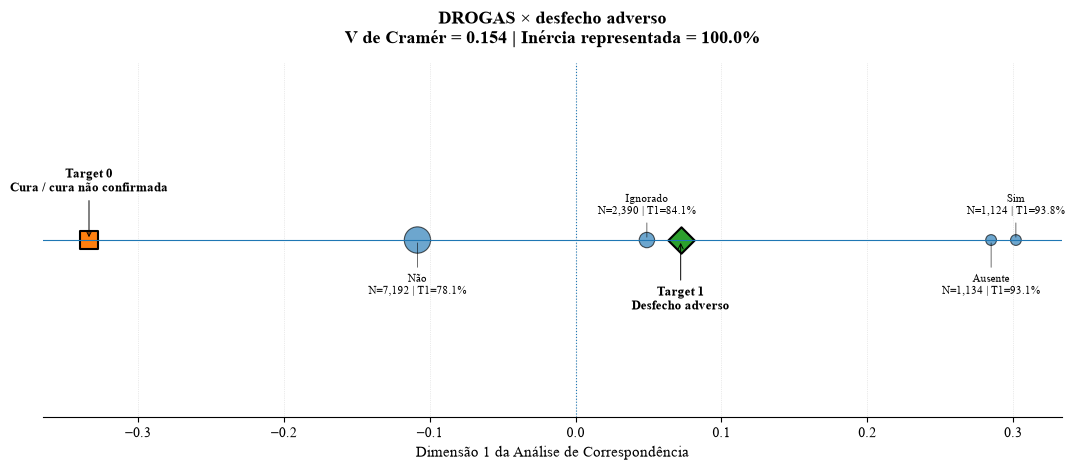

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
0,1,Sim,1124,93.77,0.3020
3,Ausente,Ausente,1134,93.12,0.2849
2,9,Ignorado,2390,84.10,0.0489
1,2,Não,7192,78.09,-0.1084



ANÁLISE DE CORRESPONDÊNCIA — SIT_TRAB


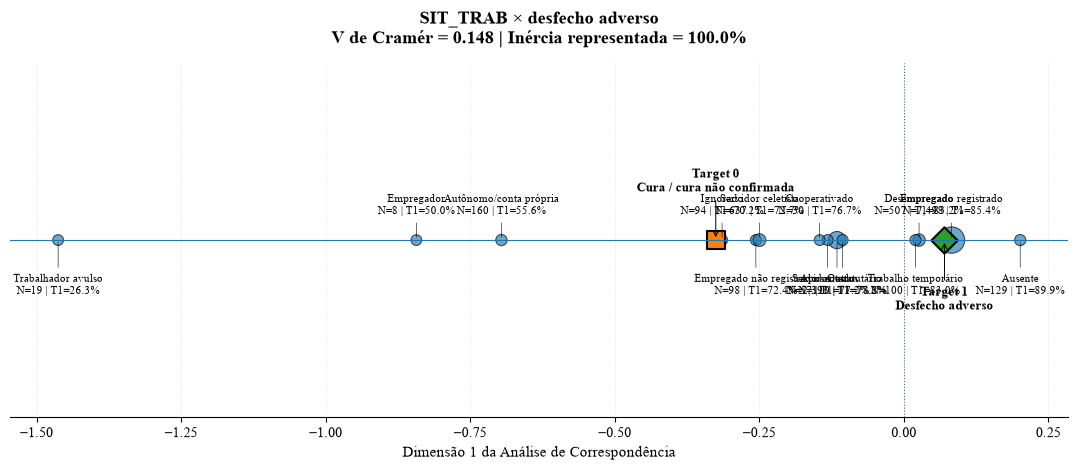

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
13,Ausente,Ausente,129,89.92,0.2012
0,01,Empregado registrado,7498,85.38,0.0825
6,07,Desempregado,507,83.23,0.0263
7,08,Trabalho temporário,100,83.00,0.0202
11,12,Outros,110,78.18,-0.1059
3,04,Servidor estatutário,2393,77.81,-0.1156
5,06,Aposentado,57,77.19,-0.1318
8,09,Cooperativado,30,76.67,-0.1455
4,05,Servidor celetista,637,72.68,-0.2497
1,02,Empregado não registrado,98,72.45,-0.2559



ANÁLISE DE CORRESPONDÊNCIA — CS_RACA


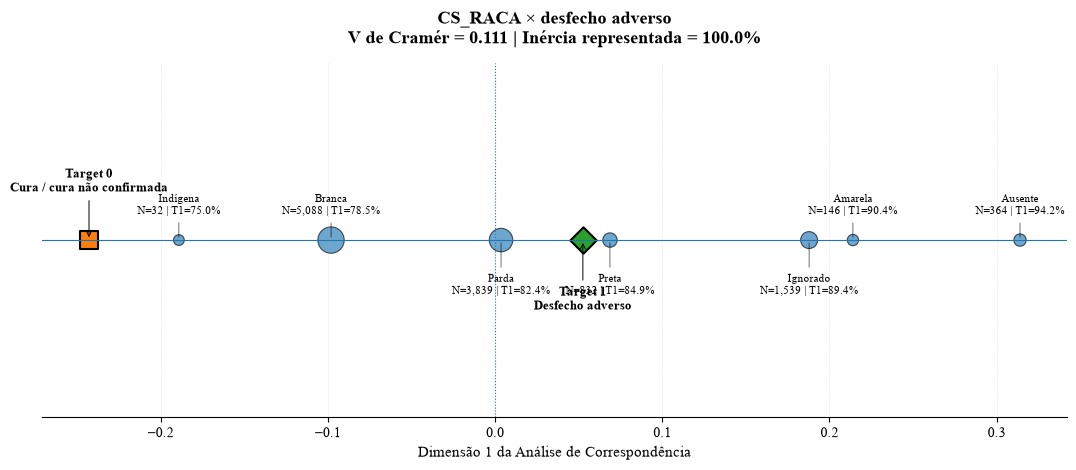

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
6,Ausente,Ausente,364,94.23,0.3139
2,3,Amarela,146,90.41,0.2140
5,9,Ignorado,1539,89.41,0.1878
1,2,Preta,832,84.86,0.0687
3,4,Parda,3839,82.37,0.0035
0,1,Branca,5088,78.48,-0.0981
4,5,Indígena,32,75.00,-0.1891



ANÁLISE DE CORRESPONDÊNCIA — CS_ESCOL_N


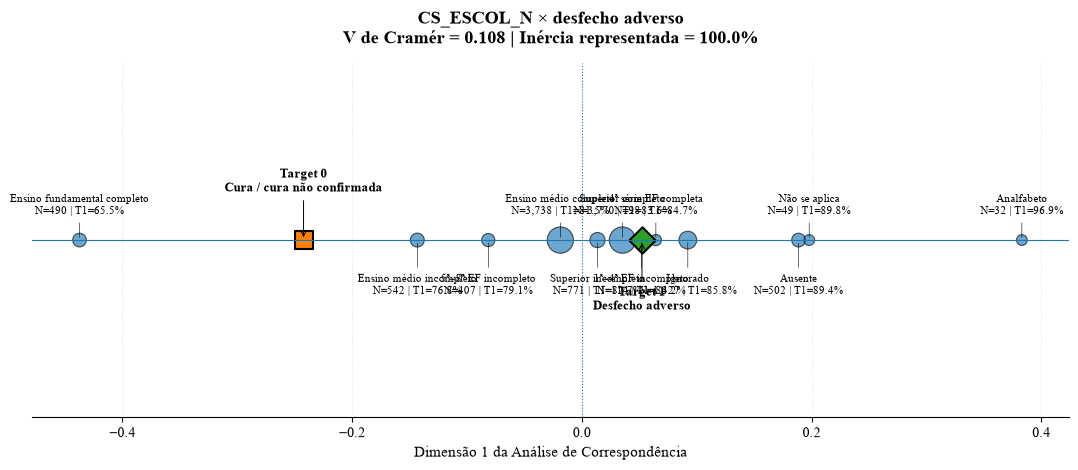

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
0,00,Analfabeto,32,96.88,0.3831
10,10,Não se aplica,49,89.80,0.1979
11,Ausente,Ausente,502,89.44,0.1887
9,09,Ignorado,1327,85.76,0.0923
2,02,4ª série EF completa,98,84.69,0.0645
1,01,1ª–4ª EF incompleto,114,84.21,0.0518
8,08,Superior completo,3770,83.58,0.0353
7,07,Superior incompleto,771,82.75,0.0136
6,06,Ensino médio completo,3738,81.51,-0.0187
3,03,5ª–8ª EF incompleto,407,79.12,-0.0815



ANÁLISE DE CORRESPONDÊNCIA — ALCOOL


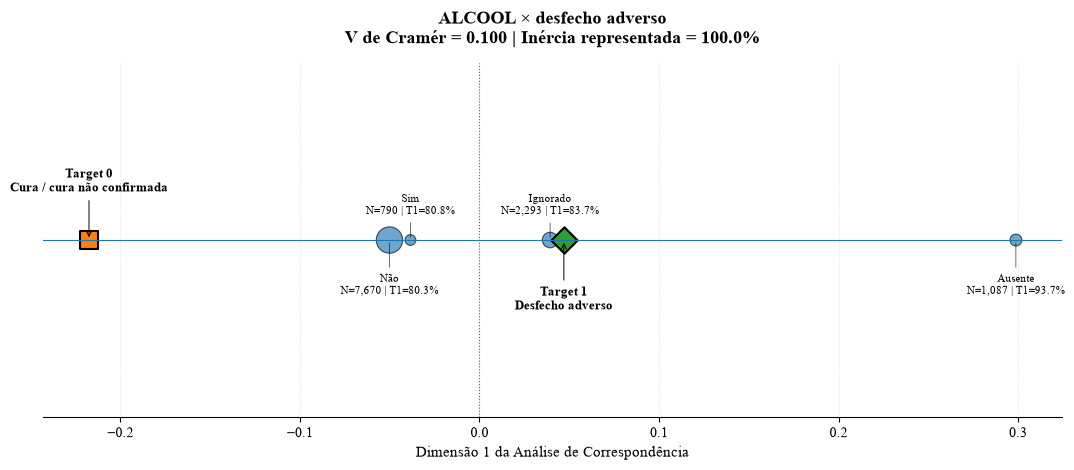

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
3,Ausente,Ausente,1087,93.65,0.2988
2,9,Ignorado,2293,83.73,0.0393
0,1,Sim,790,80.76,-0.0385
1,2,Não,7670,80.31,-0.0501



ANÁLISE DE CORRESPONDÊNCIA — PSICO_FARM


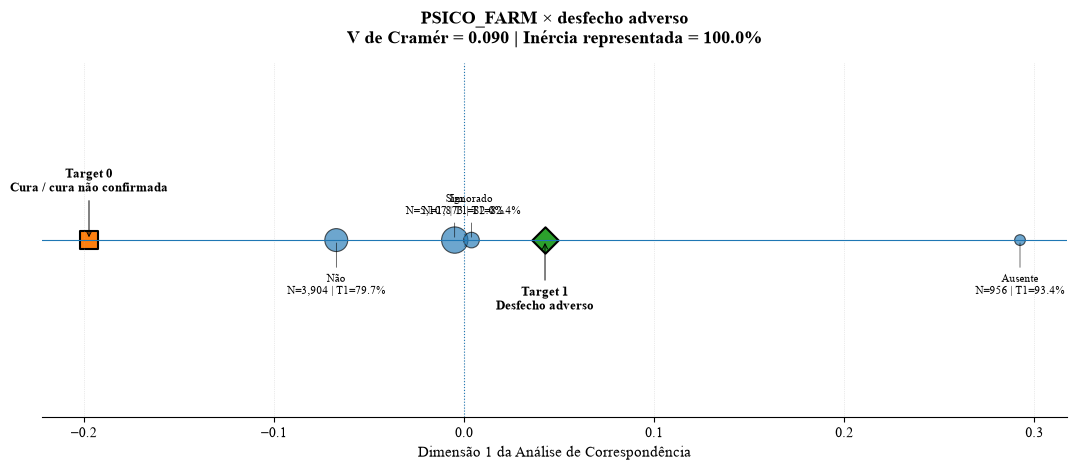

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
3,Ausente,Ausente,956,93.41,0.2925
2,9,Ignorado,1873,82.38,0.0040
0,1,Sim,5107,82.04,-0.0049
1,2,Não,3904,79.66,-0.0672



ANÁLISE DE CORRESPONDÊNCIA — FUMA


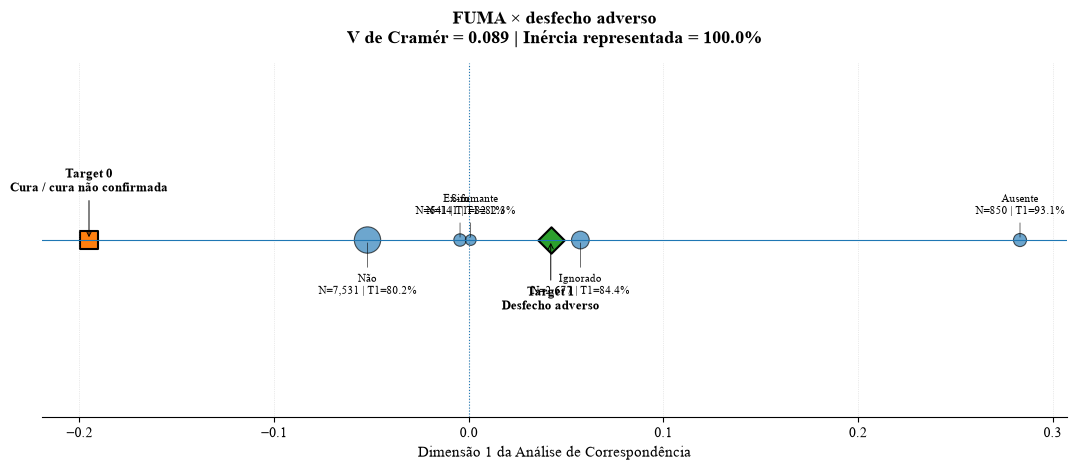

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
4,Ausente,Ausente,850,93.06,0.2833
3,9,Ignorado,2677,84.42,0.0574
2,3,Ex-fumante,141,82.27,0.0010
0,1,Sim,641,82.06,-0.0045
1,2,Não,7531,80.24,-0.0520



ANÁLISE DE CORRESPONDÊNCIA — CS_SEXO


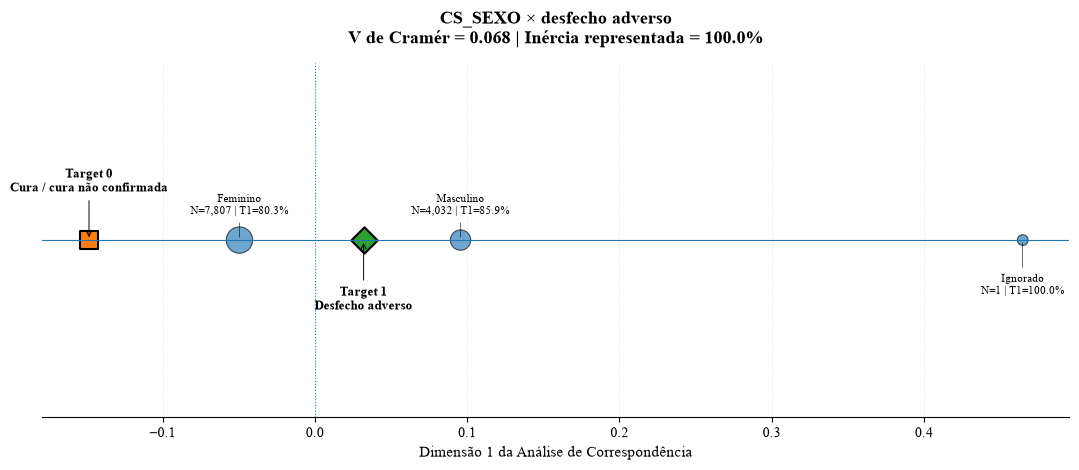

,CATEGORIA,DESCRICAO,N,PCT_TARGET_1,COORD_DIM1
1,I,Ignorado,1,100.00,0.4649
2,M,Masculino,4032,85.89,0.0957
0,F,Feminino,7807,80.34,-0.0495



BLOCO 15.4 CONCLUÍDO

✓ Ranking visual do V de Cramér produzido.

✓ 10 análises de correspondência realizadas.

✓ Tamanho dos pontos representa frequência das categorias.

✓ Percentual de Target 1 apresentado em cada categoria.

✓ Ausentes permanecem explicitamente identificados.

✓ Nenhuma categoria foi agrupada automaticamente.

✓ CATEGORIA_CID foi reservada para análise específica.

✓ REGIME e TERCEIRIZA não foram priorizadas nos mapas principais.

✓ Nenhum atributo foi selecionado ou excluído automaticamente.

✓ 2025 permaneceu completamente fora desta análise.



In [119]:
# ============================================================
# BLOCO 15.4
# VISUALIZAÇÃO DAS ASSOCIAÇÕES +
# ANÁLISE DE CORRESPONDÊNCIA UNIDIMENSIONAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import svd


print("=" * 110)
print("BLOCO 15.4 — VISUALIZAÇÃO DAS ASSOCIAÇÕES")
print("              E ANÁLISE DE CORRESPONDÊNCIA")
print("=" * 110)


# ============================================================
# 1. CONFIGURAÇÃO VISUAL
# ============================================================

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]

plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10


TARGET = "TARGET_DESFECHO_ADVERSO"

df_ca = df_modelagem_hist.copy()


# ============================================================
# 2. SEGURANÇA
# ============================================================

if TARGET not in df_ca.columns:
    raise KeyError(f"{TARGET} não encontrado.")


if df_ca[TARGET].isna().any():
    raise ValueError("Existem registros sem target definido.")


if (
    pd.to_numeric(
        df_ca["NU_ANO"],
        errors="coerce"
    ) == 2025
).any():
    raise ValueError("2025 apareceu na base histórica.")


print(f"\nRegistros utilizados: {len(df_ca):,}")
print("✓ Target completamente definido.")
print("✓ 2025 permanece reservado.")


# ============================================================
# 3. FIGURA 15.4A
# RANKING VISUAL DO V DE CRAMÉR
# ============================================================

ranking_plot = (
    df_cramer
    .sort_values("V_CRAMER", ascending=True)
    .copy()
)


fig, ax = plt.subplots(figsize=(9, 7))


ax.barh(
    ranking_plot["VARIAVEL"],
    ranking_plot["V_CRAMER"],
    edgecolor="black",
    linewidth=0.7
)


for i, valor in enumerate(ranking_plot["V_CRAMER"]):

    ax.text(
        valor + 0.005,
        i,
        f"{valor:.3f}",
        va="center",
        fontsize=9
    )


ax.axvline(
    0.10,
    linestyle="--",
    linewidth=0.9
)

ax.axvline(
    0.20,
    linestyle="--",
    linewidth=0.9
)

ax.axvline(
    0.30,
    linestyle="--",
    linewidth=0.9
)


ax.set_xlabel("V de Cramér corrigido")
ax.set_ylabel("")

ax.set_title(
    "Magnitude da associação com o desfecho adverso",
    fontweight="bold",
    pad=12
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.5,
    alpha=0.5
)


plt.tight_layout()
plt.show()


# ============================================================
# 4. FUNÇÃO DE PREPARAÇÃO
# ============================================================

def preparar_categoria_ca(serie):

    s = serie.astype("string").str.strip()

    s = s.mask(
        s.eq(""),
        "Ausente"
    )

    s = s.fillna(
        "Ausente"
    )

    return s


# ============================================================
# 5. RÓTULOS DOCUMENTADOS
# ============================================================

rotulos_ca = {

    "CS_SEXO": {
        "F": "Feminino",
        "M": "Masculino",
        "I": "Ignorado"
    },

    "CS_RACA": {
        "1": "Branca",
        "2": "Preta",
        "3": "Amarela",
        "4": "Parda",
        "5": "Indígena",
        "9": "Ignorado"
    },

    "CS_ESCOL_N": {
        "00": "Analfabeto",
        "01": "1ª–4ª EF incompleto",
        "02": "4ª série EF completa",
        "03": "5ª–8ª EF incompleto",
        "04": "Ensino fundamental completo",
        "05": "Ensino médio incompleto",
        "06": "Ensino médio completo",
        "07": "Superior incompleto",
        "08": "Superior completo",
        "09": "Ignorado",
        "10": "Não se aplica"
    },

    "SIT_TRAB": {
        "01": "Empregado registrado",
        "02": "Empregado não registrado",
        "03": "Autônomo/conta própria",
        "04": "Servidor estatutário",
        "05": "Servidor celetista",
        "06": "Aposentado",
        "07": "Desempregado",
        "08": "Trabalho temporário",
        "09": "Cooperativado",
        "10": "Trabalhador avulso",
        "11": "Empregador",
        "12": "Outros",
        "99": "Ignorado"
    },

    "DROGAS": {
        "1": "Sim",
        "2": "Não",
        "9": "Ignorado"
    },

    "ALCOOL": {
        "1": "Sim",
        "2": "Não",
        "9": "Ignorado"
    },

    "PSICO_FARM": {
        "1": "Sim",
        "2": "Não",
        "9": "Ignorado"
    },

    "FUMA": {
        "1": "Sim",
        "2": "Não",
        "3": "Ex-fumante",
        "9": "Ignorado"
    }
}


# ============================================================
# 6. NORMALIZAÇÃO ESPECÍFICA DE SIT_TRAB
# ============================================================

def normalizar_codigo(variavel, valor):

    if pd.isna(valor):
        return "Ausente"

    valor = str(valor).strip()

    if valor == "":
        return "Ausente"

    # Corrige representação 1.0 -> 1
    if valor.endswith(".0"):
        valor = valor[:-2]

    # SIT_TRAB utiliza 01, 02, ..., 09
    if variavel == "SIT_TRAB":

        if valor.isdigit():

            inteiro = int(valor)

            if 1 <= inteiro <= 9:
                valor = f"{inteiro:02d}"

    return valor


# ============================================================
# 7. FUNÇÃO — ANÁLISE DE CORRESPONDÊNCIA
# ============================================================

def analise_correspondencia_1d(
    dataframe,
    variavel,
    target=TARGET
):

    # --------------------------------------------------------
    # Dados
    # --------------------------------------------------------

    x = preparar_categoria_ca(
        dataframe[variavel]
    )

    x = x.map(
        lambda z: normalizar_codigo(
            variavel,
            z
        )
    )

    y = dataframe[target].astype(int)


    tabela = pd.crosstab(
        x,
        y
    )


    # Garantir target 0 e 1
    tabela = tabela.reindex(
        columns=[0, 1],
        fill_value=0
    )


    # --------------------------------------------------------
    # Matriz de correspondência
    # --------------------------------------------------------

    N = tabela.to_numpy(dtype=float)

    n = N.sum()

    P = N / n


    # Massas
    r = P.sum(axis=1)
    c = P.sum(axis=0)


    # Segurança
    valid_rows = r > 0

    P = P[valid_rows, :]
    r = r[valid_rows]

    categorias = (
        tabela.index.to_numpy()[valid_rows]
    )


    Dr_inv_sqrt = np.diag(
        1 / np.sqrt(r)
    )

    Dc_inv_sqrt = np.diag(
        1 / np.sqrt(c)
    )


    esperado = np.outer(
        r,
        c
    )


    S = (
        Dr_inv_sqrt
        @ (P - esperado)
        @ Dc_inv_sqrt
    )


    # --------------------------------------------------------
    # SVD
    # --------------------------------------------------------

    U, singular_values, VT = svd(
        S,
        full_matrices=False
    )


    # Primeira dimensão
    sigma1 = singular_values[0]


    # Coordenadas principais das linhas
    coord_linhas = (
        Dr_inv_sqrt
        @ U[:, [0]]
        * sigma1
    ).ravel()


    # Coordenadas principais das colunas
    Dc_inv_sqrt_diag = np.diag(
        1 / np.sqrt(c)
    )

    V = VT.T

    coord_colunas = (
        Dc_inv_sqrt_diag
        @ V[:, [0]]
        * sigma1
    ).ravel()


    # --------------------------------------------------------
    # Orientação visual padronizada
    #
    # Queremos Target 1 à direita.
    # O sinal matemático é arbitrário.
    # --------------------------------------------------------

    if coord_colunas[1] < coord_colunas[0]:

        coord_linhas *= -1
        coord_colunas *= -1


    # --------------------------------------------------------
    # Frequências
    # --------------------------------------------------------

    frequencias = (
        N[valid_rows, :]
        .sum(axis=1)
    )


    pct_target1 = np.divide(
        N[valid_rows, 1],
        frequencias,
        out=np.zeros_like(frequencias),
        where=frequencias != 0
    ) * 100


    # --------------------------------------------------------
    # Inércia
    # --------------------------------------------------------

    inercias = singular_values ** 2

    inercia_total = inercias.sum()

    pct_dim1 = (
        inercias[0]
        / inercia_total
        * 100
        if inercia_total > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Resultado
    # --------------------------------------------------------

    resultado = pd.DataFrame({

        "CATEGORIA":
            categorias,

        "COORD_DIM1":
            coord_linhas,

        "N":
            frequencias.astype(int),

        "PCT_TARGET_1":
            pct_target1

    })


    # Aplicar descrição
    mapa = rotulos_ca.get(
        variavel,
        {}
    )


    resultado["DESCRICAO"] = (

        resultado["CATEGORIA"]
        .astype(str)
        .map(mapa)
        .fillna(
            resultado["CATEGORIA"]
            .astype(str)
        )

    )


    return (
        resultado,
        coord_colunas,
        pct_dim1,
        tabela
    )


# ============================================================
# 8. FUNÇÃO DE GRÁFICO
# ============================================================

def plot_correspondencia_1d(
    dataframe,
    variavel
):

    (
        resultado,
        coord_target,
        pct_dim1,
        tabela

    ) = analise_correspondencia_1d(
        dataframe,
        variavel
    )


    # --------------------------------------------------------
    # Recuperar V de Cramér
    # --------------------------------------------------------

    linha_v = df_cramer.loc[
        df_cramer["VARIAVEL"] == variavel
    ]


    if len(linha_v) > 0:

        v_cramer = (
            linha_v["V_CRAMER"]
            .iloc[0]
        )

    else:
        v_cramer = np.nan


    # --------------------------------------------------------
    # Figura
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(11, 4.8)
    )


    # Linha central
    ax.axhline(
        0,
        linewidth=0.8
    )

    ax.axvline(
        0,
        linestyle=":",
        linewidth=0.8
    )


    # --------------------------------------------------------
    # Tamanho dos pontos
    # --------------------------------------------------------

    n = resultado["N"].to_numpy()

    if n.max() == n.min():

        tamanhos = np.repeat(
            100,
            len(n)
        )

    else:

        tamanhos = (
            60
            + 300
            * (
                (n - n.min())
                / (n.max() - n.min())
            )
        )


    # --------------------------------------------------------
    # Categorias
    # --------------------------------------------------------

    ax.scatter(
        resultado["COORD_DIM1"],
        np.zeros(len(resultado)),
        s=tamanhos,
        edgecolors="black",
        linewidths=0.8,
        alpha=0.65,
        label="Categorias do preditor"
    )


    # --------------------------------------------------------
    # Target
    # --------------------------------------------------------

    ax.scatter(
        coord_target[0],
        0,
        marker="s",
        s=180,
        edgecolors="black",
        linewidths=1.5,
        label="Target 0"
    )


    ax.scatter(
        coord_target[1],
        0,
        marker="D",
        s=180,
        edgecolors="black",
        linewidths=1.5,
        label="Target 1"
    )


    # --------------------------------------------------------
    # Rótulos das categorias
    # --------------------------------------------------------

    for i, linha in resultado.iterrows():

        deslocamento = (
            0.045
            if i % 2 == 0
            else -0.065
        )

        ax.annotate(

            f"{linha['DESCRICAO']}\n"
            f"N={linha['N']:,} | "
            f"T1={linha['PCT_TARGET_1']:.1f}%",

            (
                linha["COORD_DIM1"],
                0
            ),

            xytext=(
                linha["COORD_DIM1"],
                deslocamento
            ),

            textcoords="data",

            ha="center",

            va=(
                "bottom"
                if deslocamento > 0
                else "top"
            ),

            fontsize=8,

            arrowprops=dict(
                arrowstyle="-",
                linewidth=0.4
            )

        )


    # Target labels
    ax.annotate(
        "Target 0\nCura / cura não confirmada",
        (coord_target[0], 0),
        xytext=(0, 35),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="->",
            linewidth=0.7
        )
    )


    ax.annotate(
        "Target 1\nDesfecho adverso",
        (coord_target[1], 0),
        xytext=(0, -50),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="->",
            linewidth=0.7
        )
    )


    # --------------------------------------------------------
    # Aparência
    # --------------------------------------------------------

    ax.set_ylim(
        -0.35,
        0.35
    )

    ax.set_yticks([])

    ax.set_xlabel(
        "Dimensão 1 da Análise de Correspondência"
    )


    ax.set_title(
        f"{variavel} × desfecho adverso\n"
        f"V de Cramér = {v_cramer:.3f} | "
        f"Inércia representada = {pct_dim1:.1f}%",
        fontweight="bold",
        pad=14
    )


    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)


    ax.grid(
        axis="x",
        linestyle=":",
        linewidth=0.5,
        alpha=0.5
    )


    plt.tight_layout()

    plt.show()


    return resultado


# ============================================================
# 9. VARIÁVEIS PARA OS MAPAS PRINCIPAIS
# ============================================================

variaveis_ca = [

    "SG_UF",

    "NU_ANO",

    "DROGAS",

    "SIT_TRAB",

    "CS_RACA",

    "CS_ESCOL_N",

    "ALCOOL",

    "PSICO_FARM",

    "FUMA",

    "CS_SEXO"
]


variaveis_ca = [
    v
    for v in variaveis_ca
    if v in df_ca.columns
]


# ============================================================
# 10. EXECUÇÃO
# ============================================================

resultados_ca = {}


for variavel in variaveis_ca:

    print("\n" + "=" * 110)
    print(f"ANÁLISE DE CORRESPONDÊNCIA — {variavel}")
    print("=" * 110)


    resultado = plot_correspondencia_1d(
        df_ca,
        variavel
    )


    resultados_ca[variavel] = (
        resultado
    )


    tabela_saida = (
        resultado[
            [
                "CATEGORIA",
                "DESCRICAO",
                "N",
                "PCT_TARGET_1",
                "COORD_DIM1"
            ]
        ]
        .sort_values(
            "COORD_DIM1",
            ascending=False
        )
        .copy()
    )


    tabela_saida[
        "PCT_TARGET_1"
    ] = (
        tabela_saida[
            "PCT_TARGET_1"
        ]
        .round(2)
    )


    tabela_saida[
        "COORD_DIM1"
    ] = (
        tabela_saida[
            "COORD_DIM1"
        ]
        .round(4)
    )


    display(
        tabela_saida
    )


# ============================================================
# 11. CONCLUSÃO
# ============================================================

print("\n" + "=" * 110)
print("BLOCO 15.4 CONCLUÍDO")
print("=" * 110)

print(
    f"""
✓ Ranking visual do V de Cramér produzido.

✓ {len(variaveis_ca)} análises de correspondência realizadas.

✓ Tamanho dos pontos representa frequência das categorias.

✓ Percentual de Target 1 apresentado em cada categoria.

✓ Ausentes permanecem explicitamente identificados.

✓ Nenhuma categoria foi agrupada automaticamente.

✓ CATEGORIA_CID foi reservada para análise específica.

✓ REGIME e TERCEIRIZA não foram priorizadas nos mapas principais.

✓ Nenhum atributo foi selecionado ou excluído automaticamente.

✓ 2025 permaneceu completamente fora desta análise.
"""
)

BLOCO 15.5A — MATRIZ GLOBAL DE ASSOCIAÇÃO CATEGÓRICA
Registros: 11,840
✓ 2025 permanece reservado.

Variáveis incluídas:
 ✓ TARGET_DESFECHO_ADVERSO
 ✓ NU_ANO
 ✓ CS_SEXO
 ✓ CS_RACA
 ✓ CS_ESCOL_N
 ✓ SG_UF
 ✓ SIT_TRAB
 ✓ TERCEIRIZA
 ✓ ALCOOL
 ✓ PSICO_FARM
 ✓ DROGAS
 ✓ FUMA

Matriz de V de Cramér:


,TARGET_DESFECHO_ADVERSO,NU_ANO,CS_SEXO,CS_RACA,CS_ESCOL_N,SG_UF,SIT_TRAB,TERCEIRIZA,ALCOOL,PSICO_FARM,DROGAS,FUMA
TARGET_DESFECHO_ADVERSO,1.000,0.187,0.068,0.111,0.108,0.379,0.148,0.000,0.100,0.090,0.154,0.089
NU_ANO,0.187,1.000,0.073,0.090,0.047,0.169,0.066,0.034,0.091,0.101,0.168,0.074
CS_SEXO,0.068,0.073,1.000,0.074,0.108,0.133,0.086,0.024,0.105,0.058,0.103,0.070
CS_RACA,0.111,0.090,0.074,1.000,0.215,0.230,0.091,0.097,0.269,0.275,0.266,0.228
CS_ESCOL_N,0.108,0.047,0.108,0.215,1.000,0.115,0.109,0.094,0.181,0.183,0.195,0.150
SG_UF,0.379,0.169,0.133,0.230,0.115,1.000,0.144,0.170,0.288,0.288,0.388,0.235
SIT_TRAB,0.148,0.066,0.086,0.091,0.109,0.144,1.000,0.138,0.121,0.098,0.126,0.088
TERCEIRIZA,0.000,0.034,0.024,0.097,0.094,0.170,0.138,1.000,0.102,0.086,0.102,0.084
ALCOOL,0.100,0.091,0.105,0.269,0.181,0.288,0.121,0.102,1.000,0.662,0.754,0.606
PSICO_FARM,0.090,0.101,0.058,0.275,0.183,0.288,0.098,0.086,0.662,1.000,0.678,0.552


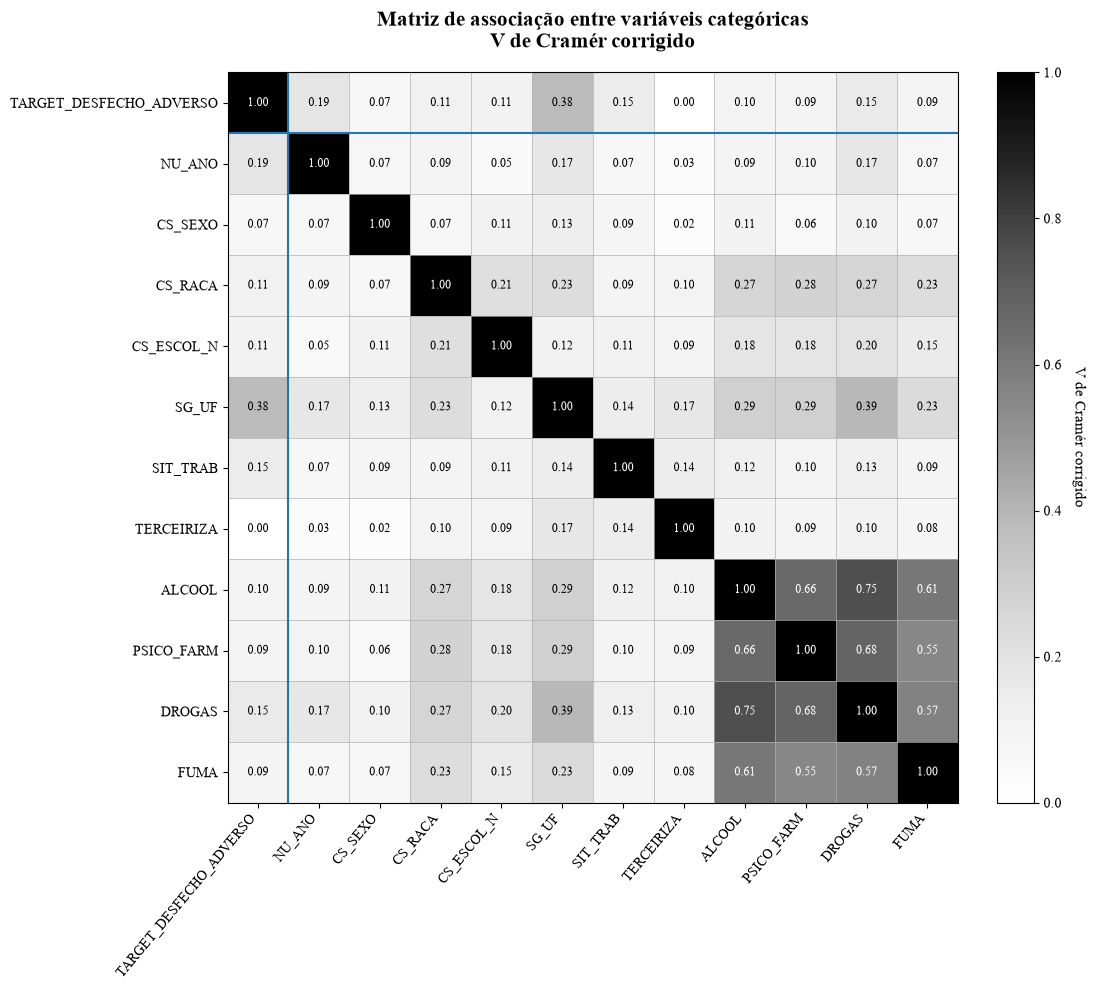


20 MAIORES ASSOCIAÇÕES ENTRE VARIÁVEIS


,VARIAVEL_1,VARIAVEL_2,V_CRAMER
0,ALCOOL,DROGAS,0.7544
1,PSICO_FARM,DROGAS,0.6777
2,ALCOOL,PSICO_FARM,0.6624
3,ALCOOL,FUMA,0.6062
4,DROGAS,FUMA,0.5679
5,PSICO_FARM,FUMA,0.5524
6,SG_UF,DROGAS,0.3878
7,TARGET_DESFECHO_ADVERSO,SG_UF,0.3789
8,SG_UF,ALCOOL,0.2883
9,SG_UF,PSICO_FARM,0.2875


In [120]:
# ============================================================
# BLOCO 15.5A
# MATRIZ DE V DE CRAMÉR — TODAS AS VARIÁVEIS CATEGÓRICAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency


print("=" * 100)
print("BLOCO 15.5A — MATRIZ GLOBAL DE ASSOCIAÇÃO CATEGÓRICA")
print("=" * 100)


# ============================================================
# 1. BASE
# ============================================================

df_v_global = df_modelagem_hist.copy()

TARGET = "TARGET_DESFECHO_ADVERSO"


if TARGET not in df_v_global.columns:
    raise KeyError(f"{TARGET} não encontrado.")


if df_v_global[TARGET].isna().any():
    raise ValueError("Existem registros sem target definido.")


if (
    pd.to_numeric(
        df_v_global["NU_ANO"],
        errors="coerce"
    ) == 2025
).any():

    raise ValueError(
        "2025 apareceu na base histórica."
    )


print(f"Registros: {len(df_v_global):,}")
print("✓ 2025 permanece reservado.")


# ============================================================
# 2. VARIÁVEIS
# ============================================================

variaveis_matriz = [

    "TARGET_DESFECHO_ADVERSO",

    "NU_ANO",

    "CS_SEXO",

    "CS_RACA",

    "CS_ESCOL_N",

    "SG_UF",

    "SIT_TRAB",

    "TERCEIRIZA",

    "ALCOOL",

    "PSICO_FARM",

    "DROGAS",

    "FUMA"

]


variaveis_matriz = [
    v for v in variaveis_matriz
    if v in df_v_global.columns
]


print("\nVariáveis incluídas:")

for v in variaveis_matriz:
    print(" ✓", v)


# ============================================================
# 3. PREPARAÇÃO
# ============================================================

def preparar_categorica_global(s):

    s = (
        s
        .astype("string")
        .str.strip()
    )

    s = s.mask(
        s.eq(""),
        "Ausente"
    )

    s = s.fillna(
        "Ausente"
    )

    return s


# ============================================================
# 4. V DE CRAMÉR CORRIGIDO
# ============================================================

def cramer_v_par(x, y):

    tabela = pd.crosstab(
        x,
        y
    )

    if (
        tabela.shape[0] < 2
        or tabela.shape[1] < 2
    ):
        return np.nan


    try:

        chi2 = chi2_contingency(
            tabela
        )[0]

    except ValueError:

        return np.nan


    n = tabela.to_numpy().sum()

    r, k = tabela.shape


    if n <= 1:
        return np.nan


    phi2 = chi2 / n


    phi2corr = max(
        0,
        phi2
        - (
            (k - 1) * (r - 1)
            / (n - 1)
        )
    )


    rcorr = (
        r
        - ((r - 1) ** 2)
        / (n - 1)
    )


    kcorr = (
        k
        - ((k - 1) ** 2)
        / (n - 1)
    )


    denominador = min(
        kcorr - 1,
        rcorr - 1
    )


    if denominador <= 0:
        return np.nan


    return np.sqrt(
        phi2corr
        / denominador
    )


# ============================================================
# 5. MATRIZ
# ============================================================

n_var = len(
    variaveis_matriz
)


matriz_v = pd.DataFrame(

    np.ones(
        (n_var, n_var)
    ),

    index=variaveis_matriz,

    columns=variaveis_matriz
)


for i, var1 in enumerate(
    variaveis_matriz
):

    x = preparar_categorica_global(
        df_v_global[var1]
    )


    for j, var2 in enumerate(
        variaveis_matriz
    ):

        if i == j:
            matriz_v.iloc[i, j] = 1.0

        elif j < i:

            matriz_v.iloc[i, j] = (
                matriz_v.iloc[j, i]
            )

        else:

            y = preparar_categorica_global(
                df_v_global[var2]
            )


            matriz_v.iloc[i, j] = (
                cramer_v_par(
                    x,
                    y
                )
            )


# ============================================================
# 6. EXIBIR MATRIZ NUMÉRICA
# ============================================================

print(
    "\nMatriz de V de Cramér:"
)

display(
    matriz_v.round(3)
)


# ============================================================
# 7. GRÁFICO
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 10)
)


imagem = ax.imshow(
    matriz_v.to_numpy(),
    vmin=0,
    vmax=1,
    cmap="Greys"
)


# ============================================================
# 8. NOMES DOS EIXOS
# ============================================================

ax.set_xticks(
    np.arange(n_var)
)

ax.set_yticks(
    np.arange(n_var)
)


ax.set_xticklabels(
    variaveis_matriz,
    rotation=50,
    ha="right"
)


ax.set_yticklabels(
    variaveis_matriz
)


# ============================================================
# 9. VALORES DENTRO DAS CÉLULAS
# ============================================================

for i in range(n_var):

    for j in range(n_var):

        valor = matriz_v.iloc[i, j]


        if pd.isna(valor):
            texto = "NA"

        else:
            texto = f"{valor:.2f}"


        # texto branco em células escuras
        cor_texto = (
            "white"
            if valor >= 0.50
            else "black"
        )


        ax.text(
            j,
            i,
            texto,
            ha="center",
            va="center",
            fontsize=8.5,
            color=cor_texto
        )


# ============================================================
# 10. LINHAS DA MATRIZ
# ============================================================

ax.set_xticks(
    np.arange(
        -0.5,
        n_var,
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        n_var,
        1
    ),
    minor=True
)


ax.grid(
    which="minor",
    linewidth=0.5
)


ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)


# ============================================================
# 11. DESTAQUE DO TARGET
# ============================================================

idx_target = (
    variaveis_matriz.index(
        TARGET
    )
)


ax.axhline(
    idx_target + 0.5,
    linewidth=1.5
)

ax.axvline(
    idx_target + 0.5,
    linewidth=1.5
)


# ============================================================
# 12. TÍTULO
# ============================================================

ax.set_title(
    "Matriz de associação entre variáveis categóricas\n"
    "V de Cramér corrigido",
    fontsize=15,
    fontweight="bold",
    pad=18
)


# ============================================================
# 13. BARRA DE ESCALA
# ============================================================

cbar = fig.colorbar(
    imagem,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


cbar.set_label(
    "V de Cramér corrigido",
    rotation=270,
    labelpad=18
)


plt.tight_layout()

plt.show()


# ============================================================
# 14. MAIORES ASSOCIAÇÕES — EXCLUINDO A DIAGONAL
# ============================================================

pares = []


for i in range(n_var):

    for j in range(i + 1, n_var):

        pares.append({

            "VARIAVEL_1":
                variaveis_matriz[i],

            "VARIAVEL_2":
                variaveis_matriz[j],

            "V_CRAMER":
                matriz_v.iloc[i, j]

        })


df_pares_cramer = pd.DataFrame(
    pares
)


df_pares_cramer = (
    df_pares_cramer
    .sort_values(
        "V_CRAMER",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n"
    + "=" * 100
)

print(
    "20 MAIORES ASSOCIAÇÕES ENTRE VARIÁVEIS"
)

print(
    "=" * 100
)


display(
    df_pares_cramer
    .head(20)
    .round(
        {"V_CRAMER": 4}
    )
)

### 15.5.1. Matriz de associações bivariadas entre as variáveis analisadas

A matriz de associações bivariadas foi construída com o objetivo de avaliar a
estrutura de dependência entre as variáveis categóricas consideradas nesta etapa
da análise. Diferentemente da avaliação anterior, na qual cada variável foi
comparada individualmente com o desfecho, esta matriz apresenta o **V de Cramér
corrigido para todos os pares de variáveis incluídos na análise**.

Dessa forma, a figura permite examinar simultaneamente:

- a associação de cada variável com o desfecho;
- as associações existentes entre os próprios preditores;
- possíveis grupos de variáveis que compartilham informação;
- potenciais redundâncias que deverão ser consideradas antes da modelagem
  multivariada.

A diagonal principal apresenta valor igual a 1, pois corresponde à associação
de cada variável consigo mesma, não possuindo finalidade interpretativa.

### Interpretação da magnitude

A intensidade das associações foi representada pelo V de Cramér corrigido.
Valores próximos de zero indicam pouca associação entre as variáveis, enquanto
valores progressivamente maiores indicam maior dependência entre suas
distribuições categóricas.

Para fins exclusivamente exploratórios, foram mantidos os intervalos utilizados
nas análises anteriores:

- `V < 0,10`: associação muito fraca;
- `0,10 ≤ V < 0,20`: associação fraca;
- `0,20 ≤ V < 0,30`: associação moderada;
- `V ≥ 0,30`: associação mais forte.

Esses intervalos não constituem critérios automáticos para inclusão ou exclusão
de preditores.

### Associação das variáveis com o desfecho

A primeira linha e a primeira coluna da matriz reproduzem, em formato visual,
a magnitude das associações entre cada característica e o desfecho.

A maior associação foi observada para `SG_UF` (`V = 0,38`), seguida por
`NU_ANO` (`V = 0,19`), `DROGAS` e `SIT_TRAB` (aproximadamente `V = 0,15`),
`CS_RACA` e `CS_ESCOL_N` (aproximadamente `V = 0,11`).

As demais características apresentaram associações de pequena magnitude com o
desfecho, incluindo `ALCOOL` (`V = 0,10`), `PSICO_FARM` (`V = 0,09`),
`FUMA` (`V = 0,09`) e `CS_SEXO` (`V = 0,07`).

`TERCEIRIZA`, por sua vez, apresentou associação praticamente nula com o
desfecho (`V ≈ 0,00`).

Esses resultados confirmam que, com exceção da heterogeneidade observada entre
as Unidades Federativas, nenhuma característica isolada apresentou associação
muito elevada com o desfecho.

### Estrutura de associação entre álcool, psicofármacos, drogas e tabagismo

O resultado mais evidente fora da associação direta com o desfecho foi a
formação de um bloco de associações relativamente elevadas entre as variáveis
`ALCOOL`, `PSICO_FARM`, `DROGAS` e `FUMA`.

Foram observados, entre outros, os seguintes valores:

- `ALCOOL × DROGAS`: `V = 0,75`;
- `PSICO_FARM × DROGAS`: `V = 0,68`;
- `ALCOOL × PSICO_FARM`: `V = 0,66`;
- `ALCOOL × FUMA`: `V = 0,61`;
- `DROGAS × FUMA`: `V = 0,57`;
- `PSICO_FARM × FUMA`: `V = 0,55`.

Portanto, embora essas variáveis apresentem individualmente associações pequenas
ou fracas com o desfecho, elas possuem **forte estrutura de associação entre
si**.

Esse resultado é metodologicamente relevante porque indica que essas
características não devem ser interpretadas como dimensões completamente
independentes da informação disponível na base.

Entretanto, não se deve concluir apenas a partir desses valores que existe
redundância completa entre as variáveis, nem utilizar diretamente o termo
"multicolinearidade" no sentido empregado para variáveis quantitativas em
modelos lineares.

A matriz indica **dependência categórica compartilhada**, cuja importância
preditiva deverá ser posteriormente examinada no contexto multivariado.

### Associação da Unidade Federativa com outras características

`SG_UF` apresentou associações relevantes não apenas com o desfecho, mas também
com diferentes características registradas na base.

Destacam-se:

- `SG_UF × DROGAS`: `V = 0,39`;
- `SG_UF × ALCOOL`: `V = 0,29`;
- `SG_UF × PSICO_FARM`: `V = 0,29`;
- `SG_UF × CS_RACA`: `V = 0,23`;
- `SG_UF × FUMA`: `V = 0,23`;
- `SG_UF × NU_ANO`: `V = 0,17`.

Esse padrão sugere que parte da informação representada pelas variáveis
individuais pode apresentar importante estrutura territorial.

Em particular, a associação entre `SG_UF` e `DROGAS` (`V = 0,39`) possui
magnitude semelhante à própria associação entre `SG_UF` e o desfecho
(`V = 0,38`).

Esse resultado requer cautela na interpretação epidemiológica. As diferenças
podem representar não apenas características individuais da população
notificada, mas também heterogeneidade regional nos padrões de preenchimento,
organização dos serviços, práticas de vigilância e composição dos registros.

Consequentemente, a contribuição de `SG_UF` para o desempenho preditivo deverá
ser posteriormente examinada por análises de sensibilidade e estabilidade
temporal.

### Raça/cor e estrutura compartilhada

Também foram observadas associações de magnitude moderada entre `CS_RACA` e
algumas características relacionadas aos hábitos e ao tratamento registrado:

- `CS_RACA × PSICO_FARM`: `V = 0,28`;
- `CS_RACA × ALCOOL`: `V = 0,27`;
- `CS_RACA × DROGAS`: `V = 0,27`;
- `CS_RACA × FUMA`: `V = 0,23`;
- `CS_RACA × SG_UF`: `V = 0,23`;
- `CS_RACA × CS_ESCOL_N`: `V = 0,21`.

Essas associações devem ser interpretadas como estrutura estatística conjunta
da base, e não como relações causais.

Particularmente para raça/cor, fatores territoriais, sociais, ocupacionais e
relacionados ao processo de notificação podem contribuir para os padrões
observados.

### Implicações para a modelagem

A matriz evidencia que a escolha dos preditores não deve considerar apenas sua
associação individual com o target.

Uma variável pode apresentar associação relativamente pequena com o desfecho e,
ao mesmo tempo, compartilhar grande quantidade de informação com outros
preditores.

Por outro lado, associações entre preditores não justificam automaticamente a
exclusão de um deles. A decisão dependerá também de:

- plausibilidade epidemiológica;
- disponibilidade da informação no momento da previsão;
- risco de vazamento de informação;
- qualidade e completude do preenchimento;
- estabilidade temporal;
- redundância informacional;
- interpretabilidade;
- contribuição preditiva no contexto multivariado.

A forte estrutura observada entre `ALCOOL`, `PSICO_FARM`, `DROGAS` e `FUMA`,
bem como as associações de `SG_UF` com diferentes características, justificam
uma investigação conjunta das categorias antes da definição final dos
preditores.

A próxima etapa utilizará a **Análise de Correspondência Múltipla (ACM)** para
representar simultaneamente as categorias das principais variáveis em um espaço
multidimensional reduzido, permitindo investigar agrupamentos e proximidades
entre seus perfis categóricos.

In [123]:
# ============================================================
# FUNÇÃO DE GRÁFICO — VERSÃO FINAL SEM SOBREPOSIÇÃO
# ============================================================

import textwrap


def plot_correspondencia_1d(
    dataframe,
    variavel
):

    # --------------------------------------------------------
    # 1. ANÁLISE DE CORRESPONDÊNCIA
    # --------------------------------------------------------

    (
        resultado,
        coord_target,
        pct_dim1,
        tabela

    ) = analise_correspondencia_1d(
        dataframe,
        variavel
    )


    # --------------------------------------------------------
    # 2. V DE CRAMÉR
    # --------------------------------------------------------

    linha_v = df_cramer.loc[
        df_cramer["VARIAVEL"] == variavel
    ]


    if len(linha_v) > 0:

        v_cramer = (
            linha_v["V_CRAMER"]
            .iloc[0]
        )

    else:

        v_cramer = np.nan


    # --------------------------------------------------------
    # 3. ORDENAR AS CATEGORIAS PELA POSIÇÃO NA AC
    # --------------------------------------------------------

    resultado_plot = (
        resultado
        .sort_values(
            "COORD_DIM1"
        )
        .reset_index(
            drop=True
        )
        .copy()
    )


    n_cat = len(
        resultado_plot
    )


    # --------------------------------------------------------
    # 4. TAMANHO DINÂMICO DA FIGURA
    #
    # Mais categorias -> figura um pouco mais alta.
    # --------------------------------------------------------

    largura = 13

    if n_cat <= 5:
        altura = 5.3

    elif n_cat <= 8:
        altura = 5.8

    else:
        altura = 6.5


    fig, ax = plt.subplots(
        figsize=(
            largura,
            altura
        )
    )


    # --------------------------------------------------------
    # 5. EIXO CENTRAL DA ANÁLISE DE CORRESPONDÊNCIA
    # --------------------------------------------------------

    ax.axhline(
        0,
        linewidth=1.0,
        color="black",
        zorder=1
    )


    ax.axvline(
        0,
        linestyle=":",
        linewidth=0.8,
        color="gray",
        zorder=1
    )


    # --------------------------------------------------------
    # 6. TAMANHO DOS PONTOS PROPORCIONAL AO N
    # --------------------------------------------------------

    frequencias = (
        resultado_plot["N"]
        .to_numpy()
    )


    if frequencias.max() == frequencias.min():

        tamanhos = np.repeat(
            120,
            n_cat
        )

    else:

        tamanhos = (
            70
            + 350
            * np.sqrt(
                (
                    frequencias
                    - frequencias.min()
                )
                /
                (
                    frequencias.max()
                    - frequencias.min()
                )
            )
        )


    # --------------------------------------------------------
    # 7. NÍVEIS VERTICAIS PARA EVITAR COLISÕES
    #
    # IMPORTANTE:
    # Y NÃO É uma segunda dimensão da AC.
    # É apenas deslocamento gráfico.
    # --------------------------------------------------------

    niveis_superiores = [
        0.16,
        0.28,
        0.40
    ]

    niveis_inferiores = [
        -0.16,
        -0.28,
        -0.40
    ]


    y_pontos = []


    for i in range(n_cat):

        bloco = i // 2

        if i % 2 == 0:

            y = niveis_superiores[
                bloco % len(niveis_superiores)
            ]

        else:

            y = niveis_inferiores[
                bloco % len(niveis_inferiores)
            ]

        y_pontos.append(y)


    resultado_plot[
        "Y_VISUAL"
    ] = y_pontos


    # --------------------------------------------------------
    # 8. LINHAS GUIA ATÉ O EIXO DE CORRESPONDÊNCIA
    # --------------------------------------------------------

    for _, linha in resultado_plot.iterrows():

        ax.plot(

            [
                linha["COORD_DIM1"],
                linha["COORD_DIM1"]
            ],

            [
                0,
                linha["Y_VISUAL"]
            ],

            linestyle="-",
            linewidth=0.55,
            color="gray",
            alpha=0.65,
            zorder=1

        )


    # --------------------------------------------------------
    # 9. PONTOS DAS CATEGORIAS
    # --------------------------------------------------------

    ax.scatter(

        resultado_plot["COORD_DIM1"],

        resultado_plot["Y_VISUAL"],

        s=tamanhos,

        facecolors="white",

        edgecolors="black",

        linewidths=1.0,

        zorder=3

    )


    # --------------------------------------------------------
    # 10. RÓTULOS DAS CATEGORIAS
    # --------------------------------------------------------

    for _, linha in resultado_plot.iterrows():

        descricao = str(
            linha["DESCRICAO"]
        )


        # Quebra nomes muito longos
        descricao_quebrada = "\n".join(
            textwrap.wrap(
                descricao,
                width=24
            )
        )


        texto = (

            f"{descricao_quebrada}\n"
            f"N={linha['N']:,} | "
            f"T1={linha['PCT_TARGET_1']:.1f}%"

        )


        if linha["Y_VISUAL"] > 0:

            va = "bottom"
            deslocamento = 0.025

        else:

            va = "top"
            deslocamento = -0.025


        ax.text(

            linha["COORD_DIM1"],

            linha["Y_VISUAL"]
            + deslocamento,

            texto,

            ha="center",

            va=va,

            fontsize=8.2,

            linespacing=1.15,

            zorder=4

        )


    # --------------------------------------------------------
    # 11. TARGET 0 E TARGET 1
    #
    # Mantidos no eixo real da AC.
    # --------------------------------------------------------

    ax.scatter(

        coord_target[0],
        0,

        marker="s",

        s=170,

        facecolors="white",

        edgecolors="black",

        linewidths=1.6,

        zorder=5

    )


    ax.scatter(

        coord_target[1],
        0,

        marker="D",

        s=170,

        facecolors="black",

        edgecolors="black",

        linewidths=1.2,

        zorder=5

    )


    # --------------------------------------------------------
    # 12. RÓTULO TARGET 0
    # --------------------------------------------------------

    ax.annotate(

        "Target 0\n"
        "Cura / cura não confirmada",

        xy=(
            coord_target[0],
            0
        ),

        xytext=(
            coord_target[0],
            0.56
        ),

        textcoords="data",

        ha="center",

        va="bottom",

        fontsize=9,

        fontweight="bold",

        arrowprops=dict(
            arrowstyle="-",
            linewidth=0.8,
            color="black"
        ),

        zorder=6

    )


    # --------------------------------------------------------
    # 13. RÓTULO TARGET 1
    # --------------------------------------------------------

    ax.annotate(

        "Target 1\n"
        "Desfecho adverso",

        xy=(
            coord_target[1],
            0
        ),

        xytext=(
            coord_target[1],
            -0.56
        ),

        textcoords="data",

        ha="center",

        va="top",

        fontsize=9,

        fontweight="bold",

        arrowprops=dict(
            arrowstyle="-",
            linewidth=0.8,
            color="black"
        ),

        zorder=6

    )


    # --------------------------------------------------------
    # 14. LIMITES DO EIXO X COM MARGEM
    # --------------------------------------------------------

    todos_x = np.concatenate([

        resultado_plot[
            "COORD_DIM1"
        ].to_numpy(),

        np.array(
            coord_target
        )

    ])


    xmin = todos_x.min()
    xmax = todos_x.max()


    amplitude = (
        xmax - xmin
    )


    if amplitude == 0:

        amplitude = 1


    margem = (
        amplitude * 0.08
    )


    ax.set_xlim(
        xmin - margem,
        xmax + margem
    )


    # --------------------------------------------------------
    # 15. EIXO Y
    # --------------------------------------------------------

    ax.set_ylim(
        -0.78,
        0.78
    )


    # Y é somente para distribuição visual
    ax.set_yticks([])


    # --------------------------------------------------------
    # 16. TÍTULO
    # --------------------------------------------------------

    ax.set_title(

        f"{variavel} × desfecho adverso\n"
        f"V de Cramér = {v_cramer:.3f} | "
        f"Inércia representada = {pct_dim1:.1f}%",

        fontsize=13,

        fontweight="bold",

        pad=15

    )


    # --------------------------------------------------------
    # 17. EIXO X
    # --------------------------------------------------------

    ax.set_xlabel(
        "Dimensão 1 da Análise de Correspondência",
        fontsize=11
    )


    # --------------------------------------------------------
    # 18. LIMPEZA VISUAL
    # --------------------------------------------------------

    ax.spines[
        "left"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )


    ax.spines[
        "bottom"
    ].set_linewidth(
        0.8
    )


    ax.grid(

        axis="x",

        linestyle=":",

        linewidth=0.45,

        alpha=0.4

    )


    # --------------------------------------------------------
    # 19. NOTA METODOLÓGICA
    # --------------------------------------------------------

    fig.text(

        0.5,

        0.015,

        "Nota: o deslocamento vertical das categorias possui "
        "finalidade exclusivamente gráfica; "
        "a Análise de Correspondência possui uma única dimensão.",

        ha="center",

        fontsize=8,

        style="italic"

    )


    # --------------------------------------------------------
    # 20. AJUSTE FINAL
    # --------------------------------------------------------

    plt.tight_layout(
        rect=[
            0,
            0.055,
            1,
            1
        ]
    )


    plt.show()


    # --------------------------------------------------------
    # 21. RETORNO
    # --------------------------------------------------------

    return (
        resultado_plot
    )

GERANDO GRÁFICOS DE CORRESPONDÊNCIA CORRIGIDOS

→ CS_SEXO


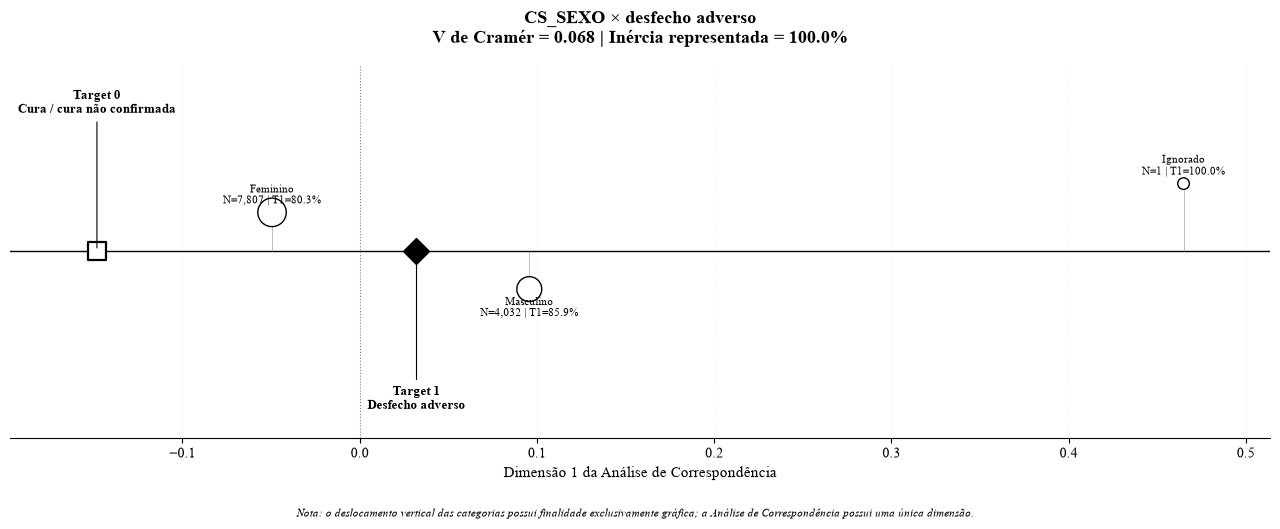


→ DROGAS


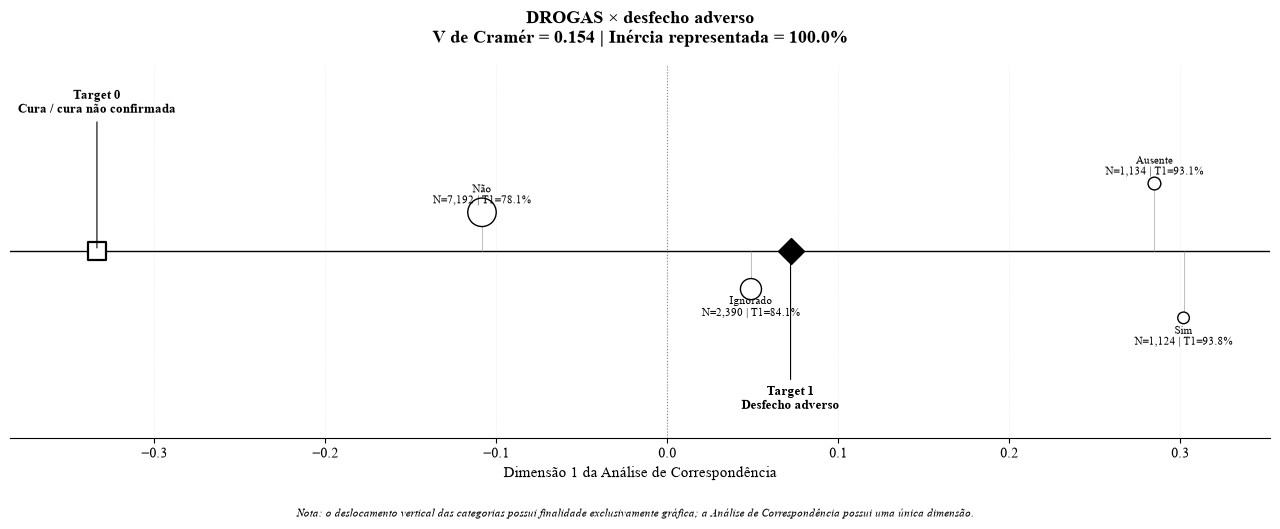


→ CS_ESCOL_N


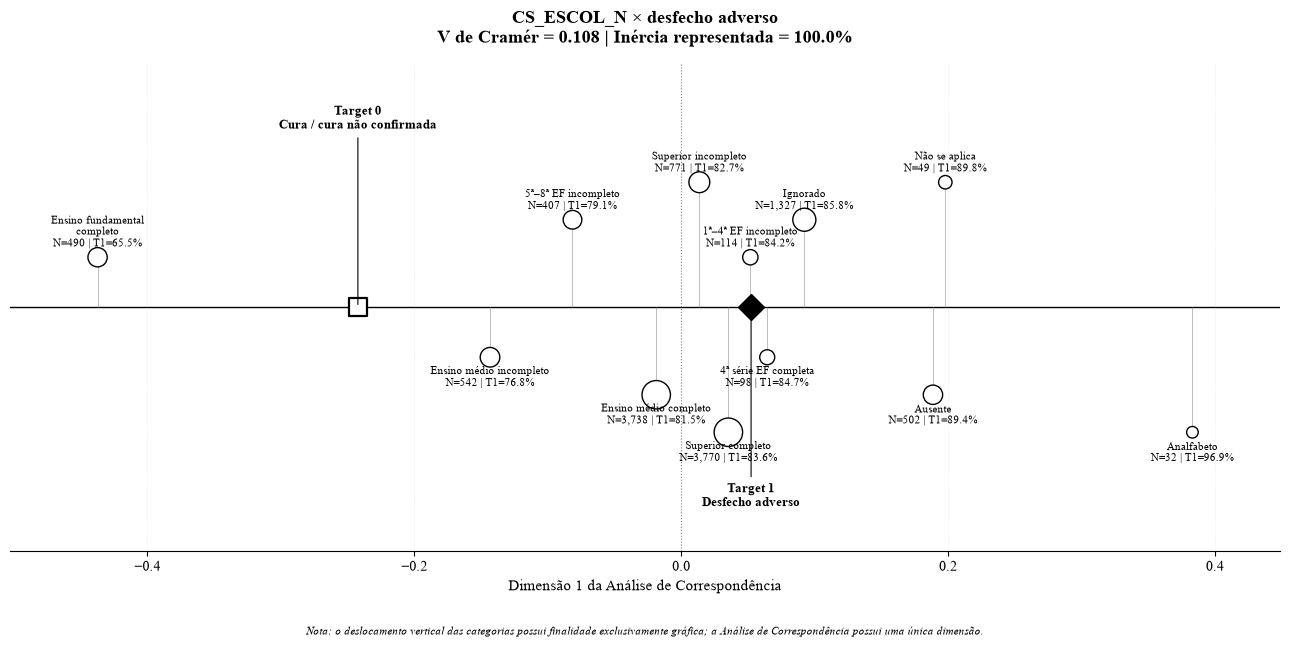


→ FUMA


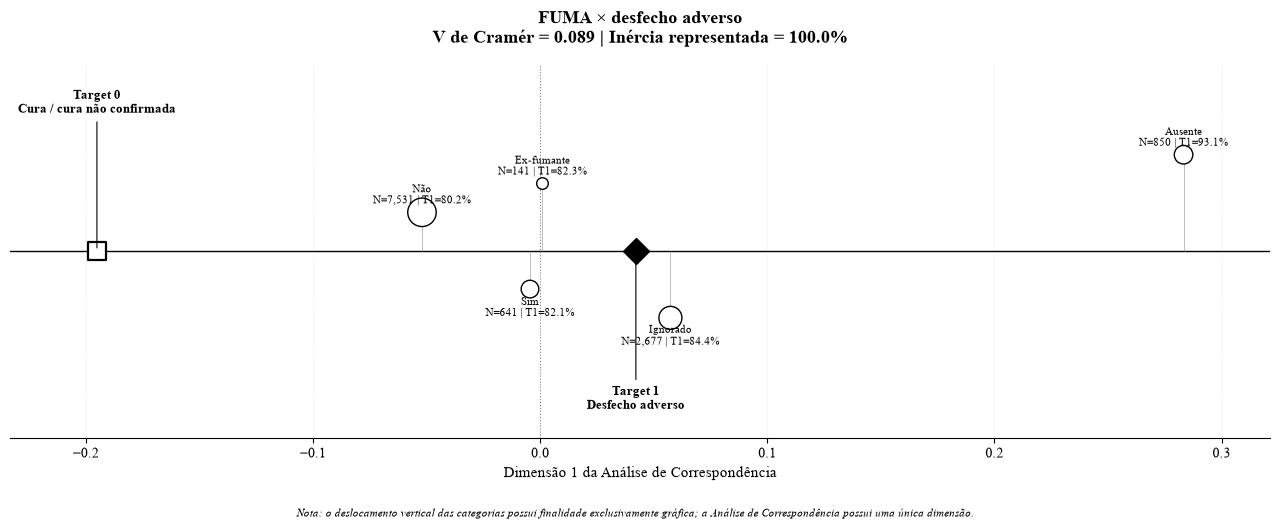


→ CS_RACA


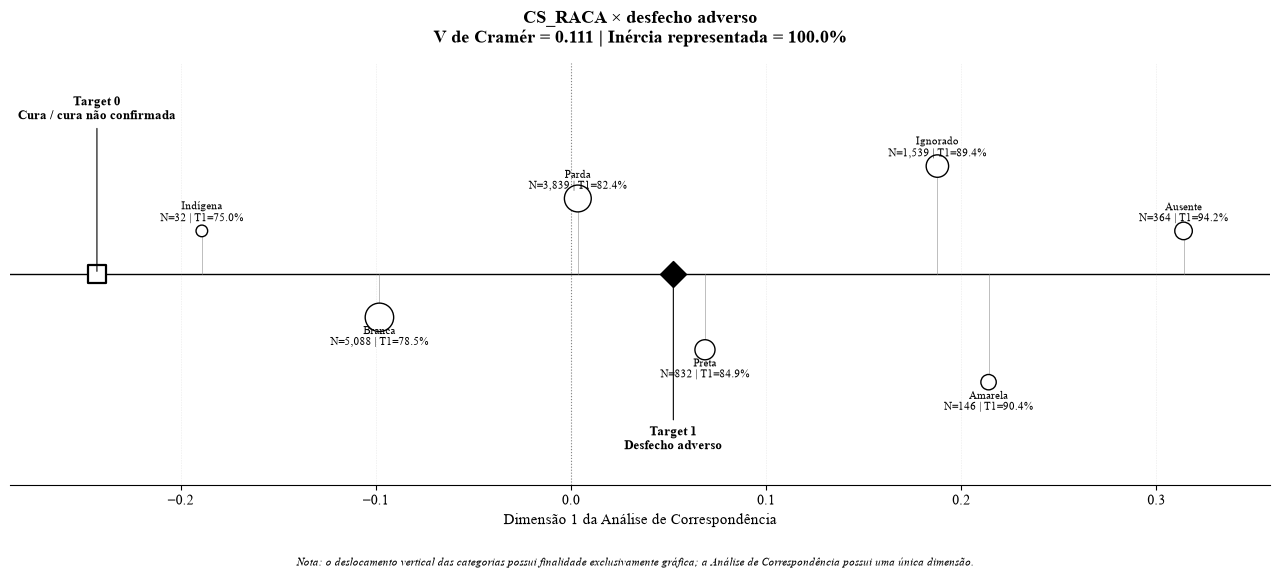


→ SIT_TRAB


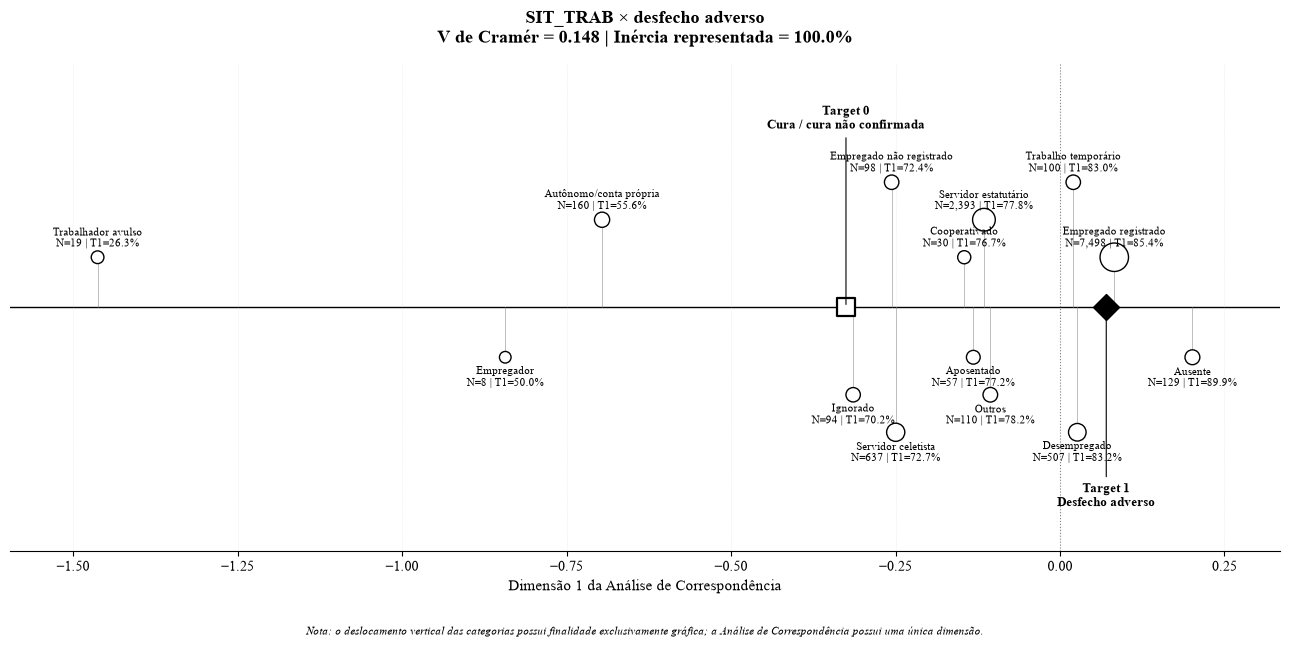


→ ALCOOL


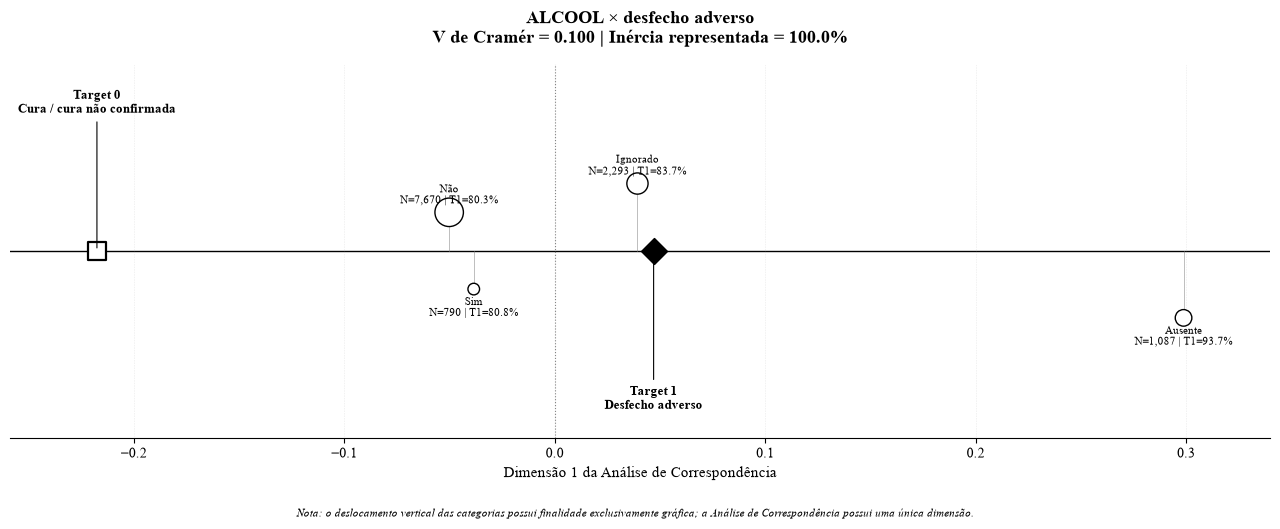


→ PSICO_FARM


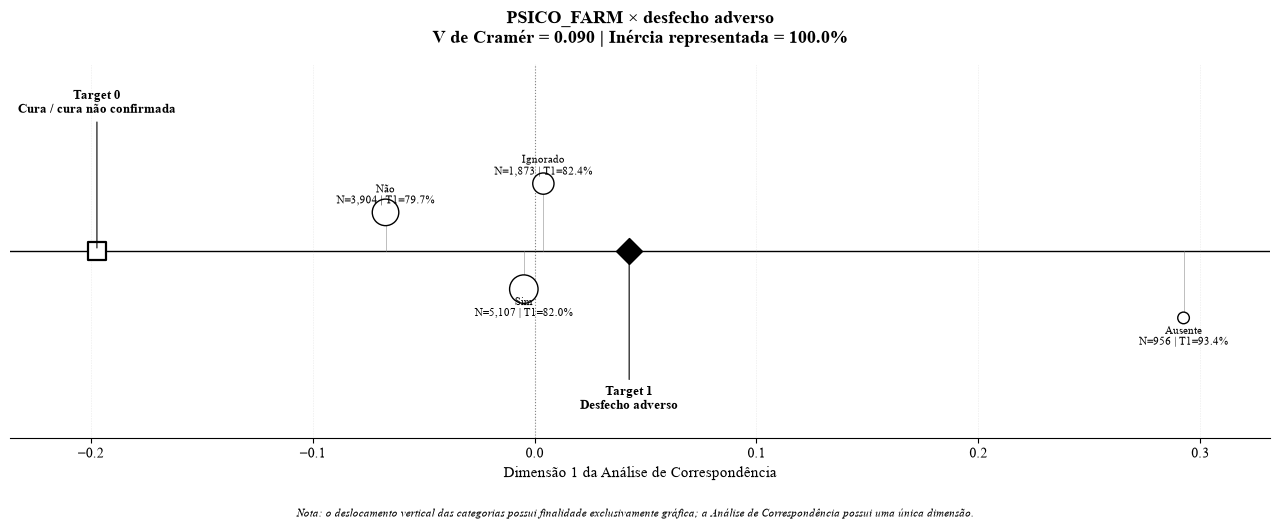


→ SG_UF


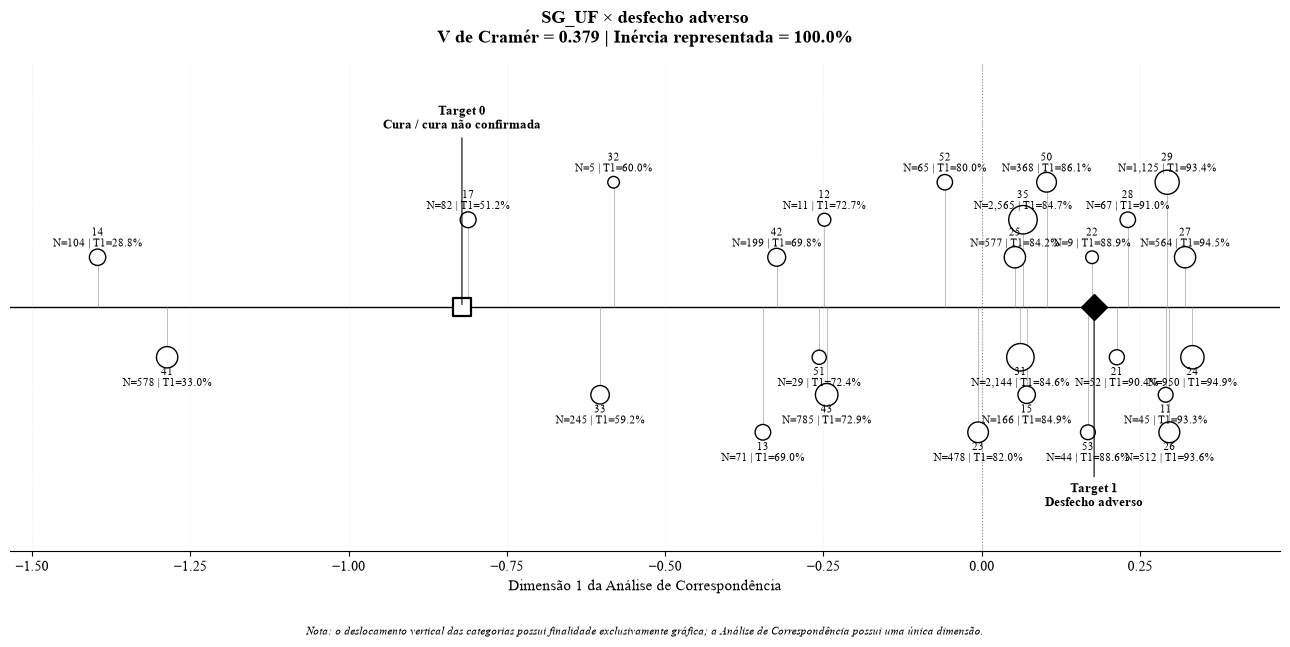


→ NU_ANO


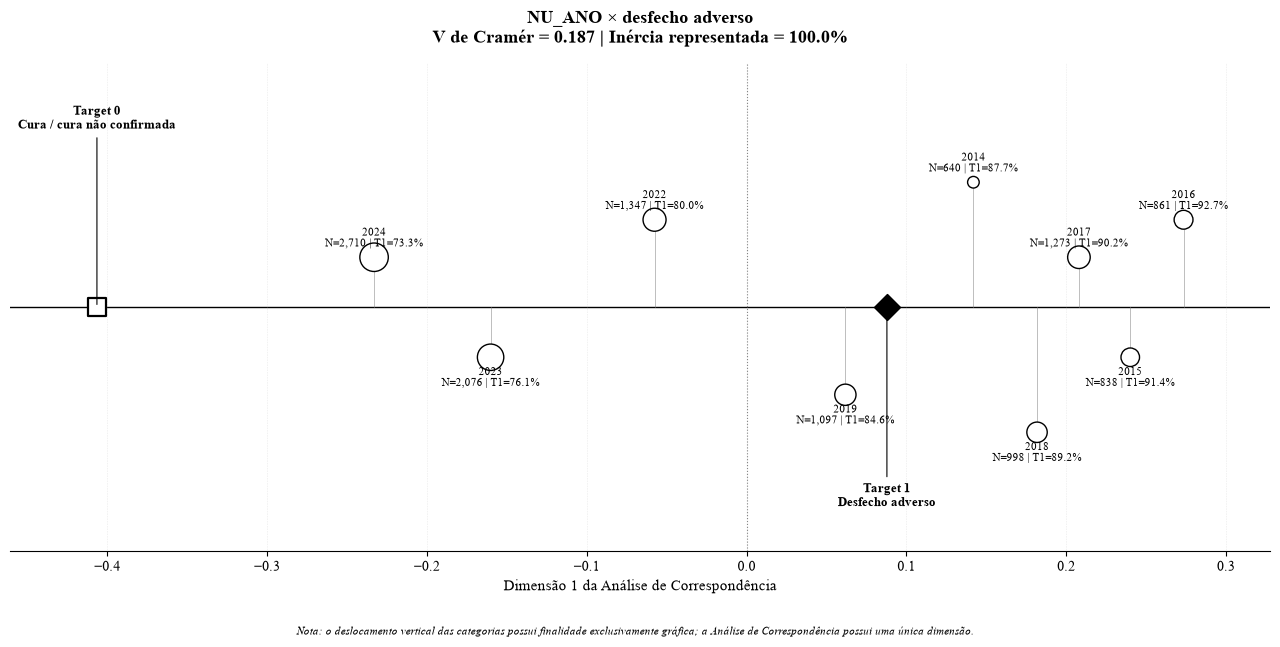


✓ Gráficos gerados.


In [ ]:
# ============================================================
# BLOCO 15.4B — GERAR NOVAMENTE OS GRÁFICOS CORRIGIDOS
# ============================================================

variaveis_ca = [
    "CS_SEXO",
    "DROGAS",
    "CS_ESCOL_N",
    "FUMA",
    "CS_RACA",
    "SIT_TRAB",
    "ALCOOL",
    "PSICO_FARM",
    "SG_UF",
    "NU_ANO"
]

variaveis_ca = [
    v for v in variaveis_ca
    if v in df_ca.columns
]

resultados_ca_corrigidos = {}

print("=" * 100)
print("GERANDO GRÁFICOS DE CORRESPONDÊNCIA CORRIGIDOS")
print("=" * 100)

for variavel in variaveis_ca:

    print(f"\n→ {variavel}")

    resultado_plot = plot_correspondencia_1d(
        df_ca,
        variavel
    )

    resultados_ca_corrigidos[variavel] = resultado_plot

print("\n✓ Gráficos gerados.")
